In [ ]:
import os
import glob
import zipfile
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

from tensorflow.keras import layers, models

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
ZIP_PATH = '/content/drive/MyDrive/🧠 BRISC 2025.zip'
EXTRACT_PATH = '/content'

INNER_ZIP = '/content/🧠 BRISC 2025/brisc2025.zip'

if not os.path.exists('/content/brisc_data/brisc2025'):
    if os.path.exists(INNER_ZIP):
        with zipfile.ZipFile(INNER_ZIP, 'r') as zip_ref:
            zip_ref.extractall('/content/brisc_data')
    elif os.path.exists(ZIP_PATH):
        with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
            zip_ref.extractall(EXTRACT_PATH)

print("Extraction check complete.")

Extraction check complete.


In [ ]:
DATA_ROOT = '/content/brisc_data/brisc2025'

CLASS_TRAIN_DIR = os.path.join(
    DATA_ROOT, 'classification_task', 'train'
)
CLASS_TEST_DIR = os.path.join(
    DATA_ROOT, 'classification_task', 'test'
)

SEG_TRAIN_IMAGES = os.path.join(
    DATA_ROOT, 'segmentation_task', 'train', 'images'
)
SEG_TRAIN_MASKS = os.path.join(
    DATA_ROOT, 'segmentation_task', 'train', 'masks'
)
SEG_TEST_IMAGES = os.path.join(
    DATA_ROOT, 'segmentation_task', 'test', 'images'
)
SEG_TEST_MASKS = os.path.join(
    DATA_ROOT, 'segmentation_task', 'test', 'masks'
)

IMG_SIZE = 128
BATCH_SIZE = 8
SEED = 42

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

In [ ]:
print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

paths = {
    "Dataset root": DATA_ROOT,
    "Classification train": CLASS_TRAIN_DIR,
    "Classification test": CLASS_TEST_DIR,
    "Segmentation train images": SEG_TRAIN_IMAGES,
    "Segmentation train masks": SEG_TRAIN_MASKS,
    "Segmentation test images": SEG_TEST_IMAGES,
    "Segmentation test masks": SEG_TEST_MASKS
}

for name, path in paths.items():
    print(name, ":", os.path.exists(path))

assert all(os.path.exists(path) for path in paths.values()), \
    "Dataset path missing hai. DATA_ROOT check karo."

print("\nAll dataset paths verified successfully!")
print("Classes:", sorted(os.listdir(CLASS_TRAIN_DIR)))

TensorFlow version: 2.21.0
GPU available: []
Dataset root : True
Classification train : True
Classification test : True
Segmentation train images : True
Segmentation train masks : True
Segmentation test images : True
Segmentation test masks : True

All dataset paths verified successfully!
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [ ]:
## EDA
# Count images in each classification class

classes = sorted(os.listdir(CLASS_TRAIN_DIR))

train_counts = {}
test_counts = {}

for class_name in classes:
    train_path = os.path.join(CLASS_TRAIN_DIR, class_name)
    test_path = os.path.join(CLASS_TEST_DIR, class_name)

    train_counts[class_name] = len([
        f for f in os.listdir(train_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])

    test_counts[class_name] = len([
        f for f in os.listdir(test_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])

print("Training image counts:")
print(pd.Series(train_counts))

print("\nTesting image counts:")
print(pd.Series(test_counts))

print("\nTotal training images:", sum(train_counts.values()))
print("Total testing images:", sum(test_counts.values()))



Training image counts:
glioma        1147
meningioma    1329
no_tumor      1067
pituitary     1457
dtype: int64

Testing image counts:
glioma        254
meningioma    306
no_tumor      140
pituitary     300
dtype: int64

Total training images: 5000
Total testing images: 1000


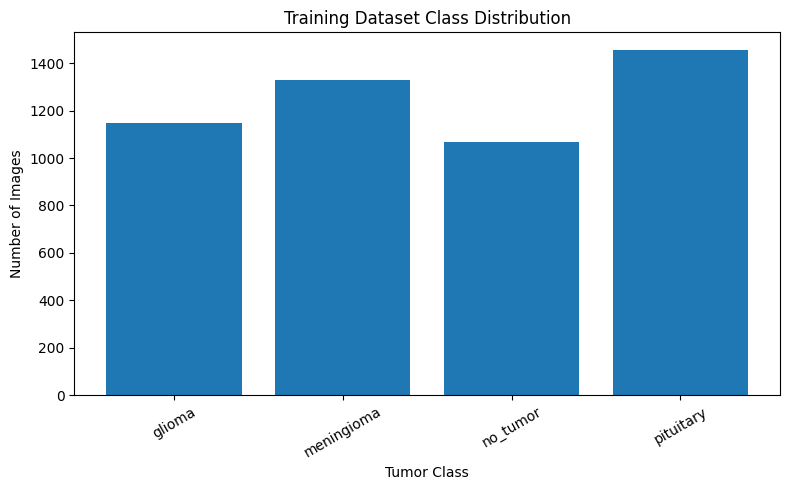

In [ ]:
## class distribution
plt.figure(figsize=(8, 5))

plt.bar(train_counts.keys(), train_counts.values())

plt.title("Training Dataset Class Distribution")
plt.xlabel("Tumor Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

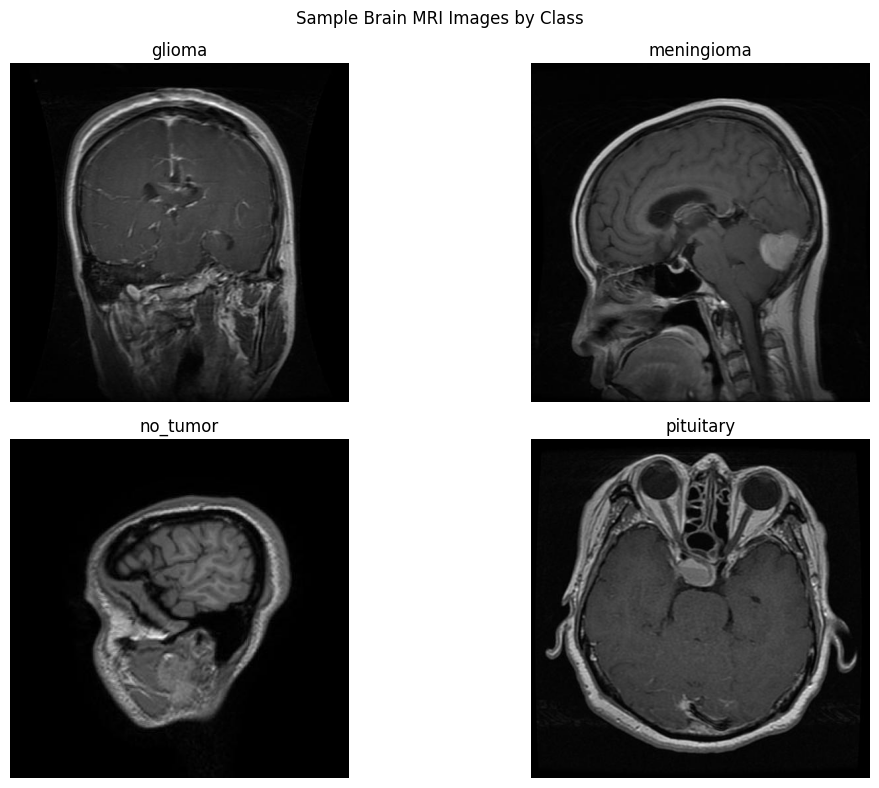

In [ ]:
## every class mri image
plt.figure(figsize=(12, 8))

for i, class_name in enumerate(classes):
    class_path = os.path.join(CLASS_TRAIN_DIR, class_name)

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    if image_files:
        image_path = os.path.join(
            class_path, random.choice(image_files)
        )

        image = cv2.imread(image_path)

        if image is not None:
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            plt.subplot(2, 2, i + 1)
            plt.imshow(image)
            plt.title(class_name)
            plt.axis('off')

plt.suptitle("Sample Brain MRI Images by Class")
plt.tight_layout()
plt.show()

In [ ]:
## Segmentation images aur masks count karo
# Count segmentation images and masks

train_images = glob.glob(os.path.join(SEG_TRAIN_IMAGES, '*'))
train_masks = glob.glob(os.path.join(SEG_TRAIN_MASKS, '*'))

test_images = glob.glob(os.path.join(SEG_TEST_IMAGES, '*'))
test_masks = glob.glob(os.path.join(SEG_TEST_MASKS, '*'))

# Keep only image files
valid_ext = ('.jpg', '.jpeg', '.png')

train_images = [
    f for f in train_images if f.lower().endswith(valid_ext)
]
train_masks = [
    f for f in train_masks if f.lower().endswith(valid_ext)
]
test_images = [
    f for f in test_images if f.lower().endswith(valid_ext)
]
test_masks = [
    f for f in test_masks if f.lower().endswith(valid_ext)
]

print("Training segmentation images:", len(train_images))
print("Training segmentation masks:", len(train_masks))
print("Testing segmentation images:", len(test_images))
print("Testing segmentation masks:", len(test_masks))


Training segmentation images: 3933
Training segmentation masks: 3933
Testing segmentation images: 860
Testing segmentation masks: 860


In [ ]:
##image-mask pairs match karte hain ya nahi
# Compare filenames without extensions

train_image_names = {
    os.path.splitext(os.path.basename(f))[0]
    for f in train_images
}

train_mask_names = {
    os.path.splitext(os.path.basename(f))[0]
    for f in train_masks
}

test_image_names = {
    os.path.splitext(os.path.basename(f))[0]
    for f in test_images
}

test_mask_names = {
    os.path.splitext(os.path.basename(f))[0]
    for f in test_masks
}

print("Matched training pairs:",
      len(train_image_names & train_mask_names))

print("Training images without masks:",
      len(train_image_names - train_mask_names))

print("Training masks without images:",
      len(train_mask_names - train_image_names))

print("Matched testing pairs:",
      len(test_image_names & test_mask_names))

print("Testing images without masks:",
      len(test_image_names - test_mask_names))

print("Testing masks without images:",
      len(test_mask_names - test_image_names))

Matched training pairs: 3933
Training images without masks: 0
Training masks without images: 0
Matched testing pairs: 860
Testing images without masks: 0
Testing masks without images: 0


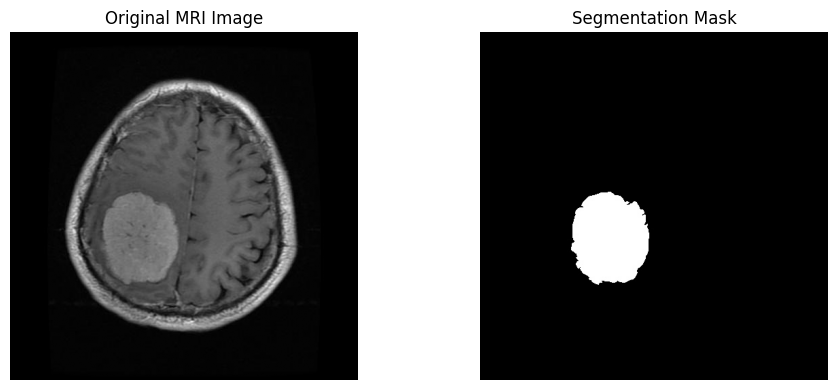

In [ ]:
# Display one matching MRI image and its mask

train_pairs = {}

for image_path in train_images:
    name = os.path.splitext(os.path.basename(image_path))[0]

    for mask_path in train_masks:
        mask_name = os.path.splitext(os.path.basename(mask_path))[0]

        if name == mask_name:
            train_pairs[name] = (image_path, mask_path)
            break

if train_pairs:
    image_path, mask_path = next(iter(train_pairs.values()))

    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    if image is not None and mask is not None:
        plt.figure(figsize=(10, 4))

        plt.subplot(1, 2, 1)
        plt.imshow(image, cmap='gray')
        plt.title("Original MRI Image")
        plt.axis('off')

        plt.subplot(1, 2, 2)
        plt.imshow(mask, cmap='gray')
        plt.title("Segmentation Mask")
        plt.axis('off')

        plt.tight_layout()
        plt.show()
else:
    print("No matching image-mask pairs found.")

In [ ]:

# Step 8: Create Train, Validation and Test Datasets

IMG_SIZE = 128
BATCH_SIZE = 8
SEED = 42

# Training data: 80% of training folder
train_ds = tf.keras.utils.image_dataset_from_directory(
    CLASS_TRAIN_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int"
)

# Validation data: remaining 20%
val_ds = tf.keras.utils.image_dataset_from_directory(
    CLASS_TRAIN_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int"
)

# Test data: separate test folder
test_ds = tf.keras.utils.image_dataset_from_directory(
    CLASS_TEST_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Class names and number of classes
class_names = train_ds.class_names
num_classes = len(class_names)

print("\nClass Names:", class_names)
print("Number of Classes:", num_classes)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())


Found 5000 files belonging to 4 classes.
Using 4000 files for training.
Found 5000 files belonging to 4 classes.
Using 1000 files for validation.
Found 1000 files belonging to 4 classes.

Class Names: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Number of Classes: 4
Training batches: 500
Validation batches: 125
Testing batches: 125


Image batch shape: (8, 128, 128, 3)
Label batch shape: (8,)
Minimum pixel value: 0.0
Maximum pixel value: 247.25
Data type: <dtype: 'float32'>
Normalized minimum: 0.0
Normalized maximum: 0.96960783


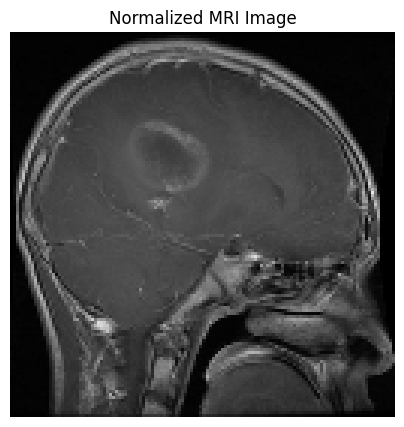

In [ ]:

# Step 9: Image Quality and Pixel Value Check

# Take one batch of training images
for images, labels in train_ds.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

    print("Data type:", images.dtype)

    # Normalize pixel values from 0-255 to 0-1
    normalized_images = images / 255.0

    print("Normalized minimum:", tf.reduce_min(normalized_images).numpy())
    print("Normalized maximum:", tf.reduce_max(normalized_images).numpy())

    # Display one normalized MRI image
    plt.figure(figsize=(5, 5))
    plt.imshow(normalized_images[0].numpy())
    plt.title("Normalized MRI Image")
    plt.axis("off")
    plt.show()


Training images in each class:
     Class  Image_Count
    glioma         1147
meningioma         1329
  no_tumor         1067
 pituitary         1457

Total training images: 5000
Largest class count: 1457
Smallest class count: 1067


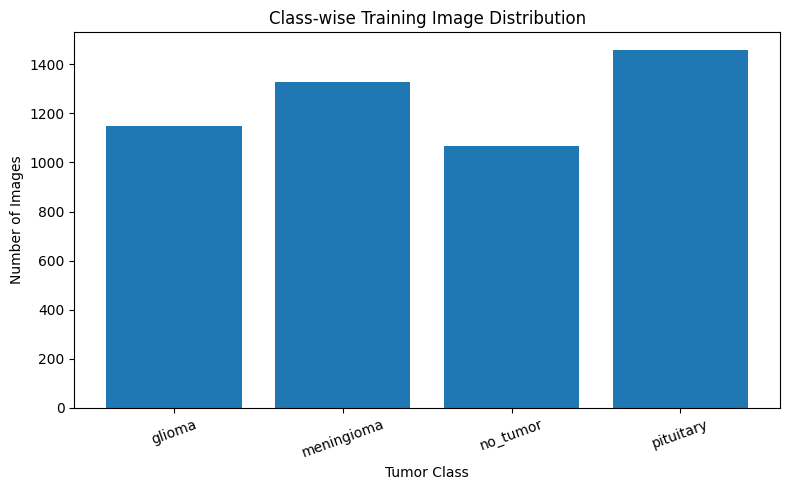

In [ ]:

# Step 10: Class-wise Image Count Analysis

import os
import matplotlib.pyplot as plt
import pandas as pd

class_counts = {}

for class_name in class_names:
    class_path = os.path.join(CLASS_TRAIN_DIR, class_name)

    image_files = [
        file for file in os.listdir(class_path)
        if file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
    ]

    class_counts[class_name] = len(image_files)

# Create a DataFrame
class_df = pd.DataFrame(
    list(class_counts.items()),
    columns=['Class', 'Image_Count']
)

print("Training images in each class:")
print(class_df.to_string(index=False))

print("\nTotal training images:", class_df['Image_Count'].sum())
print("Largest class count:", class_df['Image_Count'].max())
print("Smallest class count:", class_df['Image_Count'].min())

# Plot class distribution
plt.figure(figsize=(8, 5))
plt.bar(class_df['Class'], class_df['Image_Count'])
plt.title("Class-wise Training Image Distribution")
plt.xlabel("Tumor Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


     Class  Training  Validation  Testing
    glioma       931         216      254
meningioma      1075         254      306
  no_tumor       817         250      140
 pituitary      1177         280      300

Total training: 4000
Total validation: 1000
Total testing: 1000


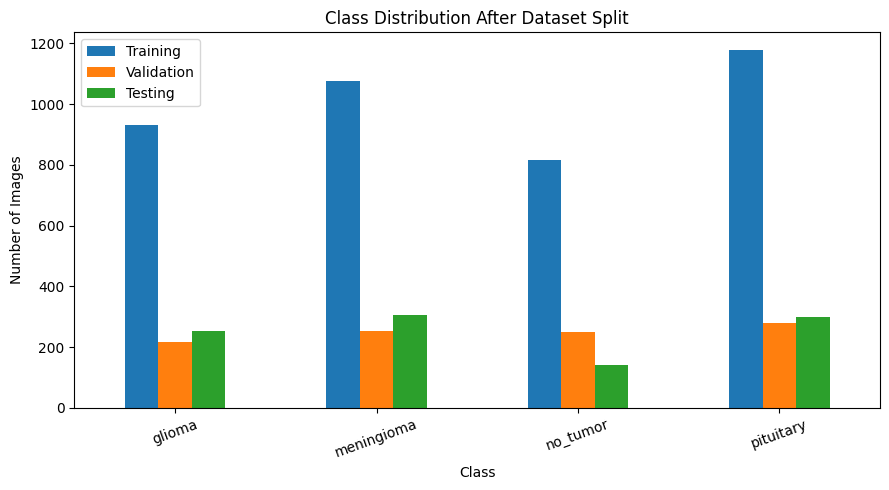

In [ ]:

# Step 11: Count classes after splitting

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def count_dataset_classes(dataset, class_names):
    counts = np.zeros(len(class_names), dtype=int)

    for _, labels in dataset:
        labels = labels.numpy()
        counts += np.bincount(labels, minlength=len(class_names))

    return counts

train_counts = count_dataset_classes(train_ds, class_names)
val_counts = count_dataset_classes(val_ds, class_names)
test_counts = count_dataset_classes(test_ds, class_names)

distribution_df = pd.DataFrame({
    "Class": class_names,
    "Training": train_counts,
    "Validation": val_counts,
    "Testing": test_counts
})

print(distribution_df.to_string(index=False))
print("\nTotal training:", train_counts.sum())
print("Total validation:", val_counts.sum())
print("Total testing:", test_counts.sum())

distribution_df.set_index("Class").plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Class Distribution After Dataset Split")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [ ]:

# Step 12: Check image dimensions and corrupt files

from PIL import Image
from collections import Counter
import os

def inspect_images(folder):
    total = 0
    corrupt_files = []
    dimension_counts = Counter()

    for root, _, files in os.walk(folder):
        for file in files:
            if file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
                path = os.path.join(root, file)
                total += 1

                try:
                    with Image.open(path) as img:
                        img.verify()

                    # Reopen to read image dimensions
                    with Image.open(path) as img:
                        dimension_counts[img.size] += 1

                except Exception:
                    corrupt_files.append(path)

    print("Folder:", folder)
    print("Total image files:", total)
    print("Corrupt/unreadable images:", len(corrupt_files))
    print("Different original dimensions:", len(dimension_counts))

    print("\nMost common image dimensions:")
    for size, count in dimension_counts.most_common(10):
        print(f"{size}: {count} images")

    if corrupt_files:
        print("\nExamples of corrupt files:")
        for path in corrupt_files[:5]:
            print(path)

# Check classification training and testing folders
inspect_images(CLASS_TRAIN_DIR)
print("\n" + "=" * 45 + "\n")
inspect_images(CLASS_TEST_DIR)


Folder: /content/brisc_data/brisc2025/classification_task/train
Total image files: 5000
Corrupt/unreadable images: 0
Different original dimensions: 167

Most common image dimensions:
(512, 512): 4120 images
(369, 369): 323 images
(216, 369): 277 images
(256, 256): 27 images
(187, 369): 21 images
(202, 369): 19 images
(225, 225): 13 images
(210, 369): 12 images
(236, 236): 11 images
(442, 442): 6 images


Folder: /content/brisc_data/brisc2025/classification_task/test
Total image files: 1000
Corrupt/unreadable images: 0
Different original dimensions: 101

Most common image dimensions:
(512, 512): 761 images
(216, 369): 77 images
(369, 369): 40 images
(225, 225): 7 images
(256, 256): 5 images
(442, 442): 4 images
(554, 554): 3 images
(210, 240): 3 images
(201, 251): 3 images
(455, 500): 2 images


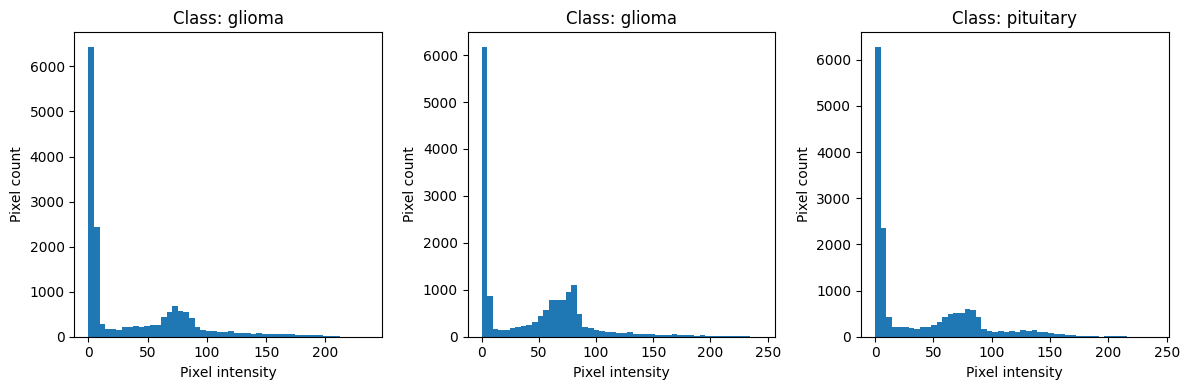

Sample image intensity statistics:

Image 1
Minimum: 0.0
Maximum: 236.0
Mean: 37.62
Standard deviation: 45.87

Image 2
Minimum: 0.0
Maximum: 244.5
Mean: 44.12
Standard deviation: 44.88

Image 3
Minimum: 0.0
Maximum: 239.75
Mean: 36.58
Standard deviation: 44.74


In [ ]:

# Step 13: Analyze MRI image intensity

import numpy as np
import matplotlib.pyplot as plt

for images, labels in train_ds.take(1):

    images_np = images.numpy()

    plt.figure(figsize=(12, 4))

    for i in range(3):
        image = images_np[i]

        # Convert RGB image to grayscale for intensity analysis
        gray = np.mean(image, axis=2)

        plt.subplot(1, 3, i + 1)
        plt.hist(gray.ravel(), bins=50)
        plt.title(f"Class: {class_names[labels[i].numpy()]}")
        plt.xlabel("Pixel intensity")
        plt.ylabel("Pixel count")

    plt.tight_layout()
    plt.show()

    print("Sample image intensity statistics:")

    for i in range(3):
        image = images_np[i]
        gray = np.mean(image, axis=2)

        print(f"\nImage {i + 1}")
        print("Minimum:", round(float(gray.min()), 2))
        print("Maximum:", round(float(gray.max()), 2))
        print("Mean:", round(float(gray.mean()), 2))
        print("Standard deviation:", round(float(gray.std()), 2))


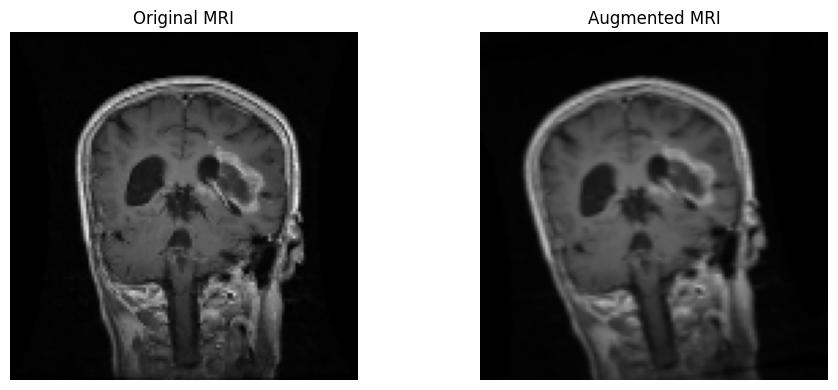

In [ ]:

# Step 14: Data augmentation and preprocessing

from tensorflow.keras import layers

# Normalize pixel values and augment training images
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    )
], name="data_augmentation")

# Display augmented samples
for images, labels in train_ds.take(1):

    sample_image = images[:1]

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(sample_image[0].numpy().astype("uint8"))
    plt.title("Original MRI")
    plt.axis("off")

    augmented_image = data_augmentation(
        sample_image, training=True
    )

    plt.subplot(1, 2, 2)
    plt.imshow(
        tf.clip_by_value(augmented_image[0], 0, 255)
        .numpy().astype("uint8")
    )
    plt.title("Augmented MRI")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


In [ ]:

# Step 15: Build CNN Classification Model

from tensorflow.keras import layers, models

# CNN model
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    # Normalize pixels from 0-255 to 0-1
    layers.Rescaling(1./255),

    # Data augmentation
    data_augmentation,

    # Convolution block 1
    layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 2
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 3
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display architecture
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,004 (109.39 KB)

 Trainable params: 28,004 (109.39 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# Step 16: Train CNN Model

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        '/content/best_brain_tumor_cnn.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)


Epoch 1/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.3482 - loss: 1.3219
Epoch 1: val_loss improved from None to 1.08093, saving model to /content/best_brain_tumor_cnn.keras

Epoch 1: finished saving model to /content/best_brain_tumor_cnn.keras
500/500 ━━━━━━━━━━━━━━━━━━━━ 57s 111ms/step - accuracy: 0.4200 - loss: 1.2602 - val_accuracy: 0.5730 - val_loss: 1.0809
Epoch 2/15
304/500 ━━━━━━━━━━━━━━━━━━━━ 19s 98ms/step - accuracy: 0.5353 - loss: 1.1237

KeyboardInterrupt: 

In [ ]:

# Step 17: Plot Training and Validation Graphs

plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:
test_loss, test_acc = model.evaluate(test_ds, verbose=1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

In [ ]:
# Actual labels
y_true = np.concatenate([y.numpy() for x, y in test_ds])

# Model predictions
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
))

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('Brain Tumor Classification - Confusion Matrix')
plt.tight_layout()
plt.show()

In [ ]:

# MobileNetV2 ke liye input preprocessing

train_ds_tl = train_ds
val_ds_tl = val_ds
test_ds_tl = test_ds

print("Transfer learning datasets ready!")
print("Classes:", class_names)


Transfer learning datasets ready!
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

# Pretrained MobileNetV2
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

# Pehle pretrained layers freeze rahengi
base_model.trainable = False

# New classification model
tl_model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Resizing(224, 224),
    layers.Lambda(lambda x: preprocess_input(x)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(num_classes, activation='softmax')
])

tl_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

tl_model.summary()

In [ ]:
##MobileNetV2  train
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

tl_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        '/content/best_mobilenetv2.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

tl_history = tl_model.fit(
    train_ds_tl,
    validation_data=val_ds_tl,
    epochs=10,
    callbacks=tl_callbacks
)

In [ ]:
tl_test_loss, tl_test_acc = tl_model.evaluate(
    test_ds_tl,
    verbose=1
)

print(f"MobileNetV2 Test Loss: {tl_test_loss:.4f}")
print(f"MobileNetV2 Test Accuracy: {tl_test_acc * 100:.2f}%")

In [ ]:
# Base model ko fine-tuning ke liye unfreeze karo
base_model.trainable = True

# Sirf upper layers train hongi
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Batch Normalization layers ko frozen rakho
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Bahut small learning rate use karo
tl_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Trainable layers:", sum(layer.trainable for layer in base_model.layers))
print("Fine-tuning setup ready!")

In [ ]:
fine_tune_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        '/content/best_mobilenetv2_finetuned.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

tl_history_fine = tl_model.fit(
    train_ds_tl,
    validation_data=val_ds_tl,
    epochs=5,
    callbacks=fine_tune_callbacks
)

In [ ]:
tl_test_loss, tl_test_acc = tl_model.evaluate(
    test_ds_tl,
    verbose=1
)

print(f"Fine-tuned MobileNetV2 Test Loss: {tl_test_loss:.4f}")
print(f"Fine-tuned MobileNetV2 Test Accuracy: {tl_test_acc * 100:.2f}%")

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Training dataset ke actual labels collect karo
y_train = np.concatenate([
    labels.numpy() for images, labels in train_ds
])

# Class weights calculate karo
weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(np.unique(y_train), weights)
}

print("Class names:", class_names)
print("Class weights:", class_weights)

In [ ]:
# Original CNN jaisi architecture
cw_model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Rescaling(1./255),
    data_augmentation,
    layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

cw_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cw_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        '/content/best_classweighted_cnn.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

cw_history = cw_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=cw_callbacks
)

In [ ]:
cw_test_loss, cw_test_acc = cw_model.evaluate(test_ds, verbose=1)

print(f"Test Loss: {cw_test_loss:.4f}")
print(f"Test Accuracy: {cw_test_acc*100:.2f}%")

In [ ]:
# True labels
y_true = np.concatenate([y.numpy() for x, y in test_ds])

# Predictions
y_prob = cw_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
))

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7,6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Class-Weighted CNN Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import os
import json
from sklearn.metrics import classification_report

# Google Drive mein project folder
SAVE_DIR = '/content/drive/MyDrive/Brain_Tumor_Project'
os.makedirs(SAVE_DIR, exist_ok=True)

# Best class-weighted CNN save karo
cw_model.save(os.path.join(SAVE_DIR, 'best_classweighted_cnn.keras'))

# Training history save karo
with open(os.path.join(SAVE_DIR, 'training_history.json'), 'w') as f:
    json.dump(cw_history.history, f, indent=4)

# Classification report save karo
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
)

with open(os.path.join(SAVE_DIR, 'classification_report.txt'), 'w') as f:
    f.write(report)

print("Model aur results Google Drive mein save ho gaye!")
print("Folder:", SAVE_DIR)

In [ ]:
print(os.listdir(SAVE_DIR))

U-NET

In [ ]:
import os

print("Train images:", len(os.listdir(SEG_TRAIN_IMAGES)))
print("Train masks:", len(os.listdir(SEG_TRAIN_MASKS)))

print("Test images:", len(os.listdir(SEG_TEST_IMAGES)))
print("Test masks:", len(os.listdir(SEG_TEST_MASKS)))

In [ ]:
# ============================================================
# STEP 34: MATCH IMAGE AND MASK FILENAMES
# Purpose: Compare filenames without their file extensions
# ============================================================

import os
import glob

# 1. Get training image and mask filenames
train_images = sorted(
    glob.glob(os.path.join(SEG_TRAIN_IMAGES, '*'))
)
train_masks = sorted(
    glob.glob(os.path.join(SEG_TRAIN_MASKS, '*'))
)

# 2. Get testing image and mask filenames
test_images = sorted(
    glob.glob(os.path.join(SEG_TEST_IMAGES, '*'))
)
test_masks = sorted(
    glob.glob(os.path.join(SEG_TEST_MASKS, '*'))
)

# 3. Remove extensions before comparing filenames
train_image_names = {
    os.path.splitext(os.path.basename(p))[0]
    for p in train_images
}

train_mask_names = {
    os.path.splitext(os.path.basename(p))[0]
    for p in train_masks
}

test_image_names = {
    os.path.splitext(os.path.basename(p))[0]
    for p in test_images
}

test_mask_names = {
    os.path.splitext(os.path.basename(p))[0]
    for p in test_masks
}

# 4. Check whether every image has a matching mask
print("TRAINING DATA")
print("Matching pairs:", len(train_image_names & train_mask_names))
print("Images without masks:", len(train_image_names - train_mask_names))
print("Masks without images:", len(train_mask_names - train_image_names))

print("\nTESTING DATA")
print("Matching pairs:", len(test_image_names & test_mask_names))
print("Images without masks:", len(test_image_names - test_mask_names))
print("Masks without images:", len(test_mask_names - test_image_names))

In [ ]:
# ============================================================
# STEP 35: VISUALIZE MRI IMAGE AND ITS SEGMENTATION MASK
# Purpose: Understand the MRI image and its corresponding mask
# ============================================================

import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. Get the first training MRI image
image_path = sorted(
    glob.glob(os.path.join(SEG_TRAIN_IMAGES, '*'))
)[0]

# 2. Find its matching mask using the filename without extension
image_name = os.path.splitext(os.path.basename(image_path))[0]
mask_path = os.path.join(SEG_TRAIN_MASKS, image_name + '.png')

# 3. Load the MRI image and segmentation mask
mri_image = Image.open(image_path).convert('RGB')
mask_image = Image.open(mask_path).convert('L')

# 4. Display both images side by side
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(mri_image, cmap='gray')
plt.title('Original MRI Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(mask_image, cmap='gray')
plt.title('Segmentation Mask')
plt.axis('off')

plt.tight_layout()
plt.show()

# 5. Display image dimensions and mask pixel values
print("MRI image size:", mri_image.size)
print("Mask size:", mask_image.size)
print("Unique mask pixel values:", np.unique(np.array(mask_image)))

In [ ]:
# ============================================================
# STEP 36: ANALYZE SEGMENTATION MASK
# Purpose: Understand mask pixel values before U-Net training
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. Convert the mask into a NumPy array
mask_array = np.array(mask_image)

# 2. Display the frequency of each pixel value
values, counts = np.unique(mask_array, return_counts=True)

print("Unique pixel values:", values)
print("\nPixel value frequencies:")

for value, count in zip(values, counts):
    print(f"Pixel value {value}: {count} pixels")

# 3. Display the mask using a histogram
plt.figure(figsize=(8, 4))

plt.hist(mask_array.flatten(), bins=50)

plt.title("Distribution of Mask Pixel Values")
plt.xlabel("Pixel Intensity")
plt.ylabel("Number of Pixels")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STEP 37: CHECK PIXEL VALUES IN ALL TRAINING MASKS
# Purpose: Verify whether masks use 0 and 255 consistently
# ============================================================

import os
import glob
import numpy as np
from PIL import Image

# 1. Get all training mask paths
mask_paths = sorted(
    glob.glob(os.path.join(SEG_TRAIN_MASKS, '*'))
)

# 2. Initialize counters
all_values = set()
mask_min_values = []
mask_max_values = []

# 3. Examine every training mask
for path in mask_paths:
    # Load mask as grayscale
    mask = np.array(Image.open(path).convert('L'))

    # Collect pixel values
    all_values.update(np.unique(mask).tolist())

    # Store minimum and maximum values
    mask_min_values.append(mask.min())
    mask_max_values.append(mask.max())

# 4. Display dataset-level results
print("Total training masks:", len(mask_paths))
print("Unique pixel values found:", sorted(all_values))

print("\nMasks containing non-zero pixels:",
      sum(value > 0 for value in mask_max_values))

print("Masks containing pixels equal to 255:",
      sum(value == 255 for value in mask_max_values))

print("Masks containing intermediate grayscale values:",
      sum(
          np.any((np.array(Image.open(p).convert('L')) > 0) &
                 (np.array(Image.open(p).convert('L')) < 255))
          for p in mask_paths
      ))

In [ ]:
# ============================================================
# STEP 38: CONVERT MASK INTO BINARY FORMAT
# Purpose: Convert background to 0 and tumor region to 1
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# 1. Convert the original mask into a NumPy array
mask_array = np.array(mask_image)

# 2. Convert pixel values into a binary mask
# Background (0)  -> 0
# Foreground (>0) -> 1
binary_mask = (mask_array > 0).astype(np.uint8)

# 3. Display the original and binary masks
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(mask_array, cmap='gray')
plt.title("Original Mask")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(binary_mask, cmap='gray', vmin=0, vmax=1)
plt.title("Binary Mask")
plt.axis('off')

plt.tight_layout()
plt.show()

# 4. Verify binary mask values
print("Unique binary values:", np.unique(binary_mask))
print("Background pixels:", np.sum(binary_mask == 0))
print("Foreground pixels:", np.sum(binary_mask == 1))

In [ ]:
# ============================================================
# STEP 39: PREPROCESS ONE MRI IMAGE AND ITS MASK
# Purpose: Resize and normalize data for U-Net
# ============================================================

import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# 1. Define the input size for the U-Net model
IMG_SIZE = 128

# 2. Load and resize the MRI image
image = Image.open(image_path).convert('L')
image = image.resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR)

# 3. Normalize MRI pixel values between 0 and 1
image_array = np.array(image, dtype=np.float32) / 255.0

# 4. Load and resize the corresponding mask
mask = Image.open(mask_path).convert('L')
mask = mask.resize((IMG_SIZE, IMG_SIZE), Image.Resampling.NEAREST)

# 5. Convert the resized mask into binary format
mask_array = (np.array(mask) > 0).astype(np.float32)

# 6. Add channel dimensions for the U-Net input
image_array = np.expand_dims(image_array, axis=-1)
mask_array = np.expand_dims(mask_array, axis=-1)

# 7. Display the processed image and mask
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_array[:, :, 0], cmap='gray')
plt.title("Resized MRI Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(mask_array[:, :, 0], cmap='gray', vmin=0, vmax=1)
plt.title("Resized Binary Mask")
plt.axis('off')

plt.tight_layout()
plt.show()

# 8. Verify shapes and value ranges
print("MRI shape:", image_array.shape)
print("Mask shape:", mask_array.shape)
print("MRI value range:", image_array.min(), "to", image_array.max())
print("Mask unique values:", np.unique(mask_array))

In [ ]:
# ============================================================
# STEP 40: CREATE U-NET DATA PIPELINE
# Purpose: Load MRI images and masks in batches
# ============================================================

import os
import glob
import numpy as np
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split

# 1. Set image size and batch size
IMG_SIZE = 128
BATCH_SIZE = 8
SEED = 42

# 2. Collect training image paths
image_paths = sorted(
    glob.glob(os.path.join(SEG_TRAIN_IMAGES, '*'))
)

# 3. Split training data into training and validation sets
train_paths, val_paths = train_test_split(
    image_paths,
    test_size=0.2,
    random_state=SEED
)

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))

# 4. Create a function to load and preprocess one image-mask pair
def load_image_mask(image_path):
    # Convert TensorFlow path to a Python string
    image_path = image_path.decode("utf-8")

    # Find corresponding mask using the same filename
    image_name = os.path.splitext(
        os.path.basename(image_path)
    )[0]

    mask_path = os.path.join(
        SEG_TRAIN_MASKS,
        image_name + ".png"
    )

    # Load and resize MRI image
    image = Image.open(image_path).convert("L")
    image = image.resize(
        (IMG_SIZE, IMG_SIZE),
        Image.Resampling.BILINEAR
    )
    image = np.array(image, dtype=np.float32) / 255.0

    # Load and resize mask
    mask = Image.open(mask_path).convert("L")
    mask = mask.resize(
        (IMG_SIZE, IMG_SIZE),
        Image.Resampling.NEAREST
    )
    mask = (np.array(mask) > 0).astype(np.float32)

    # Add channel dimension
    image = np.expand_dims(image, axis=-1)
    mask = np.expand_dims(mask, axis=-1)

    return image, mask

# 5. Create TensorFlow dataset from image paths
def create_dataset(paths, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices(paths)

    # Shuffle training examples
    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=min(len(paths), 500),
            seed=SEED
        )

    # Load image-mask pairs
    dataset = dataset.map(
        lambda path: tf.numpy_function(
            load_image_mask,
            [path],
            [tf.float32, tf.float32]
        ),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    # Set tensor shapes
    dataset = dataset.map(
        lambda image, mask: (
            tf.ensure_shape(image, (IMG_SIZE, IMG_SIZE, 1)),
            tf.ensure_shape(mask, (IMG_SIZE, IMG_SIZE, 1))
        )
    )

    # Group examples into batches
    dataset = dataset.batch(BATCH_SIZE)

    return dataset.prefetch(tf.data.AUTOTUNE)

# 6. Build training and validation datasets
train_ds_seg = create_dataset(train_paths, shuffle=True)
val_ds_seg = create_dataset(val_paths)

print("\nTraining and validation pipelines created.")

In [ ]:
# ============================================================
# STEP 41: VERIFY U-NET TRAINING DATA
# Purpose: Check batch shapes and pixel value ranges
# ============================================================

import numpy as np

# 1. Load one batch from the training dataset
for images, masks in train_ds_seg.take(1):

    # 2. Display the batch shapes
    print("Image batch shape:", images.shape)
    print("Mask batch shape:", masks.shape)

    # 3. Check MRI image pixel values
    print("\nMRI minimum value:", float(np.min(images.numpy())))
    print("MRI maximum value:", float(np.max(images.numpy())))

    # 4. Check mask pixel values
    print("Mask unique values:", np.unique(masks.numpy()))

    # 5. Display one MRI image and its mask
    import matplotlib.pyplot as plt

    plt.figure(figsize=(8, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(images[0, :, :, 0].numpy(), cmap="gray")
    plt.title("Training MRI")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(
        masks[0, :, :, 0].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    plt.title("Training Mask")
    plt.axis("off")

    plt.tight_layout()

In [ ]:
# ============================================================
# STEP 42: BUILD U-NET SEGMENTATION MODEL
# Purpose: Create a CNN architecture for tumor-region segmentation
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Define a convolution block
def conv_block(inputs, filters):

    # First convolution layer
    x = layers.Conv2D(
        filters, 3, padding="same", activation="relu"
    )(inputs)

    # Second convolution layer
    x = layers.Conv2D(
        filters, 3, padding="same", activation="relu"
    )(x)

    return x


# 2. Define the U-Net architecture
def build_unet():

    # Input: grayscale MRI image of size 128 x 128
    inputs = layers.Input(shape=(128, 128, 1))

    # ---------------- ENCODER ----------------
    # Extract image features and reduce spatial dimensions

    c1 = conv_block(inputs, 32)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = conv_block(p1, 64)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    c3 = conv_block(p2, 128)
    p3 = layers.MaxPooling2D((2, 2))(c3)

    c4 = conv_block(p3, 256)
    p4 = layers.MaxPooling2D((2, 2))(c4)

    # ---------------- BOTTLENECK ----------------
    # Learn deeper image features
    b = conv_block(p4, 512)

    # ---------------- DECODER ----------------
    # Upsample features and combine them with encoder features

    u4 = layers.Conv2DTranspose(
        256, 2, strides=2, padding="same"
    )(b)
    u4 = layers.Concatenate()([u4, c4])
    c5 = conv_block(u4, 256)

    u3 = layers.Conv2DTranspose(
        128, 2, strides=2, padding="same"
    )(c5)
    u3 = layers.Concatenate()([u3, c3])
    c6 = conv_block(u3, 128)

    u2 = layers.Conv2DTranspose(
        64, 2, strides=2, padding="same"
    )(c6)
    u2 = layers.Concatenate()([u2, c2])
    c7 = conv_block(u2, 64)

    u1 = layers.Conv2DTranspose(
        32, 2, strides=2, padding="same"
    )(c7)
    u1 = layers.Concatenate()([u1, c1])
    c8 = conv_block(u1, 32)

    # 3. Predict the probability of tumor for every pixel
    outputs = layers.Conv2D(
        1, 1, activation="sigmoid"
    )(c8)

    # 4. Create the model
    model = models.Model(inputs, outputs, name="UNet")

    return model


# 5. Build the U-Net model
unet_model = build_unet()

# 6. Display model architecture
unet_model.summary()

In [ ]:
# ============================================================
# STEP 43: COMPILE THE U-NET MODEL
# Purpose: Configure optimizer, loss function, and metrics
# ============================================================

import tensorflow as tf

# 1. Define Dice coefficient
def dice_coefficient(y_true, y_pred):
    # Flatten true masks and predicted probabilities
    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])

    # Calculate intersection between true and predicted masks
    intersection = tf.reduce_sum(y_true * y_pred)

    # Calculate Dice score
    dice = (2.0 * intersection + 1e-7) / (
        tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + 1e-7
    )

    return dice


# 2. Define Dice loss
def dice_loss(y_true, y_pred):
    return 1.0 - dice_coefficient(y_true, y_pred)


# 3. Combine Binary Cross-Entropy and Dice loss
def combined_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    return tf.reduce_mean(bce) + dice_loss(y_true, y_pred)


# 4. Compile the U-Net model
unet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=combined_loss,
    metrics=[dice_coefficient]
)

# 5. Display the compilation details
print("U-Net model compiled successfully!")
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Loss: Binary Cross-Entropy + Dice Loss")
print("Metric: Dice Coefficient")

In [ ]:
# ============================================================
# STEP 44: TRAIN THE U-NET SEGMENTATION MODEL
# Purpose: Train U-Net to identify the tumor region in MRI images
# ============================================================

import os
import tensorflow as tf

# 1. Define paths to save the best model and training history
MODEL_DIR = "/content/drive/MyDrive/Brain_Tumor_Project"
os.makedirs(MODEL_DIR, exist_ok=True)

BEST_UNET_PATH = os.path.join(
    MODEL_DIR, "best_unet_segmentation.keras"
)

# 2. Stop training if validation loss does not improve
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

# 3. Save the model whenever validation loss improves
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=BEST_UNET_PATH,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# 4. Train the U-Net model
history_unet = unet_model.fit(
    train_ds_seg,
    validation_data=val_ds_seg,
    epochs=20,
    callbacks=[early_stopping, model_checkpoint]
)

# 5. Display training completion
print("\nU-Net training completed.")
print("Best model path:", BEST_UNET_PATH)

In [ ]:
# Step 1: Load the best saved U-Net model

import tensorflow as tf
import os

# Path of the saved model in Google Drive
model_path = "/content/drive/MyDrive/Brain_Tumor_Project/best_unet_segmentation.keras"

# Check whether the model file exists
if os.path.exists(model_path):

    # Load the trained model without retraining
    unet_model = tf.keras.models.load_model(
        model_path,
        custom_objects={
            "combined_loss": combined_loss,
            "dice_coefficient": dice_coefficient,
            "dice_loss": dice_loss
        }
    )

    # Display model details
    print("U-Net model loaded successfully!")
    print("Input shape:", unet_model.input_shape)
    print("Output shape:", unet_model.output_shape)

else:
    print("Model file not found. Check Google Drive mounting.")

In [ ]:
# Step 2: Visualize U-Net prediction on a test MRI

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Select the test image and its corresponding ground-truth mask
test_image_files = sorted([
    f for f in os.listdir(SEG_TEST_IMAGES)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

# Stop if the test folder is empty
if len(test_image_files) == 0:
    raise ValueError("No test images found.")

# Select the first test image
image_name = test_image_files[0]
image_path = os.path.join(SEG_TEST_IMAGES, image_name)

# Find the matching mask using the filename without extension
mask_name = os.path.splitext(image_name)[0] + ".png"
mask_path = os.path.join(SEG_TEST_MASKS, mask_name)

# Load and preprocess the MRI image
image = Image.open(image_path).convert("L")
image = image.resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR)
image_array = np.array(image, dtype=np.float32) / 255.0

# Load the actual tumor mask
mask = Image.open(mask_path).convert("L")
mask = mask.resize((IMG_SIZE, IMG_SIZE), Image.Resampling.NEAREST)
actual_mask = (np.array(mask) > 0).astype(np.uint8)

# Add batch and channel dimensions for model prediction
input_image = image_array[np.newaxis, ..., np.newaxis]

# Predict tumor probabilities and convert them to a binary mask
prediction = unet_model.predict(input_image, verbose=0)[0, :, :, 0]
predicted_mask = (prediction >= 0.5).astype(np.uint8)

# Display MRI, actual mask, and predicted mask
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image_array, cmap="gray")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(actual_mask, cmap="gray")
plt.title("Actual Tumor Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(predicted_mask, cmap="gray")
plt.title("Predicted Tumor Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Test image:", image_name)
print("Actual mask tumor pixels:", int(actual_mask.sum()))
print("Predicted tumor pixels:", int(predicted_mask.sum()))

In [ ]:
# Step 3: Evaluate segmentation using Dice Score and IoU

import numpy as np

# Convert both masks to boolean arrays
actual = actual_mask.astype(bool)
predicted = predicted_mask.astype(bool)

# Calculate the overlap between actual and predicted masks
intersection = np.logical_and(actual, predicted).sum()
union = np.logical_or(actual, predicted).sum()

# Calculate Dice Score
dice = (2 * intersection) / (actual.sum() + predicted.sum() + 1e-7)

# Calculate Intersection over Union (IoU)
iou = intersection / (union + 1e-7)

# Display evaluation results
print("Actual tumor pixels:", actual.sum())
print("Predicted tumor pixels:", predicted.sum())
print("Overlapping pixels:", intersection)
print("Dice Score:", round(float(dice), 4))
print("IoU Score:", round(float(iou), 4))

In [ ]:
# Step 3: Evaluate U-Net on the complete test dataset

import os
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

# Store Dice and IoU scores for each test image
dice_scores = []
iou_scores = []

# Get all test MRI filenames
test_files = sorted([
    f for f in os.listdir(SEG_TEST_IMAGES)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

# Evaluate each MRI and its matching mask
for filename in tqdm(test_files, desc="Evaluating test images"):

    # Construct image and corresponding mask paths
    image_path = os.path.join(SEG_TEST_IMAGES, filename)
    mask_path = os.path.join(
        SEG_TEST_MASKS,
        os.path.splitext(filename)[0] + ".png"
    )

    # Skip images whose matching masks are missing
    if not os.path.exists(mask_path):
        continue

    # Load and preprocess MRI image
    image = Image.open(image_path).convert("L")
    image = image.resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR)
    image = np.array(image, dtype=np.float32) / 255.0

    # Load and preprocess ground-truth mask
    mask = Image.open(mask_path).convert("L")
    mask = mask.resize((IMG_SIZE, IMG_SIZE), Image.Resampling.NEAREST)
    actual = np.array(mask) > 0

    # Predict the segmentation mask
    prediction = unet_model.predict(
        image[np.newaxis, ..., np.newaxis],
        verbose=0
    )[0, :, :, 0] >= 0.5

    # Calculate Dice and IoU
    intersection = np.logical_and(actual, prediction).sum()
    actual_sum = actual.sum()
    predicted_sum = prediction.sum()
    union = np.logical_or(actual, prediction).sum()

    # Handle the case where both masks are empty
    dice = (
        1.0 if actual_sum + predicted_sum == 0
        else (2.0 * intersection) / (actual_sum + predicted_sum)
    )
    iou = (
        1.0 if union == 0
        else intersection / union
    )

    # Save per-image scores
    dice_scores.append(dice)
    iou_scores.append(iou)

# Display the aggregate test results
print("\nTest-set evaluation completed.")
print("Images evaluated:", len(dice_scores))
print("Mean Dice Score:", round(float(np.mean(dice_scores)), 4))
print("Mean IoU Score:", round(float(np.mean(iou_scores)), 4))

In [ ]:
# Step 4: Plot U-Net training and validation graphs

import matplotlib.pyplot as plt

# Get training history values
train_loss = history_unet.history["loss"]
val_loss = history_unet.history["val_loss"]

train_dice = history_unet.history["dice_coefficient"]
val_dice = history_unet.history["val_dice_coefficient"]

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(train_loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("U-Net Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# Plot training and validation Dice score
plt.figure(figsize=(8, 5))
plt.plot(train_dice, label="Training Dice")
plt.plot(val_dice, label="Validation Dice")
plt.xlabel("Epoch")
plt.ylabel("Dice Score")
plt.title("U-Net Training and Validation Dice")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Reconnect Google Drive after signing in to Colab

from google.colab import drive
drive.mount("/content/drive", force_remount=True)

In [ ]:
# Step 2: Check dataset and saved project files

import os
from google.colab import drive

# Mount Google Drive if it is not already mounted
if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")

# Check the temporary Colab storage
print("Folders in /content:")
print(os.listdir("/content"))

# Check your saved project folder in Google Drive
project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"

print("\nProject folder exists:", os.path.exists(project_dir))

if os.path.exists(project_dir):
    print("Saved project files:")
    print(os.listdir(project_dir))

In [ ]:
# Search for ZIP files in Google Drive

import os

drive_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(drive_path):
    # Skip unnecessary hidden folders
    dirs[:] = [d for d in dirs if not d.startswith(".")]

    for file in files:
        if file.lower().endswith(".zip"):
            print(os.path.join(root, file))

In [ ]:
# Step 1: Import required libraries
import os
import zipfile

# Step 2: ZIP file path
zip_path = "/content/drive/MyDrive/🧠 BRISC 2025.zip"

# Step 3: Extraction folder
extract_path = "/content/brisc_data"

# Step 4: Check ZIP and extract
if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        print("ZIP file found!")
        print("Total files inside ZIP:", len(zip_ref.namelist()))

        zip_ref.extractall(extract_path)

    print("Extraction completed!")
    print("Extracted folders:", os.listdir(extract_path))
else:
    print("ZIP file not found. Please check the path.")

In [ ]:
# Check the extracted BRISC dataset structure

import os

extract_path = "/content/brisc_data/🧠 BRISC 2025"

for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)

    # Display only the first few folder levels
    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")

        for file in files[:3]:
            print("  " * (level + 1) + file)

    # Avoid traversing deeply nested folders for now
    if level >= 3:
        dirs[:] = []

In [ ]:
# Extract the actual BRISC dataset ZIP

import os
import zipfile

inner_zip = "/content/brisc_data/🧠 BRISC 2025/brisc2025.zip"
extract_folder = "/content/brisc_data"

if os.path.exists(inner_zip):
    with zipfile.ZipFile(inner_zip, "r") as z:
        print("Files inside inner ZIP:", len(z.namelist()))
        print("Sample paths:", z.namelist()[:10])
        z.extractall(extract_folder)

    print("\nExtraction completed!")
    print("Folders in extraction directory:", os.listdir(extract_folder))
else:
    print("Inner ZIP file not found. Check the path.")

In [ ]:
# Check the restored segmentation dataset

import os

DATA_ROOT = "/content/brisc_data/brisc2025"

folders = {
    "Train Images": os.path.join(
        DATA_ROOT, "segmentation_task", "train", "images"
    ),
    "Train Masks": os.path.join(
        DATA_ROOT, "segmentation_task", "train", "masks"
    ),
    "Test Images": os.path.join(
        DATA_ROOT, "segmentation_task", "test", "images"
    ),
    "Test Masks": os.path.join(
        DATA_ROOT, "segmentation_task", "test", "masks"
    )
}

for name, path in folders.items():
    print(f"\n{name}")
    print("Path exists:", os.path.exists(path))

    if os.path.exists(path):
        files = os.listdir(path)
        print("Number of files:", len(files))
        print("Sample files:", files[:3])

In [ ]:
# ============================================================
# STEP 6: LOAD SAVED U-NET AND EVALUATE TEST DATASET
# ============================================================

import os
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from tqdm.auto import tqdm

# 1. Paths
DATA_ROOT = "/content/brisc_data/brisc2025"
MODEL_PATH = "/content/drive/MyDrive/Brain_Tumor_Project/best_unet_segmentation.keras"
OUTPUT_CSV = "/content/drive/MyDrive/Brain_Tumor_Project/segmentation_test_evaluation.csv"

TEST_IMAGES = os.path.join(DATA_ROOT, "segmentation_task", "test", "images")
TEST_MASKS = os.path.join(DATA_ROOT, "segmentation_task", "test", "masks")

IMG_SIZE = 128
THRESHOLD = 0.5
EPSILON = 1e-7

# 2. Verify paths
assert os.path.exists(MODEL_PATH), "Saved U-Net model not found!"
assert os.path.isdir(TEST_IMAGES), "Test image folder not found!"
assert os.path.isdir(TEST_MASKS), "Test mask folder not found!"

# 3. Load the saved model for prediction (no training)
unet_model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)
print("Saved U-Net loaded:", unet_model.input_shape, "->", unet_model.output_shape)

# 4. Match each image with its corresponding mask
image_files = sorted(
    f for f in os.listdir(TEST_IMAGES)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
)

mask_files = set(os.listdir(TEST_MASKS))
pairs = []

for image_name in image_files:
    mask_name = os.path.splitext(image_name)[0] + ".png"
    if mask_name in mask_files:
        pairs.append((image_name, mask_name))

print("Matched test image-mask pairs:", len(pairs))
assert len(pairs) == 860, "Expected 860 matched pairs; check filenames."

# 5. Calculate Dice and IoU for each image
results = []

for image_name, mask_name in tqdm(pairs, desc="Evaluating test images"):

    # Load MRI image and resize
    image = Image.open(
        os.path.join(TEST_IMAGES, image_name)
    ).convert("L").resize(
        (IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR
    )

    image_array = np.array(image, dtype=np.float32) / 255.0
    image_array = image_array[..., np.newaxis]
    image_array = np.expand_dims(image_array, axis=0)

    # Load actual mask and resize with nearest-neighbor
    mask = Image.open(
        os.path.join(TEST_MASKS, mask_name)
    ).convert("L").resize(
        (IMG_SIZE, IMG_SIZE), Image.Resampling.NEAREST
    )

    actual = (np.array(mask) > 0)
    predicted_probability = unet_model.predict(
        image_array, verbose=0
    )[0, :, :, 0]
    predicted = predicted_probability >= THRESHOLD

    # Per-image Dice and IoU
    intersection = np.logical_and(actual, predicted).sum()
    actual_pixels = actual.sum()
    predicted_pixels = predicted.sum()
    union = np.logical_or(actual, predicted).sum()

    dice = (
        (2 * intersection + EPSILON) /
        (actual_pixels + predicted_pixels + EPSILON)
    )

    iou = (intersection + EPSILON) / (union + EPSILON)

    results.append({
        "image": image_name,
        "mask": mask_name,
        "actual_mask_pixels": int(actual_pixels),
        "predicted_mask_pixels": int(predicted_pixels),
        "dice": float(dice),
        "iou": float(iou)
    })

# 6. Save results to Google Drive
evaluation_df = pd.DataFrame(results)
evaluation_df.to_csv(OUTPUT_CSV, index=False)

print("\nEvaluation completed!")
print("Images evaluated:", len(evaluation_df))
print("Mean Dice:", round(evaluation_df["dice"].mean(), 4))
print("Mean IoU:", round(evaluation_df["iou"].mean(), 4))
print("CSV saved at:", OUTPUT_CSV)

display(evaluation_df.head())

In [ ]:
# ============================================================
# STEP 7: TUMOR SIZE AND LOCATION ESTIMATION
# Complete Brain Tumor Analysis System
# ============================================================

import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

# 1. Define paths
DATA_ROOT = "/content/brisc_data/brisc2025"
MODEL_PATH = "/content/drive/MyDrive/Brain_Tumor_Project/best_unet_segmentation.keras"
OUTPUT_DIR = "/content/drive/MyDrive/Brain_Tumor_Project"

TEST_IMAGES = os.path.join(
    DATA_ROOT, "segmentation_task", "test", "images"
)

IMG_SIZE = 128
THRESHOLD = 0.5

# 2. Load saved U-Net model (no training)
unet_model = tf.keras.models.load_model(
    MODEL_PATH, compile=False
)

print("Saved U-Net loaded successfully!")

# 3. Get test images
image_files = sorted([
    f for f in os.listdir(TEST_IMAGES)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

results = []
visual_examples = []

# 4. Predict mask and estimate tumor region
for image_name in tqdm(image_files, desc="Analysing MRI images"):

    image_path = os.path.join(TEST_IMAGES, image_name)

    # Load MRI and resize
    image = Image.open(image_path).convert("L").resize(
        (IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR
    )

    image_array = np.array(image, dtype=np.float32) / 255.0
    model_input = image_array[np.newaxis, ..., np.newaxis]

    # Predict tumor mask
    probability = unet_model.predict(
        model_input, verbose=0
    )[0, :, :, 0]

    predicted_mask = probability >= THRESHOLD

    # Find pixels belonging to predicted tumor
    ys, xs = np.where(predicted_mask)
    area_pixels = int(len(xs))

    if area_pixels > 0:
        # Tumor centre in resized 128 x 128 image
        center_x = float(np.mean(xs))
        center_y = float(np.mean(ys))

        # Bounding box coordinates
        x_min, x_max = int(xs.min()), int(xs.max())
        y_min, y_max = int(ys.min()), int(ys.max())

        bbox_width = x_max - x_min + 1
        bbox_height = y_max - y_min + 1

        status = "Region predicted"
    else:
        center_x = center_y = np.nan
        x_min = x_max = y_min = y_max = np.nan
        bbox_width = bbox_height = 0
        status = "No pixels predicted"

    results.append({
        "image": image_name,
        "predicted_area_pixels": area_pixels,
        "centroid_x": center_x,
        "centroid_y": center_y,
        "x_min": x_min,
        "y_min": y_min,
        "x_max": x_max,
        "y_max": y_max,
        "bbox_width_pixels": bbox_width,
        "bbox_height_pixels": bbox_height,
        "status": status
    })

    # Keep first three images for visualization
    if len(visual_examples) < 3:
        visual_examples.append(
            (image_array.copy(), predicted_mask.copy(), image_name)
        )

# 5. Save estimated regions to CSV
size_df = pd.DataFrame(results)

csv_path = os.path.join(
    OUTPUT_DIR, "tumor_size_location_estimates.csv"
)

size_df.to_csv(csv_path, index=False)

print("\nAnalysis completed!")
print("Images analysed:", len(size_df))
print("CSV saved at:", csv_path)

display(size_df.head())

# 6. Visualize three example predictions
fig, axes = plt.subplots(
    len(visual_examples), 2,
    figsize=(8, 4 * len(visual_examples))
)

if len(visual_examples) == 1:
    axes = np.array([axes])

for i, (mri, mask, name) in enumerate(visual_examples):

    axes[i, 0].imshow(mri, cmap="gray")
    axes[i, 0].set_title("MRI: " + name)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(mri, cmap="gray")
    axes[i, 1].imshow(mask, cmap="autumn", alpha=0.45)

    if mask.any():
        ys, xs = np.where(mask)
        axes[i, 1].scatter(
            [xs.mean()], [ys.mean()],
            color="cyan", marker="x", s=70
        )

    axes[i, 1].set_title("Predicted region and centre")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
 # STEP 8: Compare MRI, actual mask and predicted mask

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

DATA_ROOT = "/content/brisc_data/brisc2025"
MODEL_PATH = "/content/drive/MyDrive/Brain_Tumor_Project/best_unet_segmentation.keras"

IMG_SIZE = 128
THRESHOLD = 0.5

image_names = [
    "brisc2025_test_00001_gl_ax_t1.jpg",
    "brisc2025_test_00002_gl_ax_t1.jpg",
    "brisc2025_test_00003_gl_ax_t1.jpg"
]

model = tf.keras.models.load_model(MODEL_PATH, compile=False)

fig, axes = plt.subplots(3, 3, figsize=(11, 10))

for i, name in enumerate(image_names):

    image_path = os.path.join(
        DATA_ROOT, "segmentation_task", "test", "images", name
    )
    mask_name = os.path.splitext(name)[0] + ".png"
    mask_path = os.path.join(
        DATA_ROOT, "segmentation_task", "test", "masks", mask_name
    )

    # Load MRI
    image = Image.open(image_path).convert("L").resize(
        (IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR
    )
    x = np.array(image, dtype=np.float32) / 255.0

    # Load actual mask
    actual = Image.open(mask_path).convert("L").resize(
        (IMG_SIZE, IMG_SIZE), Image.Resampling.NEAREST
    )
    actual = np.array(actual) > 0

    # Predict mask
    pred = model.predict(
        x[np.newaxis, ..., np.newaxis], verbose=0
    )[0, :, :, 0] >= THRESHOLD

    # Show three separate views
    axes[i, 0].imshow(x, cmap="gray")
    axes[i, 0].set_title("MRI")

    axes[i, 1].imshow(actual, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Actual Mask")

    axes[i, 2].imshow(pred, cmap="gray", vmin=0, vmax=1)
    axes[i, 2].set_title("Predicted Mask")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STEP 9: U-NET QUANTITATIVE ERROR ANALYSIS
# ============================================================

import os
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from tqdm.auto import tqdm

# 1. Paths and settings
DATA_ROOT = "/content/brisc_data/brisc2025"
MODEL_PATH = "/content/drive/MyDrive/Brain_Tumor_Project/best_unet_segmentation.keras"
OUTPUT_DIR = "/content/drive/MyDrive/Brain_Tumor_Project"

TEST_IMAGES = os.path.join(
    DATA_ROOT, "segmentation_task", "test", "images"
)
TEST_MASKS = os.path.join(
    DATA_ROOT, "segmentation_task", "test", "masks"
)

IMG_SIZE = 128
THRESHOLD = 0.5
EPS = 1e-7

# 2. Load saved model
model = tf.keras.models.load_model(MODEL_PATH, compile=False)

# 3. Match image and mask filenames
mask_files = set(os.listdir(TEST_MASKS))
image_files = sorted([
    f for f in os.listdir(TEST_IMAGES)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

pairs = [
    (name, os.path.splitext(name)[0] + ".png")
    for name in image_files
    if os.path.splitext(name)[0] + ".png" in mask_files
]

print("Matched test pairs:", len(pairs))

# 4. Calculate errors and metrics
rows = []

for image_name, mask_name in tqdm(pairs, desc="Error analysis"):

    # Load MRI
    image = Image.open(
        os.path.join(TEST_IMAGES, image_name)
    ).convert("L").resize(
        (IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR
    )

    x = np.array(image, dtype=np.float32) / 255.0
    x = x[np.newaxis, ..., np.newaxis]

    # Load actual mask
    mask = Image.open(
        os.path.join(TEST_MASKS, mask_name)
    ).convert("L").resize(
        (IMG_SIZE, IMG_SIZE), Image.Resampling.NEAREST
    )

    actual = np.array(mask) > 0

    # Predict mask
    probability = model.predict(x, verbose=0)[0, :, :, 0]
    predicted = probability >= THRESHOLD

    # Pixel-level confusion counts
    tp = int(np.logical_and(actual, predicted).sum())
    fp = int(np.logical_and(~actual, predicted).sum())
    fn = int(np.logical_and(actual, ~predicted).sum())
    tn = int(np.logical_and(~actual, ~predicted).sum())

    dice = (2 * tp + EPS) / (2 * tp + fp + fn + EPS)
    iou = (tp + EPS) / (tp + fp + fn + EPS)
    precision = (tp + EPS) / (tp + fp + EPS)
    recall = (tp + EPS) / (tp + fn + EPS)

    rows.append({
        "image": image_name,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Dice": dice,
        "IoU": iou,
        "Precision": precision,
        "Recall": recall
    })

# 5. Save per-image analysis
error_df = pd.DataFrame(rows)

csv_path = os.path.join(OUTPUT_DIR, "unet_error_analysis.csv")
error_df.to_csv(csv_path, index=False)

# 6. Report average metrics
print("\n========== U-NET ERROR ANALYSIS ==========")
print("Images analysed:", len(error_df))
print("Mean Dice:", round(error_df["Dice"].mean(), 4))
print("Mean IoU:", round(error_df["IoU"].mean(), 4))
print("Mean Precision:", round(error_df["Precision"].mean(), 4))
print("Mean Recall:", round(error_df["Recall"].mean(), 4))
print("Total false-positive pixels:", int(error_df["FP"].sum()))
print("Total false-negative pixels:", int(error_df["FN"].sum()))
print("Saved CSV:", csv_path)

print("\n5 worst Dice cases:")
display(error_df.nsmallest(5, "Dice"))

print("\n5 best Dice cases:")
display(error_df.nlargest(5, "Dice"))

In [ ]:
# STEP 10: Visual inspection of the 5 worst segmentation cases

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

DATA_ROOT = "/content/brisc_data/brisc2025"
MODEL_PATH = "/content/drive/MyDrive/Brain_Tumor_Project/best_unet_segmentation.keras"
CSV_PATH = "/content/drive/MyDrive/Brain_Tumor_Project/unet_error_analysis.csv"

IMG_SIZE = 128

df = pd.read_csv(CSV_PATH)
worst_cases = df.nsmallest(5, "Dice")

model = tf.keras.models.load_model(MODEL_PATH, compile=False)

fig, axes = plt.subplots(5, 3, figsize=(10, 15))

for i, (_, row) in enumerate(worst_cases.iterrows()):

    name = row["image"]
    mask_name = os.path.splitext(name)[0] + ".png"

    # Load MRI
    img_path = os.path.join(
        DATA_ROOT, "segmentation_task", "test", "images", name
    )
    image = Image.open(img_path).convert("L").resize(
        (IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR
    )
    x = np.array(image, dtype=np.float32) / 255.0

    # Load actual mask
    mask_path = os.path.join(
        DATA_ROOT, "segmentation_task", "test", "masks", mask_name
    )
    actual = Image.open(mask_path).convert("L").resize(
        (IMG_SIZE, IMG_SIZE), Image.Resampling.NEAREST
    )
    actual = np.array(actual) > 0

    # Predict mask
    pred_prob = model.predict(
        x[np.newaxis, ..., np.newaxis], verbose=0
    )[0, :, :, 0]
    predicted = pred_prob >= 0.5

    axes[i, 0].imshow(x, cmap="gray")
    axes[i, 0].set_title(name)

    axes[i, 1].imshow(actual, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Actual mask")

    axes[i, 2].imshow(predicted, cmap="gray", vmin=0, vmax=1)
    axes[i, 2].set_title(f"Predicted | Dice={row['Dice']:.3f}")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# STEP 11: Diagnose zero-prediction cases
# No training; only inspect model predictions

import os
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image

DATA_ROOT = "/content/brisc_data/brisc2025"
MODEL_PATH = "/content/drive/MyDrive/Brain_Tumor_Project/best_unet_segmentation.keras"
CSV_PATH = "/content/drive/MyDrive/Brain_Tumor_Project/unet_error_analysis.csv"

IMG_SIZE = 128

# Load saved model and worst-case list
model = tf.keras.models.load_model(MODEL_PATH, compile=False)
df = pd.read_csv(CSV_PATH)
worst_cases = df.nsmallest(5, "Dice")

diagnostics = []

for _, row in worst_cases.iterrows():
    name = row["image"]

    # Load MRI using the same preprocessing as evaluation
    path = os.path.join(
        DATA_ROOT, "segmentation_task", "test", "images", name
    )
    image = Image.open(path).convert("L").resize(
        (IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR
    )
    x = np.array(image, dtype=np.float32) / 255.0
    probability = model.predict(
        x[np.newaxis, ..., np.newaxis], verbose=0
    )[0, :, :, 0]

    diagnostics.append({
        "image": name,
        "prob_min": float(probability.min()),
        "prob_max": float(probability.max()),
        "prob_mean": float(probability.mean()),
        "pixels_ge_0.1": int((probability >= 0.1).sum()),
        "pixels_ge_0.3": int((probability >= 0.3).sum()),
        "pixels_ge_0.5": int((probability >= 0.5).sum()),
        "pixels_ge_0.7": int((probability >= 0.7).sum())
    })

diagnostic_df = pd.DataFrame(diagnostics)
display(diagnostic_df.round(4))

In [ ]:
# STEP 12: Compare U-Net performance by MRI view/orientation

import pandas as pd

CSV_PATH = "/content/drive/MyDrive/Brain_Tumor_Project/unet_error_analysis.csv"

df = pd.read_csv(CSV_PATH)

# Extract view code from filenames, e.g. gl_ax_t1 -> ax
df["view"] = df["image"].str.extract(
    r"_(ax|co|sa)_t1", expand=False
)

# Summarize performance for each view
summary = df.groupby("view").agg(
    image_count=("image", "count"),
    mean_dice=("Dice", "mean"),
    mean_iou=("IoU", "mean"),
    mean_precision=("Precision", "mean"),
    mean_recall=("Recall", "mean"),
    zero_prediction_cases=("TP", lambda s: 0)  # placeholder
)

# Count cases where model predicted no positive pixels
zero_counts = df.assign(
    zero_prediction=(df["TP"] == 0) & (df["FP"] == 0)
).groupby("view")["zero_prediction"].sum()

summary["zero_prediction_cases"] = zero_counts
summary = summary.round(4)

print("U-Net performance by MRI view:")
display(summary)

In [ ]:
# STEP 13: Check mask sizes and grayscale values

import os
import numpy as np
import pandas as pd
from PIL import Image

DATA_ROOT = "/content/brisc_data/brisc2025"
TEST_IMAGES = os.path.join(DATA_ROOT, "segmentation_task", "test", "images")
TEST_MASKS = os.path.join(DATA_ROOT, "segmentation_task", "test", "masks")

image_files = sorted([
    f for f in os.listdir(TEST_IMAGES)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

rows = []

for image_name in image_files:
    mask_name = os.path.splitext(image_name)[0] + ".png"
    mask_path = os.path.join(TEST_MASKS, mask_name)

    if not os.path.exists(mask_path):
        rows.append({
            "image": image_name,
            "mask_exists": False
        })
        continue

    image = Image.open(
        os.path.join(TEST_IMAGES, image_name)
    )
    mask = Image.open(mask_path).convert("L")

    mask_array = np.array(mask)

    rows.append({
        "image": image_name,
        "mask_exists": True,
        "image_size": str(image.size),
        "mask_size": str(mask.size),
        "mask_min": int(mask_array.min()),
        "mask_max": int(mask_array.max()),
        "unique_gray_values": len(np.unique(mask_array)),
        "positive_pixels_original": int((mask_array > 0).sum()),
        "view": (
            "ax" if "_ax_" in image_name else
            "co" if "_co_" in image_name else
            "sa" if "_sa_" in image_name else "unknown"
        )
    })

mask_check_df = pd.DataFrame(rows)

print("Total images:", len(mask_check_df))
print("Missing masks:", (~mask_check_df["mask_exists"]).sum())

display(mask_check_df.head(10))

if "unique_gray_values" in mask_check_df.columns:
    print("\nUnique grayscale-value counts:")
    display(mask_check_df["unique_gray_values"].value_counts().sort_index())

In [ ]:
# STEP 1: Mount Google Drive

from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# STEP 3: Extract the dataset

import os
import io
import zipfile

outer_zip = "/content/drive/MyDrive/🧠 BRISC 2025.zip"
extract_to = "/content/brisc_data"

os.makedirs(extract_to, exist_ok=True)

with zipfile.ZipFile(outer_zip, "r") as outer:
    inner_files = [
        name for name in outer.namelist()
        if name.lower().endswith(".zip")
    ]

    print("ZIP files found:", inner_files)

    if inner_files:
        inner_name = next(
            (name for name in inner_files
             if "brisc2025" in name.lower()),
            inner_files[0]
        )

        with zipfile.ZipFile(
            io.BytesIO(outer.read(inner_name)), "r"
        ) as inner:
            inner.extractall(extract_to)

        print("Dataset extracted successfully!")
    else:
        outer.extractall(extract_to)
        print("Outer ZIP extracted.")

# STEP 4: Locate the segmentation dataset
for root, dirs, files in os.walk(extract_to):
    if "segmentation_task" in dirs:
        print("Dataset root:", root)
        break
else:
    print("Dataset folder not found. Check the output above.")

In [ ]:
# STEP 4: Check BRISC segmentation folders

import os

DATA_ROOT = "/content/brisc_data/brisc2025"

for split in ["train", "test"]:
    print(f"\n--- {split.upper()} ---")

    for kind in ["images", "masks"]:
        folder = os.path.join(
            DATA_ROOT, "segmentation_task", split, kind
        )

        if os.path.isdir(folder):
            files = [
                f for f in os.listdir(folder)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ]
            print(f"{kind}: {len(files)} files")
            print("Sample:", files[:3])
        else:
            print(f"{kind}: Folder not found -> {folder}")

In [ ]:
# STEP 5: Inspect one original image and its tumor mask

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

DATA_ROOT = "/content/brisc_data/brisc2025"

image_dir = os.path.join(
    DATA_ROOT, "segmentation_task", "test", "images"
)
mask_dir = os.path.join(
    DATA_ROOT, "segmentation_task", "test", "masks"
)

# Select one image and find its matching mask
image_files = sorted([
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

image_name = image_files[0]
mask_name = os.path.splitext(image_name)[0] + ".png"

image_path = os.path.join(image_dir, image_name)
mask_path = os.path.join(mask_dir, mask_name)

print("Image:", image_name)
print("Mask:", mask_name)
print("Mask exists:", os.path.exists(mask_path))

if os.path.exists(mask_path):
    # Read image and mask
    image = np.array(Image.open(image_path).convert("RGB"))
    mask = np.array(Image.open(mask_path).convert("L"))

    print("\nImage shape:", image.shape)
    print("Mask shape:", mask.shape)
    print("Mask minimum:", mask.min())
    print("Mask maximum:", mask.max())
    print("Unique mask values:", np.unique(mask))
    print("Nonzero pixels:", np.count_nonzero(mask))
    print("Pixels greater than 127:", np.count_nonzero(mask > 127))

    # Compare two possible binary thresholds
    fig, ax = plt.subplots(1, 3, figsize=(12, 4))

    ax[0].imshow(image)
    ax[0].set_title("Original MRI")

    ax[1].imshow(mask, cmap="gray")
    ax[1].set_title("Original Mask")

    ax[2].imshow(mask > 0, cmap="gray")
    ax[2].set_title("Binary Mask: > 0")

    for a in ax:
        a.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Matching mask not found. We will check filename matching.")

In [ ]:
# STEP 6: Check mask pixel values and compare thresholds

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

DATA_ROOT = "/content/brisc_data/brisc2025"
mask_dir = os.path.join(DATA_ROOT, "segmentation_task", "test", "masks")

# Select a mask dynamically
mask_files = sorted([
    f for f in os.listdir(mask_dir)
    if f.lower().endswith(".png")
])

mask_path = os.path.join(mask_dir, mask_files[0])
mask = np.array(Image.open(mask_path).convert("L"))

# Display most frequent pixel values
values, counts = np.unique(mask, return_counts=True)
order = np.argsort(counts)[::-1]

print("Mask file:", mask_files[0])
print("Shape:", mask.shape)
print("\nMost frequent pixel values:")
for i in order[:20]:
    print(f"Pixel value {values[i]}: {counts[i]} pixels")

# Compare threshold choices
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(mask, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original mask")

axes[1].imshow(mask > 0, cmap="gray")
axes[1].set_title(f"> 0: {np.count_nonzero(mask > 0)} pixels")

axes[2].imshow(mask > 127, cmap="gray")
axes[2].set_title(f"> 127: {np.count_nonzero(mask > 127)} pixels")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# STEP 7: Compare mask thresholds across 100 test masks

import os
import numpy as np
import pandas as pd
from PIL import Image

mask_dir = "/content/brisc_data/brisc2025/segmentation_task/test/masks"

mask_files = sorted([
    f for f in os.listdir(mask_dir)
    if f.lower().endswith(".png")
])

sample_files = mask_files[:100]
results = []

for filename in sample_files:
    mask = np.array(
        Image.open(os.path.join(mask_dir, filename)).convert("L")
    )

    area_gt0 = np.count_nonzero(mask > 0)
    area_gt127 = np.count_nonzero(mask > 127)
    area_eq255 = np.count_nonzero(mask == 255)

    results.append({
        "filename": filename,
        "area_gt0": area_gt0,
        "area_gt127": area_gt127,
        "area_eq255": area_eq255,
        "difference": area_gt0 - area_gt127
    })

df_masks = pd.DataFrame(results)

print("Masks checked:", len(df_masks))
print("\nSummary:")
print(df_masks[["area_gt0", "area_gt127", "area_eq255", "difference"]].describe().round(2))

print("\nFirst 10 masks:")
print(df_masks.head(10).to_string(index=False))

In [ ]:
# STEP 8: Compare segmentation metrics using two mask thresholds

import os
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image

DATA_ROOT = "/content/brisc_data/brisc2025"
PROJECT_DIR = "/content/drive/MyDrive/Brain_Tumor_Project"

IMAGE_DIR = os.path.join(DATA_ROOT, "segmentation_task", "test", "images")
MASK_DIR = os.path.join(DATA_ROOT, "segmentation_task", "test", "masks")
MODEL_PATH = os.path.join(PROJECT_DIR, "best_unet_segmentation.keras")

# Load the previously trained model
model = tf.keras.models.load_model(MODEL_PATH, compile=False)
print("Saved U-Net loaded successfully.")

# Find matching image-mask pairs
image_files = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

results = []

for filename in image_files:
    mask_name = os.path.splitext(filename)[0] + ".png"
    image_path = os.path.join(IMAGE_DIR, filename)
    mask_path = os.path.join(MASK_DIR, mask_name)

    if not os.path.exists(mask_path):
        continue

    # Preprocess MRI image as 128x128 grayscale
    image = Image.open(image_path).convert("L").resize(
        (128, 128), Image.Resampling.BILINEAR
    )
    x = np.array(image, dtype=np.float32) / 255.0
    x = x[np.newaxis, ..., np.newaxis]

    # Resize original mask using nearest-neighbor interpolation
    mask_img = Image.open(mask_path).convert("L").resize(
        (128, 128), Image.Resampling.NEAREST
    )
    mask = np.array(mask_img)

    # Obtain prediction once; reuse it for both comparisons
    probability = model.predict(x, verbose=0)[0, :, :, 0]
    pred = probability >= 0.5

    row = {"filename": filename}

    for threshold, label in [(0, "gt0"), (127, "gt127")]:
        true_mask = mask > threshold

        tp = np.logical_and(pred, true_mask).sum()
        fp = np.logical_and(pred, ~true_mask).sum()
        fn = np.logical_and(~pred, true_mask).sum()

        dice = (2 * tp) / (2 * tp + fp + fn + 1e-7)
        iou = tp / (tp + fp + fn + 1e-7)

        row[f"dice_{label}"] = dice
        row[f"iou_{label}"] = iou

    results.append(row)

# Summarize both evaluations
df_compare = pd.DataFrame(results)

print("\nNumber of images evaluated:", len(df_compare))
print("\nMean Dice and IoU comparison:")
print(df_compare[
    ["dice_gt0", "dice_gt127", "iou_gt0", "iou_gt127"]
].mean().round(4))

# Save results to Drive
output_path = os.path.join(
    PROJECT_DIR, "threshold_comparison_evaluation.csv"
)
df_compare.to_csv(output_path, index=False)
print("\nComparison saved to:", output_path)

In [ ]:
# STEP 9: Check saved project models and reports

import os

PROJECT_DIR = "/content/drive/MyDrive/Brain_Tumor_Project"

for filename in sorted(os.listdir(PROJECT_DIR)):
    path = os.path.join(PROJECT_DIR, filename)
    size_mb = os.path.getsize(path) / (1024 * 1024) if os.path.isfile(path) else 0
    print(f"{filename}  |  {size_mb:.2f} MB")

In [ ]:
# STEP 10: Inspect the saved CNN classification model

import os
import tensorflow as tf

PROJECT_DIR = "/content/drive/MyDrive/Brain_Tumor_Project"
MODEL_PATH = os.path.join(
    PROJECT_DIR, "best_classweighted_cnn.keras"
)

# Load the trained model without compiling it
cnn_model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("Model loaded successfully!")

# Display model input and output
print("\nInput shape:", cnn_model.input_shape)
print("Output shape:", cnn_model.output_shape)

# Display model architecture
cnn_model.summary()

In [ ]:
# STEP 11: Read the saved classification report

import os

PROJECT_DIR = "/content/drive/MyDrive/Brain_Tumor_Project"
REPORT_PATH = os.path.join(
    PROJECT_DIR, "classification_report.txt"
)

with open(REPORT_PATH, "r") as file:
    report = file.read()

print("CLASSIFICATION REPORT")
print("-" * 50)
print(report if report.strip() else "The report file is empty.")

In [ ]:
# STEP 12: Check classification dataset folders

import os

DATA_ROOT = "/content/brisc_data/brisc2025"

for root, dirs, files in os.walk(DATA_ROOT):
    if "classification_task" in root and root.count(os.sep) <= DATA_ROOT.count(os.sep) + 3:
        print("\nFolder:", root)
        print("Subfolders:", dirs[:10])
        image_count = sum(
            f.lower().endswith((".jpg", ".jpeg", ".png"))
            for f in files
        )
        if image_count:
            print("Images:", image_count)


In [ ]:
# STEP 12B: Locate classification dataset folders

import os

DATA_ROOT = "/content/brisc_data/brisc2025/classification_task"

for root, dirs, files in os.walk(DATA_ROOT):
    level = root.replace(DATA_ROOT, "").count(os.sep)

    if level <= 3:
        images = [
            f for f in files
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        print(f"\nFolder: {root}")
        print(f"Images: {len(images)}")
        print(f"Subfolders: {dirs[:10]}")

In [ ]:
import os

path = "/content/brisc_data/brisc2025/classification_task"

print("Folder exists:", os.path.exists(path))

if os.path.exists(path):
    print("Contents:", os.listdir(path))

In [ ]:
# STEP 13: Count images in each classification class

import os

DATA_ROOT = "/content/brisc_data/brisc2025/classification_task"

for split in ["train", "test"]:
    split_path = os.path.join(DATA_ROOT, split)

    print(f"\n{'='*40}")
    print(f"{split.upper()} DATASET")
    print(f"{'='*40}")

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            images = [
                f for f in os.listdir(class_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ]

            print(f"{class_name}: {len(images)} images")

In [ ]:
# STEP 14: Evaluate saved CNN and generate confusion matrix

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)
from tensorflow.keras.utils import image_dataset_from_directory

# Dataset and model paths
DATA_ROOT = "/content/brisc_data/brisc2025/classification_task"
TEST_DIR = os.path.join(DATA_ROOT, "test")
MODEL_PATH = "/content/drive/MyDrive/Brain_Tumor_Project/best_classweighted_cnn.keras"

# Load the saved model
model = tf.keras.models.load_model(MODEL_PATH, compile=False)

# Load test images without shuffling
test_ds = image_dataset_from_directory(
    TEST_DIR,
    image_size=(128, 128),
    batch_size=32,
    shuffle=False,
    label_mode="int"
)

class_names = test_ds.class_names
print("Class order:", class_names)

# Collect true labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Get predictions from the saved CNN
predictions = model.predict(test_ds, verbose=1)
y_pred = np.argmax(predictions, axis=1)

# Print accuracy and classification report
print("\nTest accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("\nClassification report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

# Plot confusion matrix
cm = confusion_matrix(
    y_true, y_pred,
    labels=range(len(class_names))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("CNN Classification Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# COMPLETE BRAIN TUMOR PROJECT: ONE-IMAGE INTEGRATION TEST
# CNN + U-Net + Area/Location + Evaluation + Error Analysis

import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image

# --------------------------------------------------
# 1. Paths and saved models
# --------------------------------------------------
ROOT = "/content/brisc_data/brisc2025"
PROJECT = "/content/drive/MyDrive/Brain_Tumor_Project"

CNN_PATH = os.path.join(PROJECT, "best_classweighted_cnn.keras")
UNET_PATH = os.path.join(PROJECT, "best_unet_segmentation.keras")

IMAGE_DIR = os.path.join(ROOT, "segmentation_task", "test", "images")
MASK_DIR = os.path.join(ROOT, "segmentation_task", "test", "masks")

# Load previously trained models (no retraining)
cnn = tf.keras.models.load_model(CNN_PATH, compile=False)
unet = tf.keras.models.load_model(UNET_PATH, compile=False)

print("CNN and U-Net loaded successfully.")

# --------------------------------------------------
# 2. Select one image with its matching ground-truth mask
# --------------------------------------------------
image_files = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

image_name = next(
    f for f in image_files
    if os.path.exists(
        os.path.join(MASK_DIR, os.path.splitext(f)[0] + ".png")
    )
)

image_path = os.path.join(IMAGE_DIR, image_name)
mask_path = os.path.join(MASK_DIR, os.path.splitext(image_name)[0] + ".png")

print("\nSelected MRI:", image_name)

# --------------------------------------------------
# 3. CNN classification
# --------------------------------------------------
# CNN expects RGB 128x128. Model has an internal Rescaling layer.
rgb_image = Image.open(image_path).convert("RGB").resize(
    (128, 128), Image.Resampling.BILINEAR
)
x_cnn = np.array(rgb_image, dtype=np.float32)[None, ...]

class_names = ["glioma", "meningioma", "no_tumor", "pituitary"]

cnn_scores = cnn.predict(x_cnn, verbose=0)[0]
predicted_index = int(np.argmax(cnn_scores))

print("\n--- CNN CLASSIFICATION ---")
print("Predicted class:", class_names[predicted_index])
for name, score in zip(class_names, cnn_scores):
    print(f"{name}: {score:.4f}")

# --------------------------------------------------
# 4. U-Net segmentation
# --------------------------------------------------
# Match the grayscale normalization used in earlier evaluation.
gray_image = Image.open(image_path).convert("L").resize(
    (128, 128), Image.Resampling.BILINEAR
)
x_unet = np.array(gray_image, dtype=np.float32) / 255.0
x_unet = x_unet[None, ..., None]

probability = unet.predict(x_unet, verbose=0)[0, :, :, 0]
pred_mask = probability >= 0.5

# Ground truth: resize with nearest-neighbor interpolation
gt_img = Image.open(mask_path).convert("L").resize(
    (128, 128), Image.Resampling.NEAREST
)
gt_gray = np.array(gt_img)
gt_mask = gt_gray > 0

# --------------------------------------------------
# 5. Area and location estimation
# --------------------------------------------------
pred_area = int(np.count_nonzero(pred_mask))
gt_area = int(np.count_nonzero(gt_mask))

ys, xs = np.where(pred_mask)
if len(xs) > 0:
    centroid = (float(xs.mean()), float(ys.mean()))
    bbox = (int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max()))
else:
    centroid = None
    bbox = None

print("\n--- AREA / LOCATION ---")
print("Predicted area (128x128 pixels):", pred_area)
print("Ground-truth area (128x128 pixels):", gt_area)
print("Predicted centroid (x, y):", centroid)
print("Predicted bounding box (xmin, ymin, xmax, ymax):", bbox)

# --------------------------------------------------
# 6. Evaluation and error analysis
# --------------------------------------------------
tp = int(np.logical_and(pred_mask, gt_mask).sum())
fp = int(np.logical_and(pred_mask, ~gt_mask).sum())
fn = int(np.logical_and(~pred_mask, gt_mask).sum())
tn = int(np.logical_and(~pred_mask, ~gt_mask).sum())

dice = (2 * tp) / (2 * tp + fp + fn + 1e-7)
iou = tp / (tp + fp + fn + 1e-7)
precision = tp / (tp + fp) if (tp + fp) else 0.0
recall = tp / (tp + fn) if (tp + fn) else 0.0

print("\n--- SEGMENTATION EVALUATION ---")
print(f"Dice: {dice:.4f}")
print(f"IoU: {iou:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

print("\n--- ERROR ANALYSIS ---")
print("TP:", tp, "| FP:", fp, "| FN:", fn, "| TN:", tn)

# --------------------------------------------------
# 7. Combined visual dashboard
# --------------------------------------------------
# Display original MRI at 128x128 so it aligns with the masks.
display_image = np.array(rgb_image)

fig, ax = plt.subplots(2, 3, figsize=(15, 9))

ax[0, 0].imshow(display_image)
ax[0, 0].set_title("Original MRI")

ax[0, 1].imshow(pred_mask, cmap="gray")
ax[0, 1].set_title("U-Net Predicted Mask")

ax[0, 2].imshow(display_image)
ax[0, 2].imshow(pred_mask, cmap="autumn", alpha=0.45)
ax[0, 2].set_title("Predicted Tumor Overlay")

ax[1, 0].imshow(gt_mask, cmap="gray")
ax[1, 0].set_title("Ground-Truth Mask")

# Error map: TP green, FP red, FN blue
error_map = np.zeros((*pred_mask.shape, 3), dtype=np.float32)
error_map[np.logical_and(pred_mask, gt_mask)] = [0, 1, 0]
error_map[np.logical_and(pred_mask, ~gt_mask)] = [1, 0, 0]
error_map[np.logical_and(~pred_mask, gt_mask)] = [0, 0.4, 1]

ax[1, 1].imshow(error_map)
ax[1, 1].set_title("Error Map: TP green, FP red, FN blue")

ax[1, 2].bar(class_names, cnn_scores)
ax[1, 2].set_ylim(0, 1)
ax[1, 2].tick_params(axis="x", rotation=35)
ax[1, 2].set_title("CNN Class Scores")

for a in ax.flat:
    if a != ax[1, 2]:
        a.axis("off")

plt.suptitle(
    f"Integrated Brain Tumor Test: {image_name}\n"
    f"Class={class_names[predicted_index]} | "
    f"Dice={dice:.3f} | IoU={iou:.3f}",
    fontsize=13
)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 8. Save the one-image integration result
# --------------------------------------------------
result = pd.DataFrame([{
    "image": image_name,
    "cnn_predicted_class": class_names[predicted_index],
    **{f"score_{name}": float(score)
       for name, score in zip(class_names, cnn_scores)},
    "predicted_area_pixels": pred_area,
    "ground_truth_area_pixels": gt_area,
    "centroid_x": centroid[0] if centroid else None,
    "centroid_y": centroid[1] if centroid else None,
    "bbox_xmin": bbox[0] if bbox else None,
    "bbox_ymin": bbox[1] if bbox else None,
    "bbox_xmax": bbox[2] if bbox else None,
    "bbox_ymax": bbox[3] if bbox else None,
    "dice": dice,
    "iou": iou,
    "precision": precision,
    "recall": recall,
    "TP": tp, "FP": fp, "FN": fn, "TN": tn
}])

output_csv = os.path.join(PROJECT, "one_image_integration_test.csv")
result.to_csv(output_csv, index=False)

print("\nIntegration result saved to:", output_csv)

In [ ]:
import os

print("Temporary model files:")
for f in [
    "/content/best_brain_tumor_cnn.keras",
    "/content/best_mobilenetv2.keras"
]:
    print(f, "->", os.path.exists(f))

print("\nGoogle Drive model files:")
folder = "/content/drive/MyDrive/Brain_Tumor_Project"

if os.path.exists(folder):
    print(os.listdir(folder))
else:
    print("Project folder nahi mila")

Temporary model files:
/content/best_brain_tumor_cnn.keras -> True
/content/best_mobilenetv2.keras -> False

Google Drive model files:
['best_classweighted_cnn.keras', 'training_history.json', 'classification_report.txt', 'best_unet_segmentation.keras', 'segmentation_test_evaluation.csv', 'tumor_size_location_estimates.csv', 'unet_error_analysis.csv', 'threshold_comparison_evaluation.csv', 'one_image_integration_test.csv']


In [ ]:
import os
import shutil

source = "/content/best_brain_tumor_cnn.keras"
backup = "/content/drive/MyDrive/Brain_Tumor_Project"

if os.path.exists(source):
    os.makedirs(backup, exist_ok=True)
    destination = os.path.join(
        backup, "best_brain_tumor_cnn.keras"
    )
    shutil.copy2(source, destination)
    print("CNN model ka backup save ho gaya!")
else:
    print("CNN model file nahi mili.")

CNN model ka backup save ho gaya!


In [ ]:
import os

folder = "/content/drive/MyDrive/Brain_Tumor_Project"

for name in ["training_history.json", "classification_report.txt"]:
    path = os.path.join(folder, name)
    print(f"\n--- {name} ---")
    if os.path.exists(path):
        with open(path, "r") as f:
            print(f.read()[:4000])
    else:
        print("File nahi mili")


--- training_history.json ---
{
    "accuracy": [
        0.43024998903274536,
        0.5882499814033508,
        0.6679999828338623,
        0.6840000152587891,
        0.6982499957084656,
        0.7095000147819519,
        0.7252500057220459,
        0.7404999732971191,
        0.7494999766349792,
        0.7512500286102295,
        0.7572500109672546,
        0.765500009059906,
        0.7645000219345093
    ],
    "loss": [
        1.2627196311950684,
        1.0022422075271606,
        0.8356956839561462,
        0.7727516889572144,
        0.7381876111030579,
        0.7099562287330627,
        0.6757060885429382,
        0.6401244401931763,
        0.6166166067123413,
        0.6157197952270508,
        0.59319007396698,
        0.5691670179367065,
        0.5588055849075317
    ],
    "val_accuracy": [
        0.5419999957084656,
        0.671999990940094,
        0.7080000042915344,
        0.7770000100135803,
        0.7480000257492065,
        0.7409999966621399,
        

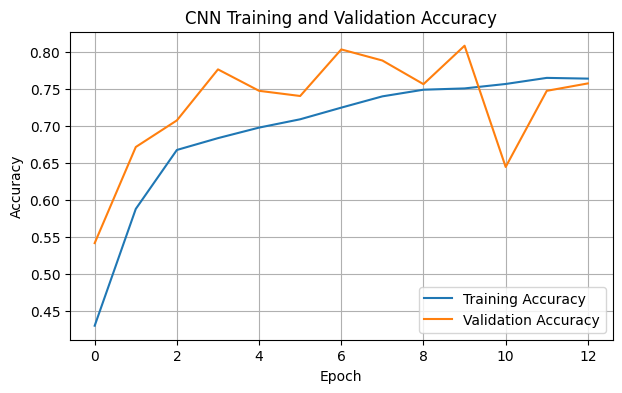

In [ ]:
import json
import matplotlib.pyplot as plt

path = "/content/drive/MyDrive/Brain_Tumor_Project/training_history.json"

with open(path, "r") as f:
    history = json.load(f)

plt.figure(figsize=(7, 4))
plt.plot(history["accuracy"], label="Training Accuracy")
plt.plot(history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
print("tl_model exists:", "tl_model" in globals())
print("train_ds_tl exists:", "train_ds_tl" in globals())
print("val_ds_tl exists:", "val_ds_tl" in globals())
print("preprocess_input exists:", "preprocess_input" in globals())

tl_model exists: False
train_ds_tl exists: True
val_ds_tl exists: True
preprocess_input exists: False


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import (
    MobileNetV2,
    preprocess_input
)
from tensorflow.keras import layers, models

print("MobileNetV2 imports ready!")

MobileNetV2 imports ready!


In [ ]:
# MobileNetV2 model creation

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

tl_model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Resizing(224, 224),
    layers.Lambda(lambda x: preprocess_input(x)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(num_classes, activation="softmax")
])

tl_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

tl_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

tl_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        "/content/best_mobilenetv2.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

tl_history = tl_model.fit(
    train_ds_tl,
    validation_data=val_ds_tl,
    epochs=10,
    callbacks=tl_callbacks
)

Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - accuracy: 0.4844 - loss: 1.2112
Epoch 1: val_loss improved from None to 0.47229, saving model to /content/best_mobilenetv2.keras

Epoch 1: finished saving model to /content/best_mobilenetv2.keras
500/500 ━━━━━━━━━━━━━━━━━━━━ 141s 265ms/step - accuracy: 0.6273 - loss: 0.9257 - val_accuracy: 0.8260 - val_loss: 0.4723
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step - accuracy: 0.7891 - loss: 0.5733
Epoch 2: val_loss improved from 0.47229 to 0.37662, saving model to /content/best_mobilenetv2.keras

Epoch 2: finished saving model to /content/best_mobilenetv2.keras
500/500 ━━━━━━━━━━━━━━━━━━━━ 114s 229ms/step - accuracy: 0.7995 - loss: 0.5450 - val_accuracy: 0.8570 - val_loss: 0.3766
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step - accuracy: 0.8410 - loss: 0.4458
Epoch 3: val_loss improved from 0.37662 to 0.32440, saving model to /content/best_mobilenetv2.keras

Epoch 3: finished saving model to /content/best_mobilenetv2.ke

In [ ]:
import os
import shutil

source = "/content/best_mobilenetv2.keras"
destination = (
    "/content/drive/MyDrive/Brain_Tumor_Project/"
    "best_mobilenetv2.keras"
)

os.makedirs(os.path.dirname(destination), exist_ok=True)

if os.path.exists(source):
    shutil.copy2(source, destination)
    print("MobileNetV2 model ka backup save ho gaya!")
else:
    print("Model file nahi mili. Pehle file check karni hogi.")



MobileNetV2 model ka backup save ho gaya!


In [ ]:
test_loss, test_accuracy = tl_model.evaluate(test_ds_tl)

print("MobileNetV2 Test Loss:", round(test_loss, 4))
print("MobileNetV2 Test Accuracy:", round(test_accuracy * 100, 2), "%")

125/125 ━━━━━━━━━━━━━━━━━━━━ 26s 209ms/step - accuracy: 0.8870 - loss: 0.2811
MobileNetV2 Test Loss: 0.2811
MobileNetV2 Test Accuracy: 88.7 %


In [ ]:
from sklearn.metrics import classification_report
import numpy as np

y_true = np.concatenate([y.numpy() for x, y in test_ds_tl])

y_pred_prob = tl_model.predict(test_ds_tl)
y_pred = np.argmax(y_pred_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

125/125 ━━━━━━━━━━━━━━━━━━━━ 28s 206ms/step
              precision    recall  f1-score   support

      glioma       0.92      0.80      0.86       254
  meningioma       0.81      0.84      0.83       306
    no_tumor       0.96      0.98      0.97       140
   pituitary       0.90      0.97      0.93       300

    accuracy                           0.89      1000
   macro avg       0.90      0.90      0.90      1000
weighted avg       0.89      0.89      0.89      1000



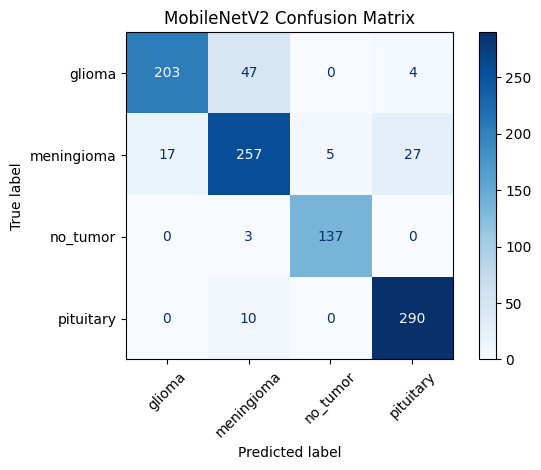

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("MobileNetV2 Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
import os
import shutil

source = "/content/best_mobilenetv2.keras"
destination = "/content/drive/MyDrive/Brain_Tumor_Project/best_mobilenetv2.keras"

if os.path.exists(source):
    shutil.copy2(source, destination)
    print("MobileNetV2 model Drive mein saved hai.")
else:
    print("Model file nahi mili.")

MobileNetV2 model Drive mein saved hai.


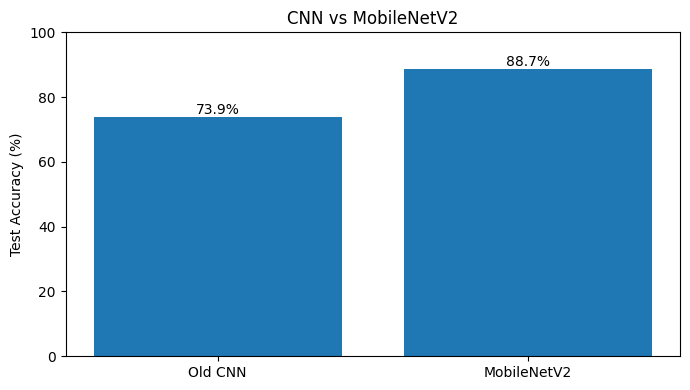

In [ ]:
import matplotlib.pyplot as plt

models = ["Old CNN", "MobileNetV2"]
accuracies = [73.9, 88.7]

plt.figure(figsize=(7, 4))
bars = plt.bar(models, accuracies)

plt.ylabel("Test Accuracy (%)")
plt.title("CNN vs MobileNetV2")
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [ ]:
import os

folder = "/content/drive/MyDrive/Brain_Tumor_Project"

for file in os.listdir(folder):
    print(file)

best_classweighted_cnn.keras
training_history.json
classification_report.txt
best_unet_segmentation.keras
segmentation_test_evaluation.csv
tumor_size_location_estimates.csv
unet_error_analysis.csv
threshold_comparison_evaluation.csv
one_image_integration_test.csv
best_brain_tumor_cnn.keras
best_mobilenetv2.keras


In [ ]:
import pandas as pd
import os

folder = "/content/drive/MyDrive/Brain_Tumor_Project"
file_path = os.path.join(folder, "segmentation_test_evaluation.csv")

df_seg = pd.read_csv(file_path)

print("Shape:", df_seg.shape)
print("\nColumns:")
print(df_seg.columns.tolist())

print("\nFirst 5 rows:")
display(df_seg.head())

Shape: (860, 6)

Columns:
['image', 'mask', 'actual_mask_pixels', 'predicted_mask_pixels', 'dice', 'iou']

First 5 rows:


,image,mask,actual_mask_pixels,predicted_mask_pixels,dice,iou
0,brisc2025_test_00001_gl_ax_t1.jpg,brisc2025_test_00001_gl_ax_t1.png,95,214,0.576052,0.404545
1,brisc2025_test_00002_gl_ax_t1.jpg,brisc2025_test_00002_gl_ax_t1.png,161,131,0.801370,0.668571
2,brisc2025_test_00003_gl_ax_t1.jpg,brisc2025_test_00003_gl_ax_t1.png,423,25,0.111607,0.059102
3,brisc2025_test_00004_gl_ax_t1.jpg,brisc2025_test_00004_gl_ax_t1.png,306,355,0.602118,0.430736
4,brisc2025_test_00005_gl_ax_t1.jpg,brisc2025_test_00005_gl_ax_t1.png,105,347,0.225664,0.127182


In [ ]:
print("Total test images:", len(df_seg))

print("Mean Dice:", round(df_seg["dice"].mean(), 4))
print("Median Dice:", round(df_seg["dice"].median(), 4))

print("Mean IoU:", round(df_seg["iou"].mean(), 4))
print("Median IoU:", round(df_seg["iou"].median(), 4))

print("\nMissing values:")
print(df_seg[["dice", "iou"]].isna().sum())


Total test images: 860
Mean Dice: 0.6501
Median Dice: 0.7922
Mean IoU: 0.5497
Median IoU: 0.6559

Missing values:
dice    0
iou     0
dtype: int64


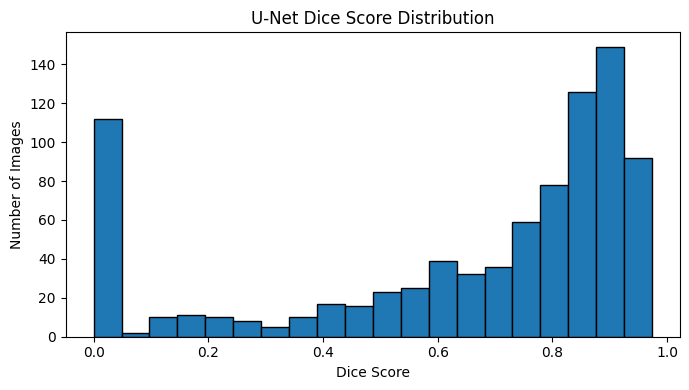

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.hist(df_seg["dice"], bins=20, edgecolor="black")

plt.xlabel("Dice Score")
plt.ylabel("Number of Images")
plt.title("U-Net Dice Score Distribution")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import os

folder = "/content/drive/MyDrive/Brain_Tumor_Project"
path = os.path.join(folder, "unet_error_analysis.csv")

df_error = pd.read_csv(path)

print("Shape:", df_error.shape)
print("Columns:", df_error.columns.tolist())
display(df_error.head())


Shape: (860, 9)
Columns: ['image', 'TP', 'FP', 'FN', 'TN', 'Dice', 'IoU', 'Precision', 'Recall']


,image,TP,FP,FN,TN,Dice,IoU,Precision,Recall
0,brisc2025_test_00001_gl_ax_t1.jpg,89,125,6,16164,0.576052,0.404545,0.415888,0.936842
1,brisc2025_test_00002_gl_ax_t1.jpg,117,14,44,16209,0.801370,0.668571,0.893130,0.726708
2,brisc2025_test_00003_gl_ax_t1.jpg,25,0,398,15961,0.111607,0.059102,1.000000,0.059102
3,brisc2025_test_00004_gl_ax_t1.jpg,199,156,107,15922,0.602118,0.430736,0.560563,0.650327
4,brisc2025_test_00005_gl_ax_t1.jpg,51,296,54,15983,0.225664,0.127182,0.146974,0.485714


In [ ]:
weak_images = df_error.sort_values(
    by="Dice", ascending=True
).head(10)

display(
    weak_images[
        ["image", "TP", "FP", "FN", "Dice", "IoU", "Precision", "Recall"]
    ]
)

,image,TP,FP,FN,Dice,IoU,Precision,Recall
238,brisc2025_test_00239_gl_sa_t1.jpg,0,0,1411,7.087172e-11,7.087172e-11,1.000000e+00,7.087172e-11
96,brisc2025_test_00097_gl_co_t1.jpg,0,0,1167,8.568980e-11,8.568980e-11,1.000000e+00,8.568980e-11
154,brisc2025_test_00155_gl_co_t1.jpg,0,0,1144,8.741259e-11,8.741259e-11,1.000000e+00,8.741259e-11
156,brisc2025_test_00157_gl_co_t1.jpg,0,0,1031,9.699321e-11,9.699321e-11,1.000000e+00,9.699321e-11
251,brisc2025_test_00252_gl_sa_t1.jpg,0,0,1001,9.990010e-11,9.990010e-11,1.000000e+00,9.990010e-11
5,brisc2025_test_00006_gl_ax_t1.jpg,0,496,344,1.190476e-10,1.190476e-10,2.016129e-10,2.906977e-10
45,brisc2025_test_00046_gl_ax_t1.jpg,0,0,832,1.201923e-10,1.201923e-10,1.000000e+00,1.201923e-10
157,brisc2025_test_00158_gl_co_t1.jpg,0,0,792,1.262626e-10,1.262626e-10,1.000000e+00,1.262626e-10
8,brisc2025_test_00009_gl_ax_t1.jpg,0,145,636,1.280410e-10,1.280410e-10,6.896552e-10,1.572327e-10
164,brisc2025_test_00165_gl_co_t1.jpg,0,0,778,1.285347e-10,1.285347e-10,1.000000e+00,1.285347e-10


In [ ]:
print("Image/mask related variables:")

for name, value in globals().copy().items():
    if any(word in name.lower() for word in ["image", "mask", "test_dir", "test_path"]):
        if isinstance(value, (str, list, tuple)):
            print(name, "=", value if isinstance(value, str) else type(value).__name__)


Image/mask related variables:
CLASS_TEST_DIR = /content/brisc_data/brisc2025/classification_task/test
SEG_TRAIN_IMAGES = /content/brisc_data/brisc2025/segmentation_task/train/images
SEG_TRAIN_MASKS = /content/brisc_data/brisc2025/segmentation_task/train/masks
SEG_TEST_IMAGES = /content/brisc_data/brisc2025/segmentation_task/test/images
SEG_TEST_MASKS = /content/brisc_data/brisc2025/segmentation_task/test/masks
test_path = /content/brisc_data/brisc2025/classification_task/test/pituitary
image_files = list
image_path = /content/brisc_data/brisc2025/segmentation_task/train/images/brisc2025_train_01219_me_ax_t1.jpg
train_images = list
train_masks = list
test_images = list
test_masks = list
mask_path = /content/brisc_data/brisc2025/segmentation_task/train/masks/brisc2025_train_01219_me_ax_t1.png
mask_name = brisc2025_train_01393_me_ax_t1


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

image_name = "brisc2025_test_00003_gl_ax_t1.jpg"
mask_name = "brisc2025_test_00003_gl_ax_t1.png"

image_path = os.path.join(SEG_TEST_IMAGES, image_name)
mask_path = os.path.join(SEG_TEST_MASKS, mask_name)

print("Image exists:", os.path.exists(image_path))
print("Mask exists:", os.path.exists(mask_path))
print("U-Net model exists:", "unet_model" in globals())

Image exists: True
Mask exists: True
U-Net model exists: False


In [ ]:
import tensorflow as tf
import os

model_path = "/content/drive/MyDrive/Brain_Tumor_Project/best_unet_segmentation.keras"

unet_model = tf.keras.models.load_model(
    model_path,
    compile=False
)

print("U-Net model loaded successfully!")
print("Input shape:", unet_model.input_shape)
print("Output shape:", unet_model.output_shape)



U-Net model loaded successfully!
Input shape: (None, 128, 128, 1)
Output shape: (None, 128, 128, 1)


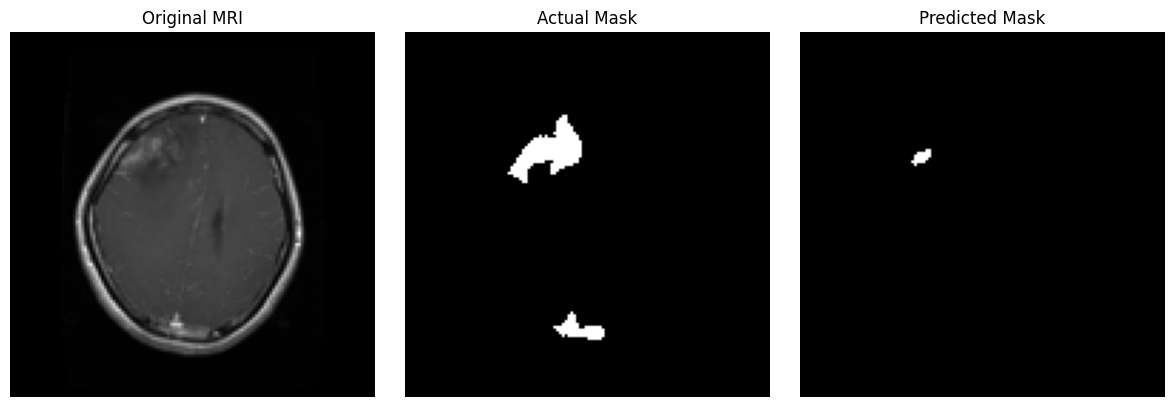

Actual tumor pixels: 361
Predicted tumor pixels: 24


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Load MRI and actual mask
img = Image.open(image_path).convert("L").resize((128, 128))
mask = Image.open(mask_path).convert("L").resize((128, 128))

img_array = np.array(img, dtype=np.float32) / 255.0
mask_array = np.array(mask)

# Convert actual mask to binary
actual_mask = (mask_array > 127).astype(np.uint8)

# Predict tumor mask
prediction = unet_model.predict(
    img_array[np.newaxis, ..., np.newaxis],
    verbose=0
)[0, :, :, 0]

predicted_mask = (prediction >= 0.5).astype(np.uint8)

# Display all three
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img_array, cmap="gray")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(actual_mask, cmap="gray")
plt.title("Actual Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(predicted_mask, cmap="gray")
plt.title("Predicted Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Actual tumor pixels:", int(actual_mask.sum()))
print("Predicted tumor pixels:", int(predicted_mask.sum()))

In [ ]:
from PIL import Image
import numpy as np

original_mask = np.array(
    Image.open(mask_path).convert("L")
)

print("Original mask shape:", original_mask.shape)
print("Unique pixel values:", np.unique(original_mask)[:20])
print("Minimum value:", original_mask.min())
print("Maximum value:", original_mask.max())



Original mask shape: (512, 512)
Unique pixel values: [  0   1   2   3   4   5   6   7 248 249 250 251 252 253 254 255]
Minimum value: 0
Maximum value: 255


In [ ]:
from PIL import Image
import numpy as np

original = Image.open(mask_path).convert("L")

# Nearest-neighbor resize
nearest_mask = original.resize(
    (128, 128),
    resample=Image.Resampling.NEAREST
)

nearest_array = np.array(nearest_mask)

print("Original unique values:", np.unique(np.array(original))[:20])
print("Resized unique values:", np.unique(nearest_array))
print("White pixels after resize:", np.sum(nearest_array > 127))


Original unique values: [  0   1   2   3   4   5   6   7 248 249 250 251 252 253 254 255]
Resized unique values: [  0   1   2   3   4   5   6 249 250 251 252 253 254 255]
White pixels after resize: 362


In [ ]:
import numpy as np
from PIL import Image

original = np.array(Image.open(mask_path).convert("L"))
nearest = np.array(
    Image.open(mask_path).convert("L").resize(
        (128, 128),
        resample=Image.Resampling.NEAREST
    )
)

print("Original white pixels:", np.sum(original > 127))
print("Resized white pixels:", np.sum(nearest > 127))
print("Original foreground ratio:", round(np.mean(original > 127), 4))
print("Resized foreground ratio:", round(np.mean(nearest > 127), 4))



Original white pixels: 5789
Resized white pixels: 362
Original foreground ratio: 0.0221
Resized foreground ratio: 0.0221


In [ ]:
print("U-Net input shape:", unet_model.input_shape)
print("U-Net output shape:", unet_model.output_shape)

print("\nSegmentation training image folder:", SEG_TRAIN_IMAGES)
print("Segmentation training mask folder:", SEG_TRAIN_MASKS)


U-Net input shape: (None, 128, 128, 1)
U-Net output shape: (None, 128, 128, 1)

Segmentation training image folder: /content/brisc_data/brisc2025/segmentation_task/train/images
Segmentation training mask folder: /content/brisc_data/brisc2025/segmentation_task/train/masks


In [ ]:
import os
import numpy as np
from PIL import Image

# Ek training image aur uska matching mask
image_name = sorted(os.listdir(SEG_TRAIN_IMAGES))[0]
mask_name = os.path.splitext(image_name)[0] + ".png"

train_image_path = os.path.join(SEG_TRAIN_IMAGES, image_name)
train_mask_path = os.path.join(SEG_TRAIN_MASKS, mask_name)

print("Image:", image_name)
print("Matching mask exists:", os.path.exists(train_mask_path))

if os.path.exists(train_mask_path):
    train_mask = np.array(
        Image.open(train_mask_path).convert("L")
    )
    print("Mask shape:", train_mask.shape)
    print("Unique mask values:", np.unique(train_mask)[:20])
    print("White pixels:", np.sum(train_mask > 127))

Image: brisc2025_train_00001_gl_ax_t1.jpg
Matching mask exists: True
Mask shape: (512, 512)
Unique mask values: [  0   1   2   3   4   5   6   7 248 249 250 251 252 253 254 255]
White pixels: 16345


In [ ]:
print("X_train:", "X_train" in globals())
print("Y_train:", "Y_train" in globals())
print("X_val:", "X_val" in globals())
print("Y_val:", "Y_val" in globals())

X_train: False
Y_train: False
X_val: False
Y_val: False


In [ ]:
import os

train_images_path = "/content/brisc_data/brisc2025/segmentation_task/train/images"
train_masks_path = "/content/brisc_data/brisc2025/segmentation_task/train/masks"

print("Images folder exists:", os.path.exists(train_images_path))
print("Masks folder exists:", os.path.exists(train_masks_path))

print("Training images:", len(os.listdir(train_images_path)))
print("Training masks:", len(os.listdir(train_masks_path)))

Images folder exists: True
Masks folder exists: True
Training images: 3933
Training masks: 3933


In [ ]:
import os

image_files = sorted([
    f for f in os.listdir(train_images_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

mask_files = sorted([
    f for f in os.listdir(train_masks_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

print("First 5 images:")
print(image_files[:5])

print("\nFirst 5 masks:")
print(mask_files[:5])

print("\nSame filenames:", image_files == mask_files)

First 5 images:
['brisc2025_train_00001_gl_ax_t1.jpg', 'brisc2025_train_00002_gl_ax_t1.jpg', 'brisc2025_train_00003_gl_ax_t1.jpg', 'brisc2025_train_00004_gl_ax_t1.jpg', 'brisc2025_train_00005_gl_ax_t1.jpg']

First 5 masks:
['brisc2025_train_00001_gl_ax_t1.png', 'brisc2025_train_00002_gl_ax_t1.png', 'brisc2025_train_00003_gl_ax_t1.png', 'brisc2025_train_00004_gl_ax_t1.png', 'brisc2025_train_00005_gl_ax_t1.png']

Same filenames: False


In [ ]:
image_names = {
    os.path.splitext(f)[0]
    for f in image_files
}

mask_names = {
    os.path.splitext(f)[0]
    for f in mask_files
}

print("Matching pairs:", len(image_names & mask_names))
print("Images without matching masks:", len(image_names - mask_names))
print("Masks without matching images:", len(mask_names - image_names))


Matching pairs: 3933
Images without matching masks: 0
Masks without matching images: 0


In [ ]:
import os
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split

# Image aur mask filenames ko match karna
image_files = sorted([
    f for f in os.listdir(train_images_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

mask_files = sorted([
    f for f in os.listdir(train_masks_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

# 128 × 128 images aur masks load karna
X = []
Y = []

for img_name in image_files:
    mask_name = os.path.splitext(img_name)[0] + ".png"

    img_path = os.path.join(train_images_path, img_name)
    mask_path = os.path.join(train_masks_path, mask_name)

    img = Image.open(img_path).convert("L").resize((128, 128))
    mask = Image.open(mask_path).convert("L").resize(
        (128, 128), Image.Resampling.NEAREST
    )

    X.append(np.array(img, dtype=np.float32) / 255.0)
    Y.append((np.array(mask) > 127).astype(np.float32))

X = np.array(X)[..., np.newaxis]
Y = np.array(Y)[..., np.newaxis]

# Training aur validation split
X_train, X_val, Y_train, Y_val = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)
print("X_val:", X_val.shape)
print("Y_val:", Y_val.shape)

X_train: (3146, 128, 128, 1)
Y_train: (3146, 128, 128, 1)
X_val: (787, 128, 128, 1)
Y_val: (787, 128, 128, 1)


In [ ]:
print("Model input shape:", unet_model.input_shape)
print("Model output shape:", unet_model.output_shape)
print("Training image shape:", X_train.shape)
print("Training mask shape:", Y_train.shape)
print("Mask values:", np.unique(Y_train))

Model input shape: (None, 128, 128, 1)
Model output shape: (None, 128, 128, 1)
Training image shape: (3146, 128, 128, 1)
Training mask shape: (3146, 128, 128, 1)
Mask values: [0. 1.]


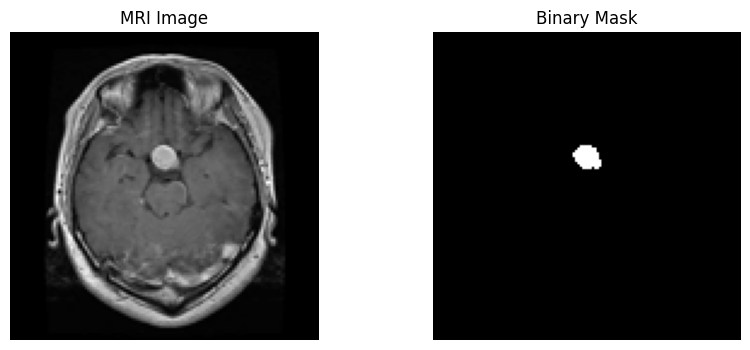

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(X_train[0].squeeze(), cmap="gray")
plt.title("MRI Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(Y_train[0].squeeze(), cmap="gray")
plt.title("Binary Mask")
plt.axis("off")

plt.show()

In [ ]:
# Har mask mein white pixels count karna
white_pixels = Y_train.sum(axis=(1, 2, 3))

print("Total training images:", len(Y_train))
print("Blank masks:", (white_pixels == 0).sum())
print("Non-blank masks:", (white_pixels > 0).sum())
print("Minimum white pixels:", white_pixels.min())
print("Maximum white pixels:", white_pixels.max())


Total training images: 3146
Blank masks: 0
Non-blank masks: 3146
Minimum white pixels: 2.0
Maximum white pixels: 2836.0


Original white pixels: 16345
Resized white pixels: 1023


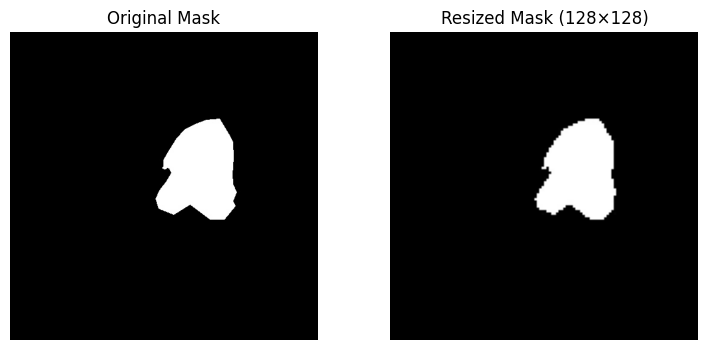

In [ ]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

img_name = image_files[0]
mask_name = os.path.splitext(img_name)[0] + ".png"

original_mask = np.array(
    Image.open(os.path.join(train_masks_path, mask_name)).convert("L")
)

resized_mask = np.array(
    Image.open(os.path.join(train_masks_path, mask_name))
    .convert("L")
    .resize((128, 128), Image.Resampling.NEAREST)
)

print("Original white pixels:", (original_mask > 127).sum())
print("Resized white pixels:", (resized_mask > 127).sum())

plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_mask, cmap="gray")
plt.title("Original Mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized_mask, cmap="gray")
plt.title("Resized Mask (128×128)")
plt.axis("off")

plt.show()

In [ ]:
print("Model loss:", unet_model.loss)
print("Optimizer:", unet_model.optimizer if hasattr(unet_model, "optimizer") else "Not compiled")

Model loss: None
Optimizer: Not compiled


In [ ]:
unet_model.summary()

Model: "UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 128, 128,  │        320 │ input_layer_5[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d_6[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 64, 64,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d_6[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 64, 64,    │     36,928 │ conv2d_8[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 32, 32,    │          0 │ conv2d_9[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 32, 32,    │     73,856 │ max_pooling2d_7[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 32, 32,    │    147,584 │ conv2d_10[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 16, 16,    │          0 │ conv2d_11[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 16, 16,    │    295,168 │ max_pooling2d_8[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 16, 16,    │    590,080 │ conv2d_12[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_9     │ (None, 8, 8, 256) │          0 │ conv2d_13[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 8, 8, 512) │  1,180,160 │ max_pooling2d_9[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 8, 8, 512) │  2,359,808 │ conv2d_14[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 16, 16,    │    524,544 │ conv2d_15[0][0]   │
│ (Conv2DTranspose)   │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 512)              │            │ conv2d_13[0][0]   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 7,759,521 (29.60 MB)

 Trainable params: 7,759,521 (29.60 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
last_layer = unet_model.layers[-1]

print("Final layer:", last_layer.name)
print("Activation:", last_layer.activation.__name__)

Final layer: conv2d_24
Activation: sigmoid


In [ ]:
import tensorflow as tf

def dice_loss(y_true, y_pred):
    smooth = 1e-6
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])

    intersection = tf.reduce_sum(y_true_f * y_pred_f)

    dice = (2.0 * intersection + smooth) / (
        tf.reduce_sum(y_true_f) +
        tf.reduce_sum(y_pred_f) + smooth
    )

    return 1.0 - dice

def combined_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    return tf.reduce_mean(bce) + dice_loss(y_true, y_pred)

unet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=combined_loss,
    metrics=["binary_accuracy"]
)

print("U-Net compiled successfully!")

U-Net compiled successfully!


In [ ]:
backup_path = "/content/drive/MyDrive/Brain_Tumor_Project/unet_before_retraining.keras"

unet_model.save(backup_path)

print("Backup saved successfully!")

Backup saved successfully!


In [ ]:
history_test = unet_model.fit(
    X_train[:2],
    Y_train[:2],
    validation_data=(X_val[:2], Y_val[:2]),
    epochs=1,
    batch_size=2,
    verbose=1
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step - binary_accuracy: 0.9967 - loss: 0.2471 - val_binary_accuracy: 0.9899 - val_loss: 0.1811


In [ ]:
import numpy as np

pred = unet_model.predict(X_val[:2], verbose=0)
pred_mask = (pred > 0.5).astype(np.float32)

for i in range(2):
    true_mask = Y_val[i]
    predicted_mask = pred_mask[i]

    intersection = np.sum(true_mask * predicted_mask)

    dice = (2 * intersection + 1e-6) / (
        np.sum(true_mask) + np.sum(predicted_mask) + 1e-6
    )

    print(f"Image {i+1} Dice Score: {dice:.4f}")

Image 1 Dice Score: 0.9106
Image 2 Dice Score: 0.8328


In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np

predictions = unet_model.predict(
    X_val, batch_size=16, verbose=1
)

predictions = (predictions > 0.5).astype(np.float32)

dice_scores = []

for i in range(len(Y_val)):
    true_mask = Y_val[i]
    pred_mask = predictions[i]

    intersection = np.sum(true_mask * pred_mask)

    dice = (2 * intersection + 1e-6) / (
        np.sum(true_mask) + np.sum(pred_mask) + 1e-6
    )

    dice_scores.append(dice)

print("Validation images:", len(dice_scores))
print("Mean Dice:", round(float(np.mean(dice_scores)), 4))
print("Median Dice:", round(float(np.median(dice_scores)), 4))
print("Dice below 0.5:", sum(d < 0.5 for d in dice_scores))

50/50 ━━━━━━━━━━━━━━━━━━━━ 73s 1s/step
Validation images: 787
Mean Dice: 0.6229
Median Dice: 0.7747
Dice below 0.5: 218


In [ ]:
worst_indices = np.argsort(dice_scores)[:5]

for i in worst_indices:
    print(
        f"Validation index: {i}, "
        f"Dice: {dice_scores[i]:.4f}"
    )

Validation index: 411, Dice: 0.0000
Validation index: 48, Dice: 0.0000
Validation index: 18, Dice: 0.0000
Validation index: 99, Dice: 0.0000
Validation index: 489, Dice: 0.0000


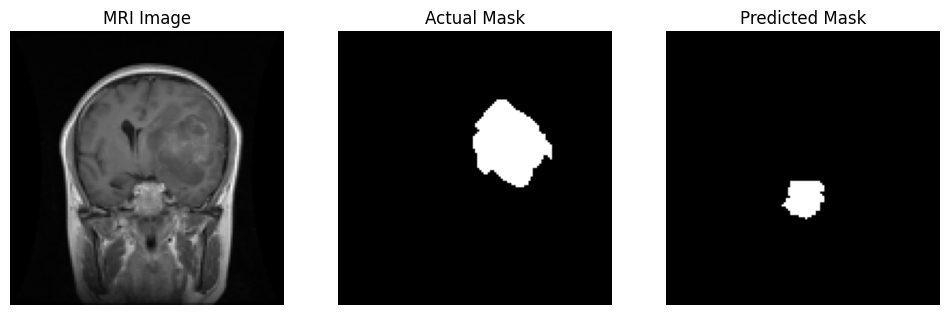

Actual white pixels: 987
Predicted white pixels: 259
Dice score: 8.0256823e-10


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

i = 411

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(X_val[i].squeeze(), cmap="gray")
plt.title("MRI Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(Y_val[i].squeeze(), cmap="gray")
plt.title("Actual Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(predictions[i].squeeze(), cmap="gray")
plt.title("Predicted Mask")
plt.axis("off")

plt.show()

print("Actual white pixels:", int(Y_val[i].sum()))
print("Predicted white pixels:", int(predictions[i].sum()))
print("Dice score:", dice_scores[i])

In [ ]:
i = 411

actual = (Y_val[i].squeeze() > 0.5)
predicted = (predictions[i].squeeze() > 0.5)

print("Actual mask shape:", actual.shape)
print("Predicted mask shape:", predicted.shape)
print("Actual tumor pixels:", actual.sum())
print("Predicted tumor pixels:", predicted.sum())
print("Overlapping pixels:", np.logical_and(actual, predicted).sum())
print("Actual mask empty:", not actual.any())
print("Predicted mask empty:", not predicted.any())

Actual mask shape: (128, 128)
Predicted mask shape: (128, 128)
Actual tumor pixels: 987
Predicted tumor pixels: 259
Overlapping pixels: 0
Actual mask empty: False
Predicted mask empty: False


In [ ]:
import os

print("Validation image index:", 411)
print("Total training images:", len(image_files))
print("Image filenames ke first 5 examples:")
print(image_files[:5])

Validation image index: 411
Total training images: 3933
Image filenames ke first 5 examples:
['brisc2025_train_00001_gl_ax_t1.jpg', 'brisc2025_train_00002_gl_ax_t1.jpg', 'brisc2025_train_00003_gl_ax_t1.jpg', 'brisc2025_train_00004_gl_ax_t1.jpg', 'brisc2025_train_00005_gl_ax_t1.jpg']


In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np

all_indices = np.arange(len(image_files))

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.2,
    random_state=42
)

i = 411
original_index = val_indices[i]

print("Validation index:", i)
print("Original image filename:", image_files[original_index])

mask_name = os.path.splitext(image_files[original_index])[0] + ".png"
print("Matching mask filename:", mask_name)

Validation index: 411
Original image filename: brisc2025_train_00812_gl_co_t1.jpg
Matching mask filename: brisc2025_train_00812_gl_co_t1.png


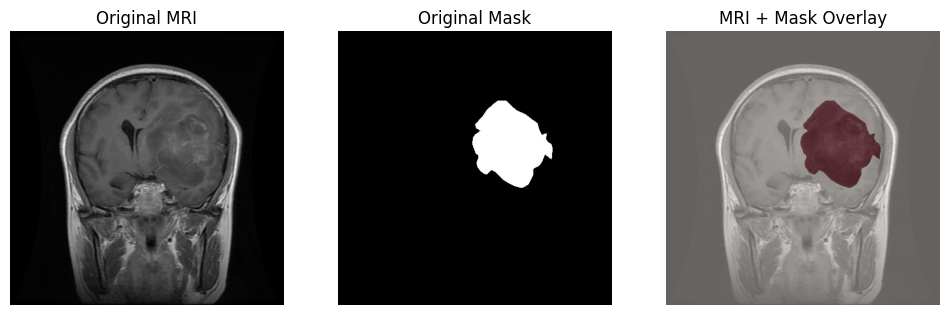

MRI size: (512, 512)
Mask size: (512, 512)


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

i = 411
original_index = val_indices[i]

img_name = image_files[original_index]
mask_name = os.path.splitext(img_name)[0] + ".png"

img_path = os.path.join(train_images_path, img_name)
mask_path = os.path.join(train_masks_path, mask_name)

original_img = Image.open(img_path).convert("L")
original_mask = Image.open(mask_path).convert("L")

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_img, cmap="gray")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(original_mask, cmap="gray")
plt.title("Original Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(original_img, cmap="gray")
plt.imshow(
    np.array(original_mask) > 127,
    cmap="Reds",
    alpha=0.4
)
plt.title("MRI + Mask Overlay")
plt.axis("off")

plt.show()

print("MRI size:", original_img.size)
print("Mask size:", original_mask.size)

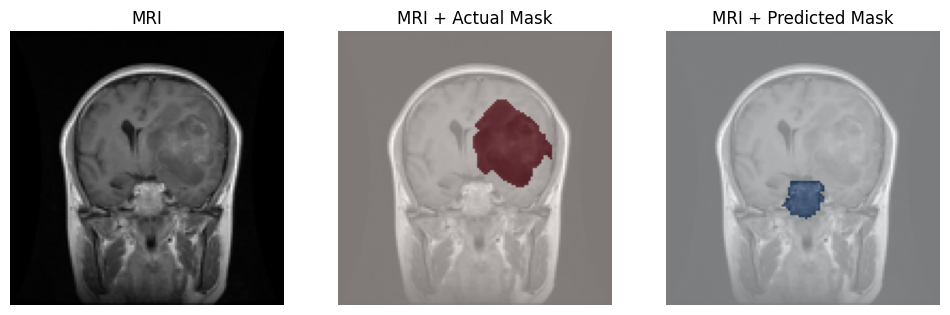

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

i = 411

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(X_val[i].squeeze(), cmap="gray")
plt.title("MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(X_val[i].squeeze(), cmap="gray")
plt.imshow(Y_val[i].squeeze(), cmap="Reds", alpha=0.5)
plt.title("MRI + Actual Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(X_val[i].squeeze(), cmap="gray")
plt.imshow(predictions[i].squeeze(), cmap="Blues", alpha=0.5)
plt.title("MRI + Predicted Mask")
plt.axis("off")

plt.show()

In [ ]:
import numpy as np

i = 411

actual = Y_val[i].squeeze() > 0.5
predicted = predictions[i].squeeze() > 0.5

ay, ax = np.where(actual)
py, px = np.where(predicted)

print("Actual mask bounding box:")
print("Top, Bottom, Left, Right:",
      ay.min(), ay.max(), ax.min(), ax.max())

print("\nPredicted mask bounding box:")
print("Top, Bottom, Left, Right:",
      py.min(), py.max(), px.min(), px.max())

Actual mask bounding box:
Top, Bottom, Left, Right: 32 72 63 99

Predicted mask bounding box:
Top, Bottom, Left, Right: 70 87 54 73


In [ ]:
from PIL import Image
import numpy as np

i = 411
original_index = val_indices[i]

img_name = image_files[original_index]
mask_name = os.path.splitext(img_name)[0] + ".png"

original_img = np.array(
    Image.open(os.path.join(train_images_path, img_name)).convert("L").resize((128, 128))
) / 255.0

original_mask = np.array(
    Image.open(os.path.join(train_masks_path, mask_name)).convert("L").resize((128, 128), Image.Resampling.NEAREST)
) > 127

print("MRI array difference:",
      np.mean(np.abs(original_img - X_val[i].squeeze())))

print("Mask array difference:",
      np.mean(np.abs(original_mask.astype(float) - Y_val[i].squeeze())))

MRI array difference: 4.71370796249285e-09
Mask array difference: 0.0


In [ ]:
# Original probability map, threshold lagane se pehle
prob_map = unet_model.predict(X_val[411:412], verbose=0)[0].squeeze()

print("Minimum probability:", float(prob_map.min()))
print("Maximum probability:", float(prob_map.max()))
print("Mean probability:", float(prob_map.mean()))

for threshold in [0.3, 0.5, 0.7]:
    pred_mask = prob_map > threshold
    overlap = np.logical_and(Y_val[411].squeeze() > 0.5, pred_mask).sum()

    print(
        f"Threshold {threshold}: "
        f"Predicted pixels = {pred_mask.sum()}, "
        f"Overlap = {overlap}"
    )

Minimum probability: 0.0
Maximum probability: 0.9999829530715942
Mean probability: 0.01604338176548481
Threshold 0.3: Predicted pixels = 266, Overlap = 0
Threshold 0.5: Predicted pixels = 259, Overlap = 0
Threshold 0.7: Predicted pixels = 250, Overlap = 0


In [ ]:
import tensorflow as tf
import numpy as np

backup_path = "/content/drive/MyDrive/Brain_Tumor_Project/unet_before_retraining.keras"

original_unet = tf.keras.models.load_model(
    backup_path,
    compile=False
)

current_weights = unet_model.get_weights()
original_weights = original_unet.get_weights()

differences = [
    np.mean(np.abs(a - b))
    for a, b in zip(current_weights, original_weights)
]

print("Number of weight arrays:", len(differences))
print("Average weight difference:", np.mean(differences))
print("Maximum weight difference:", np.max(differences))

Number of weight arrays: 46
Average weight difference: 4.5277622e-05
Maximum weight difference: 9.999052e-05


In [ ]:
import numpy as np

i = 411

# Original saved model ki prediction
original_prob = original_unet.predict(
    X_val[i:i+1], verbose=0
)[0].squeeze()

# Current model ki prediction
current_prob = unet_model.predict(
    X_val[i:i+1], verbose=0
)[0].squeeze()

actual = Y_val[i].squeeze() > 0.5

for name, prob in [
    ("Original model", original_prob),
    ("Current model", current_prob)
]:
    pred_mask = prob > 0.5
    overlap = np.logical_and(actual, pred_mask).sum()

    dice = (
        2 * overlap + 1e-6
    ) / (
        actual.sum() + pred_mask.sum() + 1e-6
    )

    print(f"\n{name}")
    print("Predicted pixels:", int(pred_mask.sum()))
    print("Overlap:", int(overlap))
    print("Dice:", float(dice))


Original model
Predicted pixels: 262
Overlap: 0
Dice: 8.006405117689026e-10

Current model
Predicted pixels: 259
Overlap: 0
Dice: 8.025682176544395e-10


In [ ]:
import numpy as np
from PIL import Image
import os

i = 411
original_index = val_indices[i]

img_name = image_files[original_index]
mask_name = os.path.splitext(img_name)[0] + ".png"

mask_path = os.path.join(train_masks_path, mask_name)
mask_array = np.array(Image.open(mask_path).convert("L"))

values, counts = np.unique(mask_array, return_counts=True)

print("Unique mask pixel values:")
print(values)

print("\nMost frequent values:")
for value, count in zip(values, counts):
    print(f"Value {value}: {count} pixels")

print("\nWhite pixels (>127):", int((mask_array > 127).sum()))
print("Non-zero pixels:", int((mask_array > 0).sum()))

Unique mask pixel values:
[  0   1   2   3   4   5   6   7 248 249 250 251 252 253 254 255]

Most frequent values:
Value 0: 245426 pixels
Value 1: 434 pixels
Value 2: 244 pixels
Value 3: 120 pixels
Value 4: 52 pixels
Value 5: 25 pixels
Value 6: 8 pixels
Value 7: 1 pixels
Value 248: 2 pixels
Value 249: 4 pixels
Value 250: 21 pixels
Value 251: 39 pixels
Value 252: 109 pixels
Value 253: 268 pixels
Value 254: 420 pixels
Value 255: 14971 pixels

White pixels (>127): 15834
Non-zero pixels: 16718


In [ ]:
import numpy as np
from PIL import Image
import os

i = 411
original_index = val_indices[i]

mask_name = os.path.splitext(image_files[original_index])[0] + ".png"
mask_path = os.path.join(train_masks_path, mask_name)

mask = np.array(Image.open(mask_path).convert("L"))
mask_resized = np.array(
    Image.fromarray(mask).resize(
        (128, 128), Image.Resampling.NEAREST
    )
)

methods = {
    "Threshold > 0": mask_resized > 0,
    "Threshold > 127": mask_resized > 127,
    "Threshold >= 248": mask_resized >= 248
}

for name, binary_mask in methods.items():
    print(name, "| Foreground pixels:", int(binary_mask.sum()))

Threshold > 0 | Foreground pixels: 1050
Threshold > 127 | Foreground pixels: 987
Threshold >= 248 | Foreground pixels: 987


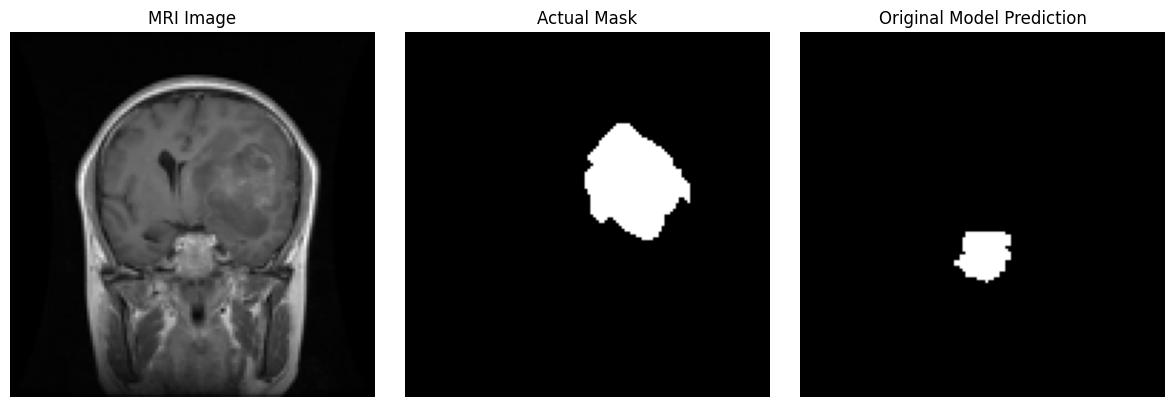

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

i = 411

actual = Y_val[i].squeeze()
prob = original_unet.predict(
    X_val[i:i+1], verbose=0
)[0].squeeze()
predicted = prob > 0.5

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(X_val[i].squeeze(), cmap="gray")
plt.title("MRI Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(actual, cmap="gray")
plt.title("Actual Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(predicted, cmap="gray")
plt.title("Original Model Prediction")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

i = 411

actual = Y_val[i].squeeze() > 0.5
prob = original_unet.predict(X_val[i:i+1], verbose=0)[0].squeeze()
predicted = prob > 0.5

print("Actual tumor center (row, column):",
      np.argwhere(actual).mean(axis=0).round(1))

print("Predicted region center (row, column):",
      np.argwhere(predicted).mean(axis=0).round(1))

print("Actual foreground pixels:", int(actual.sum()))
print("Predicted foreground pixels:", int(predicted.sum()))
print("Maximum prediction probability:", float(prob.max()))

Actual tumor center (row, column): [52.3 79.7]
Predicted region center (row, column): [77.6 64.2]
Actual foreground pixels: 987
Predicted foreground pixels: 262
Maximum prediction probability: 0.9999861717224121


In [ ]:
import numpy as np

probabilities = original_unet.predict(
    X_val[:5], batch_size=5, verbose=0
)

for i in range(5):
    actual = Y_val[i].squeeze() > 0.5
    predicted = probabilities[i].squeeze() > 0.5

    intersection = np.logical_and(actual, predicted).sum()
    dice = (2 * intersection + 1e-6) / (
        actual.sum() + predicted.sum() + 1e-6
    )

    print(
        f"Image {i}: Dice = {dice:.4f}, "
        f"Actual pixels = {actual.sum()}, "
        f"Predicted pixels = {predicted.sum()}"
    )

Image 0: Dice = 0.9095, Actual pixels = 383, Predicted pixels = 457
Image 1: Dice = 0.8325, Actual pixels = 740, Predicted pixels = 788
Image 2: Dice = 0.2492, Actual pixels = 39, Predicted pixels = 266
Image 3: Dice = 0.7829, Actual pixels = 271, Predicted pixels = 337
Image 4: Dice = 0.8228, Actual pixels = 167, Predicted pixels = 166


In [ ]:
import numpy as np

pred_probs = original_unet.predict(
    X_val, batch_size=16, verbose=1
)
pred_masks = pred_probs > 0.5

small_dice = []
medium_dice = []
large_dice = []

for i in range(len(Y_val)):
    actual = Y_val[i].squeeze() > 0.5
    predicted = pred_masks[i].squeeze()

    actual_pixels = int(actual.sum())
    intersection = np.logical_and(actual, predicted).sum()

    dice = (2 * intersection + 1e-6) / (
        actual.sum() + predicted.sum() + 1e-6
    )

    if actual_pixels < 100:
        small_dice.append(dice)
    elif actual_pixels < 500:
        medium_dice.append(dice)
    else:
        large_dice.append(dice)

for name, scores in [
    ("Small masks (<100 pixels)", small_dice),
    ("Medium masks (100–499 pixels)", medium_dice),
    ("Large masks (500+ pixels)", large_dice)
]:
    print(f"\n{name}")
    print("Images:", len(scores))
    print("Mean Dice:", round(float(np.mean(scores)), 4))

50/50 ━━━━━━━━━━━━━━━━━━━━ 75s 1s/step

Small masks (<100 pixels)
Images: 157
Mean Dice: 0.4744

Medium masks (100–499 pixels)
Images: 523
Mean Dice: 0.6691

Large masks (500+ pixels)
Images: 107
Mean Dice: 0.5893


In [ ]:
import numpy as np

all_dice = []

for i in range(len(Y_val)):
    actual = Y_val[i].squeeze() > 0.5
    predicted = pred_masks[i].squeeze()

    intersection = np.logical_and(actual, predicted).sum()

    dice = (2 * intersection + 1e-6) / (
        actual.sum() + predicted.sum() + 1e-6
    )

    all_dice.append(dice)

print("Validation images:", len(all_dice))
print("Mean Dice:", round(float(np.mean(all_dice)), 4))
print("Median Dice:", round(float(np.median(all_dice)), 4))
print("Images with Dice below 0.5:",
      sum(d < 0.5 for d in all_dice))


Validation images: 787
Mean Dice: 0.6194
Median Dice: 0.7674
Images with Dice below 0.5: 223


In [ ]:
import json

history_path = (
    "/content/drive/MyDrive/Brain_Tumor_Project/"
    "training_history.json"
)

with open(history_path, "r") as f:
    history_data = json.load(f)

print("History keys:", list(history_data.keys()))

for key, values in history_data.items():
    if isinstance(values, list):
        print(f"{key}: {len(values)} epochs")
        print("First 3:", values[:3])
        print("Last 3:", values[-3:])


History keys: ['accuracy', 'loss', 'val_accuracy', 'val_loss']
accuracy: 13 epochs
First 3: [0.43024998903274536, 0.5882499814033508, 0.6679999828338623]
Last 3: [0.7572500109672546, 0.765500009059906, 0.7645000219345093]
loss: 13 epochs
First 3: [1.2627196311950684, 1.0022422075271606, 0.8356956839561462]
Last 3: [0.59319007396698, 0.5691670179367065, 0.5588055849075317]
val_accuracy: 13 epochs
First 3: [0.5419999957084656, 0.671999990940094, 0.7080000042915344]
Last 3: [0.6449999809265137, 0.7480000257492065, 0.7580000162124634]
val_loss: 13 epochs
First 3: [1.116662621498108, 0.7642857432365417, 0.704582691192627]
Last 3: [0.9197227358818054, 0.6508830785751343, 0.5999250411987305]


In [ ]:
import pandas as pd

csv_path = (
    "/content/drive/MyDrive/Brain_Tumor_Project/"
    "segmentation_test_evaluation.csv"
)

df = pd.read_csv(csv_path)

print("Columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

print("\nNumber of rows:", len(df))

Columns:
['image', 'mask', 'actual_mask_pixels', 'predicted_mask_pixels', 'dice', 'iou']

First 5 rows:
                               image                               mask  \
0  brisc2025_test_00001_gl_ax_t1.jpg  brisc2025_test_00001_gl_ax_t1.png   
1  brisc2025_test_00002_gl_ax_t1.jpg  brisc2025_test_00002_gl_ax_t1.png   
2  brisc2025_test_00003_gl_ax_t1.jpg  brisc2025_test_00003_gl_ax_t1.png   
3  brisc2025_test_00004_gl_ax_t1.jpg  brisc2025_test_00004_gl_ax_t1.png   
4  brisc2025_test_00005_gl_ax_t1.jpg  brisc2025_test_00005_gl_ax_t1.png   

   actual_mask_pixels  predicted_mask_pixels      dice       iou  
0                  95                    214  0.576052  0.404545  
1                 161                    131  0.801370  0.668571  
2                 423                     25  0.111607  0.059102  
3                 306                    355  0.602118  0.430736  
4                 105                    347  0.225664  0.127182  

Number of rows: 860


In [ ]:
print("Total test images:", len(df))

print("\nMean Dice:", round(df["dice"].mean(), 4))
print("Median Dice:", round(df["dice"].median(), 4))
print("Mean IoU:", round(df["iou"].mean(), 4))
print("Median IoU:", round(df["iou"].median(), 4))

print("\nDice below 0.5:",
      int((df["dice"] < 0.5).sum()))

print("\nLowest 5 Dice scores:")
print(
    df.nsmallest(5, "dice")[
        ["image", "actual_mask_pixels",
         "predicted_mask_pixels", "dice", "iou"]
    ].to_string(index=False)
)

Total test images: 860

Mean Dice: 0.6501
Median Dice: 0.7922
Mean IoU: 0.5497
Median IoU: 0.6559

Dice below 0.5: 208

Lowest 5 Dice scores:
                            image  actual_mask_pixels  predicted_mask_pixels         dice          iou
brisc2025_test_00239_gl_sa_t1.jpg                1411                      0 7.087172e-11 7.087172e-11
brisc2025_test_00097_gl_co_t1.jpg                1167                      0 8.568980e-11 8.568980e-11
brisc2025_test_00155_gl_co_t1.jpg                1144                      0 8.741259e-11 8.741259e-11
brisc2025_test_00157_gl_co_t1.jpg                1031                      0 9.699321e-11 9.699321e-11
brisc2025_test_00252_gl_sa_t1.jpg                1001                      0 9.990010e-11 9.990010e-11


In [ ]:
df["image_group"] = df["image"].str.extract(
    r"_(gl_[a-z]+)_t1"
)

print(
    df.groupby("image_group")["dice"]
      .agg(["count", "mean", "median"])
      .round(4)
)

print("\nDice below 0.5 by group:")
print(
    df.assign(low_dice=df["dice"] < 0.5)
      .groupby("image_group")["low_dice"]
      .agg(["sum", "count"])
)


             count    mean  median
image_group                       
gl_ax           85  0.3848  0.3817
gl_co           81  0.4267  0.4528
gl_sa           88  0.3602  0.3259

Dice below 0.5 by group:
             sum  count
image_group            
gl_ax         48     85
gl_co         43     81
gl_sa         52     88


In [ ]:
print("All filename patterns:")
print(
    df["image"].str.extract(r"_(.*?)_t1\.jpg$")[0]
      .value_counts()
      .to_string()
)

print("\nLowest 10 Dice scores:")
print(
    df.nsmallest(10, "dice")[
        ["image", "actual_mask_pixels",
         "predicted_mask_pixels", "dice"]
    ].to_string(index=False)
)

All filename patterns:
0
test_01000_pi_sa    1
test_00001_gl_ax    1
test_00002_gl_ax    1
test_00003_gl_ax    1
test_00004_gl_ax    1
test_00005_gl_ax    1
test_00006_gl_ax    1
test_00007_gl_ax    1
test_00008_gl_ax    1
test_00009_gl_ax    1
test_00010_gl_ax    1
test_00011_gl_ax    1
test_00984_pi_sa    1
test_00983_pi_sa    1
test_00982_pi_sa    1
test_00981_pi_sa    1
test_00980_pi_sa    1
test_00979_pi_sa    1
test_00978_pi_sa    1
test_00977_pi_sa    1
test_00976_pi_sa    1
test_00975_pi_sa    1
test_00974_pi_sa    1
test_00973_pi_sa    1
test_00972_pi_sa    1
test_00971_pi_sa    1
test_00970_pi_sa    1
test_00969_pi_sa    1
test_00044_gl_ax    1
test_00043_gl_ax    1
test_00042_gl_ax    1
test_00041_gl_ax    1
test_00040_gl_ax    1
test_00039_gl_ax    1
test_00038_gl_ax    1
test_00037_gl_ax    1
test_00036_gl_ax    1
test_00035_gl_ax    1
test_00034_gl_ax    1
test_00033_gl_ax    1
test_00032_gl_ax    1
test_00031_gl_ax    1
test_00030_gl_ax    1
test_00029_gl_ax    1
test_00

In [ ]:
df["image_group"] = df["image"].str.extract(
    r"_(gl|me|pi)_(ax|co|sa)_t1\.jpg$"
).apply(lambda row: "_".join(row), axis=1)

print("Images in each group:")
print(df["image_group"].value_counts())

print("\nPerformance by group:")
print(
    df.groupby("image_group")["dice"]
      .agg(["count", "mean", "median"])
      .round(4)
)

print("\nComplete misses by group:")
print(
    df.assign(complete_miss=df["predicted_mask_pixels"] == 0)
      .groupby("image_group")["complete_miss"]
      .agg(["sum", "count"])
)



Images in each group:
image_group
me_ax    137
pi_ax    124
pi_co     90
gl_sa     88
pi_sa     86
me_co     86
gl_ax     85
me_sa     83
gl_co     81
Name: count, dtype: int64

Performance by group:
             count    mean  median
image_group                       
gl_ax           85  0.3848  0.3817
gl_co           81  0.4267  0.4528
gl_sa           88  0.3602  0.3259
me_ax          137  0.7936  0.8763
me_co           86  0.8449  0.8921
me_sa           83  0.8220  0.8877
pi_ax          124  0.7162  0.7700
pi_co           90  0.7146  0.8114
pi_sa           86  0.6668  0.7196

Complete misses by group:
             sum  count
image_group            
gl_ax          8     85
gl_co         16     81
gl_sa         10     88
me_ax          2    137
me_co          0     86
me_sa          0     83
pi_ax          0    124
pi_co          3     90
pi_sa          1     86


In [ ]:
gl = df[df["image_group"].str.startswith("gl_", na=False)].copy()

print("Glioma images:", len(gl))
print("\nActual mask pixels:")
print(gl["actual_mask_pixels"].describe().round(2))

print("\nPredicted mask pixels:")
print(gl["predicted_mask_pixels"].describe().round(2))

print("\nDice score:")
print(gl["dice"].describe().round(4))

Glioma images: 254

Actual mask pixels:
count     254.00
mean      352.47
std       287.19
min        18.00
25%       151.50
50%       241.00
75%       492.00
max      1769.00
Name: actual_mask_pixels, dtype: float64

Predicted mask pixels:
count    254.00
mean     200.69
std      156.14
min        0.00
25%       64.25
50%      181.00
75%      306.25
max      668.00
Name: predicted_mask_pixels, dtype: float64

Dice score:
count    254.0000
mean       0.3896
std        0.3595
min        0.0000
25%        0.0000
50%        0.3946
75%        0.7647
max        0.9339
Name: dice, dtype: float64


In [ ]:
# 5 glioma images with the lowest Dice scores
worst_gl = gl.sort_values("dice").head(5)

print(
    worst_gl[
        [
            "image",
            "actual_mask_pixels",
            "predicted_mask_pixels",
            "dice",
            "iou"
        ]
    ].to_string(index=False)
)

                            image  actual_mask_pixels  predicted_mask_pixels         dice          iou
brisc2025_test_00239_gl_sa_t1.jpg                1411                      0 7.087172e-11 7.087172e-11
brisc2025_test_00097_gl_co_t1.jpg                1167                      0 8.568980e-11 8.568980e-11
brisc2025_test_00155_gl_co_t1.jpg                1144                      0 8.741259e-11 8.741259e-11
brisc2025_test_00157_gl_co_t1.jpg                1031                      0 9.699321e-11 9.699321e-11
brisc2025_test_00252_gl_sa_t1.jpg                1001                      0 9.990010e-11 9.990010e-11


In [ ]:
import os
import numpy as np
from PIL import Image

for filename in worst_gl["image"].tolist():
    path = os.path.join(SEG_TEST_IMAGES, filename)

    img = Image.open(path).convert("L").resize((128, 128))
    img = np.array(img, dtype=np.float32) / 255.0
    img = np.expand_dims(img, axis=(0, -1))

    prob = original_unet.predict(img, verbose=0)[0, :, :, 0]

    print(
        filename,
        "| min:", round(float(prob.min()), 6),
        "| max:", round(float(prob.max()), 6),
        "| mean:", round(float(prob.mean()), 6),
        "| pixels > 0.5:", int((prob > 0.5).sum())
    )

brisc2025_test_00239_gl_sa_t1.jpg | min: 0.0 | max: 0.160433 | mean: 0.000536 | pixels > 0.5: 0
brisc2025_test_00097_gl_co_t1.jpg | min: 0.0 | max: 0.022992 | mean: 0.000442 | pixels > 0.5: 0
brisc2025_test_00155_gl_co_t1.jpg | min: 0.0 | max: 0.088936 | mean: 0.000424 | pixels > 0.5: 0
brisc2025_test_00157_gl_co_t1.jpg | min: 0.0 | max: 0.317116 | mean: 0.000995 | pixels > 0.5: 0
brisc2025_test_00252_gl_sa_t1.jpg | min: 0.0 | max: 0.011113 | mean: 0.000397 | pixels > 0.5: 0


In [ ]:
import os
import numpy as np
from PIL import Image

train_file = "brisc2025_train_00812_gl_co_t1.jpg"
test_file = "brisc2025_test_00239_gl_sa_t1.jpg"

for folder, filename in [
    (SEG_TRAIN_IMAGES, train_file),
    (SEG_TEST_IMAGES, test_file)
]:
    path = os.path.join(folder, filename)

    img = Image.open(path).convert("L").resize((128, 128))
    arr = np.array(img, dtype=np.float32) / 255.0

    print("\nImage:", filename)
    print("Shape:", arr.shape)
    print("Min:", arr.min())
    print("Max:", arr.max())
    print("Mean:", arr.mean())
    print("Std:", arr.std())


Image: brisc2025_train_00812_gl_co_t1.jpg
Shape: (128, 128)
Min: 0.0
Max: 0.8745098
Mean: 0.1610895
Std: 0.17567521

Image: brisc2025_test_00239_gl_sa_t1.jpg
Shape: (128, 128)
Min: 0.0
Max: 0.9411765
Mean: 0.17924279
Std: 0.1679655


In [ ]:
print("X_train shape:", X_train.shape)
print("X_train min:", X_train.min())
print("X_train max:", X_train.max())
print("X_train mean:", X_train.mean())

print("\nY_train shape:", Y_train.shape)
print("Y_train unique values:", np.unique(Y_train))

X_train shape: (3146, 128, 128, 1)
X_train min: 0.0
X_train max: 1.0
X_train mean: 0.1673505

Y_train shape: (3146, 128, 128, 1)
Y_train unique values: [0. 1.]


In [ ]:
print("Training images:", len(Y_train))
print("Validation images:", len(Y_val))

train_pixels = Y_train.sum(axis=(1, 2, 3))
val_pixels = Y_val.sum(axis=(1, 2, 3))

print("\nTraining mask pixels:")
print("Mean:", round(float(train_pixels.mean()), 2))
print("Median:", round(float(np.median(train_pixels)), 2))
print("Empty masks:", int((train_pixels == 0).sum()))

print("\nValidation mask pixels:")
print("Mean:", round(float(val_pixels.mean()), 2))
print("Median:", round(float(np.median(val_pixels)), 2))
print("Empty masks:", int((val_pixels == 0).sum()))



Training images: 3146
Validation images: 787

Training mask pixels:
Mean: 269.2
Median: 205.0
Empty masks: 0

Validation mask pixels:
Mean: 272.65
Median: 213.0
Empty masks: 0


In [ ]:
import json
import os

history_path = os.path.join(
    "/content/drive/MyDrive/Brain_Tumor_Project",
    "training_history.json"
)

with open(history_path, "r") as f:
    history = json.load(f)

for key, values in history.items():
    if isinstance(values, list):
        print(key, "epochs:", len(values))
        print("  First 3:", values[:3])
        print("  Last 3:", values[-3:])

accuracy epochs: 13
  First 3: [0.43024998903274536, 0.5882499814033508, 0.6679999828338623]
  Last 3: [0.7572500109672546, 0.765500009059906, 0.7645000219345093]
loss epochs: 13
  First 3: [1.2627196311950684, 1.0022422075271606, 0.8356956839561462]
  Last 3: [0.59319007396698, 0.5691670179367065, 0.5588055849075317]
val_accuracy epochs: 13
  First 3: [0.5419999957084656, 0.671999990940094, 0.7080000042915344]
  Last 3: [0.6449999809265137, 0.7480000257492065, 0.7580000162124634]
val_loss epochs: 13
  First 3: [1.116662621498108, 0.7642857432365417, 0.704582691192627]
  Last 3: [0.9197227358818054, 0.6508830785751343, 0.5999250411987305]


In [ ]:
print("Original U-Net output shape:", original_unet.output_shape)
print("Original U-Net loss:", original_unet.loss)

print("\nCurrent U-Net output shape:", unet_model.output_shape)
print("Current U-Net loss:", unet_model.loss)


Original U-Net output shape: (None, 128, 128, 1)
Original U-Net loss: None

Current U-Net output shape: (None, 128, 128, 1)
Current U-Net loss: <function combined_loss at 0x7fa83f687c40>


In [ ]:
import os

project_path = "/content/drive/MyDrive/Brain_Tumor_Project"

for file in os.listdir(project_path):
    if file.endswith((".keras", ".h5", ".json")):
        print(file)

best_classweighted_cnn.keras
training_history.json
best_unet_segmentation.keras
best_brain_tumor_cnn.keras
best_mobilenetv2.keras
unet_before_retraining.keras


In [ ]:
import numpy as np

original_weights = original_unet.get_weights()
current_weights = unet_model.get_weights()

total_diff = 0.0
total_values = 0

for w1, w2 in zip(original_weights, current_weights):
    total_diff += np.sum(np.abs(w1 - w2))
    total_values += w1.size

print("Mean absolute weight difference:",
      total_diff / total_values)

Mean absolute weight difference: 7.634593e-06


In [ ]:
print("Available filename-related variables:")

for name, value in list(globals().items()):
    if not name.startswith("_") and any(
        word in name.lower()
        for word in ["filename", "train_files", "val_files", "image_path"]
    ):
        try:
            print(name, "| type:", type(value).__name__, "| length:", len(value))
        except TypeError:
            print(name, "| type:", type(value).__name__)

Available filename-related variables:
image_path | type: str | length: 93
train_image_path | type: str | length: 95
filename | type: str | length: 33


In [ ]:
print("Variables related to training and validation:")

for name, value in list(globals().items()):
    if not name.startswith("_") and any(
        word in name.lower()
        for word in ["train", "val", "split", "index", "dice", "mask"]
    ):
        try:
            print(name, "|", type(value).__name__, "| shape/length:",
                  getattr(value, "shape", len(value)))
        except (TypeError, AttributeError):
            print(name, "|", type(value).__name__)


Variables related to training and validation:
train_test_split | function
CLASS_TRAIN_DIR | str | shape/length: 55
SEG_TRAIN_IMAGES | str | shape/length: 60
SEG_TRAIN_MASKS | str | shape/length: 59
SEG_TEST_MASKS | str | shape/length: 58
train_counts | ndarray | shape/length: (4,)
train_path | str | shape/length: 65
train_images | list | shape/length: 3933
train_masks | list | shape/length: 3933
test_masks | list | shape/length: 860
valid_ext | tuple | shape/length: 3
train_image_names | set | shape/length: 3933
train_mask_names | set | shape/length: 3933
test_mask_names | set | shape/length: 860
train_pairs | dict | shape/length: 3933
mask_path | str | shape/length: 94
mask_name | str | shape/length: 34
mask | ndarray | shape/length: (512, 512)
train_ds | _PrefetchDataset | shape/length: 500
val_ds | _PrefetchDataset | shape/length: 125
val_counts | ndarray | shape/length: (4,)
train_ds_tl | _PrefetchDataset | shape/length: 500
val_ds_tl | _PrefetchDataset | shape/length: 125
value | 

In [ ]:
import os
import pandas as pd

# Get filenames in the same order as train_images
train_filenames = [
    os.path.basename(path) for path in train_images
]

# Build validation results
val_results = []

for i, original_index in enumerate(val_indices):
    filename = train_filenames[original_index]

    # Extract tumor group: gl, me, or pi
    match = __import__("re").search(
        r"_(gl|me|pi)_(ax|co|sa)_t1",
        filename
    )

    if match:
        group = match.group(1)
        val_results.append({
            "image": filename,
            "group": group,
            "dice": all_dice[i]
        })

val_df = pd.DataFrame(val_results)

print("Validation images matched:", len(val_df))
print("\nMean Dice by tumor group:")
print(val_df.groupby("group")["dice"].agg(
    ["count", "mean", "median"]
).round(4))

print("\nImages with Dice below 0.5:")
print(
    val_df.assign(low_dice=val_df["dice"] < 0.5)
    .groupby("group")["low_dice"]
    .agg(["sum", "count"])
)

Validation images matched: 787

Mean Dice by tumor group:
       count    mean  median
group                       
gl       250  0.6366  0.7716
me       264  0.6328  0.7734
pi       273  0.5907  0.7507

Images with Dice below 0.5:
       sum  count
group            
gl      61    250
me      72    264
pi      90    273


In [ ]:
print("Number of test images:", len(test_images))
print("First 3 test image entries:")
print(test_images[:3])

Number of test images: 860
First 3 test image entries:
['/content/brisc_data/brisc2025/segmentation_task/test/images/brisc2025_test_00038_gl_ax_t1.jpg', '/content/brisc_data/brisc2025/segmentation_task/test/images/brisc2025_test_00394_me_co_t1.jpg', '/content/brisc_data/brisc2025/segmentation_task/test/images/brisc2025_test_00391_me_ax_t1.jpg']


In [ ]:
import numpy as np
from PIL import Image
from tqdm import tqdm

test_means = []
test_stds = []

for path in tqdm(test_images):
    img = Image.open(path).convert("L").resize((128, 128))
    arr = np.array(img, dtype=np.float32) / 255.0

    test_means.append(arr.mean())
    test_stds.append(arr.std())

print("Test images:", len(test_images))
print("Overall mean:", round(float(np.mean(test_means)), 4))
print("Average image std:", round(float(np.mean(test_stds)), 4))
print("Minimum pixel value:", 0.0)
print("Maximum pixel value:", 1.0)

100%|██████████| 860/860 [00:02<00:00, 300.94it/s]

Test images: 860
Overall mean: 0.1781
Average image std: 0.1709
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [ ]:
import os

print("First 5 image-mask pairs:")

for image_path in test_images[:5]:
    image_name = os.path.basename(image_path)
    mask_path = os.path.join(SEG_TEST_MASKS, image_name)

    print("\nImage:", image_name)
    print("Mask exists:", os.path.exists(mask_path))
    print("Mask path:", mask_path)

First 5 image-mask pairs:

Image: brisc2025_test_00038_gl_ax_t1.jpg
Mask exists: False
Mask path: /content/brisc_data/brisc2025/segmentation_task/test/masks/brisc2025_test_00038_gl_ax_t1.jpg

Image: brisc2025_test_00394_me_co_t1.jpg
Mask exists: False
Mask path: /content/brisc_data/brisc2025/segmentation_task/test/masks/brisc2025_test_00394_me_co_t1.jpg

Image: brisc2025_test_00391_me_ax_t1.jpg
Mask exists: False
Mask path: /content/brisc_data/brisc2025/segmentation_task/test/masks/brisc2025_test_00391_me_ax_t1.jpg

Image: brisc2025_test_00287_me_ax_t1.jpg
Mask exists: False
Mask path: /content/brisc_data/brisc2025/segmentation_task/test/masks/brisc2025_test_00287_me_ax_t1.jpg

Image: brisc2025_test_00244_gl_sa_t1.jpg
Mask exists: False
Mask path: /content/brisc_data/brisc2025/segmentation_task/test/masks/brisc2025_test_00244_gl_sa_t1.jpg


In [ ]:
import os

print("First 10 files in test mask folder:")

mask_files = sorted(os.listdir(SEG_TEST_MASKS))

for name in mask_files[:10]:
    print(name)

print("\nTotal files in mask folder:", len(mask_files))

First 10 files in test mask folder:
brisc2025_test_00001_gl_ax_t1.png
brisc2025_test_00002_gl_ax_t1.png
brisc2025_test_00003_gl_ax_t1.png
brisc2025_test_00004_gl_ax_t1.png
brisc2025_test_00005_gl_ax_t1.png
brisc2025_test_00006_gl_ax_t1.png
brisc2025_test_00007_gl_ax_t1.png
brisc2025_test_00008_gl_ax_t1.png
brisc2025_test_00009_gl_ax_t1.png
brisc2025_test_00010_gl_ax_t1.png

Total files in mask folder: 860


In [ ]:
import os

mask_files = set(os.listdir(SEG_TEST_MASKS))

matched = 0
missing = []

for image_path in test_images:
    image_name = os.path.basename(image_path)
    mask_name = os.path.splitext(image_name)[0] + ".png"

    if mask_name in mask_files:
        matched += 1
    else:
        missing.append(mask_name)

print("Total test images:", len(test_images))
print("Matching masks:", matched)
print("Missing masks:", len(missing))
print("First missing masks:", missing[:5])

Total test images: 860
Matching masks: 860
Missing masks: 0
First missing masks: []


In [ ]:
import os
import pandas as pd

df = pd.read_csv(
    "/content/drive/MyDrive/Brain_Tumor_Project/segmentation_test_evaluation.csv"
)

print("CSV rows:", len(df))
print("\nFirst 5 CSV image-mask pairs:")

for _, row in df.head().iterrows():
    image_name = os.path.basename(row["image"])
    mask_name = os.path.basename(row["mask"])

    expected_mask = os.path.splitext(image_name)[0] + ".png"

    print("\nImage:", image_name)
    print("CSV mask:", mask_name)
    print("Expected mask:", expected_mask)
    print("Correct match:", mask_name == expected_mask)

CSV rows: 860

First 5 CSV image-mask pairs:

Image: brisc2025_test_00001_gl_ax_t1.jpg
CSV mask: brisc2025_test_00001_gl_ax_t1.png
Expected mask: brisc2025_test_00001_gl_ax_t1.png
Correct match: True

Image: brisc2025_test_00002_gl_ax_t1.jpg
CSV mask: brisc2025_test_00002_gl_ax_t1.png
Expected mask: brisc2025_test_00002_gl_ax_t1.png
Correct match: True

Image: brisc2025_test_00003_gl_ax_t1.jpg
CSV mask: brisc2025_test_00003_gl_ax_t1.png
Expected mask: brisc2025_test_00003_gl_ax_t1.png
Correct match: True

Image: brisc2025_test_00004_gl_ax_t1.jpg
CSV mask: brisc2025_test_00004_gl_ax_t1.png
Expected mask: brisc2025_test_00004_gl_ax_t1.png
Correct match: True

Image: brisc2025_test_00005_gl_ax_t1.jpg
CSV mask: brisc2025_test_00005_gl_ax_t1.png
Expected mask: brisc2025_test_00005_gl_ax_t1.png
Correct match: True


In [ ]:
import os
import pandas as pd

df = pd.read_csv(
    "/content/drive/MyDrive/Brain_Tumor_Project/segmentation_test_evaluation.csv"
)

correct_names = 0
existing_images = 0
existing_masks = 0

for _, row in df.iterrows():
    image_name = os.path.basename(row["image"])
    mask_name = os.path.basename(row["mask"])

    expected_mask = os.path.splitext(image_name)[0] + ".png"

    if mask_name == expected_mask:
        correct_names += 1

    if os.path.exists(os.path.join(SEG_TEST_IMAGES, image_name)):
        existing_images += 1

    if os.path.exists(os.path.join(SEG_TEST_MASKS, mask_name)):
        existing_masks += 1

print("Total CSV rows:", len(df))
print("Correct image-mask names:", correct_names)
print("Images found:", existing_images)
print("Masks found:", existing_masks)

Total CSV rows: 860
Correct image-mask names: 860
Images found: 860
Masks found: 860


In [ ]:
import os
import numpy as np
from PIL import Image

for _, row in df.head(5).iterrows():
    image_name = os.path.basename(row["image"])
    mask_name = os.path.basename(row["mask"])

    actual_path = os.path.join(SEG_TEST_MASKS, mask_name)

    actual = np.array(
        Image.open(actual_path).convert("L").resize((128, 128)),
        dtype=np.float32
    )

    actual = (actual > 0).astype(np.uint8)

    print(
        image_name,
        "| Actual mask pixels:", int(actual.sum()),
        "| CSV actual pixels:", int(row["actual_mask_pixels"]),
        "| Saved Dice:", round(float(row["dice"]), 4)
    )

brisc2025_test_00001_gl_ax_t1.jpg | Actual mask pixels: 111 | CSV actual pixels: 95 | Saved Dice: 0.5761
brisc2025_test_00002_gl_ax_t1.jpg | Actual mask pixels: 186 | CSV actual pixels: 161 | Saved Dice: 0.8014
brisc2025_test_00003_gl_ax_t1.jpg | Actual mask pixels: 474 | CSV actual pixels: 423 | Saved Dice: 0.1116
brisc2025_test_00004_gl_ax_t1.jpg | Actual mask pixels: 342 | CSV actual pixels: 306 | Saved Dice: 0.6021
brisc2025_test_00005_gl_ax_t1.jpg | Actual mask pixels: 116 | CSV actual pixels: 105 | Saved Dice: 0.2257


In [ ]:
import os
import numpy as np
from PIL import Image

row = df.iloc[0]
mask_path = os.path.join(
    SEG_TEST_MASKS,
    os.path.basename(row["mask"])
)

mask = Image.open(mask_path).convert("L")

print("Original mask size:", mask.size)
print("Original unique values:", np.unique(np.array(mask))[:20])
print("CSV actual pixels:", int(row["actual_mask_pixels"]))

for method_name, method in [
    ("Nearest", Image.Resampling.NEAREST),
    ("Bilinear", Image.Resampling.BILINEAR),
    ("Bicubic", Image.Resampling.BICUBIC)
]:
    resized = np.array(
        mask.resize((128, 128), resample=method)
    )

    print(f"\n{method_name} resize:")
    for threshold in [0, 127, 254]:
        count = int((resized > threshold).sum())
        print(f"Threshold > {threshold}: {count} pixels")

Original mask size: (512, 512)
Original unique values: [  0   1   2   3   4   5   7 248 249 250 251 252 253 254 255]
CSV actual pixels: 95

Nearest resize:
Threshold > 0: 95 pixels
Threshold > 127: 72 pixels
Threshold > 254: 55 pixels

Bilinear resize:
Threshold > 0: 139 pixels
Threshold > 127: 70 pixels
Threshold > 254: 30 pixels

Bicubic resize:
Threshold > 0: 111 pixels
Threshold > 127: 70 pixels
Threshold > 254: 42 pixels


In [ ]:
import os
import numpy as np
import pandas as pd
from PIL import Image

csv_path = "/content/drive/MyDrive/Brain_Tumor_Project/segmentation_test_evaluation.csv"
df = pd.read_csv(csv_path)

matches = 0
mismatches = []

for _, row in df.iterrows():
    mask_path = os.path.join(
        SEG_TEST_MASKS,
        os.path.basename(row["mask"])
    )

    mask = Image.open(mask_path).convert("L")
    mask = mask.resize((128, 128), Image.Resampling.NEAREST)

    actual_pixels = int((np.array(mask) > 0).sum())
    csv_pixels = int(row["actual_mask_pixels"])

    if actual_pixels == csv_pixels:
        matches += 1
    else:
        mismatches.append(
            (os.path.basename(row["mask"]), actual_pixels, csv_pixels)
        )

print("Total masks:", len(df))
print("Pixel counts matched:", matches)
print("Pixel counts mismatched:", len(mismatches))
print("First 10 mismatches:", mismatches[:10])

Total masks: 860
Pixel counts matched: 860
Pixel counts mismatched: 0
First 10 mismatches: []


In [ ]:
import numpy as np

df["dice_recalculated"] = (
    2 * df["actual_mask_pixels"] * 0 + 0
)

# Dice ko sirf pixel counts se calculate nahi kar sakte,
# kyunki actual aur predicted masks ka overlap bhi chahiye.
print("CSV columns:", df.columns.tolist())
print("\nFirst 5 rows:")
print(
    df[[
        "image",
        "actual_mask_pixels",
        "predicted_mask_pixels",
        "dice",
        "iou"
    ]].head().to_string(index=False)
)

CSV columns: ['image', 'mask', 'actual_mask_pixels', 'predicted_mask_pixels', 'dice', 'iou', 'dice_recalculated']

First 5 rows:
                            image  actual_mask_pixels  predicted_mask_pixels     dice      iou
brisc2025_test_00001_gl_ax_t1.jpg                  95                    214 0.576052 0.404545
brisc2025_test_00002_gl_ax_t1.jpg                 161                    131 0.801370 0.668571
brisc2025_test_00003_gl_ax_t1.jpg                 423                     25 0.111607 0.059102
brisc2025_test_00004_gl_ax_t1.jpg                 306                    355 0.602118 0.430736
brisc2025_test_00005_gl_ax_t1.jpg                 105                    347 0.225664 0.127182


In [ ]:
import os
import numpy as np
from PIL import Image

row = df.iloc[0]
image_name = os.path.basename(row["image"])

image_path = os.path.join(SEG_TEST_IMAGES, image_name)

img = Image.open(image_path).convert("L").resize((128, 128))
x = np.array(img, dtype=np.float32) / 255.0
x = x[np.newaxis, ..., np.newaxis]

prob = original_unet.predict(x, verbose=0)[0, :, :, 0]

print("Image:", image_name)
print("CSV predicted pixels:", int(row["predicted_mask_pixels"]))
print("Probability min:", float(prob.min()))
print("Probability max:", float(prob.max()))
print("Probability mean:", float(prob.mean()))

for threshold in [0.3, 0.5, 0.7]:
    predicted_pixels = int((prob > threshold).sum())
    print(f"Predicted pixels at threshold {threshold}: {predicted_pixels}")

Image: brisc2025_test_00001_gl_ax_t1.jpg
CSV predicted pixels: 214
Probability min: 0.0
Probability max: 0.9979950785636902
Probability mean: 0.01583951897919178
Predicted pixels at threshold 0.3: 288
Predicted pixels at threshold 0.5: 247
Predicted pixels at threshold 0.7: 214


In [ ]:
mask_name = os.path.splitext(image_name)[0] + ".png"
mask_path = os.path.join(SEG_TEST_MASKS, mask_name)

actual = np.array(
    Image.open(mask_path).convert("L").resize(
        (128, 128), Image.Resampling.NEAREST
    )
) > 0

predicted = prob > 0.7

intersection = np.logical_and(actual, predicted).sum()
dice = (2 * intersection) / (actual.sum() + predicted.sum() + 1e-7)
iou = intersection / (
    np.logical_or(actual, predicted).sum() + 1e-7
)

print("Actual pixels:", int(actual.sum()))
print("Predicted pixels:", int(predicted.sum()))
print("Intersection pixels:", int(intersection))
print("Recalculated Dice:", round(float(dice), 6))
print("CSV Dice:", round(float(row["dice"]), 6))
print("Recalculated IoU:", round(float(iou), 6))
print("CSV IoU:", round(float(row["iou"]), 6))

Actual pixels: 95
Predicted pixels: 214
Intersection pixels: 80
Recalculated Dice: 0.517799
CSV Dice: 0.576052
Recalculated IoU: 0.349345
CSV IoU: 0.404545


In [ ]:
for model_name, model in [
    ("original_unet", original_unet),
    ("unet_model", unet_model)
]:
    p = model.predict(x, verbose=0)[0, :, :, 0]
    binary = p > 0.7

    intersection = np.logical_and(actual, binary).sum()
    dice_value = (
        2 * intersection /
        (actual.sum() + binary.sum() + 1e-7)
    )

    print(
        model_name,
        "| Predicted pixels:", int(binary.sum()),
        "| Intersection:", int(intersection),
        "| Dice:", round(float(dice_value), 6)
    )

print("CSV predicted pixels:", int(row["predicted_mask_pixels"]))
print("CSV Dice:", round(float(row["dice"]), 6))

original_unet | Predicted pixels: 214 | Intersection: 80 | Dice: 0.517799
unet_model | Predicted pixels: 170 | Intersection: 79 | Dice: 0.596226
CSV predicted pixels: 214
CSV Dice: 0.576052


In [ ]:
import numpy as np

df["dice_from_iou"] = (
    2 * df["iou"] / (1 + df["iou"])
)

df["dice_difference"] = (
    df["dice"] - df["dice_from_iou"]
).abs()

print("Rows:", len(df))
print(
    "Rows where Dice and IoU disagree by more than 0.001:",
    int((df["dice_difference"] > 0.001).sum())
)
print(
    "Maximum Dice-IoU difference:",
    round(float(df["dice_difference"].max()), 6)
)

print("\nFirst 5 rows:")
print(
    df[["image", "dice", "iou", "dice_from_iou",
        "dice_difference"]].head().to_string(index=False)
)

Rows: 860
Rows where Dice and IoU disagree by more than 0.001: 0
Maximum Dice-IoU difference: 0.0

First 5 rows:
                            image     dice      iou  dice_from_iou  dice_difference
brisc2025_test_00001_gl_ax_t1.jpg 0.576052 0.404545       0.576052     1.372003e-10
brisc2025_test_00002_gl_ax_t1.jpg 0.801370 0.668571       0.801370     6.802414e-11
brisc2025_test_00003_gl_ax_t1.jpg 0.111607 0.059102       0.111607     1.983018e-10
brisc2025_test_00004_gl_ax_t1.jpg 0.602118 0.430736       0.602118     6.019385e-11
brisc2025_test_00005_gl_ax_t1.jpg 0.225664 0.127182       0.225664     1.713132e-10


In [ ]:
import tensorflow as tf
import numpy as np
import os

model_path = "/content/drive/MyDrive/Brain_Tumor_Project/best_unet_segmentation.keras"

saved_unet = tf.keras.models.load_model(
    model_path,
    compile=False
)

p_saved = saved_unet.predict(x, verbose=0)[0, :, :, 0]
pred_saved = p_saved > 0.7

intersection_saved = np.logical_and(actual, pred_saved).sum()
dice_saved = (
    2 * intersection_saved /
    (actual.sum() + pred_saved.sum() + 1e-7)
)

print("Saved model predicted pixels:", int(pred_saved.sum()))
print("Saved model intersection:", int(intersection_saved))
print("Saved model Dice:", round(float(dice_saved), 6))
print("CSV predicted pixels:", int(row["predicted_mask_pixels"]))
print("CSV Dice:", round(float(row["dice"]), 6))

Saved model predicted pixels: 214
Saved model intersection: 80
Saved model Dice: 0.517799
CSV predicted pixels: 214
CSV Dice: 0.576052


In [ ]:
import json
import os

notebook_path = "/content/drive/MyDrive/Brain_Tumor_Project"

matches = []

for root, dirs, files in os.walk(notebook_path):
    dirs[:] = [d for d in dirs if d != ".ipynb_checkpoints"]

    for file in files:
        if file.endswith(".ipynb"):
            path = os.path.join(root, file)

            try:
                with open(path, "r", encoding="utf-8") as f:
                    notebook = json.load(f)

                for cell_no, cell in enumerate(notebook.get("cells", [])):
                    source = "".join(cell.get("source", []))

                    if (
                        "segmentation_test_evaluation.csv" in source
                        or (
                            "predicted_mask_pixels" in source
                            and "dice" in source.lower()
                        )
                    ):
                        matches.append((path, cell_no, source))

            except Exception as e:
                print("Could not read:", path, "|", e)

print("Matching cells found:", len(matches))

for path, cell_no, source in matches:
    print("\n" + "=" * 70)
    print("Notebook:", path)
    print("Cell number:", cell_no)
    print("-" * 70)
    print(source[:6000])

Matching cells found: 0


In [ ]:
import os
import numpy as np
import pandas as pd
from PIL import Image

df = pd.read_csv(
    "/content/drive/MyDrive/Brain_Tumor_Project/segmentation_test_evaluation.csv"
)

for _, row in df.head(5).iterrows():
    image_name = os.path.basename(row["image"])
    image_path = os.path.join(SEG_TEST_IMAGES, image_name)

    img = Image.open(image_path).convert("L").resize((128, 128))
    arr = np.array(img, dtype=np.float32) / 255.0
    arr = arr[np.newaxis, ..., np.newaxis]

    p1 = original_unet.predict(arr, verbose=0)[0, :, :, 0]
    p2 = saved_unet.predict(arr, verbose=0)[0, :, :, 0]

    pred1 = p1 > 0.7
    pred2 = p2 > 0.7

    print("\nImage:", image_name)
    print("CSV predicted pixels:", int(row["predicted_mask_pixels"]))
    print("Original model pixels:", int(pred1.sum()))
    print("Saved model pixels:", int(pred2.sum()))
    print("Models exactly same probabilities:", np.allclose(p1, p2))


Image: brisc2025_test_00001_gl_ax_t1.jpg
CSV predicted pixels: 214
Original model pixels: 214
Saved model pixels: 214
Models exactly same probabilities: True

Image: brisc2025_test_00002_gl_ax_t1.jpg
CSV predicted pixels: 131
Original model pixels: 111
Saved model pixels: 111
Models exactly same probabilities: True

Image: brisc2025_test_00003_gl_ax_t1.jpg
CSV predicted pixels: 25
Original model pixels: 19
Saved model pixels: 19
Models exactly same probabilities: True

Image: brisc2025_test_00004_gl_ax_t1.jpg
CSV predicted pixels: 355
Original model pixels: 316
Saved model pixels: 316
Models exactly same probabilities: True

Image: brisc2025_test_00005_gl_ax_t1.jpg
CSV predicted pixels: 347
Original model pixels: 276
Saved model pixels: 276
Models exactly same probabilities: True


In [ ]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm

df = pd.read_csv(
    "/content/drive/MyDrive/Brain_Tumor_Project/segmentation_test_evaluation.csv"
)

matches = 0
differences = []

for _, row in tqdm(df.iterrows(), total=len(df)):
    image_name = os.path.basename(row["image"])
    image_path = os.path.join(SEG_TEST_IMAGES, image_name)

    img = Image.open(image_path).convert("L").resize((128, 128))
    arr = np.array(img, dtype=np.float32) / 255.0
    arr = arr[np.newaxis, ..., np.newaxis]

    prob = saved_unet.predict(arr, verbose=0)[0, :, :, 0]
    current_pixels = int((prob > 0.7).sum())
    csv_pixels = int(row["predicted_mask_pixels"])

    if current_pixels == csv_pixels:
        matches += 1
    else:
        differences.append({
            "image": image_name,
            "csv_pixels": csv_pixels,
            "current_pixels": current_pixels
        })

print("\nTotal images:", len(df))
print("Matching pixel counts:", matches)
print("Different pixel counts:", len(differences))
print("First 10 differences:")
print(pd.DataFrame(differences).head(10).to_string(index=False))

100%|██████████| 860/860 [03:13<00:00,  4.44it/s]


Total images: 860
Matching pixel counts: 47
Different pixel counts: 813
First 10 differences:
                            image  csv_pixels  current_pixels
brisc2025_test_00002_gl_ax_t1.jpg         131             111
brisc2025_test_00003_gl_ax_t1.jpg          25              19
brisc2025_test_00004_gl_ax_t1.jpg         355             316
brisc2025_test_00005_gl_ax_t1.jpg         347             276
brisc2025_test_00006_gl_ax_t1.jpg         496             462
brisc2025_test_00007_gl_ax_t1.jpg         340             355
brisc2025_test_00008_gl_ax_t1.jpg         192             196
brisc2025_test_00009_gl_ax_t1.jpg         145             129
brisc2025_test_00010_gl_ax_t1.jpg         316             293
brisc2025_test_00011_gl_ax_t1.jpg         238             211


In [ ]:
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
match_counts = {t: 0 for t in thresholds}

for _, row in tqdm(df.iterrows(), total=len(df)):
    image_name = os.path.basename(row["image"])
    image_path = os.path.join(SEG_TEST_IMAGES, image_name)

    img = Image.open(image_path).convert("L").resize((128, 128))
    arr = np.array(img, dtype=np.float32) / 255.0
    arr = arr[np.newaxis, ..., np.newaxis]

    prob = saved_unet.predict(arr, verbose=0)[0, :, :, 0]
    csv_pixels = int(row["predicted_mask_pixels"])

    for t in thresholds:
        if int((prob > t).sum()) == csv_pixels:
            match_counts[t] += 1

print("Exact pixel-count matches by threshold:")
for t, count in match_counts.items():
    print(f"Threshold {t}: {count}/860")


100%|██████████| 860/860 [03:16<00:00,  4.38it/s]

Exact pixel-count matches by threshold:
Threshold 0.3: 56/860
Threshold 0.4: 96/860
Threshold 0.5: 113/860
Threshold 0.6: 55/860
Threshold 0.7: 47/860
Threshold 0.8: 42/860
Threshold 0.9: 42/860


In [ ]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm

results = []

for image_path in tqdm(test_images[:20]):
    image_name = os.path.basename(image_path)
    mask_name = os.path.splitext(image_name)[0] + ".png"
    mask_path = os.path.join(SEG_TEST_MASKS, mask_name)

    img = Image.open(image_path).convert("L").resize((128, 128))
    x = np.array(img, dtype=np.float32) / 255.0
    x = x[np.newaxis, ..., np.newaxis]

    mask = Image.open(mask_path).convert("L").resize(
        (128, 128), Image.Resampling.NEAREST
    )
    actual = np.array(mask) > 0

    prob = saved_unet.predict(x, verbose=0)[0, :, :, 0]
    predicted = prob > 0.5

    intersection = np.logical_and(actual, predicted).sum()
    union = np.logical_or(actual, predicted).sum()

    dice = (
        2 * intersection /
        (actual.sum() + predicted.sum() + 1e-7)
    )
    iou = intersection / (union + 1e-7)

    results.append({
        "image": image_name,
        "actual_pixels": int(actual.sum()),
        "predicted_pixels": int(predicted.sum()),
        "dice": float(dice),
        "iou": float(iou)
    })

fresh_df = pd.DataFrame(results)

print(fresh_df.to_string(index=False))
print("\nMean Dice:", round(fresh_df["dice"].mean(), 4))
print("Mean IoU:", round(fresh_df["iou"].mean(), 4))

100%|██████████| 20/20 [00:09<00:00,  2.18it/s]

                            image  actual_pixels  predicted_pixels     dice      iou
brisc2025_test_00038_gl_ax_t1.jpg            480               443 0.704225 0.543478
brisc2025_test_00394_me_co_t1.jpg            823               631 0.843191 0.728894
brisc2025_test_00391_me_ax_t1.jpg            249               284 0.900563 0.819113
brisc2025_test_00287_me_ax_t1.jpg           1825              1840 0.974625 0.950506
brisc2025_test_00244_gl_sa_t1.jpg            563                 0 0.000000 0.000000
brisc2025_test_00524_me_sa_t1.jpg            582               677 0.905481 0.827286
brisc2025_test_00356_me_ax_t1.jpg            881               943 0.952851 0.909948
brisc2025_test_00051_gl_ax_t1.jpg            660                63 0.000000 0.000000
brisc2025_test_00841_pi_co_t1.jpg            289               329 0.773463 0.630607
brisc2025_test_00121_gl_co_t1.jpg            545               307 0.171362 0.093710
brisc2025_test_00085_gl_ax_t1.jpg             41               11

In [ ]:
import os
import pandas as pd

csv_path = "/content/drive/MyDrive/Brain_Tumor_Project/segmentation_test_evaluation.csv"

old_df = pd.read_csv(csv_path)

fresh_names = fresh_df["image"].tolist()

comparison = old_df[old_df["image"].isin(fresh_names)][
    ["image", "predicted_mask_pixels", "dice", "iou"]
].copy()

comparison = comparison.rename(columns={
    "predicted_mask_pixels": "old_predicted_pixels",
    "dice": "old_dice",
    "iou": "old_iou"
})

comparison = comparison.merge(
    fresh_df[
        ["image", "predicted_pixels", "dice", "iou"]
    ].rename(columns={
        "predicted_pixels": "fresh_predicted_pixels",
        "dice": "fresh_dice",
        "iou": "fresh_iou"
    }),
    on="image",
    how="inner"
)

print("Images compared:", len(comparison))
print(comparison.round(4).to_string(index=False))

Images compared: 20
                            image  old_predicted_pixels  old_dice  old_iou  fresh_predicted_pixels  fresh_dice  fresh_iou
brisc2025_test_00038_gl_ax_t1.jpg                   447    0.7033   0.5424                     443      0.7042     0.5435
brisc2025_test_00051_gl_ax_t1.jpg                    77    0.0000   0.0000                      63      0.0000     0.0000
brisc2025_test_00085_gl_ax_t1.jpg                   106    0.5442   0.3738                     112      0.5229     0.3540
brisc2025_test_00121_gl_co_t1.jpg                   316    0.1742   0.0954                     307      0.1714     0.0937
brisc2025_test_00136_gl_co_t1.jpg                     0    0.0000   0.0000                       0      0.0000     0.0000
brisc2025_test_00244_gl_sa_t1.jpg                     0    0.0000   0.0000                       0      0.0000     0.0000
brisc2025_test_00260_me_ax_t1.jpg                   579    0.8387   0.7222                     574      0.8373     0.7202
bris

In [ ]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm

results = []

for image_path in tqdm(test_images):
    image_name = os.path.basename(image_path)
    mask_path = os.path.join(
        SEG_TEST_MASKS,
        os.path.splitext(image_name)[0] + ".png"
    )

    img = Image.open(image_path).convert("L").resize((128, 128))
    x = np.array(img, dtype=np.float32) / 255.0
    x = x[np.newaxis, ..., np.newaxis]

    mask = Image.open(mask_path).convert("L").resize(
        (128, 128), Image.Resampling.NEAREST
    )
    actual = np.array(mask) > 0

    prob = saved_unet.predict(x, verbose=0)[0, :, :, 0]
    predicted = prob > 0.5

    intersection = np.logical_and(actual, predicted).sum()
    union = np.logical_or(actual, predicted).sum()

    dice = (
        2 * intersection /
        (actual.sum() + predicted.sum() + 1e-7)
    )
    iou = intersection / (union + 1e-7)

    results.append({
        "image": image_name,
        "actual_mask_pixels": int(actual.sum()),
        "predicted_mask_pixels": int(predicted.sum()),
        "dice": float(dice),
        "iou": float(iou)
    })

fresh_test_df = pd.DataFrame(results)

print("Test images:", len(fresh_test_df))
print("Mean Dice:", round(fresh_test_df["dice"].mean(), 4))
print("Mean IoU:", round(fresh_test_df["iou"].mean(), 4))
print("Dice below 0.5:", (fresh_test_df["dice"] < 0.5).sum())

fresh_test_df.to_csv(
    "/content/drive/MyDrive/Brain_Tumor_Project/fresh_test_evaluation.csv",
    index=False
)

print("Fresh evaluation CSV saved successfully.")

100%|██████████| 860/860 [03:14<00:00,  4.43it/s]

Test images: 860
Mean Dice: 0.6497
Mean IoU: 0.5503
Dice below 0.5: 209
Fresh evaluation CSV saved successfully.


In [ ]:
fresh_test_df["tumor_type"] = (
    fresh_test_df["image"]
    .str.extract(r"_(gl|me|pi)_")[0]
    .map({
        "gl": "Glioma",
        "me": "Meningioma",
        "pi": "Pituitary"
    })
)

group_results = fresh_test_df.groupby("tumor_type").agg(
    image_count=("dice", "count"),
    mean_dice=("dice", "mean"),
    median_dice=("dice", "median"),
    mean_iou=("iou", "mean"),
    low_dice_cases=("dice", lambda s: (s < 0.5).sum())
).round(4)

print(group_results)

            image_count  mean_dice  median_dice  mean_iou  low_dice_cases
tumor_type                                                               
Glioma              254     0.3885       0.3902    0.3102             144
Meningioma          306     0.8174       0.8882    0.7225              20
Pituitary           300     0.6996       0.7789    0.5780              45


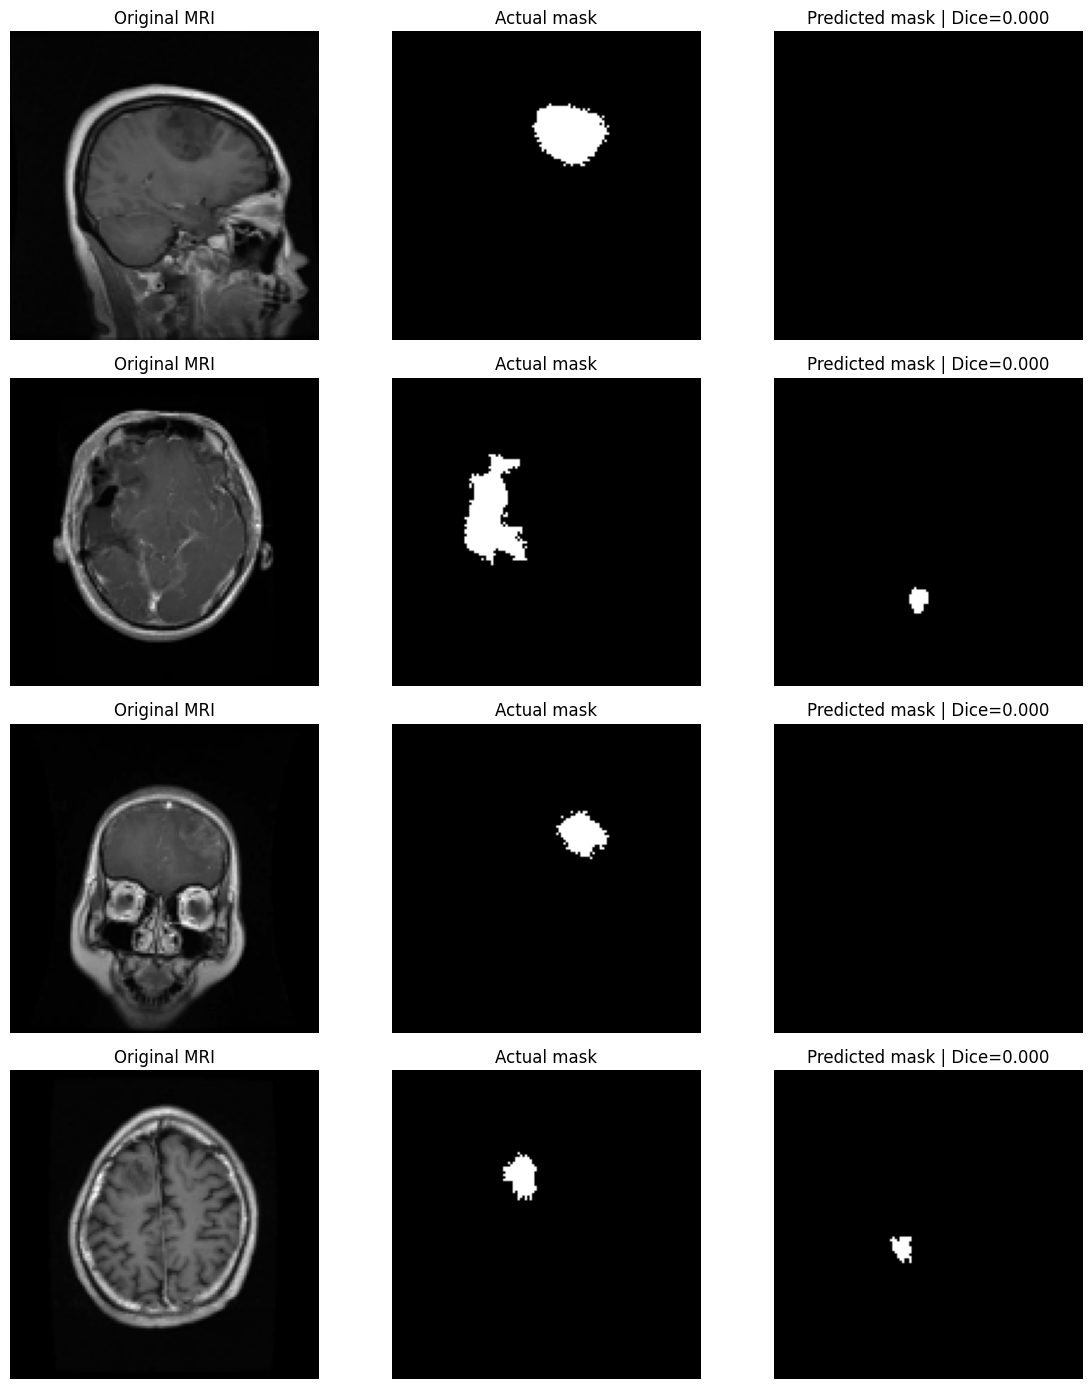

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

# Glioma images with the lowest Dice scores
bad_cases = (
    fresh_test_df[fresh_test_df["tumor_type"] == "Glioma"]
    .nsmallest(4, "dice")
)

fig, axes = plt.subplots(4, 3, figsize=(12, 14))

for row, (_, record) in enumerate(bad_cases.iterrows()):
    image_path = os.path.join(SEG_TEST_IMAGES, record["image"])
    mask_path = os.path.join(
        SEG_TEST_MASKS,
        os.path.splitext(record["image"])[0] + ".png"
    )

    img = Image.open(image_path).convert("L").resize((128, 128))
    x = np.array(img, dtype=np.float32) / 255.0

    mask = Image.open(mask_path).convert("L").resize(
        (128, 128), Image.Resampling.NEAREST
    )
    actual = np.array(mask) > 0

    prob = saved_unet.predict(
        x[np.newaxis, ..., np.newaxis], verbose=0
    )[0, :, :, 0]
    predicted = prob > 0.5

    axes[row, 0].imshow(x, cmap="gray")
    axes[row, 0].set_title("Original MRI")

    axes[row, 1].imshow(actual, cmap="gray")
    axes[row, 1].set_title("Actual mask")

    axes[row, 2].imshow(predicted, cmap="gray")
    axes[row, 2].set_title(
        f"Predicted mask | Dice={record['dice']:.3f}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import numpy as np
import pandas as pd
from PIL import Image

rows = []

for _, record in bad_cases.iterrows():
    image_path = os.path.join(SEG_TEST_IMAGES, record["image"])
    img = Image.open(image_path).convert("L").resize((128, 128))
    x = np.array(img, dtype=np.float32) / 255.0
    x = x[np.newaxis, ..., np.newaxis]

    mask_path = os.path.join(
        SEG_TEST_MASKS,
        os.path.splitext(record["image"])[0] + ".png"
    )
    mask = Image.open(mask_path).convert("L").resize(
        (128, 128), Image.Resampling.NEAREST
    )
    actual = np.array(mask) > 0

    prob = saved_unet.predict(x, verbose=0)[0, :, :, 0]

    for threshold in [0.2, 0.3, 0.4, 0.5]:
        predicted = prob > threshold
        intersection = np.logical_and(actual, predicted).sum()

        dice = (
            2 * intersection /
            (actual.sum() + predicted.sum() + 1e-7)
        )

        rows.append({
            "image": record["image"],
            "threshold": threshold,
            "actual_pixels": int(actual.sum()),
            "predicted_pixels": int(predicted.sum()),
            "max_probability": round(float(prob.max()), 4),
            "dice": round(float(dice), 4)
        })

threshold_df = pd.DataFrame(rows)
print(threshold_df.to_string(index=False))

                            image  threshold  actual_pixels  predicted_pixels  max_probability  dice
brisc2025_test_00244_gl_sa_t1.jpg        0.2            563                 0           0.0221   0.0
brisc2025_test_00244_gl_sa_t1.jpg        0.3            563                 0           0.0221   0.0
brisc2025_test_00244_gl_sa_t1.jpg        0.4            563                 0           0.0221   0.0
brisc2025_test_00244_gl_sa_t1.jpg        0.5            563                 0           0.0221   0.0
brisc2025_test_00051_gl_ax_t1.jpg        0.2            660                71           0.9968   0.0
brisc2025_test_00051_gl_ax_t1.jpg        0.3            660                68           0.9968   0.0
brisc2025_test_00051_gl_ax_t1.jpg        0.4            660                65           0.9968   0.0
brisc2025_test_00051_gl_ax_t1.jpg        0.5            660                63           0.9968   0.0
brisc2025_test_00136_gl_co_t1.jpg        0.2            248                 0           0.1

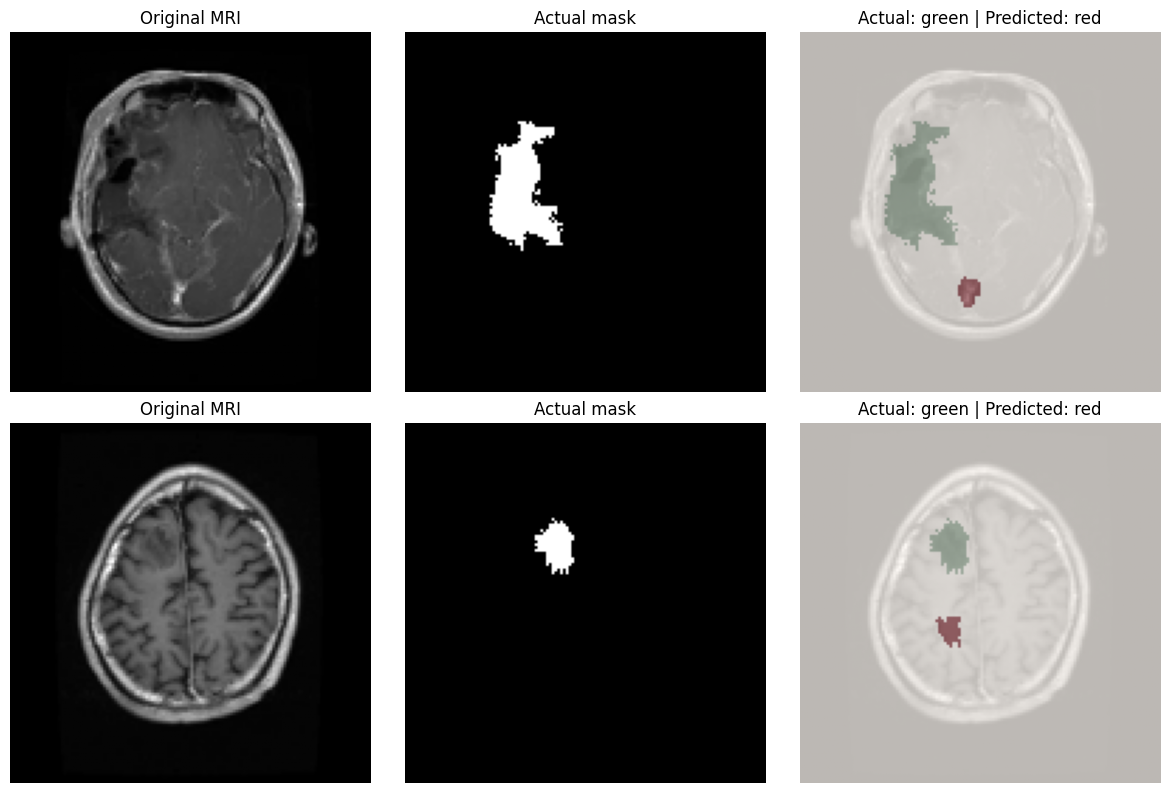

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

check_names = [
    "brisc2025_test_00051_gl_ax_t1.jpg",
    "brisc2025_test_00082_gl_ax_t1.jpg"
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, name in enumerate(check_names):
    image_path = os.path.join(SEG_TEST_IMAGES, name)
    mask_path = os.path.join(
        SEG_TEST_MASKS, os.path.splitext(name)[0] + ".png"
    )

    img = Image.open(image_path).convert("L").resize((128, 128))
    x = np.array(img, dtype=np.float32) / 255.0

    mask_img = Image.open(mask_path).convert("L").resize(
        (128, 128), Image.Resampling.NEAREST
    )
    actual = np.array(mask_img) > 0

    prob = saved_unet.predict(
        x[np.newaxis, ..., np.newaxis], verbose=0
    )[0, :, :, 0]
    predicted = prob > 0.5

    axes[i, 0].imshow(x, cmap="gray")
    axes[i, 0].set_title("Original MRI")

    axes[i, 1].imshow(actual, cmap="gray")
    axes[i, 1].set_title("Actual mask")

    axes[i, 2].imshow(x, cmap="gray")
    axes[i, 2].imshow(actual, cmap="Greens", alpha=0.5)
    axes[i, 2].imshow(predicted, cmap="Reds", alpha=0.5)
    axes[i, 2].set_title("Actual: green | Predicted: red")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import numpy as np
from PIL import Image

check_names = [
    "brisc2025_test_00051_gl_ax_t1.jpg",
    "brisc2025_test_00082_gl_ax_t1.jpg"
]

for name in check_names:
    image_path = os.path.join(SEG_TEST_IMAGES, name)
    mask_path = os.path.join(
        SEG_TEST_MASKS,
        os.path.splitext(name)[0] + ".png"
    )

    img = Image.open(image_path)
    mask = Image.open(mask_path)

    print("\nImage:", os.path.basename(image_path))
    print("Mask :", os.path.basename(mask_path))
    print("Original image size:", img.size)
    print("Original mask size :", mask.size)
    print("Image mode:", img.mode)
    print("Mask mode:", mask.mode)
    print("Mask pixel values:", np.unique(np.array(mask))[:20])


Image: brisc2025_test_00051_gl_ax_t1.jpg
Mask : brisc2025_test_00051_gl_ax_t1.png
Original image size: (512, 512)
Original mask size : (512, 512)
Image mode: L
Mask mode: L
Mask pixel values: [  0   1   2   3   4   5   6   7 248 249 250 251 252 253 254 255]

Image: brisc2025_test_00082_gl_ax_t1.jpg
Mask : brisc2025_test_00082_gl_ax_t1.png
Original image size: (512, 512)
Original mask size : (512, 512)
Image mode: L
Mask mode: L
Mask pixel values: [  0   1   2   3   4   5   6   7 249 250 251 252 253 254 255]


In [ ]:
import os
import numpy as np
from PIL import Image

check_names = [
    "brisc2025_test_00051_gl_ax_t1.jpg",
    "brisc2025_test_00082_gl_ax_t1.jpg"
]

for name in check_names:
    mask_path = os.path.join(
        SEG_TEST_MASKS,
        os.path.splitext(name)[0] + ".png"
    )

    mask = np.array(Image.open(mask_path).convert("L"))

    values, counts = np.unique(mask, return_counts=True)

    print("\nMask:", name)
    print("Pixel value counts:")

    for value, count in zip(values, counts):
        print(f"{value}: {count}")

    print("Pixels > 0:", int((mask > 0).sum()))
    print("Pixels > 127:", int((mask > 127).sum()))


Mask: brisc2025_test_00051_gl_ax_t1.jpg
Pixel value counts:
0: 251529
1: 455
2: 217
3: 124
4: 35
5: 16
6: 1
7: 4
248: 3
249: 2
250: 15
251: 52
252: 102
253: 212
254: 418
255: 8959
Pixels > 0: 10615
Pixels > 127: 9763

Mask: brisc2025_test_00082_gl_ax_t1.jpg
Pixel value counts:
0: 259547
1: 164
2: 100
3: 60
4: 20
5: 7
6: 2
7: 3
249: 4
250: 1
251: 9
252: 44
253: 53
254: 127
255: 2003
Pixels > 0: 2597
Pixels > 127: 2241


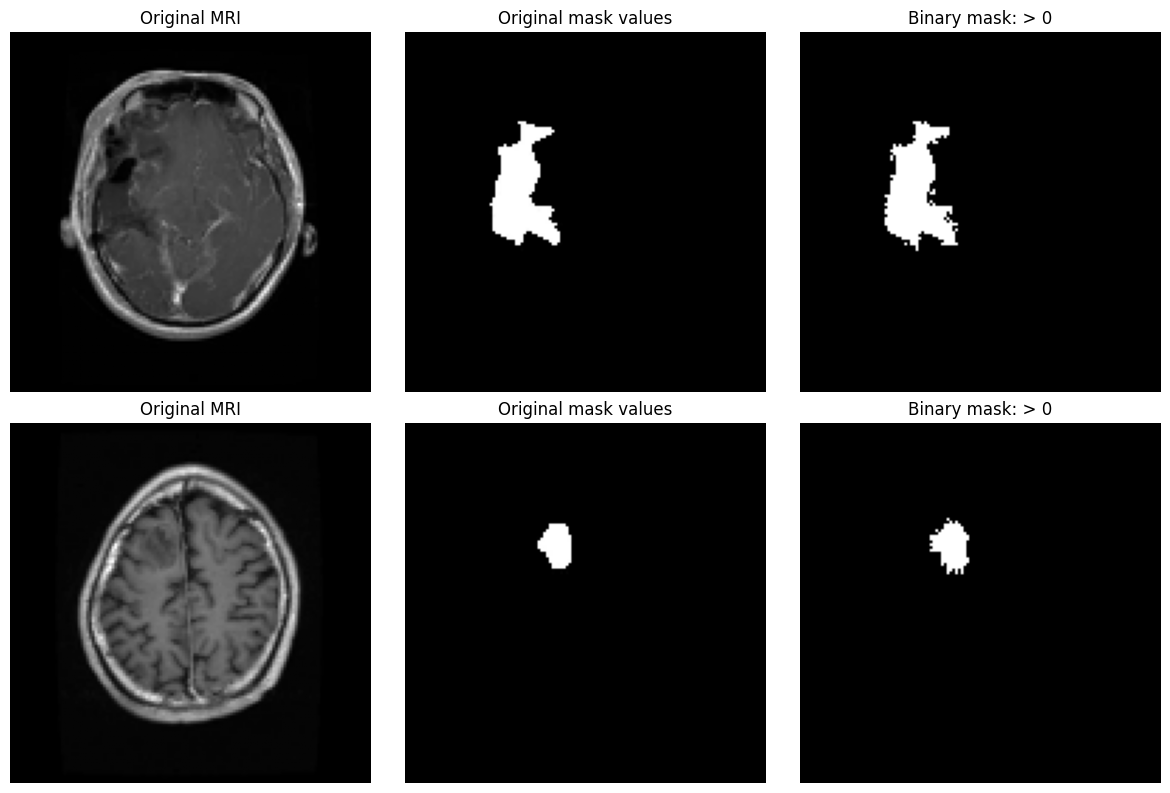

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

check_names = [
    "brisc2025_test_00051_gl_ax_t1.jpg",
    "brisc2025_test_00082_gl_ax_t1.jpg"
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, name in enumerate(check_names):
    image_path = os.path.join(SEG_TEST_IMAGES, name)
    mask_path = os.path.join(
        SEG_TEST_MASKS,
        os.path.splitext(name)[0] + ".png"
    )

    img = np.array(
        Image.open(image_path).convert("L").resize((128, 128))
    )
    mask = np.array(
        Image.open(mask_path).convert("L").resize(
            (128, 128), Image.Resampling.NEAREST
        )
    )

    axes[i, 0].imshow(img, cmap="gray")
    axes[i, 0].set_title("Original MRI")

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title("Original mask values")

    axes[i, 2].imshow(mask > 0, cmap="gray")
    axes[i, 2].set_title("Binary mask: > 0")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import numpy as np
from PIL import Image

names = [
    "brisc2025_test_00051_gl_ax_t1.jpg",
    "brisc2025_test_00082_gl_ax_t1.jpg"
]

for name in names:
    mask_path = os.path.join(
        SEG_TEST_MASKS,
        os.path.splitext(name)[0] + ".png"
    )

    mask = np.array(Image.open(mask_path).convert("L"))

    print("\nImage:", name)
    print("Background pixels (value 0):", np.sum(mask == 0))
    print("Low-value pixels (1–7):", np.sum((mask >= 1) & (mask <= 7)))
    print("High-value pixels (248–255):", np.sum((mask >= 248) & (mask <= 255)))
    print("Other pixels:", np.sum((mask > 7) & (mask < 248)))


Image: brisc2025_test_00051_gl_ax_t1.jpg
Background pixels (value 0): 251529
Low-value pixels (1–7): 852
High-value pixels (248–255): 9763
Other pixels: 0

Image: brisc2025_test_00082_gl_ax_t1.jpg
Background pixels (value 0): 259547
Low-value pixels (1–7): 356
High-value pixels (248–255): 2241
Other pixels: 0


In [ ]:
import os
import numpy as np
from PIL import Image

mask_path = os.path.join(
    SEG_TRAIN_MASKS,
    os.path.splitext(os.path.basename(train_images[0]))[0] + ".png"
)

mask = np.array(Image.open(mask_path).convert("L"))

values, counts = np.unique(mask, return_counts=True)

print("Training mask:", os.path.basename(mask_path))
print("Unique pixel values:", values)
print("Pixel counts:", counts)
print("Total pixels:", mask.size)

Training mask: brisc2025_train_01219_me_ax_t1.png
Unique pixel values: [  0   1   2   3   4   5   6   7 248 249 250 251 252 253 254 255]
Pixel counts: [249201    339    179    109     34     15      3      1      2      3
     22     50     97    210    337  11542]
Total pixels: 262144


In [ ]:
import os

root = "/content/brisc_data/brisc2025"

for current_path, folders, files in os.walk(root):
    for file in files:
        if any(word in file.lower() for word in [
            "readme", "metadata", "description", "label", "annotation"
        ]):
            print(os.path.join(current_path, file))

In [ ]:
import os
import numpy as np
from PIL import Image

mask_path = os.path.join(
    SEG_TRAIN_MASKS,
    "brisc2025_train_01219_me_ax_t1.png"
)

mask = np.array(Image.open(mask_path).convert("L"))

print("Mask shape:", mask.shape)
print("Black pixels (0):", np.sum(mask == 0))
print("White pixels (255):", np.sum(mask == 255))
print("Low values (1-7):", np.sum((mask >= 1) & (mask <= 7)))
print("High values (248-254):", np.sum((mask >= 248) & (mask <= 254)))
print("Binary mask using > 0:", np.sum(mask > 0))
print("Binary mask using > 127:", np.sum(mask > 127))

Mask shape: (512, 512)
Black pixels (0): 249201
White pixels (255): 11542
Low values (1-7): 680
High values (248-254): 721
Binary mask using > 0: 12943
Binary mask using > 127: 12263


In [ ]:
import os
import numpy as np
from PIL import Image

name = "brisc2025_train_01219_me_ax_t1.png"
mask_path = os.path.join(SEG_TRAIN_MASKS, name)

mask = np.array(Image.open(mask_path).convert("L"))

# Same resizing method used for model training
mask_128 = np.array(
    Image.fromarray(mask).resize(
        (128, 128), Image.Resampling.NEAREST
    )
)

print("Original mask size:", mask.shape)
print("Resized mask size:", mask_128.shape)
print("Tumor pixels if threshold > 0:", int((mask_128 > 0).sum()))
print("Tumor pixels if threshold > 127:", int((mask_128 > 127).sum()))
print("Tumor pixels if threshold > 200:", int((mask_128 > 200).sum()))

# Compare against the target already loaded in memory
if "Y_train" in globals():
    target = Y_train[0, :, :, 0]
    print("Current Y_train[0] tumor pixels:", int((target > 0.5).sum()))
else:
    print("Y_train is not available in memory.")

Original mask size: (512, 512)
Resized mask size: (128, 128)
Tumor pixels if threshold > 0: 812
Tumor pixels if threshold > 127: 769
Tumor pixels if threshold > 200: 769
Current Y_train[0] tumor pixels: 90


In [ ]:
idx = int(train_indices[0])

print("Index used for Y_train[0]:", idx)
print("train_pairs type:", type(train_pairs))

if isinstance(train_pairs, dict):
    print("Dictionary keys sample:", list(train_pairs.keys())[:5])
    print("Pair for this index:", train_pairs.get(idx, "Index not found"))
else:
    print("Pair for this index:", train_pairs[idx])

print("Y_train[0] tumor pixels:",
      int((Y_train[0, :, :, 0] > 0.5).sum()))

Index used for Y_train[0]: 2638
train_pairs type: <class 'dict'>
Dictionary keys sample: ['brisc2025_train_01219_me_ax_t1', 'brisc2025_train_04608_pi_sa_t1', 'brisc2025_train_04259_pi_co_t1', 'brisc2025_train_03719_pi_ax_t1', 'brisc2025_train_02037_me_sa_t1']
Pair for this index: Index not found
Y_train[0] tumor pixels: 90


In [ ]:
idx = int(train_indices[0])

print("Index:", idx)
print("train_images type:", type(train_images))
print("train_masks type:", type(train_masks))
print("train_image_names type:", type(train_image_names))

print("\nImage path:")
print(train_images[idx])

print("\nMask path:")
print(train_masks[idx])

print("\nFirst 10 image names:")
print(list(train_image_names)[:10])

print("\nY_train[0] tumor pixels:",
      int((Y_train[0, :, :, 0] > 0.5).sum()))

Index: 2638
train_images type: <class 'list'>
train_masks type: <class 'list'>
train_image_names type: <class 'set'>

Image path:
/content/brisc_data/brisc2025/segmentation_task/train/images/brisc2025_train_02441_me_sa_t1.jpg

Mask path:
/content/brisc_data/brisc2025/segmentation_task/train/masks/brisc2025_train_04814_pi_sa_t1.png

First 10 image names:
['brisc2025_train_00424_gl_co_t1', 'brisc2025_train_00464_gl_co_t1', 'brisc2025_train_02150_me_sa_t1', 'brisc2025_train_02303_me_sa_t1', 'brisc2025_train_00796_gl_co_t1', 'brisc2025_train_03879_pi_ax_t1', 'brisc2025_train_04135_pi_co_t1', 'brisc2025_train_00509_gl_co_t1', 'brisc2025_train_01140_gl_sa_t1', 'brisc2025_train_01803_me_co_t1']

Y_train[0] tumor pixels: 90


In [ ]:
import os

idx = int(train_indices[0])

img_path = train_images[idx]
mask_path = train_masks[idx]

img_name = os.path.splitext(os.path.basename(img_path))[0]
mask_name = os.path.splitext(os.path.basename(mask_path))[0]

print("Image name:", img_name)
print("Mask name:", mask_name)
print("Names match:", img_name == mask_name)

print("\nDictionary pair for image:")
print(train_pairs.get(img_name, "Image key not found"))

print("\nDictionary pair for mask:")
print(train_pairs.get(mask_name, "Mask key not found"))

print("\nTotal images:", len(train_images))
print("Total masks:", len(train_masks))
print("Total dictionary pairs:", len(train_pairs))

Image name: brisc2025_train_02441_me_sa_t1
Mask name: brisc2025_train_04814_pi_sa_t1
Names match: False

Dictionary pair for image:
('/content/brisc_data/brisc2025/segmentation_task/train/images/brisc2025_train_02441_me_sa_t1.jpg', '/content/brisc_data/brisc2025/segmentation_task/train/masks/brisc2025_train_02441_me_sa_t1.png')

Dictionary pair for mask:
('/content/brisc_data/brisc2025/segmentation_task/train/images/brisc2025_train_04814_pi_sa_t1.jpg', '/content/brisc_data/brisc2025/segmentation_task/train/masks/brisc2025_train_04814_pi_sa_t1.png')

Total images: 3933
Total masks: 3933
Total dictionary pairs: 3933


In [ ]:
import os

train_image_paths = []
train_mask_paths = []

for image_name, pair in train_pairs.items():
    image_path, mask_path = pair

    if os.path.exists(image_path) and os.path.exists(mask_path):
        train_image_paths.append(image_path)
        train_mask_paths.append(mask_path)

print("Correctly matched pairs:", len(train_image_paths))
print("\nFirst matched pair:")
print(os.path.basename(train_image_paths[0]))
print(os.path.basename(train_mask_paths[0]))

print("\nAll pairs match:",
      all(
          os.path.splitext(os.path.basename(i))[0]
          == os.path.splitext(os.path.basename(m))[0]
          for i, m in zip(train_image_paths, train_mask_paths)
      ))

Correctly matched pairs: 3933

First matched pair:
brisc2025_train_01219_me_ax_t1.jpg
brisc2025_train_01219_me_ax_t1.png

All pairs match: True


In [ ]:
import numpy as np
from PIL import Image

idx = int(train_indices[0])
image_path = train_image_paths[idx]
mask_path = train_mask_paths[idx]

# Original mask ko training size par resize karo
mask = Image.open(mask_path).convert("L")
mask = mask.resize((128, 128), Image.Resampling.NEAREST)
mask_array = np.array(mask)

print("Image:", image_path.split("/")[-1])
print("Correct mask:", mask_path.split("/")[-1])
print("Original mask pixels > 0:", int((mask_array > 0).sum()))
print("Original mask pixels > 127:", int((mask_array > 127).sum()))
print("Y_train[0] tumor pixels:",
      int((Y_train[0, :, :, 0] > 0.5).sum()))

Image: brisc2025_train_02441_me_sa_t1.jpg
Correct mask: brisc2025_train_02441_me_sa_t1.png
Original mask pixels > 0: 630
Original mask pixels > 127: 581
Y_train[0] tumor pixels: 90


In [ ]:
import numpy as np
from PIL import Image

idx = int(train_indices[0])

# Correct mask ko resize karke different thresholds check karo
mask = Image.open(train_mask_paths[idx]).convert("L")
mask = np.array(mask.resize((128, 128), Image.Resampling.NEAREST))

y_existing = Y_train[0, :, :, 0]

print("Existing Y_train[0] unique values:",
      np.unique(y_existing)[:10])

print("Pixels in original mask:")
for threshold in [0, 7, 127, 200, 247]:
    print(f"Mask > {threshold}:",
          int((mask > threshold).sum()))

print("\nExisting Y_train[0] pixels > 0.5:",
      int((y_existing > 0.5).sum()))

print("Exact match with mask > 0:",
      np.array_equal(y_existing > 0.5, mask > 0))

print("Exact match with mask > 127:",
      np.array_equal(y_existing > 0.5, mask > 127))

Existing Y_train[0] unique values: [0. 1.]
Pixels in original mask:
Mask > 0: 630
Mask > 7: 581
Mask > 127: 581
Mask > 200: 581
Mask > 247: 581

Existing Y_train[0] pixels > 0.5: 90
Exact match with mask > 0: False
Exact match with mask > 127: False


In [ ]:
import numpy as np

# Y_train[0] ko original training masks se compare karo
y0 = Y_train[0, :, :, 0] > 0.5

matches = []

for i, mask_path in enumerate(train_mask_paths):
    from PIL import Image

    mask = Image.open(mask_path).convert("L")
    mask = np.array(
        mask.resize((128, 128), Image.Resampling.NEAREST)
    )

    candidate = mask > 127

    if np.array_equal(y0, candidate):
        matches.append((i, mask_path))

print("Exact matching masks found:", len(matches))

for i, path in matches[:10]:
    print("Index:", i, "| Mask:", path.split("/")[-1])

Exact matching masks found: 1
Index: 1094 | Mask: brisc2025_train_03706_pi_ax_t1.png


In [ ]:
import numpy as np
from PIL import Image

idx = int(train_indices[0])

# Expected image for Y_train[0]
expected_image = Image.open(train_image_paths[idx]).convert("L")
expected_image = np.array(
    expected_image.resize((128, 128), Image.Resampling.BILINEAR)
) / 255.0

# Compare with X_train[0]
x0 = X_train[0, :, :, 0]

print("Expected image:", train_image_paths[idx].split("/")[-1])
print("X_train[0] shape:", x0.shape)
print("Expected image shape:", expected_image.shape)
print("X_train[0] min/max:", x0.min(), x0.max())
print("Expected image min/max:", expected_image.min(), expected_image.max())
print("Mean absolute difference:",
      float(np.mean(np.abs(x0 - expected_image))))

Expected image: brisc2025_train_02441_me_sa_t1.jpg
X_train[0] shape: (128, 128)
Expected image shape: (128, 128)
X_train[0] min/max: 0.0 0.65882355
Expected image min/max: 0.0 0.8745098039215686
Mean absolute difference: 0.09908686628752757


In [ ]:
import os
import numpy as np
from PIL import Image

# Dictionary se exact matched pair lo
sample_name = "brisc2025_train_02441_me_sa_t1"
img_path, mask_path = train_pairs[sample_name]

# Image preprocess
img = Image.open(img_path).convert("L")
img = np.array(img.resize((128, 128))) / 255.0

# Mask preprocess
mask = Image.open(mask_path).convert("L")
mask = np.array(
    mask.resize((128, 128), Image.Resampling.NEAREST)
)
mask_binary = (mask > 127).astype(np.float32)

print("Matched sample:", sample_name)
print("Image shape:", img.shape)
print("Mask shape:", mask_binary.shape)
print("Image range:", img.min(), img.max())
print("Tumor pixels:", int(mask_binary.sum()))

# Existing arrays se comparison
print("\nExisting X_train[0] difference:",
      float(np.mean(np.abs(X_train[0, :, :, 0] - img))))

print("Existing Y_train[0] exact match:",
      np.array_equal(Y_train[0, :, :, 0], mask_binary))

Matched sample: brisc2025_train_02441_me_sa_t1
Image shape: (128, 128)
Mask shape: (128, 128)
Image range: 0.0 0.9647058823529412
Tumor pixels: 581

Existing X_train[0] difference: 0.10085927935381434
Existing Y_train[0] exact match: False


In [ ]:
import numpy as np
from PIL import Image

x0 = X_train[0, :, :, 0]

# First 20 correctly matched images ke saath compare karo
for i in range(20):
    name = list(train_pairs.keys())[i]
    img_path, mask_path = train_pairs[name]

    img = Image.open(img_path).convert("L")
    img = np.array(img.resize((128, 128))) / 255.0

    diff = np.mean(np.abs(x0 - img))
    print(name, "Difference:", round(float(diff), 5))

brisc2025_train_01219_me_ax_t1 Difference: 0.10453
brisc2025_train_04608_pi_sa_t1 Difference: 0.17002
brisc2025_train_04259_pi_co_t1 Difference: 0.10357
brisc2025_train_03719_pi_ax_t1 Difference: 0.09593
brisc2025_train_02037_me_sa_t1 Difference: 0.102
brisc2025_train_01211_me_ax_t1 Difference: 0.11902
brisc2025_train_01142_gl_sa_t1 Difference: 0.08932
brisc2025_train_02016_me_sa_t1 Difference: 0.23387
brisc2025_train_04636_pi_sa_t1 Difference: 0.14356
brisc2025_train_00432_gl_co_t1 Difference: 0.09316
brisc2025_train_02397_me_sa_t1 Difference: 0.1085
brisc2025_train_04130_pi_co_t1 Difference: 0.09696
brisc2025_train_04712_pi_sa_t1 Difference: 0.13837
brisc2025_train_04832_pi_sa_t1 Difference: 0.14398
brisc2025_train_01326_me_ax_t1 Difference: 0.07231
brisc2025_train_04625_pi_sa_t1 Difference: 0.13411
brisc2025_train_02379_me_sa_t1 Difference: 0.13868
brisc2025_train_01693_me_co_t1 Difference: 0.10837
brisc2025_train_02380_me_sa_t1 Difference: 0.1187
brisc2025_train_03998_pi_co_t1 Diff

In [ ]:
import numpy as np
from PIL import Image

x0 = X_train[0, :, :, 0]
results = []

for name, (img_path, mask_path) in train_pairs.items():
    img = Image.open(img_path).convert("L")
    img = np.array(img.resize((128, 128))) / 255.0

    diff = np.mean(np.abs(x0 - img))
    results.append((diff, name, img_path, mask_path))

results.sort(key=lambda x: x[0])

print("Top 5 closest images to X_train[0]:")
for diff, name, img_path, mask_path in results[:5]:
    print(name, "| Difference:", round(float(diff), 6))

Top 5 closest images to X_train[0]:
brisc2025_train_03706_pi_ax_t1 | Difference: 0.0
brisc2025_train_03705_pi_ax_t1 | Difference: 0.037908
brisc2025_train_03707_pi_ax_t1 | Difference: 0.046695
brisc2025_train_03963_pi_ax_t1 | Difference: 0.04899
brisc2025_train_03861_pi_ax_t1 | Difference: 0.051162


In [ ]:
import numpy as np
from PIL import Image

idx = int(val_indices[0])

# Original image and mask paths from the same index
img_path = train_images[idx]
mask_path = train_masks[idx]

print("Image:", img_path.split("/")[-1])
print("Mask:", mask_path.split("/")[-1])
print("Filenames match:",
      img_path.split("/")[-1].replace(".jpg", "")
      == mask_path.split("/")[-1].replace(".png", ""))

print("X_val[0] tumor pixels:", int((X_val[0, :, :, 0] > 0).sum()))
print("Y_val[0] tumor pixels:", int((Y_val[0, :, :, 0] > 0.5).sum()))

Image: brisc2025_train_04734_pi_sa_t1.jpg
Mask: brisc2025_train_01753_me_co_t1.png
Filenames match: False
X_val[0] tumor pixels: 13654
Y_val[0] tumor pixels: 383


In [ ]:
import numpy as np
from PIL import Image

x0 = X_val[0, :, :, 0]
y0 = Y_val[0, :, :, 0] > 0.5

# X_val[0] ka exact image match
image_matches = []

for name, (img_path, mask_path) in train_pairs.items():
    img = Image.open(img_path).convert("L")
    img = np.array(img.resize((128, 128))) / 255.0

    if np.allclose(x0, img, atol=1e-6):
        image_matches.append((name, mask_path))

print("Matching images:", len(image_matches))

for name, mask_path in image_matches[:5]:
    print("\nImage name:", name)
    print("Correct mask:", mask_path.split("/")[-1])

    mask = Image.open(mask_path).convert("L")
    mask = np.array(
        mask.resize((128, 128), Image.Resampling.NEAREST)
    ) > 127

    print("Mask pixels:", int(mask.sum()))
    print("Y_val[0] exact match:", np.array_equal(y0, mask))

Matching images: 1

Image name: brisc2025_train_01836_me_co_t1
Correct mask: brisc2025_train_01836_me_co_t1.png
Mask pixels: 383
Y_val[0] exact match: True


In [ ]:
import os

test_pair_matches = []

for img_path in test_images:
    name = os.path.splitext(os.path.basename(img_path))[0]
    mask_path = os.path.join(SEG_TEST_MASKS, name + ".png")
    test_pair_matches.append(
        os.path.exists(mask_path)
        and os.path.splitext(os.path.basename(mask_path))[0] == name
    )

print("Total test images:", len(test_images))
print("Correctly matched masks:", sum(test_pair_matches))
print("Missing or mismatched masks:",
      len(test_pair_matches) - sum(test_pair_matches))

Total test images: 860
Correctly matched masks: 860
Missing or mismatched masks: 0


In [ ]:
import os
import numpy as np
from PIL import Image

glioma_path = os.path.join(
    SEG_TEST_MASKS,
    "brisc2025_test_00244_gl_sa_t1.png"
)

mask = Image.open(glioma_path).convert("L")
mask_array = np.array(mask)

values, counts = np.unique(mask_array, return_counts=True)

print("Mask shape:", mask_array.shape)
print("Unique pixel values and counts:")
for value, count in zip(values, counts):
    print(value, ":", count)

print("\nPixels > 0:", int((mask_array > 0).sum()))
print("Pixels > 127:", int((mask_array > 127).sum()))
print("Pixels > 200:", int((mask_array > 200).sum()))

Mask shape: (512, 512)
Unique pixel values and counts:
0 : 253185
1 : 321
2 : 189
3 : 98
4 : 28
5 : 17
6 : 3
7 : 2
248 : 3
249 : 3
250 : 12
251 : 25
252 : 76
253 : 132
254 : 219
255 : 7831

Pixels > 0: 8959
Pixels > 127: 8301
Pixels > 200: 8301


In [ ]:
import os
import numpy as np
from PIL import Image

sample_name = "brisc2025_test_00244_gl_sa_t1"

img_path = os.path.join(SEG_TEST_IMAGES, sample_name + ".jpg")
mask_path = os.path.join(SEG_TEST_MASKS, sample_name + ".png")

# Image preprocessing
img = Image.open(img_path).convert("L")
img = np.array(img.resize((128, 128))) / 255.0
x = img[np.newaxis, ..., np.newaxis]

# Model prediction
prob = saved_unet.predict(x, verbose=0)[0, :, :, 0]
pred = prob > 0.5

# Original mask, resized with nearest-neighbor
mask = Image.open(mask_path).convert("L")
mask = np.array(mask.resize((128, 128), Image.Resampling.NEAREST))

for threshold in [0, 127, 200]:
    actual = mask > threshold
    intersection = np.logical_and(actual, pred).sum()
    denominator = actual.sum() + pred.sum()
    dice = (2 * intersection / denominator) if denominator else 1.0

    print(
        f"Mask threshold > {threshold}: "
        f"actual={actual.sum()}, predicted={pred.sum()}, "
        f"intersection={intersection}, Dice={dice:.4f}"
    )

print("\nMaximum prediction probability:", float(prob.max()))

Mask threshold > 0: actual=563, predicted=0, intersection=0, Dice=0.0000
Mask threshold > 127: actual=522, predicted=0, intersection=0, Dice=0.0000
Mask threshold > 200: actual=522, predicted=0, intersection=0, Dice=0.0000

Maximum prediction probability: 0.022123171016573906


In [ ]:
import numpy as np
import os
from PIL import Image

glioma_samples = [
    "brisc2025_test_00244_gl_sa_t1",
    "brisc2025_test_00136_gl_co_t1",
    "brisc2025_test_00051_gl_ax_t1",
    "brisc2025_test_00082_gl_ax_t1"
]

for name in glioma_samples:
    img_path = os.path.join(SEG_TEST_IMAGES, name + ".jpg")

    img = Image.open(img_path).convert("L")
    img = np.array(img.resize((128, 128))) / 255.0
    x = img[np.newaxis, ..., np.newaxis]

    prob = saved_unet.predict(x, verbose=0)[0, :, :, 0]

    print(
        name,
        "| Max probability:", round(float(prob.max()), 4),
        "| Mean probability:", round(float(prob.mean()), 6),
        "| Pixels > 0.5:", int((prob > 0.5).sum())
    )

brisc2025_test_00244_gl_sa_t1 | Max probability: 0.0221 | Mean probability: 0.000422 | Pixels > 0.5: 0
brisc2025_test_00136_gl_co_t1 | Max probability: 0.1154 | Mean probability: 0.000446 | Pixels > 0.5: 0
brisc2025_test_00051_gl_ax_t1 | Max probability: 0.9968 | Mean probability: 0.004605 | Pixels > 0.5: 63
brisc2025_test_00082_gl_ax_t1 | Max probability: 0.9633 | Mean probability: 0.004753 | Pixels > 0.5: 67


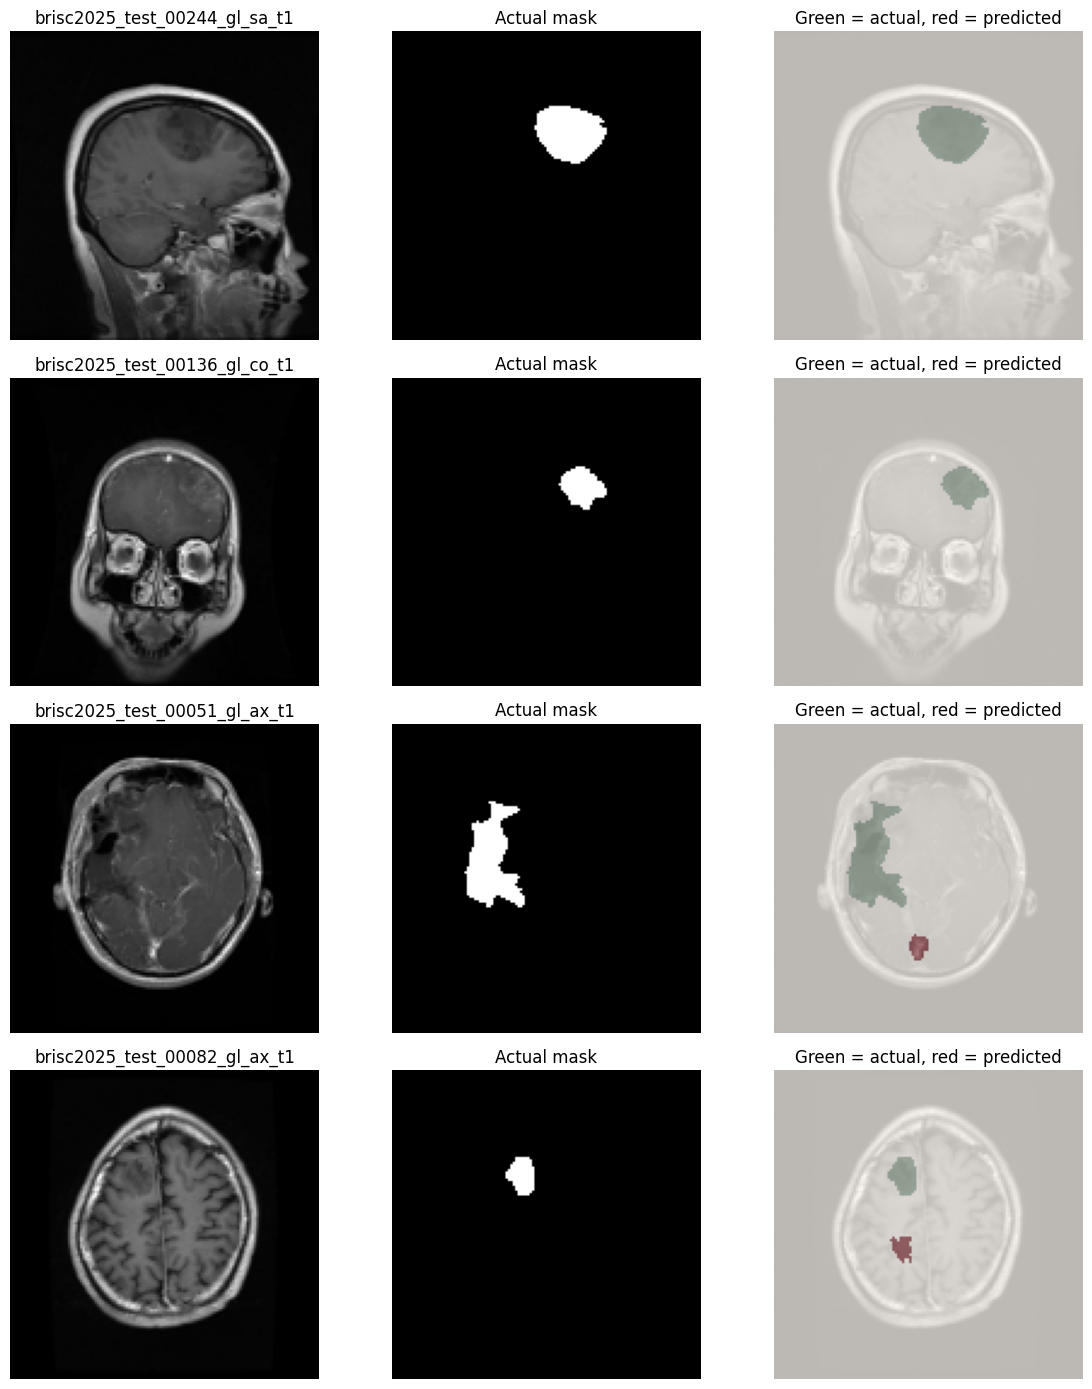

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

samples = [
    "brisc2025_test_00244_gl_sa_t1",
    "brisc2025_test_00136_gl_co_t1",
    "brisc2025_test_00051_gl_ax_t1",
    "brisc2025_test_00082_gl_ax_t1"
]

fig, axes = plt.subplots(len(samples), 3, figsize=(12, 14))

for i, name in enumerate(samples):
    img_path = os.path.join(SEG_TEST_IMAGES, name + ".jpg")
    mask_path = os.path.join(SEG_TEST_MASKS, name + ".png")

    img = Image.open(img_path).convert("L")
    img = np.array(img.resize((128, 128))) / 255.0

    mask = Image.open(mask_path).convert("L")
    mask = np.array(
        mask.resize((128, 128), Image.Resampling.NEAREST)
    ) > 127

    prob = saved_unet.predict(
        img[np.newaxis, ..., np.newaxis], verbose=0
    )[0, :, :, 0]
    pred = prob > 0.5

    axes[i, 0].imshow(img, cmap="gray")
    axes[i, 0].set_title(name)

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title("Actual mask")

    axes[i, 2].imshow(img, cmap="gray")
    axes[i, 2].imshow(mask, cmap="Greens", alpha=0.5)
    axes[i, 2].imshow(pred, cmap="Reds", alpha=0.5)
    axes[i, 2].set_title("Green = actual, red = predicted")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import numpy as np
from PIL import Image

samples = [
    "brisc2025_test_00244_gl_sa_t1",
    "brisc2025_test_00136_gl_co_t1",
    "brisc2025_test_00051_gl_ax_t1",
    "brisc2025_test_00082_gl_ax_t1"
]

for name in samples:
    img_path = os.path.join(SEG_TEST_IMAGES, name + ".jpg")
    mask_path = os.path.join(SEG_TEST_MASKS, name + ".png")

    img = Image.open(img_path).convert("L")
    img = np.array(img.resize((128, 128))) / 255.0

    mask = Image.open(mask_path).convert("L")
    mask = np.array(
        mask.resize((128, 128), Image.Resampling.NEAREST)
    ) > 127

    prob = saved_unet.predict(
        img[np.newaxis, ..., np.newaxis], verbose=0
    )[0, :, :, 0]
    pred = prob > 0.5

    intersection = np.logical_and(mask, pred).sum()
    union = np.logical_or(mask, pred).sum()
    dice = (
        2 * intersection / (mask.sum() + pred.sum())
        if mask.sum() + pred.sum() else 1.0
    )

    print(
        f"{name}: actual={mask.sum()}, "
        f"predicted={pred.sum()}, intersection={intersection}, "
        f"union={union}, Dice={dice:.4f}"
    )

brisc2025_test_00244_gl_sa_t1: actual=522, predicted=0, intersection=0, union=522, Dice=0.0000
brisc2025_test_00136_gl_co_t1: actual=224, predicted=0, intersection=0, union=224, Dice=0.0000
brisc2025_test_00051_gl_ax_t1: actual=611, predicted=63, intersection=0, union=674, Dice=0.0000
brisc2025_test_00082_gl_ax_t1: actual=143, predicted=67, intersection=0, union=210, Dice=0.0000


In [ ]:
import os
import numpy as np
from PIL import Image

samples = [
    "brisc2025_test_00051_gl_ax_t1",
    "brisc2025_test_00082_gl_ax_t1"
]

for name in samples:
    img_path = os.path.join(SEG_TEST_IMAGES, name + ".jpg")
    mask_path = os.path.join(SEG_TEST_MASKS, name + ".png")

    img = np.array(Image.open(img_path).convert("L"))
    mask = np.array(Image.open(mask_path).convert("L"))

    print("\n", name)
    print("Original image shape:", img.shape)
    print("Original mask shape:", mask.shape)

    for threshold in [127, 200]:
        actual = mask > threshold
        ys, xs = np.where(actual)

        if len(xs):
            print(
                f"Mask > {threshold}: "
                f"bounding box x=({xs.min()}, {xs.max()}), "
                f"y=({ys.min()}, {ys.max()})"
            )

    print("Image min/max:", img.min(), img.max())


 brisc2025_test_00051_gl_ax_t1
Original image shape: (512, 512)
Original mask shape: (512, 512)
Mask > 127: bounding box x=(122, 218), y=(128, 304)
Mask > 200: bounding box x=(122, 218), y=(128, 304)
Image min/max: 0 255

 brisc2025_test_00082_gl_ax_t1
Original image shape: (512, 512)
Original mask shape: (512, 512)
Mask > 127: bounding box x=(190, 235), y=(143, 208)
Mask > 200: bounding box x=(190, 235), y=(143, 208)
Image min/max: 0 255


In [ ]:
import os
import numpy as np
from PIL import Image

samples = [
    "brisc2025_test_00051_gl_ax_t1",
    "brisc2025_test_00082_gl_ax_t1"
]

for name in samples:
    img_path = os.path.join(SEG_TEST_IMAGES, name + ".jpg")
    mask_path = os.path.join(SEG_TEST_MASKS, name + ".png")

    # Image and mask at 128x128
    img = np.array(
        Image.open(img_path).convert("L").resize((128, 128))
    ) / 255.0

    mask = np.array(
        Image.open(mask_path).convert("L").resize(
            (128, 128), Image.Resampling.NEAREST
        )
    ) > 127

    prob = saved_unet.predict(
        img[np.newaxis, ..., np.newaxis], verbose=0
    )[0, :, :, 0]

    print("\n", name)
    print("Actual mask bounding box:",
          (np.where(mask)[1].min(), np.where(mask)[1].max(),
           np.where(mask)[0].min(), np.where(mask)[0].max()))
    print("Predicted probability > 0.5:", int((prob > 0.5).sum()))
    print("Predicted probability > 0.1:", int((prob > 0.1).sum()))
    print("Predicted probability > 0.01:", int((prob > 0.01).sum()))

    # Maximum-probability pixel location
    y, x = np.unravel_index(np.argmax(prob), prob.shape)
    print("Maximum probability:", round(float(prob[y, x]), 4))
    print("Maximum probability location (x, y):", (x, y))


 brisc2025_test_00051_gl_ax_t1
Actual mask bounding box: (np.int64(30), np.int64(54), np.int64(32), np.int64(75))
Predicted probability > 0.5: 63
Predicted probability > 0.1: 73
Predicted probability > 0.01: 175
Maximum probability: 0.9968
Maximum probability location (x, y): (np.int64(58), np.int64(95))

 brisc2025_test_00082_gl_ax_t1
Actual mask bounding box: (np.int64(47), np.int64(58), np.int64(36), np.int64(51))
Predicted probability > 0.5: 67
Predicted probability > 0.1: 110
Predicted probability > 0.01: 255
Maximum probability: 0.9633
Maximum probability location (x, y): (np.int64(53), np.int64(74))


In [ ]:
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)

print("\nTraining input range:")
print("Min:", float(X_train.min()))
print("Max:", float(X_train.max()))

print("\nValidation input range:")
print("Min:", float(X_val.min()))
print("Max:", float(X_val.max()))

print("\nModel input shape:", saved_unet.input_shape)
print("Model output shape:", saved_unet.output_shape)

X_train shape: (3146, 128, 128, 1)
X_val shape: (787, 128, 128, 1)

Training input range:
Min: 0.0
Max: 1.0

Validation input range:
Min: 0.0
Max: 1.0

Model input shape: (None, 128, 128, 1)
Model output shape: (None, 128, 128, 1)


In [ ]:
print("History type:", type(history))

print("\nTraining history keys:")
print(list(history.keys()))

print("\nHistory values:")
for key, value in history.items():
    print(key, ":", value)

History type: <class 'dict'>

Training history keys:
['accuracy', 'loss', 'val_accuracy', 'val_loss']

History values:
accuracy : [0.43024998903274536, 0.5882499814033508, 0.6679999828338623, 0.6840000152587891, 0.6982499957084656, 0.7095000147819519, 0.7252500057220459, 0.7404999732971191, 0.7494999766349792, 0.7512500286102295, 0.7572500109672546, 0.765500009059906, 0.7645000219345093]
loss : [1.2627196311950684, 1.0022422075271606, 0.8356956839561462, 0.7727516889572144, 0.7381876111030579, 0.7099562287330627, 0.6757060885429382, 0.6401244401931763, 0.6166166067123413, 0.6157197952270508, 0.59319007396698, 0.5691670179367065, 0.5588055849075317]
val_accuracy : [0.5419999957084656, 0.671999990940094, 0.7080000042915344, 0.7770000100135803, 0.7480000257492065, 0.7409999966621399, 0.8040000200271606, 0.7889999747276306, 0.7570000290870667, 0.8090000152587891, 0.6449999809265137, 0.7480000257492065, 0.7580000162124634]
val_loss : [1.116662621498108, 0.7642857432365417, 0.704582691192627

In [ ]:
print("Saved U-Net layers:", len(saved_unet.layers))
print("Current U-Net layers:", len(unet_model.layers))

print("\nSaved U-Net output:", saved_unet.output_shape)
print("Current U-Net output:", unet_model.output_shape)

print("\nSaved U-Net final layers:")
for layer in saved_unet.layers[-5:]:
    print(layer.name, layer.output.shape)

print("\nCurrent U-Net final layers:")
for layer in unet_model.layers[-5:]:
    print(layer.name, layer.output.shape)

Saved U-Net layers: 32
Current U-Net layers: 32

Saved U-Net output: (None, 128, 128, 1)
Current U-Net output: (None, 128, 128, 1)

Saved U-Net final layers:
conv2d_transpose_3 (None, 128, 128, 32)
concatenate_3 (None, 128, 128, 64)
conv2d_22 (None, 128, 128, 32)
conv2d_23 (None, 128, 128, 32)
conv2d_24 (None, 128, 128, 1)

Current U-Net final layers:
conv2d_transpose_3 (None, 128, 128, 32)
concatenate_3 (None, 128, 128, 64)
conv2d_22 (None, 128, 128, 32)
conv2d_23 (None, 128, 128, 32)
conv2d_24 (None, 128, 128, 1)


In [ ]:
import numpy as np

# Compare model weights
saved_weights = saved_unet.get_weights()
current_weights = unet_model.get_weights()

print("Number of weight arrays:", len(saved_weights), len(current_weights))

weight_diffs = [
    np.mean(np.abs(a - b))
    for a, b in zip(saved_weights, current_weights)
]

print("Mean absolute weight difference:",
      np.mean(weight_diffs))
print("Maximum weight difference:",
      np.max(weight_diffs))

# Compare predictions on the same validation image
sample = X_val[:1]

pred_saved = saved_unet.predict(sample, verbose=0)
pred_current = unet_model.predict(sample, verbose=0)

print("\nSaved model prediction range:",
      pred_saved.min(), pred_saved.max())
print("Current model prediction range:",
      pred_current.min(), pred_current.max())

print("Mean prediction difference:",
      np.mean(np.abs(pred_saved - pred_current)))

Number of weight arrays: 46 46
Mean absolute weight difference: 4.5277622e-05
Maximum weight difference: 9.999052e-05

Saved model prediction range: 0.0 0.9999923
Current model prediction range: 0.0 0.99999064
Mean prediction difference: 0.00014679853


In [ ]:
import numpy as np

print("Training masks:")
print("Mean tumor pixels:", np.mean(np.sum(Y_train > 0.5, axis=(1, 2, 3))))
print("Empty masks:", np.sum(np.sum(Y_train > 0.5, axis=(1, 2, 3)) == 0))
print("Total masks:", len(Y_train))

print("\nValidation masks:")
print("Mean tumor pixels:", np.mean(np.sum(Y_val > 0.5, axis=(1, 2, 3))))
print("Empty masks:", np.sum(np.sum(Y_val > 0.5, axis=(1, 2, 3)) == 0))
print("Total masks:", len(Y_val))

Training masks:
Mean tumor pixels: 269.2002542911634
Empty masks: 0
Total masks: 3146

Validation masks:
Mean tumor pixels: 272.6518424396442
Empty masks: 0
Total masks: 787


In [ ]:
from collections import Counter
import os

train_types = [
    os.path.basename(train_image_paths[i]).split("_")[2]
    for i in train_indices
]

val_types = [
    os.path.basename(train_image_paths[i]).split("_")[2]
    for i in val_indices
]

print("Training type distribution:", Counter(train_types))
print("Validation type distribution:", Counter(val_types))

Training type distribution: Counter({'02441': 1, '04814': 1, '04300': 1, '00486': 1, '00425': 1, '01474': 1, '00540': 1, '01264': 1, '01219': 1, '00073': 1, '00273': 1, '00168': 1, '04828': 1, '04556': 1, '01197': 1, '01163': 1, '04745': 1, '04905': 1, '04458': 1, '04727': 1, '04765': 1, '00450': 1, '01106': 1, '03811': 1, '04467': 1, '04418': 1, '02126': 1, '00906': 1, '03757': 1, '00889': 1, '01064': 1, '02279': 1, '01941': 1, '02205': 1, '01289': 1, '00173': 1, '01529': 1, '01149': 1, '01477': 1, '00239': 1, '01624': 1, '01846': 1, '00644': 1, '03923': 1, '04880': 1, '01405': 1, '00710': 1, '04684': 1, '04653': 1, '04005': 1, '01414': 1, '04177': 1, '00589': 1, '04972': 1, '00109': 1, '01842': 1, '02327': 1, '04153': 1, '00743': 1, '03958': 1, '01861': 1, '00737': 1, '04060': 1, '01278': 1, '03750': 1, '04014': 1, '02306': 1, '02197': 1, '02066': 1, '04127': 1, '00765': 1, '00615': 1, '02096': 1, '04071': 1, '00992': 1, '03745': 1, '01202': 1, '01789': 1, '00093': 1, '03747': 1, '01

In [ ]:
from collections import Counter
import os

train_types = [
    os.path.basename(train_image_paths[i]).split("_")[3]
    for i in train_indices
]

val_types = [
    os.path.basename(train_image_paths[i]).split("_")[3]
    for i in val_indices
]

print("Training type distribution:", Counter(train_types))
print("Validation type distribution:", Counter(val_types))

Training type distribution: Counter({'pi': 1184, 'me': 1065, 'gl': 897})
Validation type distribution: Counter({'pi': 273, 'me': 264, 'gl': 250})


In [ ]:
print(
    fresh_test_df.groupby("tumor_type")["dice"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(4)
)

            count    mean  median  min     max
tumor_type                                    
Glioma        254  0.3885  0.3902  0.0  0.9378
Meningioma    306  0.8174  0.8882  0.0  0.9746
Pituitary     300  0.6996  0.7789  0.0  0.9606


In [ ]:
print("X_train:", X_train.shape, X_train.min(), X_train.max())
print("X_val:  ", X_val.shape, X_val.min(), X_val.max())

print("\nY_train:", Y_train.shape, Y_train.min(), Y_train.max())
print("Y_val:  ", Y_val.shape, Y_val.min(), Y_val.max())

print("\nTest image array variables:")
for name in ["X_test", "Y_test"]:
    if name in globals():
        arr = globals()[name]
        print(name, arr.shape, arr.min(), arr.max())
    else:
        print(name, "not found")

X_train: (3146, 128, 128, 1) 0.0 1.0
X_val:   (787, 128, 128, 1) 0.0 1.0

Y_train: (3146, 128, 128, 1) 0.0 1.0
Y_val:   (787, 128, 128, 1) 0.0 1.0

Test image array variables:
X_test not found
Y_test not found


In [ ]:
import numpy as np

# Same training samples par prediction check
n = 100
pred_train = saved_unet.predict(X_train[:n], verbose=0)

# Binary masks
pred_binary = (pred_train > 0.5).astype(np.float32)
true_binary = (Y_train[:n] > 0.5).astype(np.float32)

# Per-image Dice
intersection = np.sum(pred_binary * true_binary, axis=(1, 2, 3))
denominator = (
    np.sum(pred_binary, axis=(1, 2, 3))
    + np.sum(true_binary, axis=(1, 2, 3))
)

dice_scores = (2 * intersection + 1e-7) / (denominator + 1e-7)

print("Training Dice (first 100 images):")
print("Mean:", round(float(np.mean(dice_scores)), 4))
print("Median:", round(float(np.median(dice_scores)), 4))
print("Dice < 0.5:", int(np.sum(dice_scores < 0.5)))
print("Predicted empty masks:", int(np.sum(
    np.sum(pred_binary, axis=(1, 2, 3)) == 0
)))

Training Dice (first 100 images):
Mean: 0.6464
Median: 0.8239
Dice < 0.5: 28
Predicted empty masks: 4


In [ ]:
import os
import numpy as np
import pandas as pd

n = 100
pred = saved_unet.predict(X_train[:n], verbose=0) > 0.5
true = Y_train[:n] > 0.5

intersection = np.sum(pred & true, axis=(1, 2, 3))
denominator = (
    np.sum(pred, axis=(1, 2, 3))
    + np.sum(true, axis=(1, 2, 3))
)
dice = (2 * intersection + 1e-7) / (denominator + 1e-7)

rows = []
for j in range(n):
    idx = int(train_indices[j])
    filename = os.path.basename(train_image_paths[idx])
    code = filename.split("_")[3]
    rows.append({"tumor_type": code, "dice": float(dice[j])})

df_train_dice = pd.DataFrame(rows)

print(df_train_dice.groupby("tumor_type")["dice"]
      .agg(["count", "mean", "median"])
      .round(4))

            count    mean  median
tumor_type                       
gl             26  0.6782  0.8803
me             36  0.5933  0.7202
pi             38  0.6750  0.8365


In [ ]:
print("Test image path:")
print(fresh_test_df.iloc[0]["image"])

print("\nDoes the file exist?")
import os
print(os.path.exists(fresh_test_df.iloc[0]["image"]))

print("\nColumns in fresh_test_df:")
print(fresh_test_df.columns.tolist())

Test image path:
brisc2025_test_00038_gl_ax_t1.jpg

Does the file exist?
False

Columns in fresh_test_df:
['image', 'actual_mask_pixels', 'predicted_mask_pixels', 'dice', 'iou', 'tumor_type']


In [ ]:
import os
import cv2

filename = fresh_test_df.iloc[0]["image"]
test_path = os.path.join(SEG_TEST_IMAGES, filename)

print("Test path:", test_path)
print("File exists:", os.path.exists(test_path))

test_img = cv2.imread(test_path, cv2.IMREAD_GRAYSCALE)

if test_img is not None:
    test_img = cv2.resize(test_img, (128, 128)) / 255.0
    print("Test image shape:", test_img.shape)
    print("Mean intensity:", round(float(test_img.mean()), 4))
    print("Std intensity:", round(float(test_img.std()), 4))
else:
    print("Image still not found. Check filename and extension.")

Test path: /content/brisc_data/brisc2025/segmentation_task/test/images/brisc2025_test_00038_gl_ax_t1.jpg
File exists: True
Test image shape: (128, 128)
Mean intensity: 0.0996
Std intensity: 0.1285


In [ ]:
import cv2
import numpy as np

# Training image
train_path = train_image_paths[0]
train_img = cv2.imread(train_path, cv2.IMREAD_GRAYSCALE)
train_img = cv2.resize(train_img, (128, 128)) / 255.0

print("Training image:", os.path.basename(train_path))
print("Mean intensity:", round(float(train_img.mean()), 4))
print("Std intensity:", round(float(train_img.std()), 4))

# Test image
print("\nTest image:", filename)
print("Mean intensity:", round(float(test_img.mean()), 4))
print("Std intensity:", round(float(test_img.std()), 4))

Training image: brisc2025_train_01219_me_ax_t1.jpg
Mean intensity: 0.1446
Std intensity: 0.1897

Test image: brisc2025_test_00038_gl_ax_t1.jpg
Mean intensity: 0.0996
Std intensity: 0.1285


In [ ]:
import os
import cv2
import numpy as np

def get_intensity_stats(paths, n=100):
    means, stds = [], []

    for path in paths[:n]:
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

        if img is None:
            continue

        img = cv2.resize(img, (128, 128)) / 255.0
        means.append(img.mean())
        stds.append(img.std())

    return np.mean(means), np.mean(stds), len(means)

# Training paths
train_stats = get_intensity_stats(train_image_paths)

# Test paths
test_paths = [
    os.path.join(SEG_TEST_IMAGES, name)
    for name in os.listdir(SEG_TEST_IMAGES)
    if name.lower().endswith((".jpg", ".jpeg", ".png"))
]
test_paths.sort()
test_stats = get_intensity_stats(test_paths)

print("Training: mean intensity, mean std, images =", train_stats)
print("Test:     mean intensity, mean std, images =", test_stats)

Training: mean intensity, mean std, images = (np.float64(0.17939302810968133), np.float64(0.16991549078240134), 100)
Test:     mean intensity, mean std, images = (np.float64(0.10934921922870709), np.float64(0.14507724979447986), 100)


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd

rows = []

for _, row in fresh_test_df.iterrows():
    filename = row["image"]
    path = os.path.join(SEG_TEST_IMAGES, filename)

    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img is None:
        continue

    img = cv2.resize(img, (128, 128)) / 255.0

    rows.append({
        "tumor_type": row["tumor_type"],
        "mean_intensity": float(img.mean()),
        "std_intensity": float(img.std())
    })

intensity_df = pd.DataFrame(rows)

print(
    intensity_df.groupby("tumor_type")[
        ["mean_intensity", "std_intensity"]
    ].mean().round(4)
)

            mean_intensity  std_intensity
tumor_type                               
Glioma              0.1355         0.1532
Meningioma          0.2058         0.2003
Pituitary           0.1868         0.1610


In [ ]:
import cv2
import numpy as np
import pandas as pd
import os

rows = []

# Training image paths are in the same order as train_pairs
for path in train_image_paths:
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        continue

    img = cv2.resize(img, (128, 128)) / 255.0
    filename = os.path.basename(path)
    tumor_code = filename.split("_")[3]

    rows.append({
        "tumor_type": tumor_code,
        "mean_intensity": float(img.mean()),
        "std_intensity": float(img.std())
    })

train_intensity_df = pd.DataFrame(rows)

print(
    train_intensity_df.groupby("tumor_type")[
        ["mean_intensity", "std_intensity"]
    ].mean().round(4)
)

            mean_intensity  std_intensity
tumor_type                               
gl                  0.1302         0.1509
me                  0.1696         0.1820
pi                  0.1937         0.1610


In [ ]:
import cv2
import numpy as np
import os

mask_path = os.path.join(
    SEG_TRAIN_MASKS,
    "brisc2025_train_01219_me_ax_t1.png"
)

mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

print("Mask loaded:", mask is not None)

if mask is not None:
    values, counts = np.unique(mask, return_counts=True)

    print("Original mask shape:", mask.shape)
    print("Minimum pixel value:", mask.min())
    print("Maximum pixel value:", mask.max())
    print("Unique pixel values:", len(values))
    print("Most frequent values:")
    for value, count in sorted(
        zip(values, counts), key=lambda item: item[1], reverse=True
    )[:15]:
        print(value, count)

    print("Pixels > 0:", int(np.sum(mask > 0)))
    print("Pixels > 127:", int(np.sum(mask > 127)))

Mask loaded: True
Original mask shape: (512, 512)
Minimum pixel value: 0
Maximum pixel value: 255
Unique pixel values: 16
Most frequent values:
0 249201
255 11542
1 339
254 337
253 210
2 179
3 109
252 97
251 50
4 34
250 22
5 15
6 3
249 3
248 2
Pixels > 0: 12943
Pixels > 127: 12263


In [ ]:
import cv2
import numpy as np
import os

mask_path = os.path.join(
    SEG_TRAIN_MASKS,
    "brisc2025_train_01219_me_ax_t1.png"
)

mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

nearest = cv2.resize(mask, (128, 128), interpolation=cv2.INTER_NEAREST)
linear = cv2.resize(mask, (128, 128), interpolation=cv2.INTER_LINEAR)

print("Nearest-neighbor:")
print("Unique values:", np.unique(nearest))
print("Pixels > 0:", int(np.sum(nearest > 0)))
print("Pixels > 127:", int(np.sum(nearest > 127)))

print("\nLinear interpolation:")
print("Unique values:", len(np.unique(linear)))
print("Pixels > 0:", int(np.sum(linear > 0)))
print("Pixels > 127:", int(np.sum(linear > 127)))

Nearest-neighbor:
Unique values: [  0   1   2   3   4 251 252 253 254 255]
Pixels > 0: 802
Pixels > 127: 759

Linear interpolation:
Unique values: 14
Pixels > 0: 859
Pixels > 127: 767


In [ ]:
import numpy as np
import cv2
import os

mask_path = os.path.join(
    SEG_TRAIN_MASKS,
    "brisc2025_train_01219_me_ax_t1.png"
)

original_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
resized_mask = cv2.resize(
    original_mask, (128, 128),
    interpolation=cv2.INTER_NEAREST
)

mask_127 = (resized_mask > 127).astype(np.float32)
mask_0 = (resized_mask > 0).astype(np.float32)

# Find the matching training array entry by exact image filename
image_name = "brisc2025_train_01219_me_ax_t1"
matched_index = next(
    i for i, path in enumerate(train_image_paths)
    if image_name in os.path.basename(path)
)

actual_y = Y_train[
    np.where(train_indices == matched_index)[0][0]
] if matched_index in train_indices else None

print("Matched training index:", matched_index)
print("Mask >127 pixels:", int(mask_127.sum()))
print("Mask >0 pixels:", int(mask_0.sum()))

if actual_y is not None:
    actual_y = actual_y.squeeze()
    print("Y_train pixels:", int((actual_y > 0.5).sum()))
    print("Matches >127 mask:", np.array_equal(actual_y, mask_127))
    print("Matches >0 mask:", np.array_equal(actual_y, mask_0))
else:
    print("This image is not in the training subset.")

Matched training index: 0
Mask >127 pixels: 759
Mask >0 pixels: 802
Y_train pixels: 1023
Matches >127 mask: False
Matches >0 mask: False


In [ ]:
import os
import numpy as np
import cv2

# Original image and mask corresponding to X_train[0], Y_train[0]
image_path = train_image_paths[int(train_indices[0])]
mask_path = train_mask_paths[int(train_indices[0])]

print("Image file:", os.path.basename(image_path))
print("Mask file:", os.path.basename(mask_path))

# Recreate preprocessing for this image
original_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
resized_mask = cv2.resize(
    original_mask, (128, 128),
    interpolation=cv2.INTER_NEAREST
)

print("\nY_train[0] tumor pixels:", int(np.sum(Y_train[0] > 0.5)))
print("Original mask resized, >127:", int(np.sum(resized_mask > 127)))
print("Original mask resized, >0:", int(np.sum(resized_mask > 0)))

# Check whether filenames match
print(
    "Image-mask basename match:",
    os.path.basename(image_path).replace(".jpg", "").replace(".png", "")
    == os.path.basename(mask_path).replace(".png", "").replace(".jpg", "")
)

Image file: brisc2025_train_02441_me_sa_t1.jpg
Mask file: brisc2025_train_02441_me_sa_t1.png

Y_train[0] tumor pixels: 90
Original mask resized, >127: 587
Original mask resized, >0: 619
Image-mask basename match: True


In [ ]:
import os
import cv2
import numpy as np

target = (Y_train[0].squeeze() > 0.5)

matches = []

for path in train_mask_paths:
    mask = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        continue

    nearest = cv2.resize(
        mask, (128, 128),
        interpolation=cv2.INTER_NEAREST
    )

    for threshold in (127, 0):
        candidate = nearest > threshold

        if np.array_equal(target, candidate):
            matches.append((os.path.basename(path), threshold))

print("Exact matches:", matches[:10])
print("Number of exact matches:", len(matches))

Exact matches: []
Number of exact matches: 0


In [ ]:
import cv2
import numpy as np
import os

target_image = X_train[0].squeeze()
matches = []

for path in train_image_paths:
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        continue

    img = cv2.resize(img, (128, 128)).astype(np.float32) / 255.0

    if np.allclose(target_image, img, atol=1e-6):
        matches.append(path)

print("Matching images:", [os.path.basename(p) for p in matches])
print("Number of matches:", len(matches))

for path in matches:
    name = os.path.splitext(os.path.basename(path))[0]
    print("Corresponding mask:", os.path.basename(train_pairs[name][1]))

Matching images: []
Number of matches: 0


In [ ]:
print("X_train shape:", X_train.shape)
print("Y_train shape:", Y_train.shape)

print("\nX_train first image range:",
      X_train[0].min(), X_train[0].max())

print("Y_train first mask unique values:",
      __import__("numpy").unique(Y_train[0]))

print("\nTraining indices first 10:", train_indices[:10])
print("Training indices last 10:", train_indices[-10:])

X_train shape: (3146, 128, 128, 1)
Y_train shape: (3146, 128, 128, 1)

X_train first image range: 0.0 0.65882355
Y_train first mask unique values: [0. 1.]

Training indices first 10: [2638 3555 1922 3599  578 2240  862 1315    0 1123]
Training indices last 10: [2169 1638 3092 3772 1095 1130 1294  860 3507 3174]


In [ ]:
import cv2
import numpy as np
import os

target = X_train[0].squeeze()
path = train_image_paths[int(train_indices[0])]

img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

print("Candidate file:", os.path.basename(path))
print("Target range:", target.min(), target.max())
print("Original image shape:", img.shape if img is not None else None)

if img is not None:
    for method_name, method in [
        ("nearest", cv2.INTER_NEAREST),
        ("linear", cv2.INTER_LINEAR),
        ("area", cv2.INTER_AREA)
    ]:
        resized = cv2.resize(img, (128, 128), interpolation=method)
        for scale in [255.0, 256.0]:
            candidate = resized.astype(np.float32) / scale
            diff = np.mean(np.abs(target - candidate))
            print(method_name, "divide by", scale, "MAE:", round(float(diff), 6))

Candidate file: brisc2025_train_02441_me_sa_t1.jpg
Target range: 0.0 0.65882355
Original image shape: (512, 512)
nearest divide by 255.0 MAE: 0.102062
nearest divide by 256.0 MAE: 0.101676
linear divide by 255.0 MAE: 0.102023
linear divide by 256.0 MAE: 0.10164
area divide by 255.0 MAE: 0.10041
area divide by 256.0 MAE: 0.100037


In [ ]:
import cv2
import numpy as np
import os

target = X_train[0].squeeze()
best_matches = []

for path in train_image_paths:
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        continue

    resized = cv2.resize(
        img, (128, 128), interpolation=cv2.INTER_AREA
    ).astype(np.float32) / 255.0

    mae = float(np.mean(np.abs(target - resized)))
    best_matches.append((mae, os.path.basename(path)))

best_matches.sort(key=lambda x: x[0])

print("Top 5 closest image matches:")
for mae, name in best_matches[:5]:
    print(name, "MAE:", round(mae, 6))

Top 5 closest image matches:
brisc2025_train_03706_pi_ax_t1.jpg MAE: 0.002515
brisc2025_train_03705_pi_ax_t1.jpg MAE: 0.037748
brisc2025_train_03707_pi_ax_t1.jpg MAE: 0.046473
brisc2025_train_03963_pi_ax_t1.jpg MAE: 0.04871
brisc2025_train_03861_pi_ax_t1.jpg MAE: 0.050804


In [ ]:
import os
import cv2
import numpy as np

image_name = "brisc2025_train_03706_pi_ax_t1"

# Correct paired mask from the filename-keyed dictionary
mask_path = train_pairs[image_name][1]
print("Matched mask:", os.path.basename(mask_path))

mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
resized = cv2.resize(
    mask, (128, 128), interpolation=cv2.INTER_NEAREST
)

mask_127 = (resized > 127).astype(np.float32)
mask_0 = (resized > 0).astype(np.float32)
stored = Y_train[0].squeeze()

print("Y_train[0] tumor pixels:", int(stored.sum()))
print("Correct mask >127 pixels:", int(mask_127.sum()))
print("Correct mask >0 pixels:", int(mask_0.sum()))

print("Matches >127:", np.array_equal(stored, mask_127))
print("Matches >0:", np.array_equal(stored, mask_0))

Matched mask: brisc2025_train_03706_pi_ax_t1.png
Y_train[0] tumor pixels: 90
Correct mask >127 pixels: 90
Correct mask >0 pixels: 108
Matches >127: False
Matches >0: False


In [ ]:
import numpy as np

stored = Y_train[0].squeeze().astype(bool)
correct = mask_127.astype(bool)

print("Stored mask shape:", stored.shape)
print("Original mask shape:", correct.shape)

print("Same pixel positions:", np.sum(stored & correct))
print("Different pixel positions:", np.sum(stored != correct))
print("Stored-only pixels:", np.sum(stored & ~correct))
print("Original-only pixels:", np.sum(correct & ~stored))

Stored mask shape: (128, 128)
Original mask shape: (128, 128)
Same pixel positions: 82
Different pixel positions: 16
Stored-only pixels: 8
Original-only pixels: 8


In [ ]:
import cv2
import numpy as np

mask_original = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
stored = Y_train[0].squeeze().astype(np.uint8)

for interpolation_name, interpolation in [
    ("nearest", cv2.INTER_NEAREST),
    ("linear", cv2.INTER_LINEAR),
    ("area", cv2.INTER_AREA)
]:
    resized = cv2.resize(
        mask_original, (128, 128), interpolation=interpolation
    )

    for threshold in [0, 127, 128, 200]:
        candidate = (resized > threshold).astype(np.uint8)
        difference = np.sum(candidate != stored)

        print(
            interpolation_name,
            "threshold >", threshold,
            "| differing pixels:", int(difference),
            "| tumor pixels:", int(candidate.sum())
        )

nearest threshold > 0 | differing pixels: 28 | tumor pixels: 108
nearest threshold > 127 | differing pixels: 16 | tumor pixels: 90
nearest threshold > 128 | differing pixels: 16 | tumor pixels: 90
nearest threshold > 200 | differing pixels: 16 | tumor pixels: 90
linear threshold > 0 | differing pixels: 39 | tumor pixels: 129
linear threshold > 127 | differing pixels: 4 | tumor pixels: 88
linear threshold > 128 | differing pixels: 4 | tumor pixels: 86
linear threshold > 200 | differing pixels: 6 | tumor pixels: 84
area threshold > 0 | differing pixels: 42 | tumor pixels: 132
area threshold > 127 | differing pixels: 4 | tumor pixels: 90
area threshold > 128 | differing pixels: 2 | tumor pixels: 88
area threshold > 200 | differing pixels: 8 | tumor pixels: 82


In [ ]:
# Notebook mein relevant variables aur functions check karo
for name in [
    "Y_train", "train_masks", "train_mask_paths",
    "train_pairs", "mask_size", "IMG_SIZE",
    "preprocess_mask", "load_mask", "create_mask"
]:
    print(name, "exists:", name in globals())

Y_train exists: True
train_masks exists: True
train_mask_paths exists: True
train_pairs exists: True
mask_size exists: False
IMG_SIZE exists: True
preprocess_mask exists: False
load_mask exists: False
create_mask exists: False


In [ ]:
# Search notebook execution history for mask preprocessing code
matches = []

if "In" in globals():
    for i, cell in enumerate(In):
        text = cell.lower()
        if "y_train" in text and (
            "resize" in text
            or "threshold" in text
            or "mask" in text
        ):
            matches.append((i, In[i]))

for i, code in matches[-5:]:
    print(f"\n--- Cell {i} ---")
    print(code[:2500])


--- Cell 206 ---
import os
import cv2
import numpy as np

image_name = "brisc2025_train_03706_pi_ax_t1"

# Correct paired mask from the filename-keyed dictionary
mask_path = train_pairs[image_name][1]
print("Matched mask:", os.path.basename(mask_path))

mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
resized = cv2.resize(
    mask, (128, 128), interpolation=cv2.INTER_NEAREST
)

mask_127 = (resized > 127).astype(np.float32)
mask_0 = (resized > 0).astype(np.float32)
stored = Y_train[0].squeeze()

print("Y_train[0] tumor pixels:", int(stored.sum()))
print("Correct mask >127 pixels:", int(mask_127.sum()))
print("Correct mask >0 pixels:", int(mask_0.sum()))

print("Matches >127:", np.array_equal(stored, mask_127))
print("Matches >0:", np.array_equal(stored, mask_0))

--- Cell 207 ---
import numpy as np

stored = Y_train[0].squeeze().astype(bool)
correct = mask_127.astype(bool)

print("Stored mask shape:", stored.shape)
print("Original mask shape:", correct.shape)

print("Same pixel posi

In [ ]:
keywords = [
    "Y_train =",
    "train_test_split",
    "INTER_NEAREST",
    "INTER_LINEAR",
    "INTER_AREA",
    "cv2.resize",
    "np.expand_dims",
    "train_mask_paths"
]

for i, code in enumerate(In):
    if any(key.lower() in code.lower() for key in keywords):
        print(f"\n--- Cell {i} ---")
        print(code[:1800])


--- Cell 2 ---
import os
import glob
import zipfile
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

from tensorflow.keras import layers, models

--- Cell 7 ---
import os
import glob
import zipfile
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

from tensorflow.keras import layers, models

--- Cell 64 ---
import os
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split

# Image aur mask filenames ko match karna
image_files = sorted([
    f for f in os.listdir

In [ ]:
from PIL import Image
import numpy as np
import os

image_name = "brisc2025_train_03706_pi_ax_t1"
mask_path = train_pairs[image_name][1]

mask = Image.open(mask_path).convert("L")
mask = mask.resize((128, 128), Image.Resampling.NEAREST)
candidate = (np.array(mask) > 127).astype(np.float32)

stored = Y_train[0].squeeze()

print("PIL mask pixels:", int(candidate.sum()))
print("Stored mask pixels:", int(stored.sum()))
print("Different pixels:", int(np.sum(candidate != stored)))
print("Exact match:", np.array_equal(candidate, stored))

PIL mask pixels: 90
Stored mask pixels: 90
Different pixels: 0
Exact match: True


In [ ]:
import os
import numpy as np
from PIL import Image

# Ek glioma sample jiska Dice score 0 tha
filename = "brisc2025_test_00051_gl_ax_t1.jpg"
image_path = os.path.join(SEG_TEST_IMAGES, filename)
mask_path = os.path.join(
    SEG_TEST_MASKS,
    os.path.splitext(filename)[0] + ".png"
)

print("Image exists:", os.path.exists(image_path))
print("Mask exists:", os.path.exists(mask_path))

# Image preprocessing: original evaluation ke jaisa
img = Image.open(image_path).convert("L").resize((128, 128))
img = np.array(img, dtype=np.float32) / 255.0
img = img[np.newaxis, ..., np.newaxis]

# Ground-truth mask: PIL nearest-neighbor resizing
mask_img = Image.open(mask_path).convert("L").resize(
    (128, 128), Image.Resampling.NEAREST
)
gt = (np.array(mask_img) > 0).astype(bool)

# Model prediction
prob = original_unet.predict(img, verbose=0)[0, :, :, 0]
pred = prob > 0.5

intersection = np.sum(gt & pred)
dice = (2 * intersection) / (np.sum(gt) + np.sum(pred) + 1e-7)

print("\nGround-truth tumor pixels:", int(gt.sum()))
print("Predicted tumor pixels:", int(pred.sum()))
print("Overlapping pixels:", int(intersection))
print("Dice score:", round(float(dice), 4))
print("Prediction probability min:", round(float(prob.min()), 5))
print("Prediction probability max:", round(float(prob.max()), 5))
print("Prediction probability mean:", round(float(prob.mean()), 5))

Image exists: True
Mask exists: True

Ground-truth tumor pixels: 660
Predicted tumor pixels: 63
Overlapping pixels: 0
Dice score: 0.0
Prediction probability min: 0.0
Prediction probability max: 0.9968
Prediction probability mean: 0.0046


In [ ]:
import numpy as np

gt_y, gt_x = np.where(gt)
pred_y, pred_x = np.where(pred)

print("Ground-truth bounding box:")
print("X:", int(gt_x.min()), "to", int(gt_x.max()))
print("Y:", int(gt_y.min()), "to", int(gt_y.max()))

print("\nPredicted bounding box:")
print("X:", int(pred_x.min()), "to", int(pred_x.max()))
print("Y:", int(pred_y.min()), "to", int(pred_y.max()))

print("\nGround-truth centroid (x, y):")
print(round(float(gt_x.mean()), 2), round(float(gt_y.mean()), 2))

print("\nPrediction centroid (x, y):")
print(round(float(pred_x.mean()), 2), round(float(pred_y.mean()), 2))

Ground-truth bounding box:
X: 30 to 55
Y: 32 to 77

Predicted bounding box:
X: 56 to 63
Y: 87 to 97

Ground-truth centroid (x, y):
41.12 56.41

Prediction centroid (x, y):
59.43 91.84


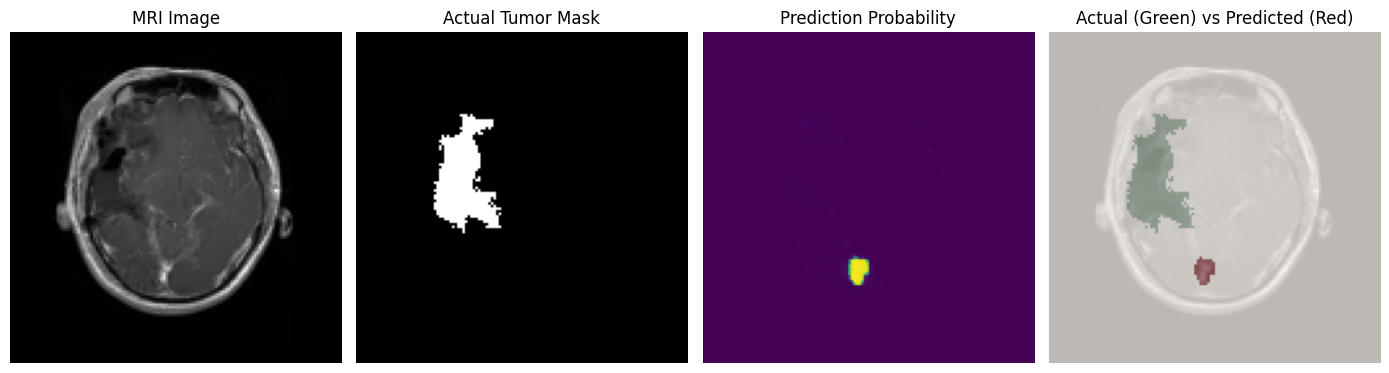

In [ ]:

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Original resized image
display_img = np.array(
    Image.open(image_path).convert("L").resize((128, 128))
)

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

axes[0].imshow(display_img, cmap="gray")
axes[0].set_title("MRI Image")

axes[1].imshow(gt, cmap="gray")
axes[1].set_title("Actual Tumor Mask")

axes[2].imshow(prob, cmap="viridis", vmin=0, vmax=1)
axes[2].set_title("Prediction Probability")

axes[3].imshow(display_img, cmap="gray")
axes[3].imshow(gt, cmap="Greens", alpha=0.5)
axes[3].imshow(pred, cmap="Reds", alpha=0.5)
axes[3].set_title("Actual (Green) vs Predicted (Red)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
print("MRI image mean:", round(float(display_img.mean()), 2))
print("Actual mask pixels:", int(gt.sum()))
print("Predicted mask pixels:", int(pred.sum()))

# Prediction aur actual tumor ke beech minimum bounding-box gap
actual_bottom = gt_y.max()
actual_right = gt_x.max()
pred_top = pred_y.min()
pred_left = pred_x.min()

print("Vertical gap:", int(pred_top - actual_bottom))
print("Horizontal gap:", int(pred_left - actual_right))

MRI image mean: 21.54
Actual mask pixels: 660
Predicted mask pixels: 63
Vertical gap: 10
Horizontal gap: 1


In [ ]:
import os
import numpy as np
from PIL import Image

# Test image
test_img = np.array(
    Image.open(image_path).convert("L").resize((128, 128)),
    dtype=np.float32
) / 255.0

# Same image ka intensity summary
print("Test image:")
print("Min:", round(float(test_img.min()), 4))
print("Max:", round(float(test_img.max()), 4))
print("Mean:", round(float(test_img.mean()), 4))
print("Std:", round(float(test_img.std()), 4))

# Model ka input configuration
print("\nModel input shape:", original_unet.input_shape)
print("Model output shape:", original_unet.output_shape)

Test image:
Min: 0.0
Max: 0.7137
Mean: 0.0845
Std: 0.118

Model input shape: (None, 128, 128, 1)
Model output shape: (None, 128, 128, 1)


In [ ]:
import numpy as np

print("X_train shape:", X_train.shape)
print("X_train min:", float(X_train.min()))
print("X_train max:", float(X_train.max()))
print("X_train mean:", float(X_train.mean()))

print("\nX_val shape:", X_val.shape)
print("X_val min:", float(X_val.min()))
print("X_val max:", float(X_val.max()))
print("X_val mean:", float(X_val.mean()))

print("\nTest image shape:", test_img.shape)
print("Test image min:", float(test_img.min()))
print("Test image max:", float(test_img.max()))
print("Test image mean:", float(test_img.mean()))

X_train shape: (3146, 128, 128, 1)
X_train min: 0.0
X_train max: 1.0
X_train mean: 0.16735050082206726

X_val shape: (787, 128, 128, 1)
X_val min: 0.0
X_val max: 1.0
X_val mean: 0.16395936906337738

Test image shape: (128, 128)
Test image min: 0.0
Test image max: 0.7137255072593689
Test image mean: 0.08446931093931198


In [ ]:
import os
import numpy as np
from PIL import Image

def image_stats(paths):
    means = []
    stds = []

    for path in paths:
        img = Image.open(path).convert("L").resize((128, 128))
        arr = np.array(img, dtype=np.float32) / 255.0
        means.append(arr.mean())
        stds.append(arr.std())

    return len(means), np.mean(means), np.mean(stds)

# Training glioma images
glioma_train_paths = [
    p for p in train_image_paths
    if os.path.basename(p).split("_")[3] == "gl"
][:100]

# Test glioma images
glioma_test_paths = [
    os.path.join(SEG_TEST_IMAGES, name)
    for name in os.listdir(SEG_TEST_IMAGES)
    if name.lower().endswith((".jpg", ".jpeg", ".png"))
    and os.path.basename(name).split("_")[3] == "gl"
][:100]

print("Training glioma (count, mean intensity, mean std):")
print(image_stats(glioma_train_paths))

print("\nTest glioma (count, mean intensity, mean std):")
print(image_stats(glioma_test_paths))

Training glioma (count, mean intensity, mean std):
(100, np.float32(0.12854119), np.float32(0.14977406))

Test glioma (count, mean intensity, mean std):
(100, np.float32(0.13545406), np.float32(0.15026273))


In [ ]:
import numpy as np

# Original saved U-Net se prediction
prob = original_unet.predict(X_train[0:1], verbose=0)[0, :, :, 0]

# Actual and predicted masks
actual = Y_train[0, :, :, 0] > 0.5
predicted = prob > 0.5

# Dice score
intersection = np.logical_and(actual, predicted).sum()
dice = (2 * intersection) / (actual.sum() + predicted.sum() + 1e-7)

print("Actual tumor pixels:", int(actual.sum()))
print("Predicted tumor pixels:", int(predicted.sum()))
print("Overlapping pixels:", int(intersection))
print("Training Dice score:", round(float(dice), 4))
print("Maximum probability:", round(float(prob.max()), 4))
print("Mean probability:", round(float(prob.mean()), 6))

Actual tumor pixels: 90
Predicted tumor pixels: 128
Overlapping pixels: 90
Training Dice score: 0.8257
Maximum probability: 1.0
Mean probability: 0.007839


In [ ]:
import numpy as np

n = min(20, len(X_train))
scores = []

for i in range(n):
    prob = original_unet.predict(X_train[i:i+1], verbose=0)[0, :, :, 0]

    actual = Y_train[i, :, :, 0] > 0.5
    predicted = prob > 0.5

    intersection = np.logical_and(actual, predicted).sum()
    denominator = actual.sum() + predicted.sum()

    dice = (2 * intersection / denominator) if denominator > 0 else 1.0
    scores.append(dice)

print("Images checked:", n)
print("Mean training Dice:", round(float(np.mean(scores)), 4))
print("Median training Dice:", round(float(np.median(scores)), 4))
print("Minimum training Dice:", round(float(np.min(scores)), 4))
print("Maximum training Dice:", round(float(np.max(scores)), 4))
print("Images with Dice below 0.5:", sum(s < 0.5 for s in scores))

Images checked: 20
Mean training Dice: 0.6775
Median training Dice: 0.8083
Minimum training Dice: 0.0
Maximum training Dice: 0.9413
Images with Dice below 0.5: 5


In [ ]:
import numpy as np

n = min(20, len(X_val))
scores = []

for i in range(n):
    prob = original_unet.predict(X_val[i:i+1], verbose=0)[0, :, :, 0]

    actual = Y_val[i, :, :, 0] > 0.5
    predicted = prob > 0.5

    intersection = np.logical_and(actual, predicted).sum()
    denominator = actual.sum() + predicted.sum()

    dice = (2 * intersection / denominator) if denominator > 0 else 1.0
    scores.append(dice)

print("Images checked:", n)
print("Mean validation Dice:", round(float(np.mean(scores)), 4))
print("Median validation Dice:", round(float(np.median(scores)), 4))
print("Minimum validation Dice:", round(float(np.min(scores)), 4))
print("Maximum validation Dice:", round(float(np.max(scores)), 4))
print("Images with Dice below 0.5:", sum(s < 0.5 for s in scores))

Images checked: 20
Mean validation Dice: 0.6953
Median validation Dice: 0.8493
Minimum validation Dice: 0.0
Maximum validation Dice: 0.9403
Images with Dice below 0.5: 4


In [ ]:
import numpy as np

n = min(20, len(X_val))
results = []

for i in range(n):
    prob = original_unet.predict(X_val[i:i+1], verbose=0)[0, :, :, 0]

    actual = Y_val[i, :, :, 0] > 0.5
    predicted = prob > 0.5

    intersection = np.logical_and(actual, predicted).sum()
    actual_pixels = int(actual.sum())
    predicted_pixels = int(predicted.sum())
    denominator = actual_pixels + predicted_pixels

    dice = (2 * intersection / denominator) if denominator > 0 else 1.0

    results.append((i, actual_pixels, predicted_pixels,
                    int(intersection), float(dice), float(prob.max())))

print("Index | Actual px | Predicted px | Overlap | Dice | Max probability")
for r in results:
    print(f"{r[0]:5d} | {r[1]:9d} | {r[2]:12d} | "
          f"{r[3]:7d} | {r[4]:.4f} | {r[5]:.4f}")

print("\nLow-Dice cases (Dice < 0.5):")
for r in results:
    if r[4] < 0.5:
        print(r)

Index | Actual px | Predicted px | Overlap | Dice | Max probability
    0 |       383 |          457 |     382 | 0.9095 | 1.0000
    1 |       740 |          788 |     636 | 0.8325 | 0.9999
    2 |        39 |          266 |      38 | 0.2492 | 0.9977
    3 |       271 |          337 |     238 | 0.7829 | 0.9999
    4 |       167 |          166 |     137 | 0.8228 | 0.9976
    5 |       331 |          373 |     331 | 0.9403 | 1.0000
    6 |       240 |          264 |     236 | 0.9365 | 1.0000
    7 |       169 |          175 |     161 | 0.9360 | 1.0000
    8 |       232 |          246 |     207 | 0.8661 | 0.9987
    9 |       213 |          360 |     180 | 0.6283 | 0.9991
   10 |        37 |           82 |      37 | 0.6218 | 0.9986
   11 |       458 |          521 |     457 | 0.9336 | 1.0000
   12 |       524 |          308 |     140 | 0.3365 | 0.9999
   13 |       354 |          400 |     351 | 0.9310 | 1.0000
   14 |       174 |          186 |     158 | 0.8778 | 0.9991
   15 |       260

In [ ]:
import numpy as np

for i in [2, 12, 16, 18]:
    prob = original_unet.predict(X_val[i:i+1], verbose=0)[0, :, :, 0]
    actual = Y_val[i, :, :, 0] > 0.5

    print(f"\nValidation image {i}")
    print("Actual tumor pixels:", int(actual.sum()))
    print("Probability min:", round(float(prob.min()), 4))
    print("Probability mean:", round(float(prob.mean()), 6))
    print("Probability max:", round(float(prob.max()), 4))

    for threshold in [0.1, 0.25, 0.4, 0.5, 0.7]:
        pred = prob > threshold
        intersection = np.logical_and(actual, pred).sum()
        denom = actual.sum() + pred.sum()
        dice = (2 * intersection / denom) if denom else 1.0

        print(
            f"Threshold={threshold:.2f} | "
            f"Predicted pixels={int(pred.sum())} | "
            f"Dice={dice:.4f}"
        )


Validation image 2
Actual tumor pixels: 39
Probability min: 0.0
Probability mean: 0.016323
Probability max: 0.9977
Threshold=0.10 | Predicted pixels=311 | Dice=0.2171
Threshold=0.25 | Predicted pixels=287 | Dice=0.2331
Threshold=0.40 | Predicted pixels=277 | Dice=0.2405
Threshold=0.50 | Predicted pixels=266 | Dice=0.2492
Threshold=0.70 | Predicted pixels=244 | Dice=0.2686

Validation image 12
Actual tumor pixels: 524
Probability min: 0.0
Probability mean: 0.018946
Probability max: 0.9999
Threshold=0.10 | Predicted pixels=355 | Dice=0.3527
Threshold=0.25 | Predicted pixels=330 | Dice=0.3489
Threshold=0.40 | Predicted pixels=319 | Dice=0.3416
Threshold=0.50 | Predicted pixels=308 | Dice=0.3365
Threshold=0.70 | Predicted pixels=297 | Dice=0.3362

Validation image 16
Actual tumor pixels: 293
Probability min: 0.0
Probability mean: 0.000661
Probability max: 0.4816
Threshold=0.10 | Predicted pixels=14 | Dice=0.0000
Threshold=0.25 | Predicted pixels=4 | Dice=0.0000
Threshold=0.40 | Predicted 

In [ ]:
print("Model input shape:", original_unet.input_shape)
print("Model output shape:", original_unet.output_shape)

print("\nCurrent model layers:")
for layer in original_unet.layers[:5]:
    print(layer.name, layer.__class__.__name__, layer.output.shape)

print("\nTraining-related variables:")
for name in [
    "history", "combined_loss", "dice_loss",
    "dice_coef", "unet_model", "callbacks",
    "early_stopping", "checkpoint"
]:
    print(name, "exists:", name in globals())

print("\nTraining history keys (if available):")
if "history" in globals():
    if hasattr(history, "history"):
        print(list(history.history.keys()))
    elif isinstance(history, dict):
        print(list(history.keys()))

Model input shape: (None, 128, 128, 1)
Model output shape: (None, 128, 128, 1)

Current model layers:
input_layer_5 InputLayer (None, 128, 128, 1)
conv2d_6 Conv2D (None, 128, 128, 32)
conv2d_7 Conv2D (None, 128, 128, 32)
max_pooling2d_6 MaxPooling2D (None, 64, 64, 32)
conv2d_8 Conv2D (None, 64, 64, 64)

Training-related variables:
history exists: True
combined_loss exists: True
dice_loss exists: True
dice_coef exists: False
unet_model exists: True
callbacks exists: True
early_stopping exists: False
checkpoint exists: False

Training history keys (if available):
['accuracy', 'loss', 'val_accuracy', 'val_loss']


In [ ]:
print("History type:", type(history))

if hasattr(history, "history"):
    h = history.history
elif isinstance(history, dict):
    h = history
else:
    h = {}

for key, values in h.items():
    try:
        print(key, "first:", values[0], "last:", values[-1],
              "epochs:", len(values))
    except (TypeError, IndexError):
        print(key, values)

print("\nCombined loss function:")
print(combined_loss)

print("\nDice loss function:")
print(dice_loss)

print("\nCurrent U-Net compile configuration:")
try:
    print("Optimizer:", unet_model.optimizer.__class__.__name__)
    print("Loss:", unet_model.loss)
    print("Metrics:", unet_model.metrics_names)
except Exception as e:
    print("Could not read configuration:", e)

History type: <class 'dict'>
accuracy first: 0.43024998903274536 last: 0.7645000219345093 epochs: 13
loss first: 1.2627196311950684 last: 0.5588055849075317 epochs: 13
val_accuracy first: 0.5419999957084656 last: 0.7580000162124634 epochs: 13
val_loss first: 1.116662621498108 last: 0.5999250411987305 epochs: 13

Combined loss function:
<function combined_loss at 0x7fa83f687c40>

Dice loss function:
<function dice_loss at 0x7fa83f687ce0>

Current U-Net compile configuration:
Optimizer: Adam
Loss: <function combined_loss at 0x7fa83f687c40>
Metrics: ['loss', 'compile_metrics']


In [ ]:
import numpy as np

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
dice_scores = {t: [] for t in thresholds}

# Predict validation set in batches
for start in range(0, len(X_val), 16):
    end = min(start + 16, len(X_val))
    probs = original_unet.predict(X_val[start:end], verbose=0)

    for j in range(end - start):
        actual = Y_val[start + j, :, :, 0] > 0.5
        prob = probs[j, :, :, 0]

        for t in thresholds:
            predicted = prob > t
            intersection = np.logical_and(actual, predicted).sum()
            denominator = actual.sum() + predicted.sum()

            # Empty actual and predicted masks count as perfect agreement
            dice = (
                2.0 * intersection / denominator
                if denominator > 0
                else 1.0
            )
            dice_scores[t].append(dice)

print("Threshold | Mean Dice | Median Dice | Dice < 0.5")
for t in thresholds:
    scores = np.array(dice_scores[t])
    print(
        f"{t:9.1f} | {scores.mean():9.4f} | "
        f"{np.median(scores):11.4f} | {np.sum(scores < 0.5):10d}"
    )

best_threshold = max(
    thresholds,
    key=lambda t: np.mean(dice_scores[t])
)

print("\nBest threshold on validation set:", best_threshold)
print("Best validation mean Dice:", round(
    float(np.mean(dice_scores[best_threshold])), 4
))

Threshold | Mean Dice | Median Dice | Dice < 0.5
      0.1 |    0.5961 |      0.7226 |        239
      0.2 |    0.6055 |      0.7419 |        227
      0.3 |    0.6110 |      0.7518 |        228
      0.4 |    0.6156 |      0.7603 |        225
      0.5 |    0.6194 |      0.7674 |        223
      0.6 |    0.6232 |      0.7738 |        219
      0.7 |    0.6272 |      0.7864 |        217
      0.8 |    0.6326 |      0.7962 |        212
      0.9 |    0.6410 |      0.8138 |        211

Best threshold on validation set: 0.9
Best validation mean Dice: 0.641


In [ ]:
import numpy as np

threshold = 0.9
empty_predictions = 0
zero_dice_cases = 0
low_dice_cases = 0
scores = []

for start in range(0, len(X_val), 16):
    end = min(start + 16, len(X_val))
    probs = original_unet.predict(X_val[start:end], verbose=0)

    for j in range(end - start):
        actual = Y_val[start + j, :, :, 0] > 0.5
        predicted = probs[j, :, :, 0] > threshold

        intersection = np.logical_and(actual, predicted).sum()
        denominator = actual.sum() + predicted.sum()
        dice = 2 * intersection / denominator if denominator else 1.0

        scores.append(dice)
        empty_predictions += int(predicted.sum() == 0)
        zero_dice_cases += int(dice == 0)
        low_dice_cases += int(dice < 0.5)

print("Validation images:", len(scores))
print("Mean Dice:", round(float(np.mean(scores)), 4))
print("Empty predictions:", empty_predictions)
print("Zero-Dice cases:", zero_dice_cases)
print("Dice below 0.5:", low_dice_cases)

Validation images: 787
Mean Dice: 0.641
Empty predictions: 56
Zero-Dice cases: 122
Dice below 0.5: 211


In [ ]:
import inspect

print("----- dice_loss -----")
print(inspect.getsource(dice_loss))

print("\n----- combined_loss -----")
print(inspect.getsource(combined_loss))

----- dice_loss -----
def dice_loss(y_true, y_pred):
    smooth = 1e-6
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])

    intersection = tf.reduce_sum(y_true_f * y_pred_f)

    dice = (2.0 * intersection + smooth) / (
        tf.reduce_sum(y_true_f) +
        tf.reduce_sum(y_pred_f) + smooth
    )

    return 1.0 - dice


----- combined_loss -----
def combined_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    return tf.reduce_mean(bce) + dice_loss(y_true, y_pred)



In [ ]:
import os

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"

print("Project files:")
for name in sorted(os.listdir(project_dir)):
    if any(word in name.lower() for word in [
        "unet", "segmentation", "history", "evaluation"
    ]):
        path = os.path.join(project_dir, name)
        print(name, "|", os.path.getsize(path), "bytes")

print("\nCurrent model optimizer:", unet_model.optimizer.get_config())
print("\nCurrent model loss:", unet_model.loss)
print("\nCurrent model metrics:", unet_model.metrics)

Project files:
best_unet_segmentation.keras | 93271134 bytes
fresh_test_evaluation.csv | 65808 bytes
segmentation_test_evaluation.csv | 98605 bytes
threshold_comparison_evaluation.csv | 88631 bytes
training_history.json | 1549 bytes
unet_before_retraining.keras | 31160356 bytes
unet_error_analysis.csv | 108203 bytes

Current model optimizer: {'name': 'adam', 'learning_rate': 9.999999747378752e-05, 'weight_decay': None, 'clipnorm': None, 'global_clipnorm': None, 'clipvalue': None, 'use_ema': False, 'ema_momentum': 0.99, 'ema_overwrite_frequency': None, 'loss_scale_factor': None, 'gradient_accumulation_steps': None, 'beta_1': 0.9, 'beta_2': 0.999, 'epsilon': 1e-07, 'amsgrad': False}

Current model loss: <function combined_loss at 0x7fa83f687c40>

Current model metrics: [<Mean name=loss>, <CompileMetrics name=compile_metrics>]


In [ ]:
import json
import os

history_path = (
    "/content/drive/MyDrive/Brain_Tumor_Project/training_history.json"
)

with open(history_path, "r") as f:
    saved_history = json.load(f)

print("History file type:", type(saved_history))

if isinstance(saved_history, dict):
    print("Keys:", list(saved_history.keys()))

    for key, value in saved_history.items():
        if isinstance(value, list):
            print(
                f"{key}: epochs={len(value)}, "
                f"first={value[0] if value else None}, "
                f"last={value[-1] if value else None}"
            )
        else:
            print(f"{key}: {value}")

History file type: <class 'dict'>
Keys: ['accuracy', 'loss', 'val_accuracy', 'val_loss']
accuracy: epochs=13, first=0.43024998903274536, last=0.7645000219345093
loss: epochs=13, first=1.2627196311950684, last=0.5588055849075317
val_accuracy: epochs=13, first=0.5419999957084656, last=0.7580000162124634
val_loss: epochs=13, first=1.116662621498108, last=0.5999250411987305


In [ ]:
import tensorflow as tf
import numpy as np

best_model_path = (
    "/content/drive/MyDrive/Brain_Tumor_Project/"
    "best_unet_segmentation.keras"
)

best_unet = tf.keras.models.load_model(
    best_model_path,
    custom_objects={
        "combined_loss": combined_loss,
        "dice_loss": dice_loss
    },
    compile=False
)

print("Best model loaded.")
print("Input shape:", best_unet.input_shape)
print("Output shape:", best_unet.output_shape)

# Compare best saved model and current original model
n = min(100, len(X_val))

best_probs = best_unet.predict(X_val[:n], verbose=0)
original_probs = original_unet.predict(X_val[:n], verbose=0)

print(
    "Mean absolute difference in predictions:",
    round(float(np.mean(np.abs(best_probs - original_probs))), 6)
)

def mean_dice_for_model(model, images, masks, threshold=0.5):
    scores = []
    probs = model.predict(images, batch_size=16, verbose=0)

    for i in range(len(images)):
        actual = masks[i, :, :, 0] > 0.5
        predicted = probs[i, :, :, 0] > threshold

        intersection = np.logical_and(actual, predicted).sum()
        denominator = actual.sum() + predicted.sum()

        dice = (
            2 * intersection / denominator
            if denominator > 0 else 1.0
        )
        scores.append(dice)

    return float(np.mean(scores)), int(np.sum(np.array(scores) < 0.5))

print("\nBest saved model, validation subset:")
print(mean_dice_for_model(
    best_unet, X_val[:n], Y_val[:n], threshold=0.5
))

print("\nOriginal model, same validation subset:")
print(mean_dice_for_model(
    original_unet, X_val[:n], Y_val[:n], threshold=0.5
))

Best model loaded.
Input shape: (None, 128, 128, 1)
Output shape: (None, 128, 128, 1)
Mean absolute difference in predictions: 0.0

Best saved model, validation subset:
(0.6062219610295679, 30)

Original model, same validation subset:
(0.6062219610295679, 30)


In [ ]:
import numpy as np

n = min(100, len(X_val))

best_probs = best_unet.predict(X_val[:n], verbose=0)
original_probs = original_unet.predict(X_val[:n], verbose=0)

print("Mean absolute prediction difference:",
      round(float(np.mean(np.abs(best_probs - original_probs))), 6))


def calculate_mean_dice(probs, masks, threshold=0.5):
    scores = []

    for i in range(len(masks)):
        actual = masks[i, :, :, 0] > 0.5
        predicted = probs[i, :, :, 0] > threshold

        intersection = np.logical_and(actual, predicted).sum()
        denominator = actual.sum() + predicted.sum()

        dice = 2 * intersection / denominator if denominator else 1.0
        scores.append(dice)

    return round(float(np.mean(scores)), 4), sum(s < 0.5 for s in scores)


print("Best saved model (mean Dice, Dice < 0.5):",
      calculate_mean_dice(best_probs, Y_val[:n]))

print("Original model (mean Dice, Dice < 0.5):",
      calculate_mean_dice(original_probs, Y_val[:n]))


Mean absolute prediction difference: 0.0
Best saved model (mean Dice, Dice < 0.5): (0.6062, np.int64(30))
Original model (mean Dice, Dice < 0.5): (0.6062, np.int64(30))


In [ ]:
import tensorflow as tf

def dice_loss_per_image(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    axes = [1, 2, 3]
    intersection = tf.reduce_sum(y_true * y_pred, axis=axes)
    total = tf.reduce_sum(y_true, axis=axes) + tf.reduce_sum(y_pred, axis=axes)

    dice = (2.0 * intersection + smooth) / (total + smooth)
    return tf.reduce_mean(1.0 - dice)

def improved_combined_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    return tf.reduce_mean(bce) + dice_loss_per_image(y_true, y_pred)

print("New loss functions are ready.")
print("Existing models have not been changed.")

New loss functions are ready.
Existing models have not been changed.


In [ ]:
import tensorflow as tf
import os

# Create a separate copy of the existing best model
new_unet = tf.keras.models.clone_model(best_unet)
new_unet.set_weights(best_unet.get_weights())

# Compile with per-image Dice loss
new_unet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=improved_combined_loss
)

# Save under a new filename
new_model_path = (
    "/content/drive/MyDrive/Brain_Tumor_Project/"
    "unet_per_image_dice.keras"
)

checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    new_model_path,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

early_stop_cb = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    mode="min",
    restore_best_weights=True,
    verbose=1
)

history_new = new_unet.fit(
    X_train,
    Y_train,
    validation_data=(X_val, Y_val),
    epochs=20,
    batch_size=16,
    callbacks=[checkpoint_cb, early_stop_cb],
    verbose=1
)

print("\nTraining completed.")
print("New model path:", new_model_path)
print("Best validation loss:", min(history_new.history["val_loss"]))

Epoch 1/20
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - loss: 0.4093
Epoch 1: val_loss improved from None to 0.41156, saving model to /content/drive/MyDrive/Brain_Tumor_Project/unet_per_image_dice.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Brain_Tumor_Project/unet_per_image_dice.keras
197/197 ━━━━━━━━━━━━━━━━━━━━ 1136s 6s/step - loss: 0.3956 - val_loss: 0.4116
Epoch 2/20
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - loss: 0.3880
Epoch 2: val_loss improved from 0.41156 to 0.40296, saving model to /content/drive/MyDrive/Brain_Tumor_Project/unet_per_image_dice.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Brain_Tumor_Project/unet_per_image_dice.keras
197/197 ━━━━━━━━━━━━━━━━━━━━ 1128s 6s/step - loss: 0.3787 - val_loss: 0.4030
Epoch 3/20
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - loss: 0.3797
Epoch 3: val_loss improved from 0.40296 to 0.39841, saving model to /content/drive/MyDrive/Brain_Tumor_Project/unet_per_image_dice.keras

Epoch 3: finished saving model 

In [ ]:
import numpy as np
import tensorflow as tf

new_model_path = (
    "/content/drive/MyDrive/Brain_Tumor_Project/"
    "unet_per_image_dice.keras"
)

new_unet = tf.keras.models.load_model(
    new_model_path,
    custom_objects={
        "improved_combined_loss": improved_combined_loss,
        "dice_loss_per_image": dice_loss_per_image
    },
    compile=False
)

def evaluate_dice(model, images, masks, threshold=0.5):
    scores = []
    empty_predictions = 0

    for start in range(0, len(images), 16):
        end = min(start + 16, len(images))
        probs = model.predict(images[start:end], verbose=0)

        for j in range(end - start):
            actual = masks[start + j, :, :, 0] > 0.5
            predicted = probs[j, :, :, 0] > threshold

            intersection = np.logical_and(actual, predicted).sum()
            denominator = actual.sum() + predicted.sum()

            dice = (
                2 * intersection / denominator
                if denominator > 0 else 1.0
            )
            scores.append(dice)
            empty_predictions += int(predicted.sum() == 0)

    return {
        "mean_dice": round(float(np.mean(scores)), 4),
        "median_dice": round(float(np.median(scores)), 4),
        "dice_below_0.5": int(np.sum(np.array(scores) < 0.5)),
        "empty_predictions": empty_predictions
    }

print("OLD MODEL:", evaluate_dice(original_unet, X_val, Y_val))
print("NEW MODEL:", evaluate_dice(new_unet, X_val, Y_val))

OLD MODEL: {'mean_dice': 0.6194, 'median_dice': 0.7674, 'dice_below_0.5': 223, 'empty_predictions': 45}
NEW MODEL: {'mean_dice': 0.6807, 'median_dice': 0.8471, 'dice_below_0.5': 185, 'empty_predictions': 35}


In [ ]:
import os
import tensorflow as tf

model_path = (
    "/content/drive/MyDrive/Brain_Tumor_Project/"
    "unet_per_image_dice.keras"
)

if os.path.exists(model_path):
    print("Model file exists.")
    print("File size:", round(os.path.getsize(model_path) / (1024**2), 2), "MB")

    saved_model = tf.keras.models.load_model(
        model_path,
        custom_objects={
            "improved_combined_loss": improved_combined_loss,
            "dice_loss_per_image": dice_loss_per_image
        },
        compile=False
    )

    print("Model loaded successfully!")
    print("Input shape:", saved_model.input_shape)
    print("Output shape:", saved_model.output_shape)
else:
    print("Model file not found. Check Google Drive mount.")

Model file exists.
File size: 88.95 MB
Model loaded successfully!
Input shape: (None, 128, 128, 1)
Output shape: (None, 128, 128, 1)


In [ ]:
import os
import numpy as np
from PIL import Image

def load_test_data(image_dir, mask_dir):
    image_paths = sorted([
        os.path.join(image_dir, f)
        for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    X, Y = [], []

    for image_path in image_paths:
        name = os.path.splitext(os.path.basename(image_path))[0]
        mask_path = os.path.join(mask_dir, name + ".png")

        if not os.path.exists(mask_path):
            continue

        img = Image.open(image_path).convert("L").resize((128, 128))
        mask = Image.open(mask_path).convert("L").resize(
            (128, 128), Image.Resampling.NEAREST
        )

        X.append(np.array(img, dtype=np.float32)[..., None] / 255.0)
        Y.append((np.array(mask) > 127).astype(np.float32)[..., None])

    return np.array(X), np.array(Y)

X_test_seg, Y_test_seg = load_test_data(
    SEG_TEST_IMAGES, SEG_TEST_MASKS
)

print("Test images:", X_test_seg.shape)
print("Test masks:", Y_test_seg.shape)

Test images: (860, 128, 128, 1)
Test masks: (860, 128, 128, 1)


In [ ]:
import numpy as np

def evaluate_segmentation(model, X, Y, threshold=0.5):
    predictions = model.predict(X, batch_size=16, verbose=1)

    pred_masks = (predictions >= threshold).astype(np.uint8)
    true_masks = (Y >= 0.5).astype(np.uint8)

    axes = (1, 2, 3)

    intersection = np.sum(pred_masks * true_masks, axis=axes)
    pred_pixels = np.sum(pred_masks, axis=axes)
    true_pixels = np.sum(true_masks, axis=axes)

    dice = (2 * intersection + 1e-7) / (
        pred_pixels + true_pixels + 1e-7
    )

    return {
        "Mean Dice": np.mean(dice),
        "Median Dice": np.median(dice),
        "Dice below 0.5": np.sum(dice < 0.5),
        "Empty predictions": np.sum(pred_pixels == 0),
        "Individual Dice": dice
    }


# Evaluate both models on the same test dataset
old_results = evaluate_segmentation(
    original_unet, X_test_seg, Y_test_seg
)

new_results = evaluate_segmentation(
    saved_model, X_test_seg, Y_test_seg
)

print("\n--- TEST SET COMPARISON ---")
print(f"{'Metric':<22}{'Old Model':>12}{'New Model':>12}")
print("-" * 46)

for metric in [
    "Mean Dice",
    "Median Dice",
    "Dice below 0.5",
    "Empty predictions"
]:
    print(
        f"{metric:<22}"
        f"{old_results[metric]:>12.4f}"
        f"{new_results[metric]:>12.4f}"
    )

54/54 ━━━━━━━━━━━━━━━━━━━━ 102s 2s/step
54/54 ━━━━━━━━━━━━━━━━━━━━ 76s 1s/step

--- TEST SET COMPARISON ---
Metric                   Old Model   New Model
----------------------------------------------
Mean Dice                   0.6357      0.7019
Median Dice                 0.7776      0.8507
Dice below 0.5            225.0000    174.0000
Empty predictions          38.0000     27.0000


In [ ]:
import os

print("First 20 test image filenames:\n")

files = sorted([
    f for f in os.listdir(SEG_TEST_IMAGES)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

for f in files[:20]:
    print(f)

print("\nTotal image files:", len(files))

First 20 test image filenames:

brisc2025_test_00001_gl_ax_t1.jpg
brisc2025_test_00002_gl_ax_t1.jpg
brisc2025_test_00003_gl_ax_t1.jpg
brisc2025_test_00004_gl_ax_t1.jpg
brisc2025_test_00005_gl_ax_t1.jpg
brisc2025_test_00006_gl_ax_t1.jpg
brisc2025_test_00007_gl_ax_t1.jpg
brisc2025_test_00008_gl_ax_t1.jpg
brisc2025_test_00009_gl_ax_t1.jpg
brisc2025_test_00010_gl_ax_t1.jpg
brisc2025_test_00011_gl_ax_t1.jpg
brisc2025_test_00012_gl_ax_t1.jpg
brisc2025_test_00013_gl_ax_t1.jpg
brisc2025_test_00014_gl_ax_t1.jpg
brisc2025_test_00015_gl_ax_t1.jpg
brisc2025_test_00016_gl_ax_t1.jpg
brisc2025_test_00017_gl_ax_t1.jpg
brisc2025_test_00018_gl_ax_t1.jpg
brisc2025_test_00019_gl_ax_t1.jpg
brisc2025_test_00020_gl_ax_t1.jpg

Total image files: 860


In [ ]:
import os

base_path = "/content/brisc_data/brisc2025"

print("Label / metadata files:\n")

for root, dirs, files in os.walk(base_path):
    for file in files:
        if file.lower().endswith((".csv", ".xlsx", ".xls", ".json")):
            print(os.path.join(root, file))

Label / metadata files:



In [ ]:
import os

base_path = "/content/brisc_data/brisc2025"

for root, dirs, files in os.walk(base_path):
    level = root.replace(base_path, "").count(os.sep)

    if level <= 2:
        print(
            "  " * level,
            os.path.basename(root) or "brisc2025",
            "| files:", len(files)
        )

 brisc2025 | files: 0
   classification_task | files: 0
     train | files: 0
     test | files: 0
   segmentation_task | files: 0
     train | files: 0
     test | files: 0


In [ ]:
import os

class_train = "/content/brisc_data/brisc2025/classification_task/train"
class_test = "/content/brisc_data/brisc2025/classification_task/test"

for folder in [class_train, class_test]:
    print("\nFolder:", folder)

    for item in sorted(os.listdir(folder)):
        path = os.path.join(folder, item)

        if os.path.isdir(path):
            print("Class folder:", item,
                  "| Images:", len(os.listdir(path)))
        else:
            print("File:", item)


Folder: /content/brisc_data/brisc2025/classification_task/train
Class folder: glioma | Images: 1147
Class folder: meningioma | Images: 1329
Class folder: no_tumor | Images: 1067
Class folder: pituitary | Images: 1457

Folder: /content/brisc_data/brisc2025/classification_task/test
Class folder: glioma | Images: 254
Class folder: meningioma | Images: 306
Class folder: no_tumor | Images: 140
Class folder: pituitary | Images: 300


In [ ]:
import os

seg_files = sorted([
    f for f in os.listdir(SEG_TEST_IMAGES)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

for class_name in ["glioma", "meningioma", "no_tumor", "pituitary"]:
    class_folder = os.path.join(
        "/content/brisc_data/brisc2025/classification_task/test",
        class_name
    )

    class_files = sorted(os.listdir(class_folder))

    print(f"\n{class_name.upper()}")
    print("Classification example:", class_files[:3])

print("\nSegmentation examples:")
for f in seg_files[:5]:
    print(f)


GLIOMA
Classification example: ['brisc2025_test_00001_gl_ax_t1.jpg', 'brisc2025_test_00002_gl_ax_t1.jpg', 'brisc2025_test_00003_gl_ax_t1.jpg']

MENINGIOMA
Classification example: ['brisc2025_test_00255_me_ax_t1.jpg', 'brisc2025_test_00256_me_ax_t1.jpg', 'brisc2025_test_00257_me_ax_t1.jpg']

NO_TUMOR
Classification example: ['brisc2025_test_00561_no_ax_t1.jpg', 'brisc2025_test_00562_no_ax_t1.jpg', 'brisc2025_test_00563_no_ax_t1.jpg']

PITUITARY
Classification example: ['brisc2025_test_00701_pi_ax_t1.jpg', 'brisc2025_test_00702_pi_ax_t1.jpg', 'brisc2025_test_00703_pi_ax_t1.jpg']

Segmentation examples:
brisc2025_test_00001_gl_ax_t1.jpg
brisc2025_test_00002_gl_ax_t1.jpg
brisc2025_test_00003_gl_ax_t1.jpg
brisc2025_test_00004_gl_ax_t1.jpg
brisc2025_test_00005_gl_ax_t1.jpg


In [ ]:
import os

class_test_path = (
    "/content/brisc_data/brisc2025/classification_task/test"
)

class_files = set()

for class_name in ["glioma", "meningioma", "no_tumor", "pituitary"]:
    folder = os.path.join(class_test_path, class_name)
    for filename in os.listdir(folder):
        class_files.add(filename)

seg_files_set = set(
    f for f in os.listdir(SEG_TEST_IMAGES)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
)

print("Segmentation images:", len(seg_files_set))
print("Classification test images:", len(class_files))
print("Exact filename matches:", len(seg_files_set & class_files))
print("Segmentation images without class label:",
      len(seg_files_set - class_files))

Segmentation images: 860
Classification test images: 1000
Exact filename matches: 860
Segmentation images without class label: 0


In [ ]:
import os
import numpy as np
import pandas as pd

class_test_path = (
    "/content/brisc_data/brisc2025/classification_task/test"
)

# Map each segmentation filename to its verified class
filename_to_class = {}

for class_name in ["glioma", "meningioma", "no_tumor", "pituitary"]:
    folder = os.path.join(class_test_path, class_name)

    for filename in os.listdir(folder):
        filename_to_class[filename] = class_name

# Keep the same sorted order used when loading X_test_seg and Y_test_seg
seg_files = sorted([
    f for f in os.listdir(SEG_TEST_IMAGES)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

assert len(seg_files) == len(X_test_seg) == len(Y_test_seg)
assert all(f in filename_to_class for f in seg_files)

# Use predictions already evaluated at threshold 0.5
dice_scores = new_results["Individual Dice"]

results_df = pd.DataFrame({
    "filename": seg_files,
    "tumor_type": [filename_to_class[f] for f in seg_files],
    "dice": dice_scores
})

summary = results_df.groupby("tumor_type").agg(
    image_count=("dice", "count"),
    mean_dice=("dice", "mean"),
    median_dice=("dice", "median"),
    dice_below_0_5=("dice", lambda s: (s < 0.5).sum())
).reset_index()

print("NEW U-NET: TYPE-WISE TEST RESULTS")
print(summary.round(4).to_string(index=False))

print("\nImages per class:")
print(results_df["tumor_type"].value_counts().to_string())

NEW U-NET: TYPE-WISE TEST RESULTS
tumor_type  image_count  mean_dice  median_dice  dice_below_0_5
    glioma          254     0.4168       0.4398             134
meningioma          306     0.8788       0.9358              11
 pituitary          300     0.7630       0.8387              29

Images per class:
tumor_type
meningioma    306
pituitary     300
glioma        254


In [ ]:
# Find 5 glioma images with the lowest Dice scores
glioma_df = results_df[
    results_df["tumor_type"] == "glioma"
].sort_values("dice")

print("5 glioma images with lowest Dice scores:\n")
print(glioma_df[["filename", "dice"]].head(5).to_string(index=False))

5 glioma images with lowest Dice scores:

                         filename         dice
brisc2025_test_00239_gl_sa_t1.jpg 7.412898e-11
brisc2025_test_00097_gl_co_t1.jpg 8.976661e-11
brisc2025_test_00252_gl_sa_t1.jpg 1.059322e-10
brisc2025_test_00158_gl_co_t1.jpg 1.314060e-10
brisc2025_test_00043_gl_ax_t1.jpg 1.329787e-10


In [ ]:
import numpy as np

# Five lowest-Dice glioma filenames
bad_files = glioma_df["filename"].head(5).tolist()

# Filename -> index in the sorted test arrays
file_to_index = {f: i for i, f in enumerate(seg_files)}

for filename in bad_files:
    i = file_to_index[filename]

    # Ground-truth mask
    true_mask = (Y_test_seg[i, :, :, 0] >= 0.5)

    # Prediction from the saved new U-Net
    pred_prob = saved_model.predict(
        X_test_seg[i:i+1], verbose=0
    )[0, :, :, 0]

    pred_mask = pred_prob >= 0.5

    print("\nImage:", filename)
    print("Actual tumor pixels:", int(true_mask.sum()))
    print("Predicted tumor pixels:", int(pred_mask.sum()))
    print("Maximum prediction probability:", round(float(pred_prob.max()), 4))
    print("Mean prediction probability:", round(float(pred_prob.mean()), 4))


Image: brisc2025_test_00239_gl_sa_t1.jpg
Actual tumor pixels: 1349
Predicted tumor pixels: 0
Maximum prediction probability: 0.2253
Mean prediction probability: 0.0004

Image: brisc2025_test_00097_gl_co_t1.jpg
Actual tumor pixels: 1114
Predicted tumor pixels: 0
Maximum prediction probability: 0.1382
Mean prediction probability: 0.0003

Image: brisc2025_test_00252_gl_sa_t1.jpg
Actual tumor pixels: 944
Predicted tumor pixels: 0
Maximum prediction probability: 0.0966
Mean prediction probability: 0.0005

Image: brisc2025_test_00158_gl_co_t1.jpg
Actual tumor pixels: 745
Predicted tumor pixels: 16
Maximum prediction probability: 0.985
Mean prediction probability: 0.0014

Image: brisc2025_test_00043_gl_ax_t1.jpg
Actual tumor pixels: 679
Predicted tumor pixels: 73
Maximum prediction probability: 0.9975
Mean prediction probability: 0.007


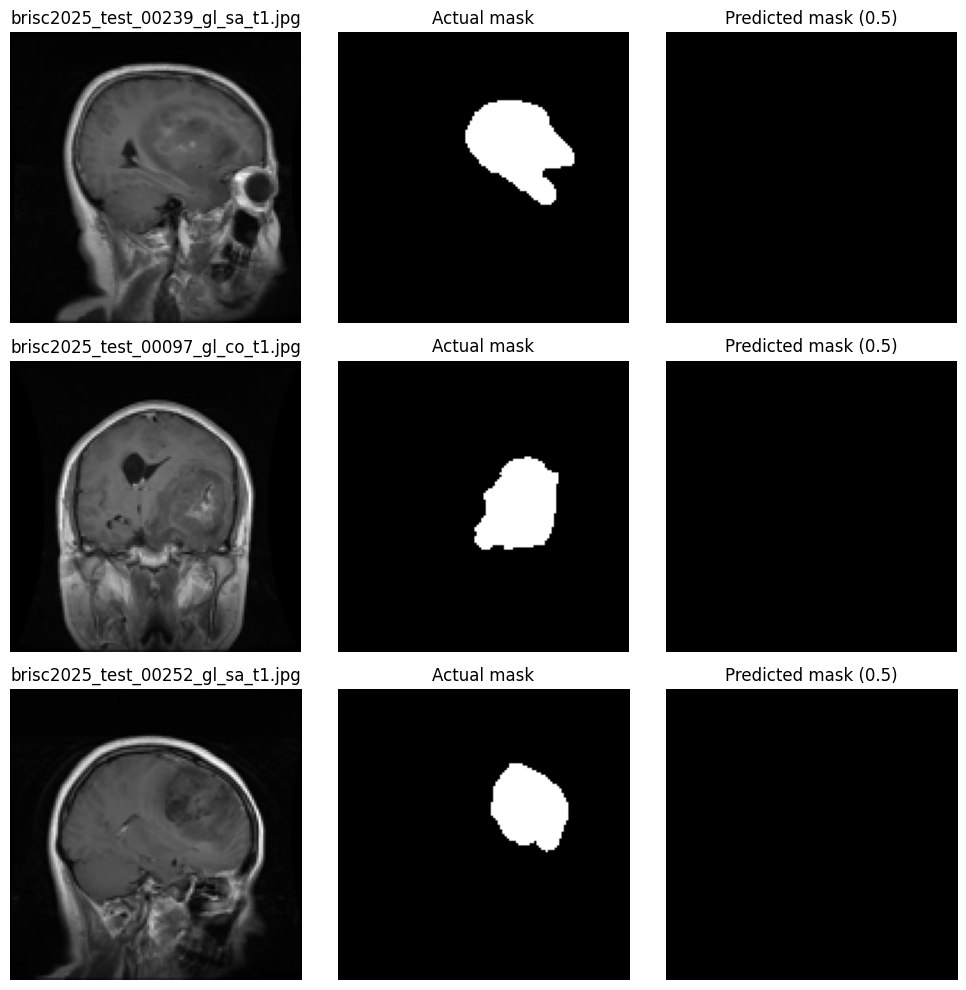

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

bad_files = glioma_df["filename"].head(3).tolist()
file_to_index = {f: i for i, f in enumerate(seg_files)}

fig, axes = plt.subplots(len(bad_files), 3, figsize=(10, 10))

for row, filename in enumerate(bad_files):
    i = file_to_index[filename]

    image = X_test_seg[i, :, :, 0]
    true_mask = Y_test_seg[i, :, :, 0]

    pred_prob = saved_model.predict(
        X_test_seg[i:i+1], verbose=0
    )[0, :, :, 0]
    pred_mask = (pred_prob >= 0.5).astype(np.float32)

    axes[row, 0].imshow(image, cmap="gray")
    axes[row, 0].set_title(filename)

    axes[row, 1].imshow(true_mask, cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title("Actual mask")

    axes[row, 2].imshow(pred_mask, cmap="gray", vmin=0, vmax=1)
    axes[row, 2].set_title("Predicted mask (0.5)")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

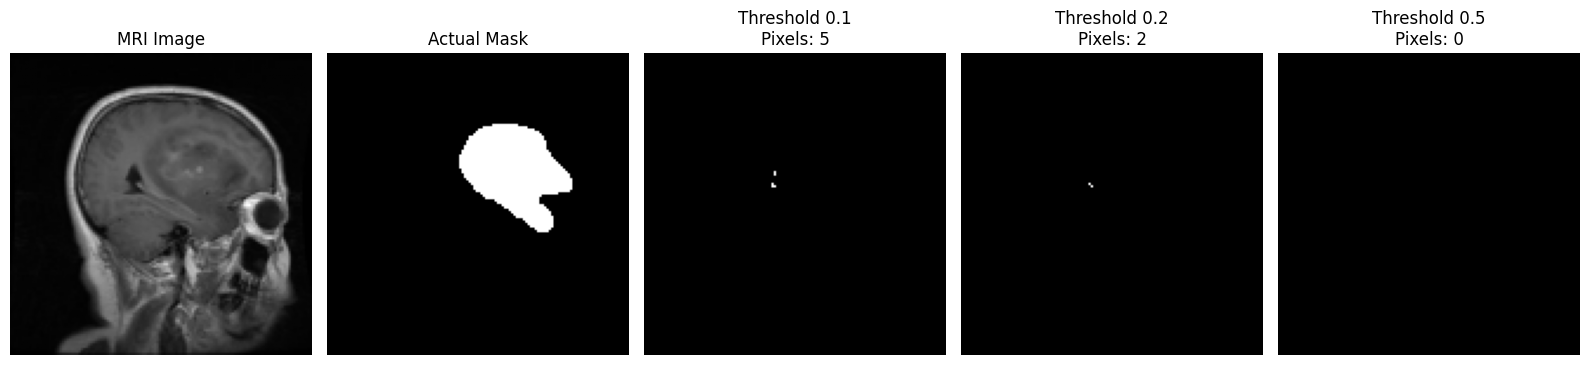

Maximum probability: 0.22528187930583954
Actual tumor pixels: 1349


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

filename = "brisc2025_test_00239_gl_sa_t1.jpg"
i = file_to_index[filename]

image = X_test_seg[i, :, :, 0]
true_mask = Y_test_seg[i, :, :, 0]

pred_prob = saved_model.predict(
    X_test_seg[i:i+1], verbose=0
)[0, :, :, 0]

thresholds = [0.05, 0.10, 0.20, 0.50]

fig, axes = plt.subplots(1, 5, figsize=(16, 4))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("MRI Image")

axes[1].imshow(true_mask, cmap="gray")
axes[1].set_title("Actual Mask")

for ax, threshold in zip(axes[2:], thresholds[1:]):
    mask = pred_prob >= threshold
    ax.imshow(mask, cmap="gray")
    ax.set_title(f"Threshold {threshold}\nPixels: {mask.sum()}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Maximum probability:", float(pred_prob.max()))
print("Actual tumor pixels:", int(true_mask.sum()))

In [ ]:
for t in [0.05, 0.10, 0.15, 0.20, 0.50]:
    pred_mask = pred_prob >= t
    print(f"Threshold {t:.2f}: {pred_mask.sum()} pixels")

Threshold 0.05: 10 pixels
Threshold 0.10: 5 pixels
Threshold 0.15: 3 pixels
Threshold 0.20: 2 pixels
Threshold 0.50: 0 pixels


In [ ]:
import numpy as np

# Tumor pixels in training and validation masks
for name, masks in [
    ("Training", Y_train),
    ("Validation", Y_val)
]:
    tumor_pixels = np.sum(masks >= 0.5, axis=(1, 2, 3))
    empty_masks = np.sum(tumor_pixels == 0)

    print(f"\n{name} dataset")
    print("Total images:", len(masks))
    print("Images with tumor masks:", int(np.sum(tumor_pixels > 0)))
    print("Images with empty masks:", int(empty_masks))
    print("Mean tumor pixels per image:", round(float(np.mean(tumor_pixels)), 2))
    print("Median tumor pixels:", float(np.median(tumor_pixels)))


Training dataset
Total images: 3146
Images with tumor masks: 3146
Images with empty masks: 0
Mean tumor pixels per image: 269.2
Median tumor pixels: 205.0

Validation dataset
Total images: 787
Images with tumor masks: 787
Images with empty masks: 0
Mean tumor pixels per image: 272.65
Median tumor pixels: 213.0


In [ ]:
print("Available dataset variables:")

for name in [
    "X_train", "Y_train", "X_val", "Y_val",
    "train_ds", "val_ds", "train_ds_tl", "val_ds_tl",
    "X_train_seg", "Y_train_seg"
]:
    if name in globals():
        obj = globals()[name]
        print(name, "->", getattr(obj, "shape", type(obj).__name__))

Available dataset variables:


In [ ]:
import os

paths = [
    "/content/drive/MyDrive/Brain_Tumor_Project/unet_per_image_dice.keras",
    "/content/brisc_data/brisc2025/segmentation_task/train/images",
    "/content/brisc_data/brisc2025/segmentation_task/train/masks",
    "/content/brisc_data/brisc2025/segmentation_task/test/images"
]

for path in paths:
    print(
        "FOUND" if os.path.exists(path) else "NOT FOUND",
        "|",
        path
    )

NOT FOUND | /content/drive/MyDrive/Brain_Tumor_Project/unet_per_image_dice.keras
NOT FOUND | /content/brisc_data/brisc2025/segmentation_task/train/images
NOT FOUND | /content/brisc_data/brisc2025/segmentation_task/train/masks
NOT FOUND | /content/brisc_data/brisc2025/segmentation_task/test/images


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

folder = "/content/drive/MyDrive/Brain_Tumor_Project"

if os.path.exists(folder):
    print("Project folder found!")
    for file in os.listdir(folder):
        if "unet" in file.lower():
            print(file)
else:
    print("Project folder not found at this location.")

Project folder found!
best_unet_segmentation.keras
unet_error_analysis.csv
unet_before_retraining.keras
unet_per_image_dice.keras


In [ ]:
import os

search_roots = [
    "/content/drive/MyDrive",
    "/content"
]

for base in search_roots:
    print(f"\nSearching in: {base}")

    for root, dirs, files in os.walk(base):
        dirs[:] = [
            d for d in dirs
            if d not in [".config", "sample_data"]
        ]

        for name in files:
            lower_name = name.lower()

            if (
                "brisc" in lower_name
                and lower_name.endswith((".zip", ".tar", ".gz"))
            ):
                print("Dataset archive:", os.path.join(root, name))

        if base == "/content/drive/MyDrive" and root.count(os.sep) > 5:
            dirs[:] = []


Searching in: /content/drive/MyDrive
Dataset archive: /content/drive/MyDrive/🧠 BRISC 2025.zip

Searching in: /content
Dataset archive: /content/drive/MyDrive/🧠 BRISC 2025.zip


In [ ]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/🧠 BRISC 2025.zip"
extract_path = "/content/brisc_data"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extraction completed!")

for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)

    if level <= 2:
        print("  " * level, os.path.basename(root),
              "| files:", len(files))

Dataset extraction completed!
 brisc_data | files: 0
   🧠 BRISC 2025 | files: 1


In [ ]:
import os

base_path = "/content/brisc_data/🧠 BRISC 2025"

for root, dirs, files in os.walk(base_path):
    level = root.replace(base_path, "").count(os.sep)

    if level <= 3:
        print(
            "  " * level,
            os.path.basename(root),
            "| files:", len(files)
        )

 🧠 BRISC 2025 | files: 1


In [ ]:
import os

folder = "/content/brisc_data/🧠 BRISC 2025"

for item in os.listdir(folder):
    path = os.path.join(folder, item)
    print("Name:", item)
    print("Is file:", os.path.isfile(path))
    if os.path.isfile(path):
        print("Size (MB):", round(os.path.getsize(path) / (1024**2), 2))

Name: brisc2025.zip
Is file: True
Size (MB): 248.12


In [ ]:
import os
import zipfile

zip_path = "/content/brisc_data/🧠 BRISC 2025/brisc2025.zip"
extract_path = "/content/brisc_data"

with zipfile.ZipFile(zip_path, "r") as z:
    print("ZIP contents (first 10 paths):")
    for name in z.namelist()[:10]:
        print(name)

    z.extractall(extract_path)

print("\nExtraction completed!")

ZIP contents (first 10 paths):
brisc2025/
brisc2025/classification_task/
brisc2025/classification_task/test/
brisc2025/classification_task/test/glioma/
brisc2025/classification_task/test/glioma/brisc2025_test_00001_gl_ax_t1.jpg
brisc2025/classification_task/test/glioma/brisc2025_test_00002_gl_ax_t1.jpg
brisc2025/classification_task/test/glioma/brisc2025_test_00003_gl_ax_t1.jpg
brisc2025/classification_task/test/glioma/brisc2025_test_00004_gl_ax_t1.jpg
brisc2025/classification_task/test/glioma/brisc2025_test_00005_gl_ax_t1.jpg
brisc2025/classification_task/test/glioma/brisc2025_test_00006_gl_ax_t1.jpg

Extraction completed!


In [ ]:
import os

base_path = "/content/brisc_data/brisc2025"

SEG_TRAIN_IMAGES = os.path.join(
    base_path, "segmentation_task/train/images"
)
SEG_TRAIN_MASKS = os.path.join(
    base_path, "segmentation_task/train/masks"
)
SEG_TEST_IMAGES = os.path.join(
    base_path, "segmentation_task/test/images"
)
SEG_TEST_MASKS = os.path.join(
    base_path, "segmentation_task/test/masks"
)

paths = {
    "Train images": SEG_TRAIN_IMAGES,
    "Train masks": SEG_TRAIN_MASKS,
    "Test images": SEG_TEST_IMAGES,
    "Test masks": SEG_TEST_MASKS
}

for name, path in paths.items():
    print(f"{name}: {'EXISTS' if os.path.isdir(path) else 'NOT FOUND'}")
    if os.path.isdir(path):
        print("  Number of files:", len(os.listdir(path)))

Train images: EXISTS
  Number of files: 3933
Train masks: EXISTS
  Number of files: 3933
Test images: EXISTS
  Number of files: 860
Test masks: EXISTS
  Number of files: 860


In [ ]:
import tensorflow as tf
import os

model_path = (
    "/content/drive/MyDrive/Brain_Tumor_Project/"
    "unet_per_image_dice.keras"
)

saved_model = tf.keras.models.load_model(
    model_path,
    compile=False
)

print("Model loaded successfully!")
print("Input shape:", saved_model.input_shape)
print("Output shape:", saved_model.output_shape)

Model loaded successfully!
Input shape: (None, 128, 128, 1)
Output shape: (None, 128, 128, 1)


In [ ]:
import os

image_name = "brisc2025_test_00239_gl_sa_t1.jpg"

print("Image filename:", image_name)
print("\nFirst 10 mask filenames:")

mask_files = os.listdir(SEG_TEST_MASKS)
for name in mask_files[:10]:
    print(name)

print("\nPossible matching masks:")
for name in mask_files:
    if "00239" in name:
        print(name)

Image filename: brisc2025_test_00239_gl_sa_t1.jpg

First 10 mask filenames:
brisc2025_test_00229_gl_sa_t1.png
brisc2025_test_00747_pi_ax_t1.png
brisc2025_test_00787_pi_ax_t1.png
brisc2025_test_00495_me_sa_t1.png
brisc2025_test_00018_gl_ax_t1.png
brisc2025_test_00773_pi_ax_t1.png
brisc2025_test_00438_me_co_t1.png
brisc2025_test_00708_pi_ax_t1.png
brisc2025_test_00858_pi_co_t1.png
brisc2025_test_00283_me_ax_t1.png

Possible matching masks:
brisc2025_test_00239_gl_sa_t1.png


In [ ]:
import os
import cv2
import numpy as np

image_name = "brisc2025_test_00239_gl_sa_t1.jpg"

image_path = os.path.join(SEG_TEST_IMAGES, image_name)
mask_name = os.path.splitext(image_name)[0] + ".png"
mask_path = os.path.join(SEG_TEST_MASKS, mask_name)

image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

image = cv2.resize(image, (128, 128)) / 255.0
mask = cv2.resize(
    mask, (128, 128), interpolation=cv2.INTER_NEAREST
)
mask = (mask > 127).astype(np.float32)

prediction = saved_model.predict(
    image[np.newaxis, ..., np.newaxis],
    verbose=0
)[0, :, :, 0]

predicted_mask = (prediction >= 0.5).astype(np.uint8)

print("Image found:", os.path.exists(image_path))
print("Mask found:", os.path.exists(mask_path))
print("Actual tumor pixels:", int(mask.sum()))
print("Predicted tumor pixels:", int(predicted_mask.sum()))
print("Maximum prediction probability:", round(float(prediction.max()), 4))

Image found: True
Mask found: True
Actual tumor pixels: 1346
Predicted tumor pixels: 0
Maximum prediction probability: 0.3455


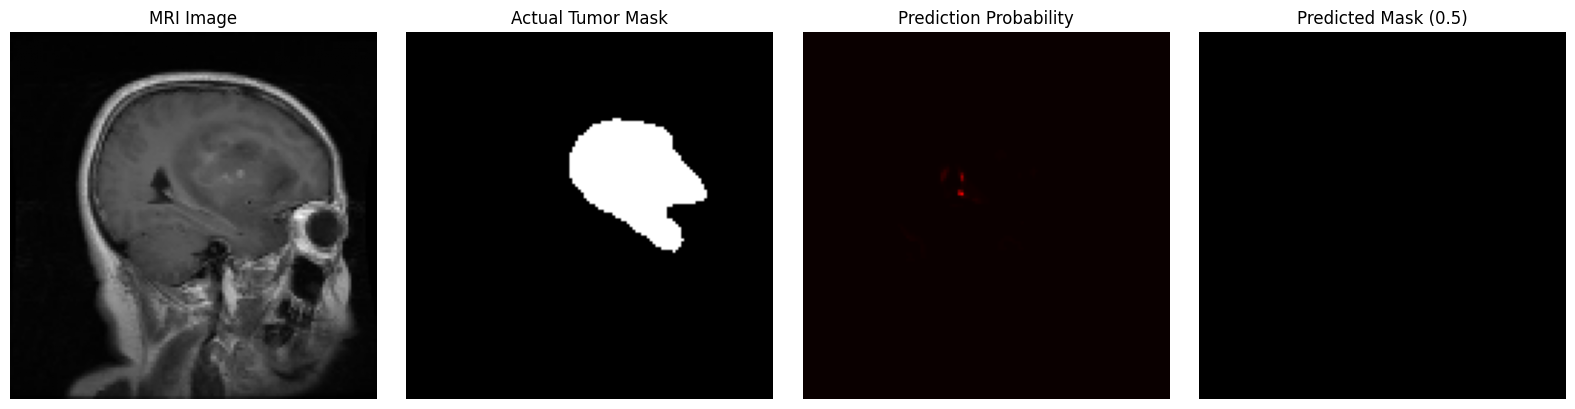

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 4, figsize=(16, 4))

ax[0].imshow(image, cmap="gray")
ax[0].set_title("MRI Image")

ax[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Actual Tumor Mask")

ax[2].imshow(prediction, cmap="hot", vmin=0, vmax=1)
ax[2].set_title("Prediction Probability")

ax[3].imshow(predicted_mask, cmap="gray", vmin=0, vmax=1)
ax[3].set_title("Predicted Mask (0.5)")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
print("Image shape:", image.shape)
print("Image minimum:", float(image.min()))
print("Image maximum:", float(image.max()))

print("Mask shape:", mask.shape)
print("Mask unique values:", np.unique(mask))

print("Prediction shape:", prediction.shape)
print("Prediction minimum:", float(prediction.min()))
print("Prediction maximum:", float(prediction.max()))
print("Prediction mean:", float(prediction.mean()))

Image shape: (128, 128)
Image minimum: 0.0
Image maximum: 0.9764705882352941
Mask shape: (128, 128)
Mask unique values: [0. 1.]
Prediction shape: (128, 128)
Prediction minimum: 0.0
Prediction maximum: 0.3455342948436737
Prediction mean: 0.0004037359030917287


Training filename: brisc2025_train_00001_gl_ax_t1.jpg
Original shape: (512, 512)
Original range: 0 255
Resized shape: (128, 128)
Normalized range: 0.0 0.92941177


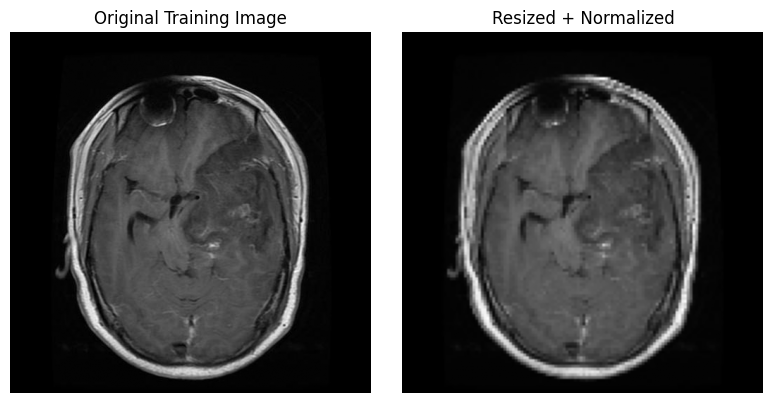

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Ek training image select karo
train_name = sorted(os.listdir(SEG_TRAIN_IMAGES))[0]

train_path = os.path.join(SEG_TRAIN_IMAGES, train_name)

train_image = cv2.imread(train_path, cv2.IMREAD_GRAYSCALE)

train_resized = cv2.resize(
    train_image, (128, 128)
).astype(np.float32) / 255.0

print("Training filename:", train_name)
print("Original shape:", train_image.shape)
print("Original range:", train_image.min(), train_image.max())
print("Resized shape:", train_resized.shape)
print("Normalized range:", train_resized.min(), train_resized.max())

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(train_image, cmap="gray")
plt.title("Original Training Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(train_resized, cmap="gray")
plt.title("Resized + Normalized")
plt.axis("off")

plt.tight_layout()
plt.show()

Image exists: True
Mask exists: True
Mask shape: (128, 128)
Mask values: [0 1]
Tumor pixels: 1017


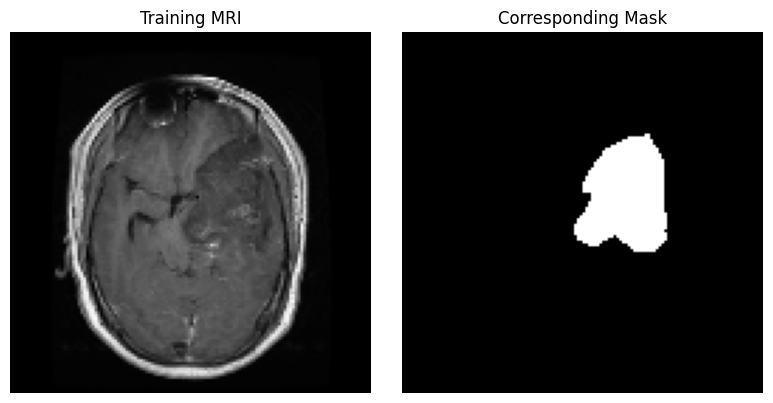

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

train_name = "brisc2025_train_00001_gl_ax_t1.jpg"
train_mask_name = os.path.splitext(train_name)[0] + ".png"

train_image_path = os.path.join(SEG_TRAIN_IMAGES, train_name)
train_mask_path = os.path.join(SEG_TRAIN_MASKS, train_mask_name)

print("Image exists:", os.path.exists(train_image_path))
print("Mask exists:", os.path.exists(train_mask_path))

if os.path.exists(train_mask_path):
    train_mask = cv2.imread(train_mask_path, cv2.IMREAD_GRAYSCALE)
    train_mask = cv2.resize(
        train_mask, (128, 128),
        interpolation=cv2.INTER_NEAREST
    )
    train_mask = (train_mask > 127).astype(np.uint8)

    print("Mask shape:", train_mask.shape)
    print("Mask values:", np.unique(train_mask))
    print("Tumor pixels:", int(train_mask.sum()))

    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(train_resized, cmap="gray")
    plt.title("Training MRI")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(train_mask, cmap="gray")
    plt.title("Corresponding Mask")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

Actual tumor pixels: 1017
Predicted tumor pixels: 78
Training image Dice: 0.0073
Maximum probability: 0.9891


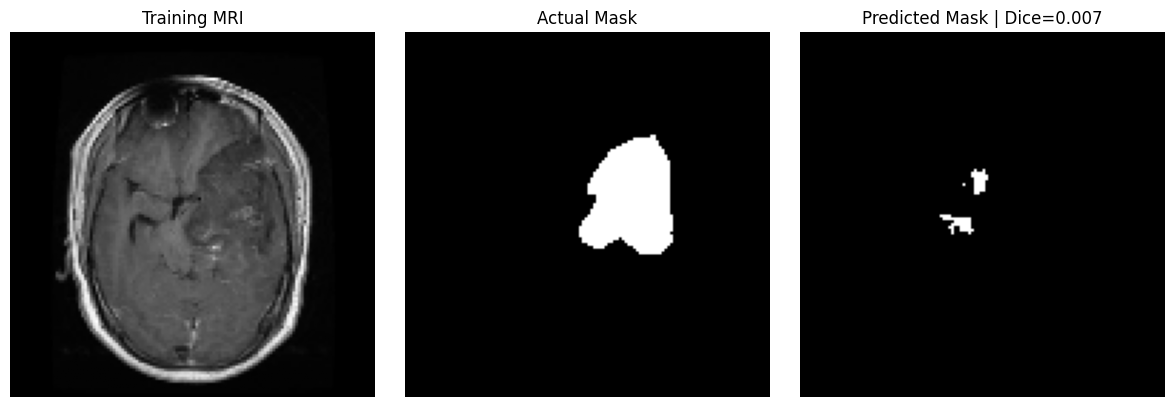

In [ ]:
train_prediction = saved_model.predict(
    train_resized[np.newaxis, ..., np.newaxis],
    verbose=0
)[0, :, :, 0]

train_predicted_mask = (train_prediction >= 0.5).astype(np.uint8)

intersection = np.sum(train_mask * train_predicted_mask)
dice = (
    2 * intersection + 1e-6
) / (
    np.sum(train_mask) + np.sum(train_predicted_mask) + 1e-6
)

print("Actual tumor pixels:", int(train_mask.sum()))
print("Predicted tumor pixels:", int(train_predicted_mask.sum()))
print("Training image Dice:", round(float(dice), 4))
print("Maximum probability:", round(float(train_prediction.max()), 4))

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(train_resized, cmap="gray")
plt.title("Training MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(train_mask, cmap="gray")
plt.title("Actual Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(train_predicted_mask, cmap="gray")
plt.title(f"Predicted Mask | Dice={dice:.3f}")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import cv2
import numpy as np

image_files = sorted(os.listdir(SEG_TRAIN_IMAGES))[:5]

for name in image_files:
    img_path = os.path.join(SEG_TRAIN_IMAGES, name)
    mask_name = os.path.splitext(name)[0] + ".png"
    msk_path = os.path.join(SEG_TRAIN_MASKS, mask_name)

    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    msk = cv2.imread(msk_path, cv2.IMREAD_GRAYSCALE)

    if img is None or msk is None:
        print(name, "- image/mask missing")
        continue

    img = cv2.resize(img, (128, 128)).astype(np.float32) / 255.0
    msk = cv2.resize(
        msk, (128, 128), interpolation=cv2.INTER_NEAREST
    )
    msk = (msk > 127).astype(np.uint8)

    prob = saved_model.predict(
        img[np.newaxis, ..., np.newaxis], verbose=0
    )[0, :, :, 0]

    pred = (prob >= 0.5).astype(np.uint8)
    intersection = np.sum(msk * pred)
    dice = (2 * intersection + 1e-6) / (
        msk.sum() + pred.sum() + 1e-6
    )

    print(
        name,
        "| Actual:", int(msk.sum()),
        "| Predicted:", int(pred.sum()),
        "| Dice:", round(float(dice), 4)
    )

brisc2025_train_00001_gl_ax_t1.jpg | Actual: 1017 | Predicted: 78 | Dice: 0.0073
brisc2025_train_00002_gl_ax_t1.jpg | Actual: 989 | Predicted: 51 | Dice: 0.0
brisc2025_train_00003_gl_ax_t1.jpg | Actual: 173 | Predicted: 181 | Dice: 0.9153
brisc2025_train_00004_gl_ax_t1.jpg | Actual: 145 | Predicted: 106 | Dice: 0.8048
brisc2025_train_00005_gl_ax_t1.jpg | Actual: 227 | Predicted: 79 | Dice: 0.5098


In [ ]:
import os

image_files = {
    os.path.splitext(f)[0]
    for f in os.listdir(SEG_TRAIN_IMAGES)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
}

mask_files = {
    os.path.splitext(f)[0]
    for f in os.listdir(SEG_TRAIN_MASKS)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
}

print("Total image files:", len(image_files))
print("Total mask files:", len(mask_files))
print("Images without matching masks:", len(image_files - mask_files))
print("Masks without matching images:", len(mask_files - image_files))

print("\nFirst unmatched images:", sorted(image_files - mask_files)[:10])
print("First unmatched masks:", sorted(mask_files - image_files)[:10])

Total image files: 3933
Total mask files: 3933
Images without matching masks: 0
Masks without matching images: 0

First unmatched images: []
First unmatched masks: []


In [ ]:
import os
import cv2
import numpy as np

image_files = sorted(os.listdir(SEG_TRAIN_IMAGES))[:10]

for name in image_files:
    img_path = os.path.join(SEG_TRAIN_IMAGES, name)
    mask_path = os.path.join(
        SEG_TRAIN_MASKS,
        os.path.splitext(name)[0] + ".png"
    )

    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    msk = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    img = cv2.resize(img, (128, 128)).astype(np.float32) / 255.0
    msk = cv2.resize(
        msk, (128, 128), interpolation=cv2.INTER_NEAREST
    )
    msk = (msk > 127).astype(np.uint8)

    prob = saved_model.predict(
        img[np.newaxis, ..., np.newaxis], verbose=0
    )[0, :, :, 0]

    pred = (prob >= 0.5).astype(np.uint8)

    intersection = np.sum(msk * pred)
    dice = (2 * intersection + 1e-6) / (
        msk.sum() + pred.sum() + 1e-6
    )

    print(
        name,
        "| Dice:", round(float(dice), 4),
        "| Actual pixels:", int(msk.sum()),
        "| Predicted pixels:", int(pred.sum()),
        "| Max probability:", round(float(prob.max()), 4)
    )

brisc2025_train_00001_gl_ax_t1.jpg | Dice: 0.0073 | Actual pixels: 1017 | Predicted pixels: 78 | Max probability: 0.9891
brisc2025_train_00002_gl_ax_t1.jpg | Dice: 0.0 | Actual pixels: 989 | Predicted pixels: 51 | Max probability: 0.9814
brisc2025_train_00003_gl_ax_t1.jpg | Dice: 0.9153 | Actual pixels: 173 | Predicted pixels: 181 | Max probability: 1.0
brisc2025_train_00004_gl_ax_t1.jpg | Dice: 0.8048 | Actual pixels: 145 | Predicted pixels: 106 | Max probability: 1.0
brisc2025_train_00005_gl_ax_t1.jpg | Dice: 0.5098 | Actual pixels: 227 | Predicted pixels: 79 | Max probability: 0.9992
brisc2025_train_00006_gl_ax_t1.jpg | Dice: 0.0147 | Actual pixels: 217 | Predicted pixels: 56 | Max probability: 0.9944
brisc2025_train_00007_gl_ax_t1.jpg | Dice: 0.1197 | Actual pixels: 538 | Predicted pixels: 214 | Max probability: 0.9994
brisc2025_train_00008_gl_ax_t1.jpg | Dice: 0.6304 | Actual pixels: 617 | Predicted pixels: 284 | Max probability: 0.9993
brisc2025_train_00009_gl_ax_t1.jpg | Dice: 0

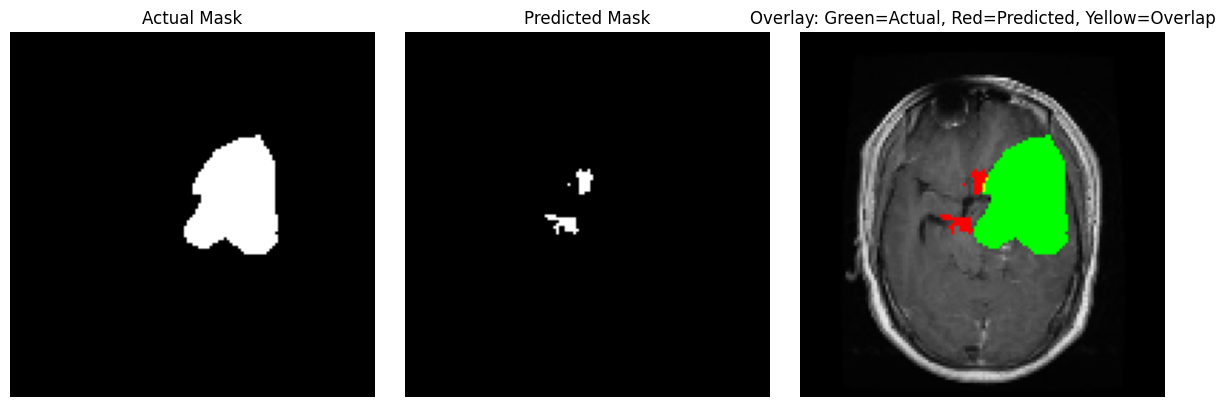

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

name = "brisc2025_train_00001_gl_ax_t1.jpg"

img = cv2.imread(
    os.path.join(SEG_TRAIN_IMAGES, name),
    cv2.IMREAD_GRAYSCALE
)
msk = cv2.imread(
    os.path.join(
        SEG_TRAIN_MASKS,
        os.path.splitext(name)[0] + ".png"
    ),
    cv2.IMREAD_GRAYSCALE
)

img = cv2.resize(img, (128, 128)).astype(np.float32) / 255.0
msk = cv2.resize(
    msk, (128, 128), interpolation=cv2.INTER_NEAREST
)
msk = (msk > 127).astype(np.uint8)

prob = saved_model.predict(
    img[np.newaxis, ..., np.newaxis], verbose=0
)[0, :, :, 0]
pred = (prob >= 0.5).astype(np.uint8)

# Overlay: green = actual mask, red = predicted mask
overlay = np.stack([img, img, img], axis=-1)
overlay[msk == 1] = [0, 1, 0]
overlay[pred == 1] = [1, 0, 0]
overlay[(msk == 1) & (pred == 1)] = [1, 1, 0]

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(msk, cmap="gray")
plt.title("Actual Mask")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(pred, cmap="gray")
plt.title("Predicted Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Overlay: Green=Actual, Red=Predicted, Yellow=Overlap")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf
import numpy as np

project_path = "/content/drive/MyDrive/Brain_Tumor_Project"

model_a = tf.keras.models.load_model(
    project_path + "/unet_per_image_dice.keras",
    compile=False
)

model_b = tf.keras.models.load_model(
    project_path + "/best_unet_segmentation.keras",
    compile=False
)

test_input = train_resized[np.newaxis, ..., np.newaxis]

pred_a = model_a.predict(test_input, verbose=0)
pred_b = model_b.predict(test_input, verbose=0)

print("Model A output shape:", pred_a.shape)
print("Model B output shape:", pred_b.shape)
print("Maximum absolute prediction difference:",
      float(np.max(np.abs(pred_a - pred_b))))
print("Mean absolute prediction difference:",
      float(np.mean(np.abs(pred_a - pred_b))))

Model A output shape: (1, 128, 128, 1)
Model B output shape: (1, 128, 128, 1)
Maximum absolute prediction difference: 0.9628642797470093
Mean absolute prediction difference: 0.00923854298889637


In [ ]:
import numpy as np

def evaluate_prediction(model, img, msk):
    prob = model.predict(
        img[np.newaxis, ..., np.newaxis], verbose=0
    )[0, :, :, 0]

    pred = (prob >= 0.5).astype(np.uint8)
    intersection = np.sum(msk * pred)

    dice = (2 * intersection + 1e-6) / (
        np.sum(msk) + np.sum(pred) + 1e-6
    )

    return {
        "dice": float(dice),
        "predicted_pixels": int(pred.sum()),
        "max_probability": float(prob.max()),
        "mean_probability": float(prob.mean())
    }

result_a = evaluate_prediction(model_a, train_resized, train_mask)
result_b = evaluate_prediction(model_b, train_resized, train_mask)

print("Model A: unet_per_image_dice.keras")
print(result_a)

print("\nModel B: best_unet_segmentation.keras")
print(result_b)

Model A: unet_per_image_dice.keras
{'dice': 0.0073059369796292795, 'predicted_pixels': 78, 'max_probability': 0.9890957474708557, 'mean_probability': 0.00556599348783493}

Model B: best_unet_segmentation.keras
{'dice': 0.01651527744300968, 'predicted_pixels': 194, 'max_probability': 0.992572546005249, 'mean_probability': 0.01204912643879652}


In [ ]:
import os

base_path = "/content/brisc_data/brisc2025"

VAL_IMAGES = os.path.join(
    base_path, "segmentation_task", "train", "images"
)
VAL_MASKS = os.path.join(
    base_path, "segmentation_task", "train", "masks"
)

print("Training images available:", os.path.isdir(VAL_IMAGES))
print("Training masks available:", os.path.isdir(VAL_MASKS))

Training images available: True
Training masks available: True


In [ ]:
import os

project_path = "/content/drive/MyDrive/Brain_Tumor_Project"

print("Project folder files:")
for name in os.listdir(project_path):
    print(name)

print("\nPossible saved split or validation files:")
for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for name in files:
        lower = name.lower()
        if any(term in lower for term in [
            "x_val", "y_val", "validation", "val_indices",
            "split_indices", "train_test_split"
        ]):
            print(os.path.join(root, name))

Project folder files:
best_classweighted_cnn.keras
training_history.json
classification_report.txt
best_unet_segmentation.keras
segmentation_test_evaluation.csv
tumor_size_location_estimates.csv
unet_error_analysis.csv
threshold_comparison_evaluation.csv
one_image_integration_test.csv
best_brain_tumor_cnn.keras
best_mobilenetv2.keras
unet_before_retraining.keras
fresh_test_evaluation.csv
unet_per_image_dice.keras

Possible saved split or validation files:


In [ ]:
import os
import pandas as pd

project_path = "/content/drive/MyDrive/Brain_Tumor_Project"

csv_path = os.path.join(project_path, "unet_error_analysis.csv")

df_errors = pd.read_csv(csv_path)

print("Shape:", df_errors.shape)
print("\nColumns:")
print(df_errors.columns.tolist())

print("\nFirst 5 rows:")
display(df_errors.head())

print("\nData types:")
print(df_errors.dtypes)

Shape: (860, 9)

Columns:
['image', 'TP', 'FP', 'FN', 'TN', 'Dice', 'IoU', 'Precision', 'Recall']

First 5 rows:


,image,TP,FP,FN,TN,Dice,IoU,Precision,Recall
0,brisc2025_test_00001_gl_ax_t1.jpg,89,125,6,16164,0.576052,0.404545,0.415888,0.936842
1,brisc2025_test_00002_gl_ax_t1.jpg,117,14,44,16209,0.801370,0.668571,0.893130,0.726708
2,brisc2025_test_00003_gl_ax_t1.jpg,25,0,398,15961,0.111607,0.059102,1.000000,0.059102
3,brisc2025_test_00004_gl_ax_t1.jpg,199,156,107,15922,0.602118,0.430736,0.560563,0.650327
4,brisc2025_test_00005_gl_ax_t1.jpg,51,296,54,15983,0.225664,0.127182,0.146974,0.485714



Data types:
image         object
TP             int64
FP             int64
FN             int64
TN             int64
Dice         float64
IoU          float64
Precision    float64
Recall       float64
dtype: object


In [ ]:
import pandas as pd
import os

project_path = "/content/drive/MyDrive/Brain_Tumor_Project"
csv_path = os.path.join(project_path, "unet_error_analysis.csv")

df_errors = pd.read_csv(csv_path)

# Tumor type filename se identify karo
df_errors["tumor_type"] = df_errors["image"].str.extract(
    r"_\d+_(gl|me|pi)_"
)

class_summary = df_errors.groupby("tumor_type").agg(
    images=("image", "count"),
    mean_dice=("Dice", "mean"),
    median_dice=("Dice", "median"),
    mean_iou=("IoU", "mean"),
    mean_precision=("Precision", "mean"),
    mean_recall=("Recall", "mean")
).round(4)

print("Class-wise saved test results:")
display(class_summary)

print("\nOverall mean Dice:", round(df_errors["Dice"].mean(), 4))
print("Images with Dice < 0.5:", int((df_errors["Dice"] < 0.5).sum()))

Class-wise saved test results:


,images,mean_dice,median_dice,mean_iou,mean_precision,mean_recall
tumor_type,,,,,,
gl,254,0.3896,0.3946,0.3107,0.5639,0.4303
me,306,0.8157,0.8828,0.7199,0.7883,0.8908
pi,300,0.7016,0.7742,0.5784,0.6527,0.8452



Overall mean Dice: 0.6501
Images with Dice < 0.5: 208


In [ ]:
import os
import pandas as pd

project_path = "/content/drive/MyDrive/Brain_Tumor_Project"

for filename in [
    "fresh_test_evaluation.csv",
    "segmentation_test_evaluation.csv",
    "threshold_comparison_evaluation.csv"
]:
    path = os.path.join(project_path, filename)

    print("\n" + "=" * 60)
    print("FILE:", filename)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(3))
    else:
        print("File not found")


FILE: fresh_test_evaluation.csv
Shape: (860, 5)
Columns: ['image', 'actual_mask_pixels', 'predicted_mask_pixels', 'dice', 'iou']


,image,actual_mask_pixels,predicted_mask_pixels,dice,iou
0,brisc2025_test_00038_gl_ax_t1.jpg,480,443,0.704225,0.543478
1,brisc2025_test_00394_me_co_t1.jpg,823,631,0.843191,0.728894
2,brisc2025_test_00391_me_ax_t1.jpg,249,284,0.900563,0.819113



FILE: segmentation_test_evaluation.csv
Shape: (860, 6)
Columns: ['image', 'mask', 'actual_mask_pixels', 'predicted_mask_pixels', 'dice', 'iou']


,image,mask,actual_mask_pixels,predicted_mask_pixels,dice,iou
0,brisc2025_test_00001_gl_ax_t1.jpg,brisc2025_test_00001_gl_ax_t1.png,95,214,0.576052,0.404545
1,brisc2025_test_00002_gl_ax_t1.jpg,brisc2025_test_00002_gl_ax_t1.png,161,131,0.801370,0.668571
2,brisc2025_test_00003_gl_ax_t1.jpg,brisc2025_test_00003_gl_ax_t1.png,423,25,0.111607,0.059102



FILE: threshold_comparison_evaluation.csv
Shape: (860, 5)
Columns: ['filename', 'dice_gt0', 'iou_gt0', 'dice_gt127', 'iou_gt127']


,filename,dice_gt0,iou_gt0,dice_gt127,iou_gt127
0,brisc2025_test_00001_gl_ax_t1.jpg,0.576052,0.404545,0.503497,0.336449
1,brisc2025_test_00002_gl_ax_t1.jpg,0.801370,0.668571,0.837037,0.719745
2,brisc2025_test_00003_gl_ax_t1.jpg,0.111607,0.059102,0.129199,0.069061


In [ ]:
import os
import pandas as pd

project_path = "/content/drive/MyDrive/Brain_Tumor_Project"

fresh = pd.read_csv(
    os.path.join(project_path, "fresh_test_evaluation.csv")
)
seg = pd.read_csv(
    os.path.join(project_path, "segmentation_test_evaluation.csv")
)
errors = pd.read_csv(
    os.path.join(project_path, "unet_error_analysis.csv")
)
threshold = pd.read_csv(
    os.path.join(project_path, "threshold_comparison_evaluation.csv")
)

print("Mean Dice scores:")
print("Fresh evaluation:", round(fresh["dice"].mean(), 4))
print("Segmentation evaluation:", round(seg["dice"].mean(), 4))
print("Error analysis:", round(errors["Dice"].mean(), 4))
print("Threshold GT=0:", round(threshold["dice_gt0"].mean(), 4))
print("Threshold GT=127:", round(threshold["dice_gt127"].mean(), 4))

print("\nFresh vs segmentation: matching image names")
print(
    set(fresh["image"]) == set(seg["image"])
)

merged = fresh[["image", "dice"]].merge(
    seg[["image", "dice"]],
    on="image",
    suffixes=("_fresh", "_seg")
)

print("Images matched:", len(merged))
print("Mean absolute Dice difference:",
      round((merged["dice_fresh"] - merged["dice_seg"]).abs().mean(), 4))
print("\nFirst 5 matched rows:")
display(merged.head())

Mean Dice scores:
Fresh evaluation: 0.6497
Segmentation evaluation: 0.6501
Error analysis: 0.6501
Threshold GT=0: 0.6501
Threshold GT=127: 0.6345

Fresh vs segmentation: matching image names
True
Images matched: 860
Mean absolute Dice difference: 0.0109

First 5 matched rows:


,image,dice_fresh,dice_seg
0,brisc2025_test_00038_gl_ax_t1.jpg,0.704225,7.033441e-01
1,brisc2025_test_00394_me_co_t1.jpg,0.843191,8.652291e-01
2,brisc2025_test_00391_me_ax_t1.jpg,0.900563,8.955224e-01
3,brisc2025_test_00287_me_ax_t1.jpg,0.974625,9.738277e-01
4,brisc2025_test_00244_gl_sa_t1.jpg,0.000000,1.776199e-10


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd

test_names = [
    "brisc2025_test_00038_gl_ax_t1.jpg",
    "brisc2025_test_00394_me_co_t1.jpg",
    "brisc2025_test_00391_me_ax_t1.jpg",
    "brisc2025_test_00287_me_ax_t1.jpg",
    "brisc2025_test_00244_gl_sa_t1.jpg"
]

results = []

for name in test_names:
    image_path = os.path.join(SEG_TEST_IMAGES, name)
    mask_path = os.path.join(
        SEG_TEST_MASKS,
        os.path.splitext(name)[0] + ".png"
    )

    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    msk = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    img = cv2.resize(img, (128, 128)).astype(np.float32) / 255.0
    msk = cv2.resize(
        msk, (128, 128), interpolation=cv2.INTER_NEAREST
    )
    msk = (msk > 127).astype(np.uint8)

    row = {"image": name}

    for label, model in [
        ("per_image_dice", model_a),
        ("best_unet", model_b)
    ]:
        prob = model.predict(
            img[np.newaxis, ..., np.newaxis], verbose=0
        )[0, :, :, 0]

        pred = (prob >= 0.5).astype(np.uint8)
        intersection = np.sum(msk * pred)

        dice = (2 * intersection + 1e-6) / (
            msk.sum() + pred.sum() + 1e-6
        )

        row[f"{label}_dice"] = round(float(dice), 4)
        row[f"{label}_predicted_pixels"] = int(pred.sum())

    results.append(row)

display(pd.DataFrame(results))

,image,per_image_dice_dice,per_image_dice_predicted_pixels,best_unet_dice,best_unet_predicted_pixels
0,brisc2025_test_00038_gl_ax_t1.jpg,0.6564,346,0.6613,437
1,brisc2025_test_00394_me_co_t1.jpg,0.7768,482,0.8668,625
2,brisc2025_test_00391_me_ax_t1.jpg,0.9036,240,0.8767,284
3,brisc2025_test_00287_me_ax_t1.jpg,0.9778,1745,0.9714,1840
4,brisc2025_test_00244_gl_sa_t1.jpg,0.0000,0,0.0000,0


Actual tumor pixels: 519
Predicted tumor pixels: 0
Maximum probability: 0.0188
Mean probability: 0.000425


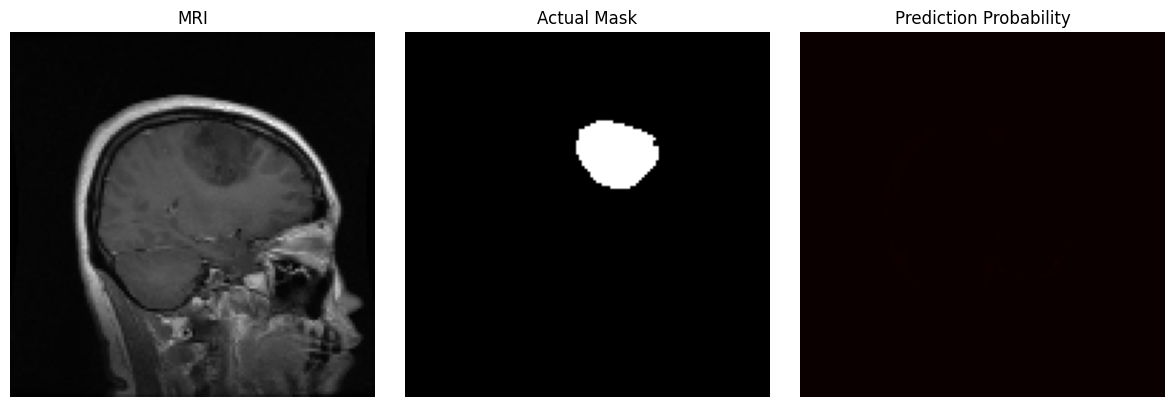

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

name = "brisc2025_test_00244_gl_sa_t1.jpg"

img = cv2.imread(
    os.path.join(SEG_TEST_IMAGES, name),
    cv2.IMREAD_GRAYSCALE
)
msk = cv2.imread(
    os.path.join(
        SEG_TEST_MASKS,
        os.path.splitext(name)[0] + ".png"
    ),
    cv2.IMREAD_GRAYSCALE
)

img = cv2.resize(img, (128, 128)).astype(np.float32) / 255.0
msk = cv2.resize(
    msk, (128, 128), interpolation=cv2.INTER_NEAREST
)
msk = (msk > 127).astype(np.uint8)

prob = model_b.predict(
    img[np.newaxis, ..., np.newaxis], verbose=0
)[0, :, :, 0]

pred = (prob >= 0.5).astype(np.uint8)

print("Actual tumor pixels:", int(msk.sum()))
print("Predicted tumor pixels:", int(pred.sum()))
print("Maximum probability:", round(float(prob.max()), 4))
print("Mean probability:", round(float(prob.mean()), 6))

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(img, cmap="gray")
ax[0].set_title("MRI")
ax[1].imshow(msk, cmap="gray")
ax[1].set_title("Actual Mask")
ax[2].imshow(prob, cmap="hot", vmin=0, vmax=1)
ax[2].set_title("Prediction Probability")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd

results = []

image_names = sorted(os.listdir(SEG_TRAIN_IMAGES))[:10]

for name in image_names:
    img_path = os.path.join(SEG_TRAIN_IMAGES, name)
    mask_path = os.path.join(
        SEG_TRAIN_MASKS,
        os.path.splitext(name)[0] + ".png"
    )

    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    img = cv2.resize(img, (128, 128)).astype(np.float32) / 255.0
    mask = cv2.resize(
        mask, (128, 128),
        interpolation=cv2.INTER_NEAREST
    )
    mask = (mask > 127).astype(np.uint8)

    prob = model_b.predict(
        img[np.newaxis, ..., np.newaxis],
        verbose=0
    )[0, :, :, 0]

    pred = (prob >= 0.5).astype(np.uint8)

    intersection = np.sum(mask * pred)
    dice = (2 * intersection + 1e-6) / (
        mask.sum() + pred.sum() + 1e-6
    )

    results.append({
        "image": name,
        "actual_pixels": int(mask.sum()),
        "predicted_pixels": int(pred.sum()),
        "max_probability": round(float(prob.max()), 4),
        "dice": round(float(dice), 4)
    })

display(pd.DataFrame(results))

,image,actual_pixels,predicted_pixels,max_probability,dice
0,brisc2025_train_00001_gl_ax_t1.jpg,1017,194,0.9926,0.0165
1,brisc2025_train_00002_gl_ax_t1.jpg,989,47,0.9842,0.0000
2,brisc2025_train_00003_gl_ax_t1.jpg,173,293,1.0000,0.7210
3,brisc2025_train_00004_gl_ax_t1.jpg,145,139,1.0000,0.8169
4,brisc2025_train_00005_gl_ax_t1.jpg,227,117,0.9989,0.6395
5,brisc2025_train_00006_gl_ax_t1.jpg,217,105,0.9849,0.0000
6,brisc2025_train_00007_gl_ax_t1.jpg,538,342,0.9996,0.1886
7,brisc2025_train_00008_gl_ax_t1.jpg,617,161,0.9934,0.3959
8,brisc2025_train_00009_gl_ax_t1.jpg,223,56,0.9885,0.0000
9,brisc2025_train_00010_gl_ax_t1.jpg,298,324,0.9999,0.7846


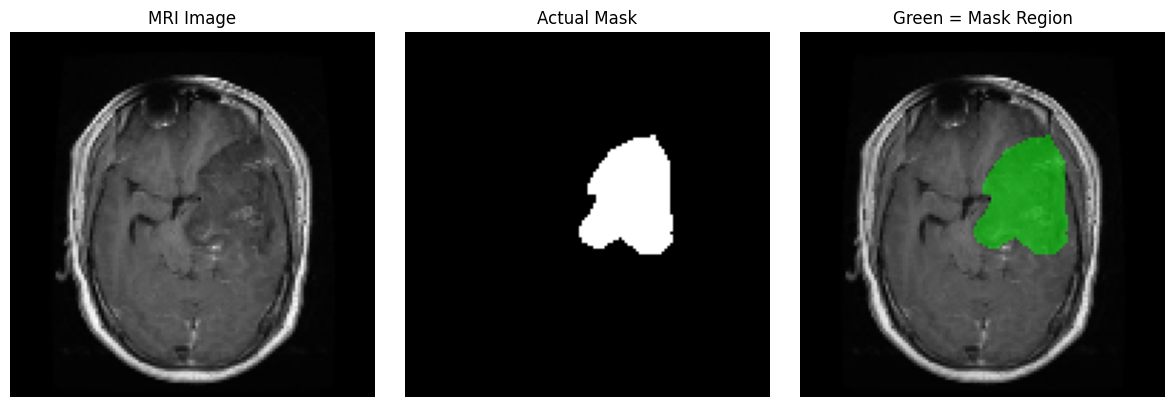

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

name = "brisc2025_train_00001_gl_ax_t1.jpg"

img = cv2.imread(
    os.path.join(SEG_TRAIN_IMAGES, name),
    cv2.IMREAD_GRAYSCALE
)

mask = cv2.imread(
    os.path.join(
        SEG_TRAIN_MASKS,
        os.path.splitext(name)[0] + ".png"
    ),
    cv2.IMREAD_GRAYSCALE
)

img = cv2.resize(img, (128, 128))
mask = cv2.resize(
    mask, (128, 128),
    interpolation=cv2.INTER_NEAREST
)
mask = (mask > 127).astype(np.uint8)

overlay = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
overlay[mask == 1] = (
    0.5 * overlay[mask == 1] + 0.5 * np.array([0, 255, 0])
).astype(np.uint8)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("MRI Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Actual Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Green = Mask Region")
plt.axis("off")

plt.tight_layout()
plt.show()

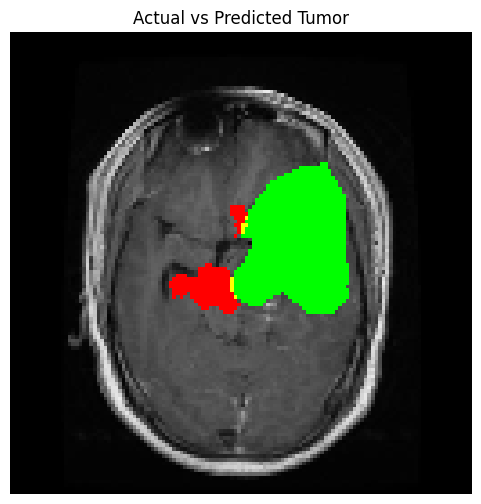

Actual pixels: 1017
Predicted pixels: 194
Overlapping pixels: 10


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

name = "brisc2025_train_00001_gl_ax_t1.jpg"

img = cv2.imread(
    os.path.join(SEG_TRAIN_IMAGES, name),
    cv2.IMREAD_GRAYSCALE
)
img = cv2.resize(img, (128, 128)).astype(np.float32) / 255.0

prob = model_b.predict(
    img[np.newaxis, ..., np.newaxis],
    verbose=0
)[0, :, :, 0]

pred = (prob >= 0.5).astype(np.uint8)

# Green = actual tumor, Red = predicted tumor, Yellow = overlap
overlay = np.stack([img, img, img], axis=-1)

overlay[mask == 1] = [0, 1, 0]
overlay[pred == 1] = [1, 0, 0]
overlay[(mask == 1) & (pred == 1)] = [1, 1, 0]

plt.figure(figsize=(6, 6))
plt.imshow(overlay)
plt.title("Actual vs Predicted Tumor")
plt.axis("off")
plt.show()

print("Actual pixels:", int(mask.sum()))
print("Predicted pixels:", int(pred.sum()))
print("Overlapping pixels:", int(np.sum(mask * pred)))

In [ ]:
import os
import cv2
import numpy as np

name = "brisc2025_train_00001_gl_ax_t1.jpg"

img_path = os.path.join(SEG_TRAIN_IMAGES, name)
mask_path = os.path.join(
    SEG_TRAIN_MASKS,
    os.path.splitext(name)[0] + ".png"
)

raw_img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
raw_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

print("Original image shape:", raw_img.shape)
print("Original mask shape:", raw_mask.shape)
print("Original image range:", raw_img.min(), raw_img.max())
print("Original mask unique values:", np.unique(raw_mask))
print("Original mask foreground pixels:", int((raw_mask > 127).sum()))

resized_mask = cv2.resize(
    raw_mask, (128, 128),
    interpolation=cv2.INTER_NEAREST
)
binary_mask = (resized_mask > 127).astype(np.uint8)

print("\nResized mask shape:", binary_mask.shape)
print("Resized mask unique values:", np.unique(binary_mask))
print("Resized mask foreground pixels:", int(binary_mask.sum()))

Original image shape: (512, 512)
Original mask shape: (512, 512)
Original image range: 0 255
Original mask unique values: [  0   1   2   3   4   5   6   7 248 249 250 251 252 253 254 255]
Original mask foreground pixels: 16345

Resized mask shape: (128, 128)
Resized mask unique values: [0 1]
Resized mask foreground pixels: 1017


In [ ]:
check_names = [
    "X_train", "y_train",
    "X_val", "y_val",
    "X_train_seg", "y_train_seg",
    "train_images", "train_masks",
    "train_ds", "val_ds",
    "train_ds_tl", "val_ds_tl",
    "model", "model_a", "model_b"
]

for name in check_names:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: available | type = {type(obj).__name__}")
        if hasattr(obj, "shape"):
            print("   shape:", obj.shape)
    else:
        print(f"{name}: not available")

X_train: not available
y_train: not available
X_val: not available
y_val: not available
X_train_seg: not available
y_train_seg: not available
train_images: not available
train_masks: not available
train_ds: not available
val_ds: not available
train_ds_tl: not available
val_ds_tl: not available
model: available | type = Functional
model_a: available | type = Functional
model_b: available | type = Functional


In [ ]:
for name, m in [
    ("model", model),
    ("model_a", model_a),
    ("model_b", model_b)
]:
    print(f"\n{name}")
    print("Input shape:", m.input_shape)
    print("Output shape:", m.output_shape)
    print("Number of layers:", len(m.layers))
    print("Total parameters:", m.count_params())


model
Input shape: (None, 128, 128, 1)
Output shape: (None, 128, 128, 1)
Number of layers: 32
Total parameters: 7759521

model_a
Input shape: (None, 128, 128, 1)
Output shape: (None, 128, 128, 1)
Number of layers: 32
Total parameters: 7759521

model_b
Input shape: (None, 128, 128, 1)
Output shape: (None, 128, 128, 1)
Number of layers: 32
Total parameters: 7759521


In [ ]:
for name, m in [
    ("model", model),
    ("model_a", model_a),
    ("model_b", model_b)
]:
    print(f"\n--- {name} ---")
    print("Final layer:", m.layers[-1].name)
    print("Final layer type:", type(m.layers[-1]).__name__)
    print("Final activation:", m.layers[-1].get_config().get("activation"))


--- model ---
Final layer: conv2d_24
Final layer type: Conv2D
Final activation: sigmoid

--- model_a ---
Final layer: conv2d_24
Final layer type: Conv2D
Final activation: sigmoid

--- model_b ---
Final layer: conv2d_24
Final layer type: Conv2D
Final activation: sigmoid


In [ ]:
import numpy as np
import cv2
import os

name = "brisc2025_train_00001_gl_ax_t1.jpg"

img = cv2.imread(
    os.path.join(SEG_TRAIN_IMAGES, name),
    cv2.IMREAD_GRAYSCALE
)
img = cv2.resize(img, (128, 128)).astype(np.float32) / 255.0

prob = model_b.predict(
    img[np.newaxis, ..., np.newaxis],
    verbose=0
)[0, :, :, 0]

print("Minimum probability:", float(prob.min()))
print("Maximum probability:", float(prob.max()))
print("Mean probability:", float(prob.mean()))
print("Median probability:", float(np.median(prob)))

for threshold in [0.1, 0.3, 0.5, 0.7, 0.9]:
    print(
        f"Pixels >= {threshold}:",
        int((prob >= threshold).sum())
    )

Minimum probability: 0.0
Maximum probability: 0.992572546005249
Mean probability: 0.01204912643879652
Median probability: 1.33886703679309e-06
Pixels >= 0.1: 250
Pixels >= 0.3: 223
Pixels >= 0.5: 194
Pixels >= 0.7: 165
Pixels >= 0.9: 116


In [ ]:
import numpy as np

def compare_models(model1, model2):
    weights1 = model1.get_weights()
    weights2 = model2.get_weights()

    differences = [
        np.mean(np.abs(w1 - w2))
        for w1, w2 in zip(weights1, weights2)
        if w1.size > 0
    ]

    print("Same number of weight arrays:", len(weights1) == len(weights2))
    print("Mean absolute weight difference:",
          float(np.mean(differences)) if differences else 0.0)

print("model vs model_a")
compare_models(model, model_a)

print("\nmodel_a vs model_b")
compare_models(model_a, model_b)

model vs model_a
Same number of weight arrays: True
Mean absolute weight difference: 0.0014192545786499977

model_a vs model_b
Same number of weight arrays: True
Mean absolute weight difference: 0.0014192545786499977


In [ ]:
import numpy as np

def exact_weight_check(name1, m1, name2, m2):
    w1 = m1.get_weights()
    w2 = m2.get_weights()

    same_arrays = [
        np.array_equal(a, b)
        for a, b in zip(w1, w2)
    ]

    print(f"\n{name1} vs {name2}")
    print("All weights exactly equal:", all(same_arrays))
    print("Different weight arrays:", sum(not x for x in same_arrays))
    print("Total weight arrays:", len(same_arrays))

exact_weight_check("model", model, "model_a", model_a)
exact_weight_check("model_a", model_a, "model_b", model_b)
exact_weight_check("model", model, "model_b", model_b)


model vs model_a
All weights exactly equal: False
Different weight arrays: 46
Total weight arrays: 46

model_a vs model_b
All weights exactly equal: False
Different weight arrays: 46
Total weight arrays: 46

model vs model_b
All weights exactly equal: True
Different weight arrays: 0
Total weight arrays: 46


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd

results = []

image_names = sorted(os.listdir(SEG_TRAIN_IMAGES))[:10]

for name in image_names:
    mask_path = os.path.join(
        SEG_TRAIN_MASKS,
        os.path.splitext(name)[0] + ".png"
    )

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    original_pixels = int((mask > 127).sum())

    resized = cv2.resize(
        mask, (128, 128),
        interpolation=cv2.INTER_NEAREST
    )
    resized_pixels = int((resized > 127).sum())

    results.append({
        "image": name,
        "original_mask_pixels": original_pixels,
        "resized_mask_pixels": resized_pixels,
        "foreground_retained_percent": round(
            100 * resized_pixels / original_pixels, 2
        ) if original_pixels else 0
    })

display(pd.DataFrame(results))

,image,original_mask_pixels,resized_mask_pixels,foreground_retained_percent
0,brisc2025_train_00001_gl_ax_t1.jpg,16345,1017,6.22
1,brisc2025_train_00002_gl_ax_t1.jpg,15797,989,6.26
2,brisc2025_train_00003_gl_ax_t1.jpg,2742,173,6.31
3,brisc2025_train_00004_gl_ax_t1.jpg,2293,145,6.32
4,brisc2025_train_00005_gl_ax_t1.jpg,3586,227,6.33
5,brisc2025_train_00006_gl_ax_t1.jpg,3439,217,6.31
6,brisc2025_train_00007_gl_ax_t1.jpg,8588,538,6.26
7,brisc2025_train_00008_gl_ax_t1.jpg,9876,617,6.25
8,brisc2025_train_00009_gl_ax_t1.jpg,3559,223,6.27
9,brisc2025_train_00010_gl_ax_t1.jpg,4705,298,6.33


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd

results = []

image_names = sorted(os.listdir(SEG_TRAIN_IMAGES))[:10]

for name in image_names:
    img_path = os.path.join(SEG_TRAIN_IMAGES, name)
    mask_path = os.path.join(
        SEG_TRAIN_MASKS,
        os.path.splitext(name)[0] + ".png"
    )

    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    resized_img = cv2.resize(img, (128, 128))
    resized_mask = cv2.resize(
        mask, (128, 128),
        interpolation=cv2.INTER_NEAREST
    )

    binary_mask = (resized_mask > 127).astype(np.uint8)

    results.append({
        "image": name,
        "image_shape": str(img.shape),
        "mask_shape": str(mask.shape),
        "mask_min": int(mask.min()),
        "mask_max": int(mask.max()),
        "foreground_pixels": int(binary_mask.sum()),
        "foreground_fraction": round(float(binary_mask.mean()), 4)
    })

display(pd.DataFrame(results))

,image,image_shape,mask_shape,mask_min,mask_max,foreground_pixels,foreground_fraction
0,brisc2025_train_00001_gl_ax_t1.jpg,"(512, 512)","(512, 512)",0,255,1017,0.0621
1,brisc2025_train_00002_gl_ax_t1.jpg,"(512, 512)","(512, 512)",0,255,989,0.0604
2,brisc2025_train_00003_gl_ax_t1.jpg,"(512, 512)","(512, 512)",0,255,173,0.0106
3,brisc2025_train_00004_gl_ax_t1.jpg,"(512, 512)","(512, 512)",0,255,145,0.0089
4,brisc2025_train_00005_gl_ax_t1.jpg,"(512, 512)","(512, 512)",0,255,227,0.0139
5,brisc2025_train_00006_gl_ax_t1.jpg,"(512, 512)","(512, 512)",0,255,217,0.0132
6,brisc2025_train_00007_gl_ax_t1.jpg,"(512, 512)","(512, 512)",0,255,538,0.0328
7,brisc2025_train_00008_gl_ax_t1.jpg,"(512, 512)","(512, 512)",0,255,617,0.0377
8,brisc2025_train_00009_gl_ax_t1.jpg,"(512, 512)","(512, 512)",0,255,223,0.0136
9,brisc2025_train_00010_gl_ax_t1.jpg,"(512, 512)","(512, 512)",0,255,298,0.0182


In [ ]:
import json
import os

history_path = "/content/drive/MyDrive/Brain_Tumor_Project/training_history.json"

print("Training history file exists:", os.path.exists(history_path))

if os.path.exists(history_path):
    with open(history_path, "r") as f:
        history = json.load(f)

    print("Stored keys:", list(history.keys()))

    for key, value in history.items():
        if isinstance(value, list):
            print(f"{key}: {len(value)} epochs")
            print("  First 3 values:", value[:3])
            print("  Last 3 values:", value[-3:])
        else:
            print(f"{key}: {value}")

Training history file exists: True
Stored keys: ['accuracy', 'loss', 'val_accuracy', 'val_loss']
accuracy: 13 epochs
  First 3 values: [0.43024998903274536, 0.5882499814033508, 0.6679999828338623]
  Last 3 values: [0.7572500109672546, 0.765500009059906, 0.7645000219345093]
loss: 13 epochs
  First 3 values: [1.2627196311950684, 1.0022422075271606, 0.8356956839561462]
  Last 3 values: [0.59319007396698, 0.5691670179367065, 0.5588055849075317]
val_accuracy: 13 epochs
  First 3 values: [0.5419999957084656, 0.671999990940094, 0.7080000042915344]
  Last 3 values: [0.6449999809265137, 0.7480000257492065, 0.7580000162124634]
val_loss: 13 epochs
  First 3 values: [1.116662621498108, 0.7642857432365417, 0.704582691192627]
  Last 3 values: [0.9197227358818054, 0.6508830785751343, 0.5999250411987305]


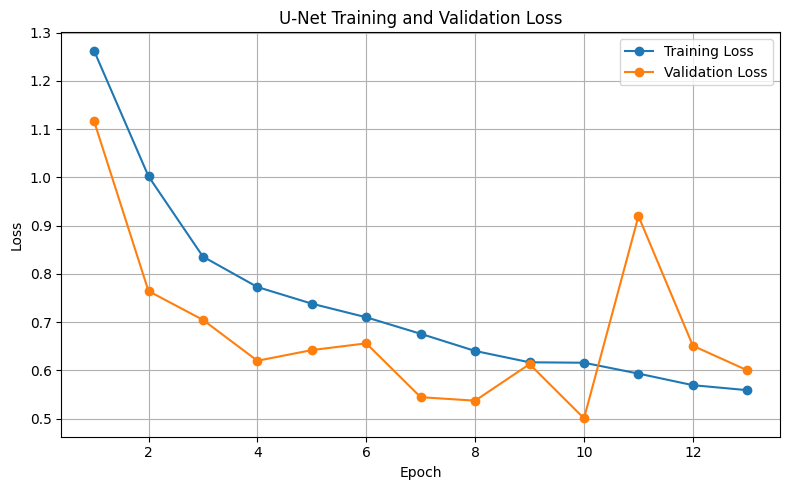

In [ ]:
import json
import matplotlib.pyplot as plt

history_path = "/content/drive/MyDrive/Brain_Tumor_Project/training_history.json"

with open(history_path, "r") as f:
    history = json.load(f)

epochs = range(1, len(history["loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["loss"], marker="o", label="Training Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("U-Net Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import os
import pandas as pd

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"

for filename in [
    "segmentation_test_evaluation.csv",
    "unet_error_analysis.csv",
    "fresh_test_evaluation.csv"
]:
    path = os.path.join(project_dir, filename)

    print(f"\n--- {filename} ---")

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(3))
    else:
        print("File not found")


--- segmentation_test_evaluation.csv ---
Shape: (860, 6)
Columns: ['image', 'mask', 'actual_mask_pixels', 'predicted_mask_pixels', 'dice', 'iou']


,image,mask,actual_mask_pixels,predicted_mask_pixels,dice,iou
0,brisc2025_test_00001_gl_ax_t1.jpg,brisc2025_test_00001_gl_ax_t1.png,95,214,0.576052,0.404545
1,brisc2025_test_00002_gl_ax_t1.jpg,brisc2025_test_00002_gl_ax_t1.png,161,131,0.801370,0.668571
2,brisc2025_test_00003_gl_ax_t1.jpg,brisc2025_test_00003_gl_ax_t1.png,423,25,0.111607,0.059102



--- unet_error_analysis.csv ---
Shape: (860, 9)
Columns: ['image', 'TP', 'FP', 'FN', 'TN', 'Dice', 'IoU', 'Precision', 'Recall']


,image,TP,FP,FN,TN,Dice,IoU,Precision,Recall
0,brisc2025_test_00001_gl_ax_t1.jpg,89,125,6,16164,0.576052,0.404545,0.415888,0.936842
1,brisc2025_test_00002_gl_ax_t1.jpg,117,14,44,16209,0.801370,0.668571,0.893130,0.726708
2,brisc2025_test_00003_gl_ax_t1.jpg,25,0,398,15961,0.111607,0.059102,1.000000,0.059102



--- fresh_test_evaluation.csv ---
Shape: (860, 5)
Columns: ['image', 'actual_mask_pixels', 'predicted_mask_pixels', 'dice', 'iou']


,image,actual_mask_pixels,predicted_mask_pixels,dice,iou
0,brisc2025_test_00038_gl_ax_t1.jpg,480,443,0.704225,0.543478
1,brisc2025_test_00394_me_co_t1.jpg,823,631,0.843191,0.728894
2,brisc2025_test_00391_me_ax_t1.jpg,249,284,0.900563,0.819113


In [ ]:
print("Available columns:")
print(comparison.columns.tolist())

display(comparison[
    [
        "image",
        "dice_old",
        "dice_fresh",
        "predicted_mask_pixels_old",
        "predicted_mask_pixels_fresh"
    ]
].head(10))

Available columns:
['image', 'mask', 'actual_mask_pixels_old', 'predicted_mask_pixels_old', 'dice_old', 'iou_old', 'actual_mask_pixels_fresh', 'predicted_mask_pixels_fresh', 'dice_fresh', 'iou_fresh']


,image,dice_old,dice_fresh,predicted_mask_pixels_old,predicted_mask_pixels_fresh
0,brisc2025_test_00001_gl_ax_t1.jpg,5.760518e-01,0.479532,214,247
1,brisc2025_test_00002_gl_ax_t1.jpg,8.013699e-01,0.769784,131,117
2,brisc2025_test_00003_gl_ax_t1.jpg,1.116071e-01,0.107383,25,24
3,brisc2025_test_00004_gl_ax_t1.jpg,6.021180e-01,0.610329,355,333
4,brisc2025_test_00005_gl_ax_t1.jpg,2.256637e-01,0.010000,347,295
5,brisc2025_test_00006_gl_ax_t1.jpg,1.190476e-10,0.000000,496,481
6,brisc2025_test_00007_gl_ax_t1.jpg,2.600000e-01,0.225664,340,392
7,brisc2025_test_00008_gl_ax_t1.jpg,7.701493e-01,0.757835,192,208
8,brisc2025_test_00009_gl_ax_t1.jpg,1.280410e-10,0.000000,145,140
9,brisc2025_test_00010_gl_ax_t1.jpg,2.597403e-10,0.000000,316,311


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd

name = "brisc2025_test_00005_gl_ax_t1.jpg"
project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"

img_path = os.path.join(SEG_TEST_IMAGES, name)
mask_path = os.path.join(
    SEG_TEST_MASKS,
    os.path.splitext(name)[0] + ".png"
)

img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

img = cv2.resize(img, (128, 128)).astype(np.float32) / 255.0
mask = cv2.resize(
    mask, (128, 128), interpolation=cv2.INTER_NEAREST
)
mask = (mask > 127).astype(np.uint8)

prob = model_b.predict(
    img[np.newaxis, ..., np.newaxis], verbose=0
)[0, :, :, 0]

pred = (prob >= 0.5).astype(np.uint8)

intersection = int(np.sum(mask * pred))
dice = (2 * intersection + 1e-6) / (
    mask.sum() + pred.sum() + 1e-6
)

old_df = pd.read_csv(
    os.path.join(project_dir, "segmentation_test_evaluation.csv")
)
fresh_df = pd.read_csv(
    os.path.join(project_dir, "fresh_test_evaluation.csv")
)

print("Current model:", "model_b")
print("Current actual pixels:", int(mask.sum()))
print("Current predicted pixels:", int(pred.sum()))
print("Current Dice:", round(float(dice), 6))

print("\nSaved segmentation CSV:")
display(old_df.loc[old_df["image"] == name])

print("\nSaved fresh evaluation CSV:")
display(fresh_df.loc[fresh_df["image"] == name])

Current model: model_b
Current actual pixels: 70
Current predicted pixels: 295
Current Dice: 0.0

Saved segmentation CSV:


,image,mask,actual_mask_pixels,predicted_mask_pixels,dice,iou
4,brisc2025_test_00005_gl_ax_t1.jpg,brisc2025_test_00005_gl_ax_t1.png,105,347,0.225664,0.127182



Saved fresh evaluation CSV:


,image,actual_mask_pixels,predicted_mask_pixels,dice,iou
332,brisc2025_test_00005_gl_ax_t1.jpg,105,295,0.01,0.005025


In [ ]:
import os
import cv2
import numpy as np

name = "brisc2025_test_00005_gl_ax_t1.jpg"
mask_path = os.path.join(
    SEG_TEST_MASKS,
    os.path.splitext(name)[0] + ".png"
)

raw_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

nearest = cv2.resize(
    raw_mask, (128, 128),
    interpolation=cv2.INTER_NEAREST
)

linear = cv2.resize(
    raw_mask, (128, 128),
    interpolation=cv2.INTER_LINEAR
)

print("Original shape:", raw_mask.shape)
print("Original pixels >127:", int((raw_mask > 127).sum()))
print("Nearest resize pixels >127:", int((nearest > 127).sum()))
print("Linear resize pixels >127:", int((linear > 127).sum()))

print("Nearest unique values:", np.unique(nearest))
print("Linear unique values:", np.unique(linear))

Original shape: (512, 512)
Original pixels >127: 1192
Nearest resize pixels >127: 70
Linear resize pixels >127: 75
Nearest unique values: [  0   1   2   3   4 250 251 252 253 254 255]
Linear unique values: [  0   1   2  64  65 127 128 190 191 192 254 255]


In [ ]:
import cv2
import numpy as np
import os

name = "brisc2025_test_00005_gl_ax_t1.jpg"
mask_path = os.path.join(
    SEG_TEST_MASKS,
    os.path.splitext(name)[0] + ".png"
)

raw_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

for interpolation_name, method in [
    ("nearest", cv2.INTER_NEAREST),
    ("linear", cv2.INTER_LINEAR),
    ("area", cv2.INTER_AREA)
]:
    resized = cv2.resize(raw_mask, (128, 128), interpolation=method)

    print(f"\n{interpolation_name}:")
    for threshold in [1, 50, 100, 127, 128, 200, 250]:
        count = int((resized > threshold).sum())
        print(f"  threshold > {threshold}: {count} pixels")


nearest:
  threshold > 1: 84 pixels
  threshold > 50: 70 pixels
  threshold > 100: 70 pixels
  threshold > 127: 70 pixels
  threshold > 128: 70 pixels
  threshold > 200: 70 pixels
  threshold > 250: 69 pixels

linear:
  threshold > 1: 91 pixels
  threshold > 50: 83 pixels
  threshold > 100: 76 pixels
  threshold > 127: 75 pixels
  threshold > 128: 72 pixels
  threshold > 200: 65 pixels
  threshold > 250: 65 pixels

area:
  threshold > 1: 103 pixels
  threshold > 50: 91 pixels
  threshold > 100: 76 pixels
  threshold > 127: 74 pixels
  threshold > 128: 72 pixels
  threshold > 200: 60 pixels
  threshold > 250: 47 pixels


In [ ]:
import os

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"

for root, dirs, files in os.walk(project_dir):
    dirs[:] = [d for d in dirs if d not in [".ipynb_checkpoints"]]

    for filename in files:
        if filename.endswith((".py", ".ipynb")):
            print(os.path.join(root, filename))

In [ ]:
import os

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"

print("Project folder exists:", os.path.exists(project_dir))

if os.path.exists(project_dir):
    for filename in os.listdir(project_dir):
        print(filename)

Project folder exists: True
best_classweighted_cnn.keras
training_history.json
classification_report.txt
best_unet_segmentation.keras
segmentation_test_evaluation.csv
tumor_size_location_estimates.csv
unet_error_analysis.csv
threshold_comparison_evaluation.csv
one_image_integration_test.csv
best_brain_tumor_cnn.keras
best_mobilenetv2.keras
unet_before_retraining.keras
fresh_test_evaluation.csv
unet_per_image_dice.keras


In [ ]:
import pandas as pd
import os

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"

old_df = pd.read_csv(
    os.path.join(project_dir, "segmentation_test_evaluation.csv")
)

fresh_df = pd.read_csv(
    os.path.join(project_dir, "fresh_test_evaluation.csv")
)

print("Old CSV shape:", old_df.shape)
print("Fresh CSV shape:", fresh_df.shape)

print("\nOld CSV columns:")
print(old_df.columns.tolist())

print("\nFresh CSV columns:")
print(fresh_df.columns.tolist())

print("\nOld CSV first 5 rows:")
display(old_df.head())

print("\nFresh CSV first 5 rows:")
display(fresh_df.head())

Old CSV shape: (860, 6)
Fresh CSV shape: (860, 5)

Old CSV columns:
['image', 'mask', 'actual_mask_pixels', 'predicted_mask_pixels', 'dice', 'iou']

Fresh CSV columns:
['image', 'actual_mask_pixels', 'predicted_mask_pixels', 'dice', 'iou']

Old CSV first 5 rows:


,image,mask,actual_mask_pixels,predicted_mask_pixels,dice,iou
0,brisc2025_test_00001_gl_ax_t1.jpg,brisc2025_test_00001_gl_ax_t1.png,95,214,0.576052,0.404545
1,brisc2025_test_00002_gl_ax_t1.jpg,brisc2025_test_00002_gl_ax_t1.png,161,131,0.801370,0.668571
2,brisc2025_test_00003_gl_ax_t1.jpg,brisc2025_test_00003_gl_ax_t1.png,423,25,0.111607,0.059102
3,brisc2025_test_00004_gl_ax_t1.jpg,brisc2025_test_00004_gl_ax_t1.png,306,355,0.602118,0.430736
4,brisc2025_test_00005_gl_ax_t1.jpg,brisc2025_test_00005_gl_ax_t1.png,105,347,0.225664,0.127182



Fresh CSV first 5 rows:


,image,actual_mask_pixels,predicted_mask_pixels,dice,iou
0,brisc2025_test_00038_gl_ax_t1.jpg,480,443,0.704225,0.543478
1,brisc2025_test_00394_me_co_t1.jpg,823,631,0.843191,0.728894
2,brisc2025_test_00391_me_ax_t1.jpg,249,284,0.900563,0.819113
3,brisc2025_test_00287_me_ax_t1.jpg,1825,1840,0.974625,0.950506
4,brisc2025_test_00244_gl_sa_t1.jpg,563,0,0.000000,0.000000


In [ ]:
import pandas as pd
import os

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"

old_df = pd.read_csv(
    os.path.join(project_dir, "segmentation_test_evaluation.csv")
)

fresh_df = pd.read_csv(
    os.path.join(project_dir, "fresh_test_evaluation.csv")
)

# Dono CSVs ko image filename ke basis par match karna
merged_df = old_df.merge(
    fresh_df,
    on="image",
    how="inner",
    suffixes=("_old", "_fresh")
)

print("Matched images:", len(merged_df))

print("\nFirst 10 matched images:")
display(
    merged_df[
        [
            "image",
            "actual_mask_pixels_old",
            "actual_mask_pixels_fresh",
            "predicted_mask_pixels_old",
            "predicted_mask_pixels_fresh",
            "dice_old",
            "dice_fresh"
        ]
    ].head(10)
)

print("\nActual mask counts different:",
      (merged_df["actual_mask_pixels_old"] !=
       merged_df["actual_mask_pixels_fresh"]).sum())

print("Predicted mask counts different:",
      (merged_df["predicted_mask_pixels_old"] !=
       merged_df["predicted_mask_pixels_fresh"]).sum())

Matched images: 860

First 10 matched images:


,image,actual_mask_pixels_old,actual_mask_pixels_fresh,predicted_mask_pixels_old,predicted_mask_pixels_fresh,dice_old,dice_fresh
0,brisc2025_test_00001_gl_ax_t1.jpg,95,95,214,247,5.760518e-01,0.479532
1,brisc2025_test_00002_gl_ax_t1.jpg,161,161,131,117,8.013699e-01,0.769784
2,brisc2025_test_00003_gl_ax_t1.jpg,423,423,25,24,1.116071e-01,0.107383
3,brisc2025_test_00004_gl_ax_t1.jpg,306,306,355,333,6.021180e-01,0.610329
4,brisc2025_test_00005_gl_ax_t1.jpg,105,105,347,295,2.256637e-01,0.010000
5,brisc2025_test_00006_gl_ax_t1.jpg,344,344,496,481,1.190476e-10,0.000000
6,brisc2025_test_00007_gl_ax_t1.jpg,60,60,340,392,2.600000e-01,0.225664
7,brisc2025_test_00008_gl_ax_t1.jpg,143,143,192,208,7.701493e-01,0.757835
8,brisc2025_test_00009_gl_ax_t1.jpg,636,636,145,140,1.280410e-10,0.000000
9,brisc2025_test_00010_gl_ax_t1.jpg,69,69,316,311,2.597403e-10,0.000000



Actual mask counts different: 0
Predicted mask counts different: 747


In [ ]:
import cv2
import numpy as np
import os

name = "brisc2025_test_00005_gl_ax_t1.jpg"
img_path = os.path.join(SEG_TEST_IMAGES, name)

img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
img = cv2.resize(img, (128, 128)).astype(np.float32) / 255.0
x = img[np.newaxis, ..., np.newaxis]

for model_name, current_model in [
    ("model_a", model_a),
    ("model_b", model_b)
]:
    prob = current_model.predict(x, verbose=0)[0, :, :, 0]
    pred = (prob >= 0.5).astype(np.uint8)

    print(f"\n{model_name}")
    print("Predicted pixels:", int(pred.sum()))
    print("Maximum probability:", float(prob.max()))
    print("Mean probability:", float(prob.mean()))


model_a
Predicted pixels: 250
Maximum probability: 0.9999625086784363
Mean probability: 0.015432890504598618

model_b
Predicted pixels: 295
Maximum probability: 0.9999749660491943
Mean probability: 0.018039515241980553


In [ ]:
import cv2
import numpy as np
import os

name = "brisc2025_test_00005_gl_ax_t1.jpg"

img_path = os.path.join(SEG_TEST_IMAGES, name)
mask_path = os.path.join(
    SEG_TEST_MASKS,
    os.path.splitext(name)[0] + ".png"
)

img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

img = cv2.resize(img, (128, 128)).astype(np.float32) / 255.0
mask = cv2.resize(
    mask, (128, 128), interpolation=cv2.INTER_NEAREST
)
actual = (mask > 127).astype(np.uint8)

x = img[np.newaxis, ..., np.newaxis]

print("Actual mask pixels:", int(actual.sum()))

for model_name, current_model in [
    ("model_a", model_a),
    ("model_b", model_b)
]:
    prob = current_model.predict(x, verbose=0)[0, :, :, 0]
    pred = (prob >= 0.5).astype(np.uint8)

    intersection = int(np.sum(actual * pred))
    dice = (2 * intersection) / (int(actual.sum()) + int(pred.sum()) + 1e-7)

    print(f"\n{model_name}")
    print("Predicted pixels:", int(pred.sum()))
    print("Overlap pixels:", intersection)
    print("Dice score:", round(float(dice), 4))

Actual mask pixels: 70

model_a
Predicted pixels: 250
Overlap pixels: 0
Dice score: 0.0

model_b
Predicted pixels: 295
Overlap pixels: 0
Dice score: 0.0


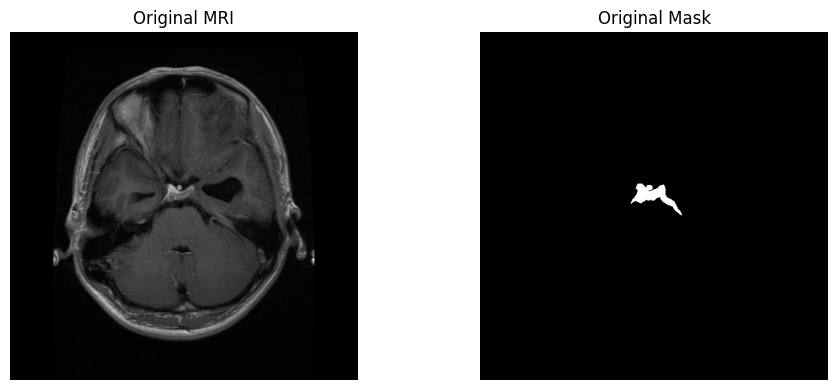

In [ ]:
import cv2
import matplotlib.pyplot as plt
import os

name = "brisc2025_test_00005_gl_ax_t1.jpg"

img_path = os.path.join(SEG_TEST_IMAGES, name)
mask_path = os.path.join(
    SEG_TEST_MASKS,
    os.path.splitext(name)[0] + ".png"
)

img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
raw_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

# Original image aur original mask
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(raw_mask, cmap="gray", vmin=0, vmax=255)
plt.title("Original Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

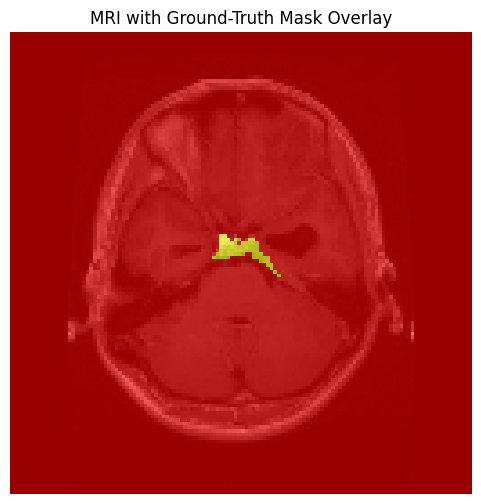

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

name = "brisc2025_test_00005_gl_ax_t1.jpg"

img_path = os.path.join(SEG_TEST_IMAGES, name)
mask_path = os.path.join(
    SEG_TEST_MASKS,
    os.path.splitext(name)[0] + ".png"
)

img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
raw_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

img = cv2.resize(img, (128, 128))
mask = cv2.resize(
    raw_mask, (128, 128),
    interpolation=cv2.INTER_NEAREST
)
mask = (mask > 127).astype(np.uint8)

plt.figure(figsize=(6, 6))
plt.imshow(img, cmap="gray")
plt.imshow(mask, cmap="autumn", alpha=0.6)
plt.title("MRI with Ground-Truth Mask Overlay")
plt.axis("off")
plt.show()

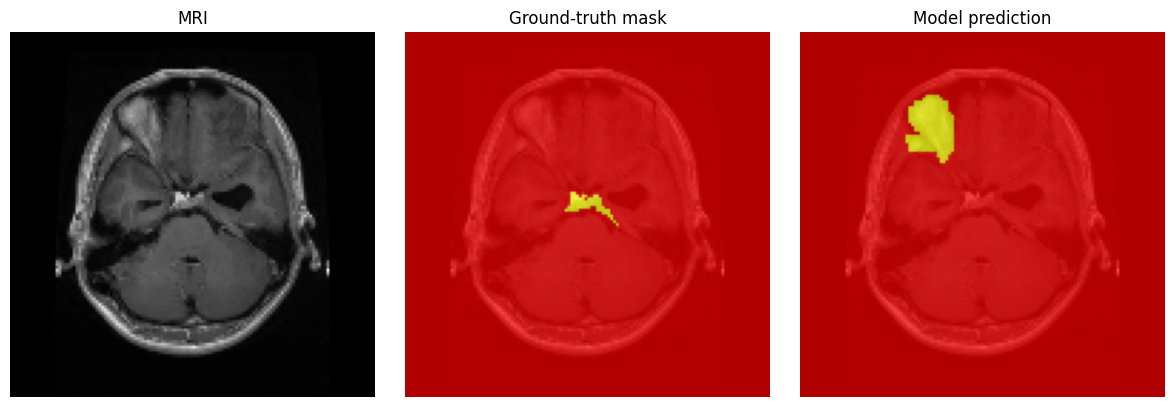

Ground-truth pixels: 70
Predicted pixels: 295
Overlap pixels: 0


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

name = "brisc2025_test_00005_gl_ax_t1.jpg"

img_path = os.path.join(SEG_TEST_IMAGES, name)
mask_path = os.path.join(
    SEG_TEST_MASKS,
    os.path.splitext(name)[0] + ".png"
)

img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
raw_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

img = cv2.resize(img, (128, 128)).astype(np.float32) / 255.0
mask = cv2.resize(
    raw_mask, (128, 128),
    interpolation=cv2.INTER_NEAREST
)
actual = (mask > 127).astype(np.uint8)

x = img[np.newaxis, ..., np.newaxis]
prob = model_b.predict(x, verbose=0)[0, :, :, 0]
pred = (prob >= 0.5).astype(np.uint8)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(img, cmap="gray")
plt.imshow(actual, cmap="autumn", alpha=0.7)
plt.title("Ground-truth mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(img, cmap="gray")
plt.imshow(pred, cmap="autumn", alpha=0.7)
plt.title("Model prediction")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Ground-truth pixels:", int(actual.sum()))
print("Predicted pixels:", int(pred.sum()))
print("Overlap pixels:", int(np.sum(actual * pred)))

In [ ]:
import os
import cv2

name = "brisc2025_test_00005_gl_ax_t1.jpg"

img_path = os.path.join(SEG_TEST_IMAGES, name)
mask_name = os.path.splitext(name)[0] + ".png"
mask_path = os.path.join(SEG_TEST_MASKS, mask_name)

print("Image exists:", os.path.exists(img_path))
print("Mask exists:", os.path.exists(mask_path))
print("Image filename:", os.path.basename(img_path))
print("Mask filename:", os.path.basename(mask_path))

img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

print("Original image shape:", img.shape if img is not None else None)
print("Original mask shape:", mask.shape if mask is not None else None)

Image exists: True
Mask exists: True
Image filename: brisc2025_test_00005_gl_ax_t1.jpg
Mask filename: brisc2025_test_00005_gl_ax_t1.png
Original image shape: (512, 512)
Original mask shape: (512, 512)


In [ ]:
import os

base_path = "/content/brisc_data/brisc2025"

for root, dirs, files in os.walk(base_path):
    dirs[:] = [
        d for d in dirs
        if d.lower() not in ["images", "masks"]
    ]

    for filename in files:
        if filename.lower().endswith(
            (".csv", ".json", ".xlsx", ".txt", ".md")
        ):
            print(os.path.join(root, filename))

In [ ]:
import cv2
import numpy as np
import os

def inspect_mask(folder, filename):
    path = os.path.join(folder, filename)
    mask = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    binary = mask > 127
    y, x = np.where(binary)

    print("\nFile:", filename)
    print("Mask shape:", mask.shape)
    print("Tumor pixels:", int(binary.sum()))

    if len(x) > 0:
        print("Bounding box (x_min, y_min, x_max, y_max):",
              (int(x.min()), int(y.min()),
               int(x.max()), int(y.max())))
    else:
        print("No foreground pixels found")

inspect_mask(
    SEG_TRAIN_MASKS,
    "brisc2025_train_00001_gl_ax_t1.png"
)

inspect_mask(
    SEG_TEST_MASKS,
    "brisc2025_test_00005_gl_ax_t1.png"
)


File: brisc2025_train_00001_gl_ax_t1.png
Mask shape: (512, 512)
Tumor pixels: 16345
Bounding box (x_min, y_min, x_max, y_max): (242, 144, 376, 311)

File: brisc2025_test_00005_gl_ax_t1.png
Mask shape: (512, 512)
Tumor pixels: 1192
Bounding box (x_min, y_min, x_max, y_max): (222, 223, 296, 269)


In [ ]:
import cv2
import numpy as np
import os

name = "brisc2025_test_00005_gl_ax_t1.jpg"

img = cv2.imread(
    os.path.join(SEG_TEST_IMAGES, name),
    cv2.IMREAD_GRAYSCALE
)

mask = cv2.imread(
    os.path.join(
        SEG_TEST_MASKS,
        os.path.splitext(name)[0] + ".png"
    ),
    cv2.IMREAD_GRAYSCALE
)

img_small = cv2.resize(img, (128, 128))
mask_small = cv2.resize(
    mask, (128, 128),
    interpolation=cv2.INTER_NEAREST
)

binary = mask_small > 127
y, x = np.where(binary)

print("Resized image shape:", img_small.shape)
print("Resized mask shape:", mask_small.shape)
print("Mask pixels:", int(binary.sum()))
print("Bounding box:",
      (int(x.min()), int(y.min()), int(x.max()), int(y.max())))

Resized image shape: (128, 128)
Resized mask shape: (128, 128)
Mask pixels: 70
Bounding box: (56, 56, 74, 67)


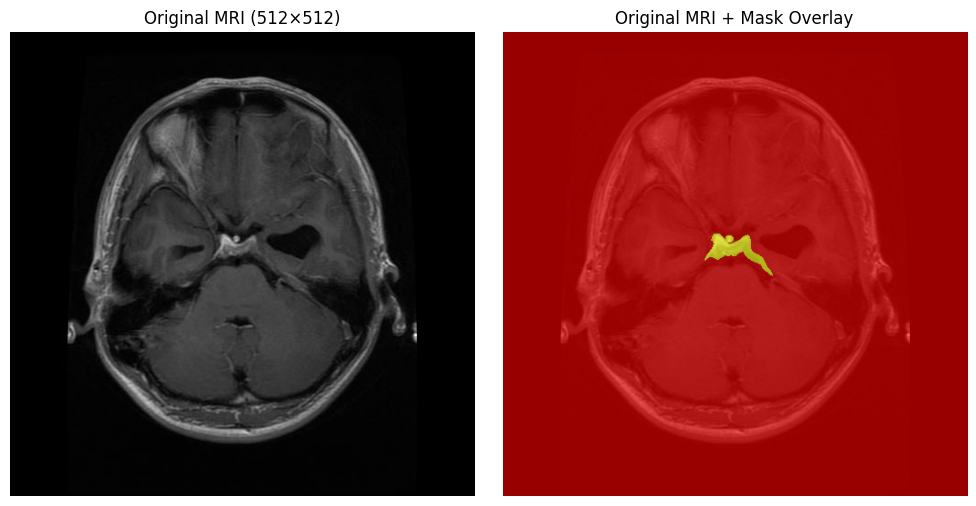

In [ ]:
import matplotlib.pyplot as plt
import cv2
import numpy as np
import os

name = "brisc2025_test_00005_gl_ax_t1.jpg"

img = cv2.imread(
    os.path.join(SEG_TEST_IMAGES, name),
    cv2.IMREAD_GRAYSCALE
)

mask = cv2.imread(
    os.path.join(SEG_TEST_MASKS, name.replace(".jpg", ".png")),
    cv2.IMREAD_GRAYSCALE
)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(img, cmap="gray")
ax[0].set_title("Original MRI (512×512)")
ax[0].axis("off")

ax[1].imshow(img, cmap="gray")
ax[1].imshow(mask > 127, cmap="autumn", alpha=0.6)
ax[1].set_title("Original MRI + Mask Overlay")
ax[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

base_path = "/content/brisc_data/brisc2025"

print("Root folder contents:")

for item in os.listdir(base_path):
    full_path = os.path.join(base_path, item)

    if os.path.isfile(full_path):
        print("FILE:", item)
    else:
        print("FOLDER:", item)

Root folder contents:
FOLDER: classification_task
FOLDER: segmentation_task


In [ ]:
import os

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"

model_files = [
    "best_classweighted_cnn.keras",
    "best_brain_tumor_cnn.keras",
    "best_mobilenetv2.keras"
]

for filename in model_files:
    path = os.path.join(project_dir, filename)
    print(filename, "->", os.path.exists(path))

best_classweighted_cnn.keras -> True
best_brain_tumor_cnn.keras -> True
best_mobilenetv2.keras -> True


In [ ]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

print("preprocess_input loaded successfully!")

preprocess_input loaded successfully!


In [ ]:
import tensorflow as tf
import numpy as np

model_cnn = tf.keras.models.load_model(
    "/content/drive/MyDrive/Brain_Tumor_Project/best_brain_tumor_cnn.keras",
    compile=False
)

dummy_input = np.zeros((1, 128, 128, 3), dtype=np.float32)
output = model_cnn.predict(dummy_input, verbose=0)

print("CNN model loaded successfully!")
print("Output shape:", output.shape)
print("Predicted class index:", np.argmax(output[0]))
print("Prediction scores:", output[0])

CNN model loaded successfully!
Output shape: (1, 4)
Predicted class index: 0
Prediction scores: [0.86078984 0.10031002 0.03701275 0.00188742]


In [ ]:
import os

base_path = "/content/brisc_data/brisc2025/classification_task"

for root, dirs, files in os.walk(base_path):
    level = root.replace(base_path, "").count(os.sep)
    if level <= 2:
        print("  " * level + os.path.basename(root) + f"  ({len(files)} files)")

classification_task  (0 files)
  train  (0 files)
    pituitary  (1457 files)
    no_tumor  (1067 files)
    glioma  (1147 files)
    meningioma  (1329 files)
  test  (0 files)
    pituitary  (300 files)
    no_tumor  (140 files)
    glioma  (254 files)
    meningioma  (306 files)


In [ ]:
import os
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix
)

base_path = "/content/brisc_data/brisc2025/classification_task"
test_path = os.path.join(base_path, "test")

# Model ke output order ko dataset folder order se match karein
class_names = ["glioma", "meningioma", "no_tumor", "pituitary"]

y_true = []
y_pred = []

for class_index, class_name in enumerate(class_names):
    folder = os.path.join(test_path, class_name)

    for filename in sorted(os.listdir(folder)):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_path = os.path.join(folder, filename)

            img = load_img(
                image_path,
                target_size=(128, 128),
                color_mode="rgb"
            )
            image = img_to_array(img) / 255.0
            image = np.expand_dims(image, axis=0)

            prediction = model_cnn.predict(image, verbose=0)

            y_true.append(class_index)
            y_pred.append(np.argmax(prediction))

print("Test images evaluated:", len(y_true))
print("Accuracy:", round(accuracy_score(y_true, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3]))

Test images evaluated: 1000
Accuracy: 25.4 %

Classification Report:
              precision    recall  f1-score   support

      glioma       0.25      1.00      0.41       254
  meningioma       0.00      0.00      0.00       306
    no_tumor       0.00      0.00      0.00       140
   pituitary       0.00      0.00      0.00       300

    accuracy                           0.25      1000
   macro avg       0.06      0.25      0.10      1000
weighted avg       0.06      0.25      0.10      1000

Confusion Matrix:
[[254   0   0   0]
 [306   0   0   0]
 [140   0   0   0]
 [300   0   0   0]]


In [ ]:
import tensorflow as tf
import numpy as np
import os
from tensorflow.keras.utils import load_img, img_to_array

project_path = "/content/drive/MyDrive/Brain_Tumor_Project"

models = {
    "Current CNN": model_cnn,
    "Class-weighted CNN": tf.keras.models.load_model(
        os.path.join(project_path, "best_classweighted_cnn.keras"),
        compile=False
    )
}

test_path = "/content/brisc_data/brisc2025/classification_task/test"
class_names = ["glioma", "meningioma", "no_tumor", "pituitary"]

# Har class se 5 images lekar quick check
images = []
actual_classes = []

for class_name in class_names:
    folder = os.path.join(test_path, class_name)
    files = sorted([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])[:5]

    for filename in files:
        img = load_img(
            os.path.join(folder, filename),
            target_size=(128, 128),
            color_mode="rgb"
        )
        images.append(img_to_array(img) / 255.0)
        actual_classes.append(class_name)

X_check = np.array(images)

for model_name, mdl in models.items():
    predictions = mdl.predict(X_check, verbose=0)
    predicted_indices = np.argmax(predictions, axis=1)

    print("\n", model_name)
    print("Predicted class counts:")
    for i, name in enumerate(class_names):
        print(name, ":", int(np.sum(predicted_indices == i)))
    print("First 4 prediction scores:\n", np.round(predictions[:4], 3))


 Current CNN
Predicted class counts:
glioma : 20
meningioma : 0
no_tumor : 0
pituitary : 0
First 4 prediction scores:
 [[0.859 0.101 0.037 0.002]
 [0.86  0.101 0.037 0.002]
 [0.86  0.101 0.037 0.002]
 [0.859 0.101 0.037 0.002]]

 Class-weighted CNN
Predicted class counts:
glioma : 20
meningioma : 0
no_tumor : 0
pituitary : 0
First 4 prediction scores:
 [[0.99  0.001 0.009 0.   ]
 [0.988 0.001 0.011 0.   ]
 [0.987 0.001 0.012 0.   ]
 [0.99  0.001 0.009 0.   ]]


In [ ]:
import tensorflow as tf
import os
import json

project_path = "/content/drive/MyDrive/Brain_Tumor_Project"

print("MODEL OUTPUT LAYER:")
model_cnn.summary()

print("\nSAVED TRAINING HISTORY:")
history_path = os.path.join(project_path, "training_history.json")

if os.path.exists(history_path):
    with open(history_path, "r") as f:
        history_data = json.load(f)

    print("Available keys:", list(history_data.keys()))

    for key, values in history_data.items():
        if isinstance(values, list) and len(values) > 0:
            print(key, "first:", values[0], "last:", values[-1])
else:
    print("Training history file not found.")

MODEL OUTPUT LAYER:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,004 (109.39 KB)

 Trainable params: 28,004 (109.39 KB)

 Non-trainable params: 0 (0.00 B)


SAVED TRAINING HISTORY:
Available keys: ['accuracy', 'loss', 'val_accuracy', 'val_loss']
accuracy first: 0.43024998903274536 last: 0.7645000219345093
loss first: 1.2627196311950684 last: 0.5588055849075317
val_accuracy first: 0.5419999957084656 last: 0.7580000162124634
val_loss first: 1.116662621498108 last: 0.5999250411987305


In [ ]:
for layer in model_cnn.layers:
    if isinstance(layer, tf.keras.layers.Rescaling):
        print("Rescaling layer found")
        print("Scale:", layer.scale)
        print("Offset:", layer.offset)

print("\nFirst layer:", model_cnn.layers[0].name)
print("Input shape:", model_cnn.input_shape)
print("Output shape:", model_cnn.output_shape)

Rescaling layer found
Scale: 0.00392156862745098
Offset: 0.0

First layer: rescaling
Input shape: (None, 128, 128, 3)
Output shape: (None, 4)


In [ ]:
import os
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

test_path = "/content/brisc_data/brisc2025/classification_task/test"
class_names = ["glioma", "meningioma", "no_tumor", "pituitary"]

y_true, y_pred = [], []

for class_index, class_name in enumerate(class_names):
    folder = os.path.join(test_path, class_name)

    for filename in sorted(os.listdir(folder)):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            img = load_img(
                os.path.join(folder, filename),
                target_size=(128, 128),
                color_mode="rgb"
            )

            # Raw pixel values: model ki Rescaling layer /255 karegi
            image = img_to_array(img)
            image = np.expand_dims(image, axis=0)

            pred = model_cnn.predict(image, verbose=0)

            y_true.append(class_index)
            y_pred.append(np.argmax(pred[0]))

print("Test images:", len(y_true))
print("Corrected accuracy:", round(accuracy_score(y_true, y_pred) * 100, 2), "%")
print("\n", classification_report(
    y_true, y_pred,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    zero_division=0
))
print("Confusion matrix:\n", confusion_matrix(
    y_true, y_pred, labels=[0, 1, 2, 3]
))

Test images: 1000
Corrected accuracy: 52.5 %

               precision    recall  f1-score   support

      glioma       0.53      0.76      0.62       254
  meningioma       0.50      0.01      0.01       306
    no_tumor       0.43      0.71      0.54       140
   pituitary       0.58      0.77      0.66       300

    accuracy                           0.53      1000
   macro avg       0.51      0.56      0.46      1000
weighted avg       0.52      0.53      0.43      1000

Confusion matrix:
 [[192   2  18  42]
 [119   2  65 120]
 [ 33   0 100   7]
 [ 21   0  48 231]]


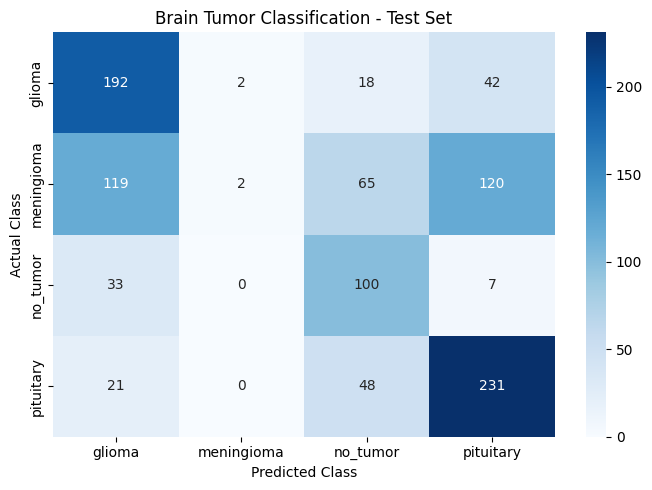

Results saved successfully!
Classification report: /content/drive/MyDrive/Brain_Tumor_Project/final_classification_report.csv
Confusion matrix: /content/drive/MyDrive/Brain_Tumor_Project/confusion_matrix.png


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

project_path = "/content/drive/MyDrive/Brain_Tumor_Project"
os.makedirs(project_path, exist_ok=True)

# Save classification report
report = classification_report(
    y_true, y_pred,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    zero_division=0,
    output_dict=True
)

pd.DataFrame(report).transpose().to_csv(
    os.path.join(project_path, "final_classification_report.csv")
)

# Plot and save confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Brain Tumor Classification - Test Set")
plt.tight_layout()
plt.savefig(
    os.path.join(project_path, "confusion_matrix.png"),
    dpi=300
)
plt.show()

print("Results saved successfully!")
print("Classification report:", os.path.join(project_path, "final_classification_report.csv"))
print("Confusion matrix:", os.path.join(project_path, "confusion_matrix.png"))

In [ ]:
import os

project_path = "/content/drive/MyDrive/Brain_Tumor_Project"

print("Project files:")
for filename in os.listdir(project_path):
    print(filename)

Project files:
best_classweighted_cnn.keras
training_history.json
classification_report.txt
best_unet_segmentation.keras
segmentation_test_evaluation.csv
tumor_size_location_estimates.csv
unet_error_analysis.csv
threshold_comparison_evaluation.csv
one_image_integration_test.csv
best_brain_tumor_cnn.keras
best_mobilenetv2.keras
unet_before_retraining.keras
fresh_test_evaluation.csv
unet_per_image_dice.keras
final_classification_report.csv
confusion_matrix.png


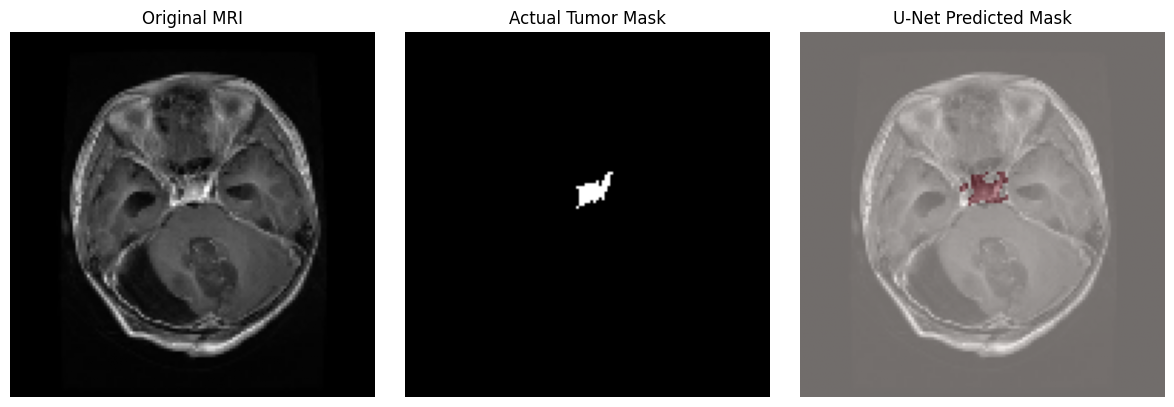

Image: brisc2025_test_00001_gl_ax_t1.jpg
Actual mask pixels: 73
Predicted mask pixels: 111


In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Load saved U-Net model
model_unet = tf.keras.models.load_model(
    "/content/drive/MyDrive/Brain_Tumor_Project/unet_per_image_dice.keras",
    compile=False
)

# Test image and corresponding mask folders
image_dir = "/content/brisc_data/brisc2025/segmentation_task/test/images"
mask_dir = "/content/brisc_data/brisc2025/segmentation_task/test/masks"

# Find one matching image and mask
image_files = sorted([
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

filename = image_files[0]
image_path = os.path.join(image_dir, filename)
mask_path = os.path.join(mask_dir, os.path.splitext(filename)[0] + ".png")

# Read image and actual mask
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
actual_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

if image is None or actual_mask is None:
    raise FileNotFoundError("Image or matching mask not found. Check filenames.")

# Prepare image for U-Net
resized_image = cv2.resize(image, (128, 128))
input_image = resized_image.astype("float32") / 255.0
input_image = input_image[np.newaxis, ..., np.newaxis]

# Predict segmentation mask
prediction = model_unet.predict(input_image, verbose=0)[0, :, :, 0]
predicted_mask = (prediction >= 0.5).astype(np.uint8)

actual_resized = cv2.resize(
    actual_mask, (128, 128),
    interpolation=cv2.INTER_NEAREST
)
actual_resized = (actual_resized > 127).astype(np.uint8)

# Display results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(resized_image, cmap="gray")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(actual_resized, cmap="gray")
plt.title("Actual Tumor Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(resized_image, cmap="gray")
plt.imshow(predicted_mask, cmap="Reds", alpha=0.45)
plt.title("U-Net Predicted Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Image:", filename)
print("Actual mask pixels:", int(actual_resized.sum()))
print("Predicted mask pixels:", int(predicted_mask.sum()))

In [ ]:
import pandas as pd
import os

project_path = "/content/drive/MyDrive/Brain_Tumor_Project"

files = [
    "segmentation_test_evaluation.csv",
    "fresh_test_evaluation.csv",
    "unet_error_analysis.csv"
]

for filename in files:
    path = os.path.join(project_path, filename)

    print("\n" + "=" * 45)
    print(filename)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())

        for col in ["dice", "iou"]:
            if col in df.columns:
                print(f"Mean {col.upper()}: {df[col].mean():.4f}")
                print(f"Median {col.upper()}: {df[col].median():.4f}")

        print(df.head(3).to_string(index=False))
    else:
        print("File not found")


segmentation_test_evaluation.csv
Rows: 860
Columns: ['image', 'mask', 'actual_mask_pixels', 'predicted_mask_pixels', 'dice', 'iou']
Mean DICE: 0.6501
Median DICE: 0.7922
Mean IOU: 0.5497
Median IOU: 0.6559
                            image                              mask  actual_mask_pixels  predicted_mask_pixels     dice      iou
brisc2025_test_00001_gl_ax_t1.jpg brisc2025_test_00001_gl_ax_t1.png                  95                    214 0.576052 0.404545
brisc2025_test_00002_gl_ax_t1.jpg brisc2025_test_00002_gl_ax_t1.png                 161                    131 0.801370 0.668571
brisc2025_test_00003_gl_ax_t1.jpg brisc2025_test_00003_gl_ax_t1.png                 423                     25 0.111607 0.059102

fresh_test_evaluation.csv
Rows: 860
Columns: ['image', 'actual_mask_pixels', 'predicted_mask_pixels', 'dice', 'iou']
Mean DICE: 0.6497
Median DICE: 0.7928
Mean IOU: 0.5503
Median IOU: 0.6568
                            image  actual_mask_pixels  predicted_mask_pixels     dice

In [ ]:
import json
import os
import tensorflow as tf

project_path = "/content/drive/MyDrive/Brain_Tumor_Project"

# Saved model ki preprocessing aur output layers
model_cnn.summary()

print("\n--- Saved training history ---")
with open(os.path.join(project_path, "training_history.json"), "r") as f:
    history = json.load(f)

print("History keys:", list(history.keys()))
print("Final training accuracy:", history["accuracy"][-1])
print("Final validation accuracy:", history["val_accuracy"][-1])

print("\n--- Training dataset folders ---")
train_path = "/content/brisc_data/brisc2025/classification_task/train"

print(sorted([
    name for name in os.listdir(train_path)
    if os.path.isdir(os.path.join(train_path, name))
]))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,004 (109.39 KB)

 Trainable params: 28,004 (109.39 KB)

 Non-trainable params: 0 (0.00 B)


--- Saved training history ---
History keys: ['accuracy', 'loss', 'val_accuracy', 'val_loss']
Final training accuracy: 0.7645000219345093
Final validation accuracy: 0.7580000162124634

--- Training dataset folders ---
['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [ ]:
import os
import numpy as np
import pandas as pd
from tensorflow.keras.utils import load_img, img_to_array

test_path = "/content/brisc_data/brisc2025/classification_task/test"
class_names = ["glioma", "meningioma", "no_tumor", "pituitary"]

rows = []

for class_name in class_names:
    folder = os.path.join(test_path, class_name)
    files = sorted([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])[:20]

    for filename in files:
        img = load_img(
            os.path.join(folder, filename),
            target_size=(128, 128),
            color_mode="rgb"
        )

        # Raw 0–255 values; model has its own Rescaling layer
        image = np.expand_dims(img_to_array(img), axis=0)
        scores = model_cnn.predict(image, verbose=0)[0]

        rows.append({
            "actual_class": class_name,
            "predicted_class": class_names[np.argmax(scores)],
            **{f"score_{name}": float(score)
               for name, score in zip(class_names, scores)}
        })

check_df = pd.DataFrame(rows)

print("Images checked:", len(check_df))
print("\nPredictions by actual class:")
print(pd.crosstab(
    check_df["actual_class"],
    check_df["predicted_class"]
))

print("\nAverage prediction scores by actual class:")
print(check_df.groupby("actual_class")[
    [f"score_{name}" for name in class_names]
].mean().round(3))

Images checked: 80

Predictions by actual class:
predicted_class  glioma  no_tumor  pituitary
actual_class                                
glioma               20         0          0
meningioma            0         7         13
no_tumor              3        17          0
pituitary             4         8          8

Average prediction scores by actual class:
              score_glioma  score_meningioma  score_no_tumor  score_pituitary
actual_class                                                                 
glioma               0.510             0.229           0.218            0.042
meningioma           0.042             0.126           0.307            0.525
no_tumor             0.229             0.227           0.409            0.135
pituitary            0.211             0.223           0.303            0.263


In [ ]:
import os

train_path = "/content/brisc_data/brisc2025/classification_task/train"

print("Alphabetical folder order:")
print(sorted([
    name for name in os.listdir(train_path)
    if os.path.isdir(os.path.join(train_path, name))
]))

print("\nExisting classification report:")
report_path = "/content/drive/MyDrive/Brain_Tumor_Project/classification_report.txt"

if os.path.exists(report_path):
    with open(report_path, "r") as f:
        print(f.read())
else:
    print("Report file not found.")

Alphabetical folder order:
['glioma', 'meningioma', 'no_tumor', 'pituitary']

Existing classification report:
              precision    recall  f1-score   support

      glioma     0.9155    0.5118    0.6566       254
  meningioma     0.6312    0.6209    0.6260       306
    no_tumor     0.6601    0.9571    0.7813       140
   pituitary     0.8051    0.9500    0.8716       300

    accuracy                         0.7390      1000
   macro avg     0.7530    0.7600    0.7339      1000
weighted avg     0.7596    0.7390    0.7292      1000



In [ ]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.utils import load_img, img_to_array

project_path = "/content/drive/MyDrive/Brain_Tumor_Project"
test_path = "/content/brisc_data/brisc2025/classification_task/test"

class_names = ["glioma", "meningioma", "no_tumor", "pituitary"]

model_paths = {
    "best_brain_tumor_cnn": os.path.join(project_path, "best_brain_tumor_cnn.keras"),
    "best_classweighted_cnn": os.path.join(project_path, "best_classweighted_cnn.keras")
}

# Same 5 test images from each class
X_check, y_check = [], []

for idx, class_name in enumerate(class_names):
    folder = os.path.join(test_path, class_name)
    files = sorted([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])[:5]

    for filename in files:
        img = load_img(
            os.path.join(folder, filename),
            target_size=(128, 128),
            color_mode="rgb"
        )
        X_check.append(img_to_array(img))
        y_check.append(idx)

X_check = np.array(X_check, dtype=np.float32)
y_check = np.array(y_check)

for name, path in model_paths.items():
    mdl = tf.keras.models.load_model(path, compile=False)

    # Test both possible input scales
    for scale_name, X in [
        ("raw_0_255", X_check),
        ("scaled_0_1", X_check / 255.0)
    ]:
        preds = np.argmax(mdl.predict(X, verbose=0), axis=1)
        accuracy = np.mean(preds == y_check) * 100
        print(name, "|", scale_name, "| accuracy:", round(accuracy, 2), "%")

best_brain_tumor_cnn | raw_0_255 | accuracy: 45.0 %
best_brain_tumor_cnn | scaled_0_1 | accuracy: 25.0 %
best_classweighted_cnn | raw_0_255 | accuracy: 75.0 %
best_classweighted_cnn | scaled_0_1 | accuracy: 25.0 %


In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

model_tl = tf.keras.models.load_model(
    "/content/drive/MyDrive/Brain_Tumor_Project/best_classweighted_cnn.keras",
    compile=False
)

y_true = []
y_pred = []

for images, labels in test_ds:
    # Images ko /255 mat karna
    predictions = model_tl.predict(images, verbose=0)

    y_pred.extend(np.argmax(predictions, axis=1))
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Full Test Accuracy:", round(accuracy_score(y_true, y_pred) * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=["glioma", "meningioma", "no_tumor", "pituitary"],
    digits=4,
    zero_division=0
))

print("\nConfusion Matrix:\n")
print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3]))

NameError: name 'test_ds' is not defined

In [ ]:
import tensorflow as tf
import os

test_path = "/content/brisc_data/brisc2025/classification_task/test"

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=(128, 128),
    batch_size=32,
    label_mode="int",
    shuffle=False,
    color_mode="rgb"
)

print("Test dataset created successfully!")
print("Classes:", test_ds.class_names)
print("Total test images:", len(test_ds.file_paths))

Found 1000 files belonging to 4 classes.
Test dataset created successfully!
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Total test images: 1000


In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

model_tl = tf.keras.models.load_model(
    "/content/drive/MyDrive/Brain_Tumor_Project/best_classweighted_cnn.keras",
    compile=False
)

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model_tl.predict(images, verbose=0)
    y_pred.extend(np.argmax(predictions, axis=1))
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Full Test Accuracy:", round(accuracy_score(y_true, y_pred) * 100, 2), "%")

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=["glioma", "meningioma", "no_tumor", "pituitary"],
    digits=4,
    zero_division=0
))

print("\nConfusion Matrix:\n")
print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3]))

Full Test Accuracy: 73.9 %

Classification Report:

              precision    recall  f1-score   support

      glioma     0.9155    0.5118    0.6566       254
  meningioma     0.6312    0.6209    0.6260       306
    no_tumor     0.6601    0.9571    0.7813       140
   pituitary     0.8051    0.9500    0.8716       300

    accuracy                         0.7390      1000
   macro avg     0.7530    0.7600    0.7339      1000
weighted avg     0.7596    0.7390    0.7292      1000


Confusion Matrix:

[[130  98   5  21]
 [ 10 190  60  46]
 [  0   4 134   2]
 [  2   9   4 285]]


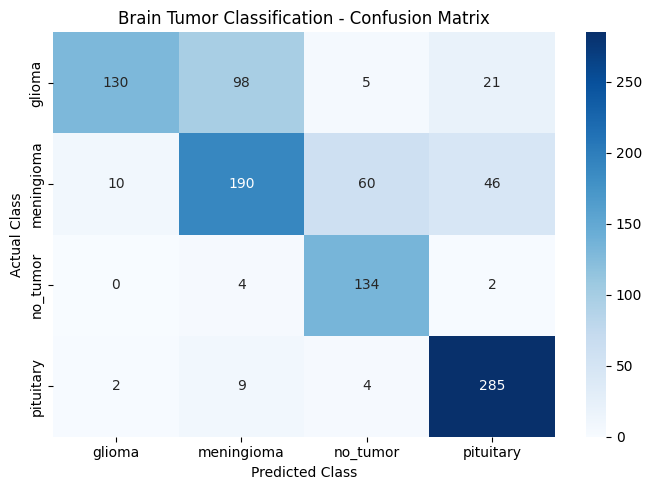

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

class_names = ["glioma", "meningioma", "no_tumor", "pituitary"]

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Brain Tumor Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

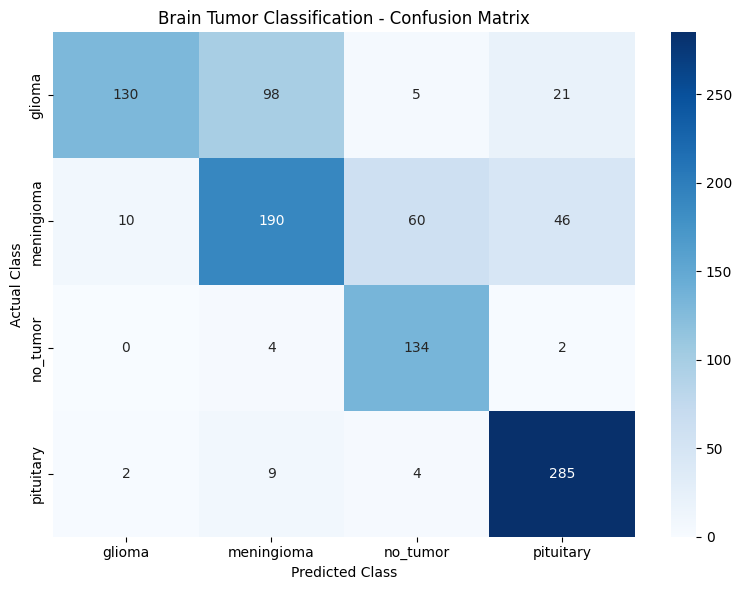

Classification report and confusion matrix saved successfully.


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

project_path = "/content/drive/MyDrive/Brain_Tumor_Project"
os.makedirs(project_path, exist_ok=True)

class_names = ["glioma", "meningioma", "no_tumor", "pituitary"]

# Save classification report
report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    os.path.join(project_path, "final_classification_report.csv")
)

# Save confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3])

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Brain Tumor Classification - Confusion Matrix")
plt.tight_layout()
plt.savefig(
    os.path.join(project_path, "confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Classification report and confusion matrix saved successfully.")

In [ ]:
import os
import pandas as pd

project_path = "/content/drive/MyDrive/Brain_Tumor_Project"

files = [
    "segmentation_test_evaluation.csv",
    "fresh_test_evaluation.csv",
    "unet_error_analysis.csv",
    "threshold_comparison_evaluation.csv"
]

for filename in files:
    path = os.path.join(project_path, filename)
    print("\n" + "=" * 50)
    print(filename)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())

        for col in df.columns:
            if col.lower() in ["dice", "iou", "precision", "recall"]:
                print(f"{col} mean:", round(df[col].mean(), 4))
    else:
        print("File not found")


segmentation_test_evaluation.csv
Shape: (860, 6)
Columns: ['image', 'mask', 'actual_mask_pixels', 'predicted_mask_pixels', 'dice', 'iou']
dice mean: 0.6501
iou mean: 0.5497

fresh_test_evaluation.csv
Shape: (860, 5)
Columns: ['image', 'actual_mask_pixels', 'predicted_mask_pixels', 'dice', 'iou']
dice mean: 0.6497
iou mean: 0.5503

unet_error_analysis.csv
Shape: (860, 9)
Columns: ['image', 'TP', 'FP', 'FN', 'TN', 'Dice', 'IoU', 'Precision', 'Recall']
Dice mean: 0.6501
IoU mean: 0.5497
Precision mean: 0.6747
Recall mean: 0.7389

threshold_comparison_evaluation.csv
Shape: (860, 5)
Columns: ['filename', 'dice_gt0', 'iou_gt0', 'dice_gt127', 'iou_gt127']


In [ ]:
import os
import tensorflow as tf

project_path = "/content/drive/MyDrive/Brain_Tumor_Project"

model_files = [
    "best_unet_segmentation.keras",
    "unet_per_image_dice.keras"
]

for filename in model_files:
    path = os.path.join(project_path, filename)
    print("\nModel:", filename)

    if os.path.exists(path):
        model = tf.keras.models.load_model(path, compile=False)
        print("Input shape:", model.input_shape)
        print("Output shape:", model.output_shape)
        print("Parameters:", model.count_params())
    else:
        print("File not found")


Model: best_unet_segmentation.keras
Input shape: (None, 128, 128, 1)
Output shape: (None, 128, 128, 1)
Parameters: 7759521

Model: unet_per_image_dice.keras
Input shape: (None, 128, 128, 1)
Output shape: (None, 128, 128, 1)
Parameters: 7759521


In [ ]:
import os
import numpy as np
import tensorflow as tf
from PIL import Image
from sklearn.metrics import confusion_matrix

base_path = "/content/brisc_data/brisc2025/segmentation_task/test"
image_dir = os.path.join(base_path, "images")
mask_dir = os.path.join(base_path, "masks")

project_path = "/content/drive/MyDrive/Brain_Tumor_Project"

model_paths = {
    "best_unet_segmentation": os.path.join(project_path, "best_unet_segmentation.keras"),
    "unet_per_image_dice": os.path.join(project_path, "unet_per_image_dice.keras")
}

image_files = sorted([
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

results = {}

for model_name, model_path in model_paths.items():
    unet = tf.keras.models.load_model(model_path, compile=False)
    dice_scores, iou_scores = [], []

    for filename in image_files:
        stem = os.path.splitext(filename)[0]

        # Find corresponding mask
        mask_file = next(
            (f for f in os.listdir(mask_dir)
             if os.path.splitext(f)[0] == stem),
            None
        )
        if mask_file is None:
            continue

        image = Image.open(os.path.join(image_dir, filename)).convert("L")
        image = image.resize((128, 128), Image.Resampling.BILINEAR)
        x = np.array(image, dtype=np.float32) / 255.0
        x = x[None, ..., None]

        mask = Image.open(os.path.join(mask_dir, mask_file)).convert("L")
        mask = mask.resize((128, 128), Image.Resampling.NEAREST)
        y_true_mask = np.array(mask) > 127

        y_prob = unet.predict(x, verbose=0)[0, ..., 0]
        y_pred_mask = y_prob >= 0.5

        # Align evaluation mask to model's 128x128 output
        if y_true_mask.shape != (128, 128):
            y_true_mask = np.array(
                Image.fromarray(y_true_mask.astype(np.uint8) * 255)
                .resize((128, 128), Image.Resampling.NEAREST)
            ) > 127

        intersection = np.logical_and(y_true_mask, y_pred_mask).sum()
        true_pixels = y_true_mask.sum()
        pred_pixels = y_pred_mask.sum()
        union = np.logical_or(y_true_mask, y_pred_mask).sum()

        dice = (2 * intersection) / (true_pixels + pred_pixels + 1e-7)
        iou = intersection / (union + 1e-7)

        dice_scores.append(dice)
        iou_scores.append(iou)

    results[model_name] = {
        "images": len(dice_scores),
        "mean_dice": float(np.mean(dice_scores)),
        "mean_iou": float(np.mean(iou_scores))
    }

for name, scores in results.items():
    print("\n", name)
    print("Images evaluated:", scores["images"])
    print("Mean Dice:", round(scores["mean_dice"], 4))
    print("Mean IoU:", round(scores["mean_iou"], 4))


 best_unet_segmentation
Images evaluated: 860
Mean Dice: 0.6345
Mean IoU: 0.5321

 unet_per_image_dice
Images evaluated: 860
Mean Dice: 0.702
Mean IoU: 0.6163


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

search_root = "/content/brisc_data"

for root, dirs, files in os.walk(search_root):
    if "segmentation_task" in root or (
        "images" in dirs and "masks" in dirs
    ):
        print(root)
        for d in dirs:
            if d.lower() in ["images", "masks", "test", "train"]:
                print("   Folder:", d)

In [4]:
import os

print("Content folder:")
print(os.listdir("/content"))

print("\nDataset folder exists?")
print(os.path.exists("/content/brisc_data"))

print("\nGoogle Drive mounted?")
print(os.path.exists("/content/drive/MyDrive/Brain_Tumor_Project"))

Content folder:
['.config', 'drive', 'sample_data']

Dataset folder exists?
False

Google Drive mounted?
True


In [5]:
import os

drive_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(drive_path):
    dirs[:] = [d for d in dirs if not d.startswith(".")]

    if "segmentation_task" in dirs:
        print("Dataset found:", os.path.join(root, "segmentation_task"))

    if "brisc2025" in dirs:
        print("BRISC dataset found:", os.path.join(root, "brisc2025"))

In [6]:
import os

drive_path = "/content/drive/MyDrive"

print("MyDrive ke first-level folders:")
for name in os.listdir(drive_path)[:50]:
    path = os.path.join(drive_path, name)
    if os.path.isdir(path):
        print("[Folder]", name)
    else:
        print("[File]", name)

MyDrive ke first-level folders:
[Folder] Colab Notebooks
[File] resume2.pdf
[File] 🧠 BRISC 2025.zip
[Folder] Brain_Tumor_Project


In [7]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/🧠 BRISC 2025.zip"
extract_path = "/content/brisc_data"

print("ZIP exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    print("Extraction complete!")
    print("Extracted folders:", os.listdir(extract_path))
else:
    print("ZIP file path nahi mila. Filename check karna hoga.")

ZIP exists: True
Extraction complete!
Extracted folders: ['🧠 BRISC 2025']


In [8]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/🧠 BRISC 2025.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    print("Total files in ZIP:", len(z.namelist()))
    print("\nFirst 20 paths:")
    for name in z.namelist()[:20]:
        print(name)

print("\nExtracted folder exists:", os.path.exists("/content/brisc_data"))

Total files in ZIP: 1

First 20 paths:
🧠 BRISC 2025/brisc2025.zip

Extracted folder exists: True


In [9]:
import os
import zipfile

outer_folder = "/content/brisc_data/🧠 BRISC 2025"
inner_zip = "/content/drive/MyDrive/🧠 BRISC 2025.zip"

with zipfile.ZipFile(inner_zip, "r") as z:
    z.extractall("/content/brisc_data")

# Inner ZIP ka actual path
dataset_zip = "/content/brisc_data/🧠 BRISC 2025/brisc2025.zip"

print("Inner ZIP exists:", os.path.exists(dataset_zip))

if os.path.exists(dataset_zip):
    with zipfile.ZipFile(dataset_zip, "r") as z:
        print("Dataset files inside ZIP:", len(z.namelist()))
        print("First 10 paths:")
        for name in z.namelist()[:10]:
            print(name)

Inner ZIP exists: True
Dataset files inside ZIP: 15605
First 10 paths:
brisc2025/
brisc2025/classification_task/
brisc2025/classification_task/test/
brisc2025/classification_task/test/glioma/
brisc2025/classification_task/test/glioma/brisc2025_test_00001_gl_ax_t1.jpg
brisc2025/classification_task/test/glioma/brisc2025_test_00002_gl_ax_t1.jpg
brisc2025/classification_task/test/glioma/brisc2025_test_00003_gl_ax_t1.jpg
brisc2025/classification_task/test/glioma/brisc2025_test_00004_gl_ax_t1.jpg
brisc2025/classification_task/test/glioma/brisc2025_test_00005_gl_ax_t1.jpg
brisc2025/classification_task/test/glioma/brisc2025_test_00006_gl_ax_t1.jpg


In [10]:
import os
import zipfile

dataset_zip = "/content/brisc_data/🧠 BRISC 2025/brisc2025.zip"
extract_path = "/content/brisc_data"

with zipfile.ZipFile(dataset_zip, "r") as z:
    members = [
        name for name in z.namelist()
        if name.startswith("brisc2025/segmentation_task/test/images/")
        or name.startswith("brisc2025/segmentation_task/test/masks/")
    ]

    print("Files to extract:", len(members))

    for name in members:
        z.extract(name, extract_path)

image_dir = "/content/brisc_data/brisc2025/segmentation_task/test/images"
mask_dir = "/content/brisc_data/brisc2025/segmentation_task/test/masks"

print("Images folder exists:", os.path.isdir(image_dir))
print("Masks folder exists:", os.path.isdir(mask_dir))

if os.path.isdir(image_dir) and os.path.isdir(mask_dir):
    print("Test images:", len(os.listdir(image_dir)))
    print("Test masks:", len(os.listdir(mask_dir)))

Files to extract: 1722
Images folder exists: True
Masks folder exists: True
Test images: 860
Test masks: 860


In [11]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image

image_dir = "/content/brisc_data/brisc2025/segmentation_task/test/images"
mask_dir = "/content/brisc_data/brisc2025/segmentation_task/test/masks"
project_path = "/content/drive/MyDrive/Brain_Tumor_Project"

# Create filename lookup once
mask_lookup = {
    os.path.splitext(f)[0]: f
    for f in os.listdir(mask_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
}

image_files = sorted([
    f for f in os.listdir(image_dir)
    if os.path.splitext(f)[0] in mask_lookup
    and f.lower().endswith((".jpg", ".jpeg", ".png"))
])

print("Matched image-mask pairs:", len(image_files))

model_files = {
    "best_unet_segmentation": os.path.join(
        project_path, "best_unet_segmentation.keras"
    ),
    "unet_per_image_dice": os.path.join(
        project_path, "unet_per_image_dice.keras"
    )
}

for model_name, model_path in model_files.items():
    unet = tf.keras.models.load_model(model_path, compile=False)
    dice_values, iou_values = [], []

    for filename in image_files:
        stem = os.path.splitext(filename)[0]
        mask_filename = mask_lookup[stem]

        image = Image.open(os.path.join(image_dir, filename)).convert("L")
        image = image.resize((128, 128), Image.Resampling.BILINEAR)
        x = np.asarray(image, dtype=np.float32) / 255.0
        x = x[None, ..., None]

        mask = Image.open(os.path.join(mask_dir, mask_filename)).convert("L")
        mask = mask.resize((128, 128), Image.Resampling.NEAREST)
        y_true_mask = np.asarray(mask) > 127

        y_prob = unet.predict(x, verbose=0)[0, ..., 0]
        y_pred_mask = y_prob >= 0.5

        intersection = np.logical_and(y_true_mask, y_pred_mask).sum()
        true_pixels = y_true_mask.sum()
        pred_pixels = y_pred_mask.sum()
        union = np.logical_or(y_true_mask, y_pred_mask).sum()

        dice = (2 * intersection) / (true_pixels + pred_pixels + 1e-7)
        iou = intersection / (union + 1e-7)

        dice_values.append(dice)
        iou_values.append(iou)

    print(f"\n{model_name}")
    print("Images evaluated:", len(dice_values))
    print("Mean Dice:", round(float(np.mean(dice_values)), 4))
    print("Mean IoU:", round(float(np.mean(iou_values)), 4))

Matched image-mask pairs: 860

best_unet_segmentation
Images evaluated: 860
Mean Dice: 0.6345
Mean IoU: 0.5321

unet_per_image_dice
Images evaluated: 860
Mean Dice: 0.702
Mean IoU: 0.6163


In [12]:
import os
import numpy as np
import tensorflow as tf
from PIL import Image

image_dir = "/content/brisc_data/brisc2025/segmentation_task/test/images"
mask_dir = "/content/brisc_data/brisc2025/segmentation_task/test/masks"
model_path = "/content/drive/MyDrive/Brain_Tumor_Project/unet_per_image_dice.keras"

mask_lookup = {
    os.path.splitext(f)[0]: f
    for f in os.listdir(mask_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
}

image_files = sorted([
    f for f in os.listdir(image_dir)
    if os.path.splitext(f)[0] in mask_lookup
    and f.lower().endswith((".jpg", ".jpeg", ".png"))
])

unet = tf.keras.models.load_model(model_path, compile=False)
dice_values, iou_values = [], []

for filename in image_files:
    stem = os.path.splitext(filename)[0]

    image = Image.open(os.path.join(image_dir, filename)).convert("L")
    image = image.resize((128, 128), Image.Resampling.BILINEAR)
    x = np.asarray(image, dtype=np.float32)[None, ..., None] / 255.0

    mask = Image.open(os.path.join(mask_dir, mask_lookup[stem])).convert("L")
    mask = mask.resize((128, 128), Image.Resampling.NEAREST)
    y_true_mask = np.asarray(mask) > 127

    y_pred_mask = unet.predict(x, verbose=0)[0, ..., 0] >= 0.5

    intersection = np.logical_and(y_true_mask, y_pred_mask).sum()
    true_pixels = y_true_mask.sum()
    pred_pixels = y_pred_mask.sum()
    union = np.logical_or(y_true_mask, y_pred_mask).sum()

    dice_values.append(2 * intersection / (true_pixels + pred_pixels + 1e-7))
    iou_values.append(intersection / (union + 1e-7))

print("Model: unet_per_image_dice")
print("Images evaluated:", len(dice_values))
print("Mean Dice:", round(float(np.mean(dice_values)), 4))
print("Mean IoU:", round(float(np.mean(iou_values)), 4))

Model: unet_per_image_dice
Images evaluated: 860
Mean Dice: 0.702
Mean IoU: 0.6163


In [13]:
import os
import pandas as pd
import numpy as np
import tensorflow as tf
from PIL import Image

image_dir = "/content/brisc_data/brisc2025/segmentation_task/test/images"
mask_dir = "/content/brisc_data/brisc2025/segmentation_task/test/masks"
project_path = "/content/drive/MyDrive/Brain_Tumor_Project"

model_path = os.path.join(project_path, "unet_per_image_dice.keras")
unet = tf.keras.models.load_model(model_path, compile=False)

mask_lookup = {
    os.path.splitext(f)[0]: f
    for f in os.listdir(mask_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
}

image_files = sorted([
    f for f in os.listdir(image_dir)
    if os.path.splitext(f)[0] in mask_lookup
    and f.lower().endswith((".jpg", ".jpeg", ".png"))
])

rows = []

for filename in image_files:
    stem = os.path.splitext(filename)[0]

    image = Image.open(os.path.join(image_dir, filename)).convert("L")
    image = image.resize((128, 128), Image.Resampling.BILINEAR)
    x = np.asarray(image, dtype=np.float32)[None, ..., None] / 255.0

    mask = Image.open(os.path.join(mask_dir, mask_lookup[stem])).convert("L")
    mask = mask.resize((128, 128), Image.Resampling.NEAREST)
    y_true_mask = np.asarray(mask) > 127

    y_pred_mask = unet.predict(x, verbose=0)[0, ..., 0] >= 0.5

    intersection = np.logical_and(y_true_mask, y_pred_mask).sum()
    true_pixels = y_true_mask.sum()
    pred_pixels = y_pred_mask.sum()
    union = np.logical_or(y_true_mask, y_pred_mask).sum()

    dice = 2 * intersection / (true_pixels + pred_pixels + 1e-7)
    iou = intersection / (union + 1e-7)

    rows.append({
        "image": filename,
        "mask": mask_lookup[stem],
        "actual_mask_pixels": int(true_pixels),
        "predicted_mask_pixels": int(pred_pixels),
        "dice": float(dice),
        "iou": float(iou)
    })

df = pd.DataFrame(rows)
output_path = os.path.join(project_path, "final_segmentation_evaluation.csv")
df.to_csv(output_path, index=False)

print("Images evaluated:", len(df))
print("Mean Dice:", round(df["dice"].mean(), 4))
print("Mean IoU:", round(df["iou"].mean(), 4))
print("Saved to:", output_path)

Images evaluated: 860
Mean Dice: 0.702
Mean IoU: 0.6163
Saved to: /content/drive/MyDrive/Brain_Tumor_Project/final_segmentation_evaluation.csv


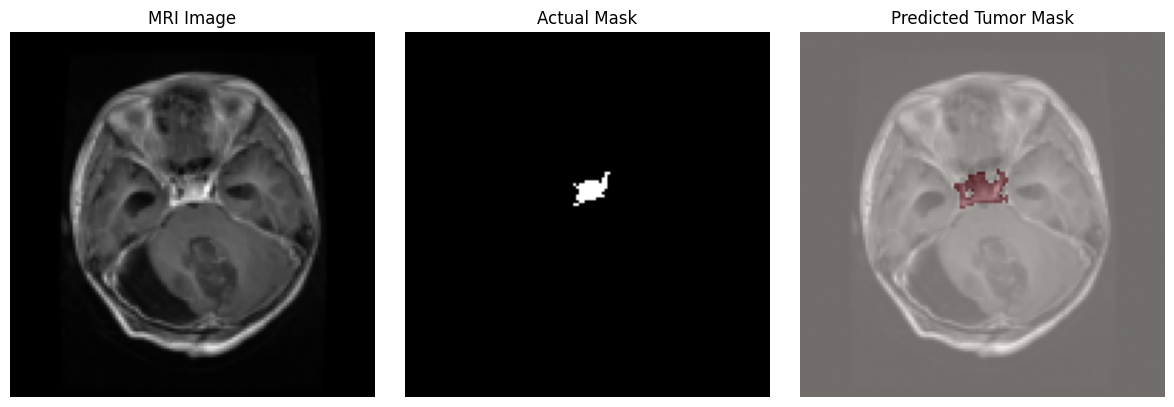

In [14]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

image_dir = "/content/brisc_data/brisc2025/segmentation_task/test/images"
mask_dir = "/content/brisc_data/brisc2025/segmentation_task/test/masks"
model_path = "/content/drive/MyDrive/Brain_Tumor_Project/unet_per_image_dice.keras"

mask_lookup = {
    os.path.splitext(f)[0]: f for f in os.listdir(mask_dir)
}
image_files = sorted([
    f for f in os.listdir(image_dir)
    if os.path.splitext(f)[0] in mask_lookup
])

filename = image_files[0]
stem = os.path.splitext(filename)[0]

image = Image.open(os.path.join(image_dir, filename)).convert("L")
image = image.resize((128, 128), Image.Resampling.BILINEAR)
x = np.asarray(image, dtype=np.float32) / 255.0

mask = Image.open(
    os.path.join(mask_dir, mask_lookup[stem])
).convert("L")
actual_mask = np.asarray(
    mask.resize((128, 128), Image.Resampling.NEAREST)
) > 127

unet = tf.keras.models.load_model(model_path, compile=False)
predicted_mask = unet.predict(x[None, ..., None], verbose=0)[0, ..., 0] >= 0.5

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(x, cmap="gray")
plt.title("MRI Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(actual_mask, cmap="gray")
plt.title("Actual Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(x, cmap="gray")
plt.imshow(predicted_mask, cmap="Reds", alpha=0.45)
plt.title("Predicted Tumor Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
import numpy as np

intersection = np.logical_and(actual_mask, predicted_mask).sum()
actual_pixels = actual_mask.sum()
predicted_pixels = predicted_mask.sum()
union = np.logical_or(actual_mask, predicted_mask).sum()

dice = 2 * intersection / (actual_pixels + predicted_pixels + 1e-7)
iou = intersection / (union + 1e-7)

print("Image:", filename)
print("Actual mask pixels:", actual_pixels)
print("Predicted mask pixels:", predicted_pixels)
print("Overlapping pixels:", intersection)
print("Dice score:", round(float(dice), 4))
print("IoU score:", round(float(iou), 4))

Image: brisc2025_test_00001_gl_ax_t1.jpg
Actual mask pixels: 72
Predicted mask pixels: 152
Overlapping pixels: 69
Dice score: 0.6161
IoU score: 0.4452


In [16]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image

# Paths
image_dir = "/content/brisc_data/brisc2025/segmentation_task/test/images"
mask_dir = "/content/brisc_data/brisc2025/segmentation_task/test/masks"
model_path = "/content/drive/MyDrive/Brain_Tumor_Project/unet_per_image_dice.keras"

# Match images and masks by filename
mask_lookup = {
    os.path.splitext(f)[0]: f
    for f in os.listdir(mask_dir)
    if f.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff"))
}

image_files = sorted([
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff"))
    and os.path.splitext(f)[0] in mask_lookup
])

print("Matched image-mask pairs:", len(image_files))

# Load model
model = tf.keras.models.load_model(model_path, compile=False)

results = []

for filename in image_files:
    stem = os.path.splitext(filename)[0]

    # Image preprocessing
    img = Image.open(os.path.join(image_dir, filename)).convert("L")
    img = img.resize((128, 128), Image.Resampling.BILINEAR)
    x = np.asarray(img, dtype=np.float32) / 255.0

    # Mask preprocessing
    m = Image.open(os.path.join(mask_dir, mask_lookup[stem])).convert("L")
    m = m.resize((128, 128), Image.Resampling.NEAREST)
    actual = np.asarray(m) > 127

    # Prediction
    pred = model.predict(x[None, ..., None], verbose=0)[0, ..., 0] >= 0.5

    intersection = np.logical_and(actual, pred).sum()
    actual_pixels = actual.sum()
    pred_pixels = pred.sum()
    union = np.logical_or(actual, pred).sum()

    dice = (
        2 * intersection / (actual_pixels + pred_pixels)
        if actual_pixels + pred_pixels > 0 else 1.0
    )
    iou = intersection / union if union > 0 else 1.0

    results.append({
        "image": filename,
        "actual_pixels": int(actual_pixels),
        "predicted_pixels": int(pred_pixels),
        "overlap_pixels": int(intersection),
        "dice": float(dice),
        "iou": float(iou)
    })

df = pd.DataFrame(results)

print("\nImages evaluated:", len(df))
print("Mean Dice:", round(df["dice"].mean(), 4))
print("Mean IoU:", round(df["iou"].mean(), 4))
print("Empty actual masks:", int((df["actual_pixels"] == 0).sum()))
print("Empty predicted masks:", int((df["predicted_pixels"] == 0).sum()))

display(df.head())

save_path = "/content/drive/MyDrive/Brain_Tumor_Project/final_segmentation_evaluation.csv"
df.to_csv(save_path, index=False)
print("\nSaved evaluation:", save_path)

Matched image-mask pairs: 860

Images evaluated: 860
Mean Dice: 0.702
Mean IoU: 0.6163
Empty actual masks: 0
Empty predicted masks: 27


,image,actual_pixels,predicted_pixels,overlap_pixels,dice,iou
0,brisc2025_test_00001_gl_ax_t1.jpg,72,152,69,0.616071,0.445161
1,brisc2025_test_00002_gl_ax_t1.jpg,139,99,92,0.773109,0.630137
2,brisc2025_test_00003_gl_ax_t1.jpg,362,99,95,0.412148,0.259563
3,brisc2025_test_00004_gl_ax_t1.jpg,249,156,131,0.646914,0.478102
4,brisc2025_test_00005_gl_ax_t1.jpg,76,242,0,0.000000,0.000000



Saved evaluation: /content/drive/MyDrive/Brain_Tumor_Project/final_segmentation_evaluation.csv


In [17]:
import os

image_name = "brisc2025_test_00005_gl_ax_t1.jpg"
image_stem = os.path.splitext(image_name)[0]

print("Image exists:",
      os.path.exists(os.path.join(image_dir, image_name)))

print("Matched mask:",
      mask_lookup.get(image_stem))

print("\nSimilar mask filenames:")
for name in os.listdir(mask_dir):
    if "00005" in name:
        print(name)


Image exists: True
Matched mask: brisc2025_test_00005_gl_ax_t1.png

Similar mask filenames:
brisc2025_test_00005_gl_ax_t1.png


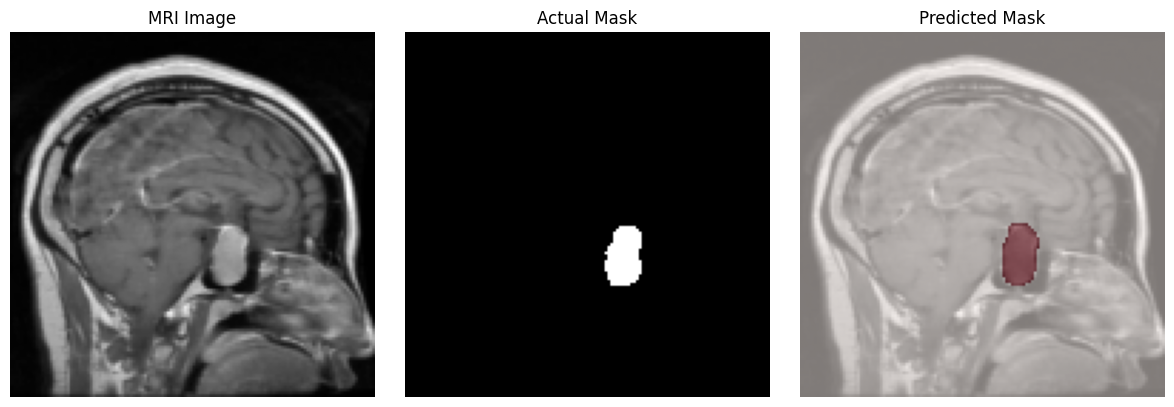

Actual mask pixels: 224
Predicted mask pixels: 235
Overlap pixels: 215


In [18]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(x, cmap="gray")
plt.title("MRI Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(actual, cmap="gray")
plt.title("Actual Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(x, cmap="gray")
plt.imshow(pred, cmap="Reds", alpha=0.5)
plt.title("Predicted Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Actual mask pixels:", actual.sum())
print("Predicted mask pixels:", pred.sum())
print("Overlap pixels:", np.logical_and(actual, pred).sum())

In [20]:
import os
import tensorflow as tf

base_dir = "/content/brisc_data/brisc2025/classification_task"

for split in ["train", "val", "test"]:
    path = os.path.join(base_dir, split)
    print(split, "exists:", os.path.isdir(path))
    if os.path.isdir(path):
        print("Classes:", os.listdir(path))

train exists: False
val exists: False
test exists: False


In [21]:
from google.colab import drive
drive.mount('/content/drive')

import os

print("Saved dataset ZIP:")
for name in os.listdir("/content/drive/MyDrive"):
    if "BRISC" in name.upper():
        print(name)

print("\nSaved project files:")
project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"

if os.path.exists(project_dir):
    for name in os.listdir(project_dir):
        print(name)
else:
    print("Project folder not found")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved dataset ZIP:
🧠 BRISC 2025.zip

Saved project files:
best_classweighted_cnn.keras
training_history.json
classification_report.txt
best_unet_segmentation.keras
segmentation_test_evaluation.csv
tumor_size_location_estimates.csv
unet_error_analysis.csv
threshold_comparison_evaluation.csv
one_image_integration_test.csv
best_brain_tumor_cnn.keras
best_mobilenetv2.keras
unet_before_retraining.keras
fresh_test_evaluation.csv
unet_per_image_dice.keras
final_classification_report.csv
confusion_matrix.png
final_segmentation_evaluation.csv


In [22]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/🧠 BRISC 2025.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    files = z.namelist()

    print("Total files:", len(files))
    print("\nClassification folders found:")

    for name in files:
        if "classification_task/" in name and (
            "/train/" in name or
            "/val/" in name or
            "/test/" in name
        ):
            print(name)
            if sum(1 for f in files[:files.index(name)+1]
                   if "classification_task/" in f and
                   ("/train/" in f or "/val/" in f or "/test/" in f)) >= 20:
                break

Total files: 1

Classification folders found:


In [23]:
import zipfile
import os

outer_zip = "/content/drive/MyDrive/🧠 BRISC 2025.zip"
extract_dir = "/content/brisc_data"

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(outer_zip, "r") as z:
    print("Outer ZIP contents:")
    print(z.namelist())
    z.extractall(extract_dir)

print("\nExtracted files:")
for root, dirs, files in os.walk(extract_dir):
    for name in files:
        print(os.path.join(root, name))

Outer ZIP contents:
['🧠 BRISC 2025/brisc2025.zip']

Extracted files:
/content/brisc_data/🧠 BRISC 2025/brisc2025.zip
/content/brisc_data/brisc2025/segmentation_task/test/masks/brisc2025_test_00229_gl_sa_t1.png
/content/brisc_data/brisc2025/segmentation_task/test/masks/brisc2025_test_00747_pi_ax_t1.png
/content/brisc_data/brisc2025/segmentation_task/test/masks/brisc2025_test_00787_pi_ax_t1.png
/content/brisc_data/brisc2025/segmentation_task/test/masks/brisc2025_test_00495_me_sa_t1.png
/content/brisc_data/brisc2025/segmentation_task/test/masks/brisc2025_test_00018_gl_ax_t1.png
/content/brisc_data/brisc2025/segmentation_task/test/masks/brisc2025_test_00773_pi_ax_t1.png
/content/brisc_data/brisc2025/segmentation_task/test/masks/brisc2025_test_00438_me_co_t1.png
/content/brisc_data/brisc2025/segmentation_task/test/masks/brisc2025_test_00708_pi_ax_t1.png
/content/brisc_data/brisc2025/segmentation_task/test/masks/brisc2025_test_00858_pi_co_t1.png
/content/brisc_data/brisc2025/segmentation_task

In [24]:
import os
import zipfile

inner_zip = "/content/brisc_data/🧠 BRISC 2025/brisc2025.zip"

print("Inner ZIP exists:", os.path.exists(inner_zip))

if os.path.exists(inner_zip):
    with zipfile.ZipFile(inner_zip, "r") as z:
        names = z.namelist()

        for split in ["train", "val", "test"]:
            matches = [
                n for n in names
                if "classification_task/" in n
                and f"/{split}/" in n
                and n.lower().endswith((".jpg", ".jpeg", ".png"))
            ]

            print(f"{split} classification images:", len(matches))
            print("Example:", matches[0] if matches else "Not found")
else:
    print("Inner ZIP path nahi mila. Available ZIP files:")
    for root, dirs, files in os.walk("/content/brisc_data"):
        for f in files:
            if f.lower().endswith(".zip"):
                print(os.path.join(root, f))

Inner ZIP exists: True
train classification images: 5000
Example: brisc2025/classification_task/train/glioma/brisc2025_train_00001_gl_ax_t1.jpg
val classification images: 0
Example: Not found
test classification images: 1000
Example: brisc2025/classification_task/test/glioma/brisc2025_test_00001_gl_ax_t1.jpg


In [25]:
import zipfile
from collections import Counter

inner_zip = "/content/brisc_data/🧠 BRISC 2025/brisc2025.zip"

with zipfile.ZipFile(inner_zip, "r") as z:
    names = z.namelist()

    folders = sorted({
        "/".join(n.split("/")[:4])
        for n in names
        if "brisc2025/classification_task/" in n
        and n.lower().endswith((".jpg", ".jpeg", ".png"))
    })

    print("Classification folders:")
    for folder in folders:
        count = sum(
            1 for n in names
            if n.startswith(folder + "/")
            and n.lower().endswith((".jpg", ".jpeg", ".png"))
        )
        print(folder, ":", count, "images")

Classification folders:
brisc2025/classification_task/test/glioma : 254 images
brisc2025/classification_task/test/meningioma : 306 images
brisc2025/classification_task/test/no_tumor : 140 images
brisc2025/classification_task/test/pituitary : 300 images
brisc2025/classification_task/train/glioma : 1147 images
brisc2025/classification_task/train/meningioma : 1329 images
brisc2025/classification_task/train/no_tumor : 1067 images
brisc2025/classification_task/train/pituitary : 1457 images


In [26]:
import os
import zipfile
import tensorflow as tf

inner_zip = "/content/brisc_data/🧠 BRISC 2025/brisc2025.zip"
extract_dir = "/content/brisc_data"

# Extract only classification images
with zipfile.ZipFile(inner_zip, "r") as z:
    members = [
        n for n in z.namelist()
        if "brisc2025/classification_task/" in n
        and n.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    z.extractall(extract_dir, members=members)

data_dir = "/content/brisc_data/brisc2025/classification_task"

class_names = ["glioma", "meningioma", "no_tumor", "pituitary"]

# Training data: 80% train, 20% validation
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir + "/train",
    class_names=class_names,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(224, 224),
    batch_size=32,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir + "/train",
    class_names=class_names,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=32,
    label_mode="int"
)

# Independent test dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir + "/test",
    class_names=class_names,
    image_size=(224, 224),
    batch_size=32,
    label_mode="int",
    shuffle=False
)

print("\nClasses:", class_names)
print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Found 5000 files belonging to 4 classes.
Using 4000 files for training.
Found 5000 files belonging to 4 classes.
Using 1000 files for validation.
Found 1000 files belonging to 4 classes.

Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Train batches: 125
Validation batches: 32
Test batches: 32


In [27]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Pretrained base model
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Build classification model
inputs = layers.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(4, activation="softmax")(x)

tl_model = models.Model(inputs, outputs)

tl_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Save best model to Google Drive
save_path = "/content/drive/MyDrive/Brain_Tumor_Project/best_efficientnetb0.keras"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        save_path,
        monitor="val_loss",
        save_best_only=True
    )
]

history_eff = tl_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 458s 3s/step - accuracy: 0.6895 - loss: 0.7743 - val_accuracy: 0.8370 - val_loss: 0.4724
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 364s 3s/step - accuracy: 0.8285 - loss: 0.4734 - val_accuracy: 0.8680 - val_loss: 0.3745
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 341s 3s/step - accuracy: 0.8605 - loss: 0.3971 - val_accuracy: 0.8920 - val_loss: 0.3337
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 396s 3s/step - accuracy: 0.8750 - loss: 0.3580 - val_accuracy: 0.8980 - val_loss: 0.3036
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 363s 3s/step - accuracy: 0.8788 - loss: 0.3366 - val_accuracy: 0.9060 - val_loss: 0.2869
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 381s 3s/step - accuracy: 0.8885 - loss: 0.3136 - val_accuracy: 0.9080 - val_loss: 0.2728
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 359s 3s/step - accuracy: 0.8913 - loss: 0.3035 - val_accuracy: 0.9110 - val_loss: 0.2629
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 358s 3

32/32 ━━━━━━━━━━━━━━━━━━━━ 110s 3s/step
Test Accuracy: 0.8820 (88.20%)
Macro F1-score: 0.8887


,precision,recall,f1-score,support
glioma,0.8648,0.8307,0.8474,254.000
meningioma,0.8380,0.7778,0.8068,306.000
no_tumor,0.9145,0.9929,0.9521,140.000
pituitary,0.9188,0.9800,0.9484,300.000
accuracy,0.8820,0.8820,0.8820,0.882
macro avg,0.8840,0.8953,0.8887,1000.000
weighted avg,0.8797,0.8820,0.8799,1000.000


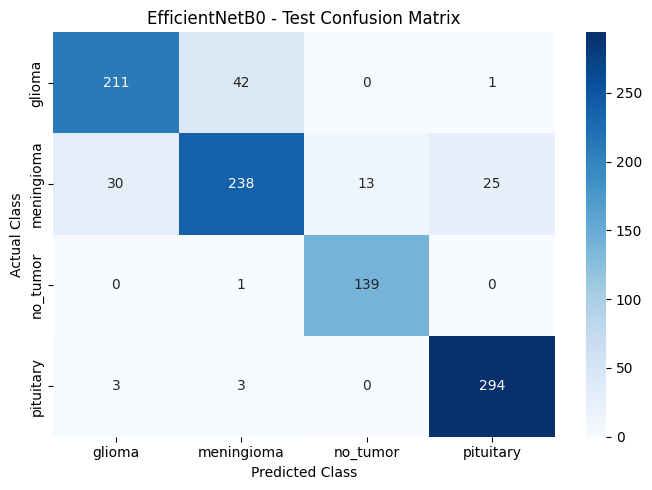

Results saved in Google Drive: /content/drive/MyDrive/Brain_Tumor_Project


In [28]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

from tensorflow.keras.models import load_model

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"
os.makedirs(project_dir, exist_ok=True)

# Load the best saved model
model = load_model(
    project_dir + "/best_efficientnetb0.keras"
)

# Predict on independent test set
y_true = np.concatenate([y.numpy() for x, y in test_ds])
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Metrics
accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")

print(f"Test Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Macro F1-score: {macro_f1:.4f}")

report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()
display(report_df.round(4))

report_df.to_csv(
    project_dir + "/efficientnetb0_test_report.csv"
)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("EfficientNetB0 - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(project_dir + "/efficientnetb0_confusion_matrix.png")
plt.show()

print("Results saved in Google Drive:", project_dir)

In [29]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Load pretrained DenseNet121
base_model = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False

# Build model
inputs = layers.Input(shape=(224, 224, 3))

# DenseNet preprocessing
x = layers.Lambda(
    tf.keras.applications.densenet.preprocess_input
)(inputs)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(4, activation="softmax")(x)

densenet_model = models.Model(inputs, outputs)

densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"
save_path = project_dir + "/best_densenet121.keras"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        save_path,
        monitor="val_loss",
        save_best_only=True
    )
]

history_dense = densenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 921s 7s/step - accuracy: 0.5735 - loss: 1.0496 - val_accuracy: 0.8320 - val_loss: 0.5170
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 848s 7s/step - accuracy: 0.7850 - loss: 0.5684 - val_accuracy: 0.8660 - val_loss: 0.3858
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 855s 7s/step - accuracy: 0.8305 - loss: 0.4668 - val_accuracy: 0.8760 - val_loss: 0.3610
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 797s 6s/step - accuracy: 0.8468 - loss: 0.4221 - val_accuracy: 0.8910 - val_loss: 0.3135
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 847s 7s/step - accuracy: 0.8553 - loss: 0.3920 - val_accuracy: 0.8890 - val_loss: 0.3086
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 802s 6s/step - accuracy: 0.8637 - loss: 0.3750 - val_accuracy: 0.9020 - val_loss: 0.2891
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 808s 6s/step - accuracy: 0.8680 - loss: 0.3566 - val_accuracy: 0.9060 - val_loss: 0.2723
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 860s 6

In [33]:
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.densenet import preprocess_input

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"

model = load_model(
    project_dir + "/best_densenet121.keras",
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

print("DenseNet121 model loaded successfully!")

DenseNet121 model loaded successfully!


32/32 ━━━━━━━━━━━━━━━━━━━━ 267s 8s/step
Test Accuracy: 85.40%
Macro-F1: 0.8562


,precision,recall,f1-score,support
glioma,0.8765,0.8386,0.8571,254.000
meningioma,0.7985,0.7124,0.7530,306.000
no_tumor,0.7865,1.0000,0.8805,140.000
pituitary,0.9248,0.9433,0.9340,300.000
accuracy,0.8540,0.8540,0.8540,0.854
macro avg,0.8466,0.8736,0.8562,1000.000
weighted avg,0.8546,0.8540,0.8516,1000.000


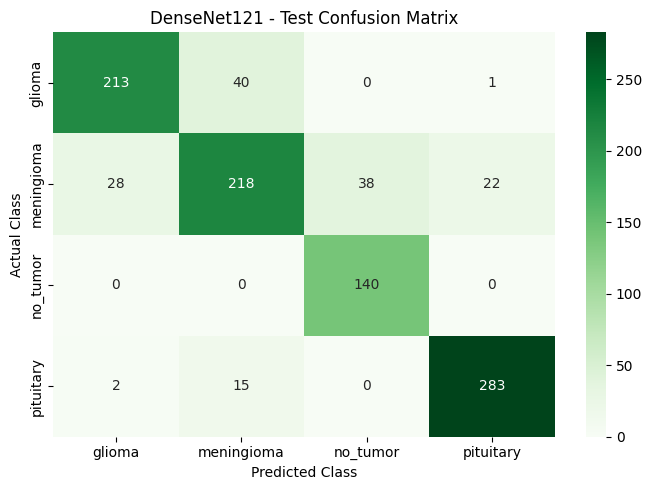

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, confusion_matrix
)

y_true = np.concatenate([y.numpy() for x, y in test_ds])
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(f"Test Accuracy: {accuracy_score(y_true, y_pred)*100:.2f}%")
print(f"Macro-F1: {f1_score(y_true, y_pred, average='macro'):.4f}")

report_df = pd.DataFrame(
    classification_report(
        y_true, y_pred,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
).transpose()

display(report_df.round(4))

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"
report_df.to_csv(project_dir + "/densenet121_test_report.csv")

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("DenseNet121 - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(project_dir + "/densenet121_confusion_matrix.png")
plt.show()

In [35]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Pretrained ResNet50
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False

# Build classification model
inputs = layers.Input(shape=(224, 224, 3))

x = layers.Lambda(
    tf.keras.applications.resnet50.preprocess_input,
    name="resnet_preprocessing"
)(inputs)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(4, activation="softmax")(x)

resnet_model = models.Model(inputs, outputs)

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        project_dir + "/best_resnet50.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_resnet = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 871s 7s/step - accuracy: 0.7220 - loss: 0.7182 - val_accuracy: 0.8430 - val_loss: 0.3946
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 864s 7s/step - accuracy: 0.8497 - loss: 0.3897 - val_accuracy: 0.9000 - val_loss: 0.2610
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 859s 7s/step - accuracy: 0.8882 - loss: 0.2977 - val_accuracy: 0.9160 - val_loss: 0.2395
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 823s 7s/step - accuracy: 0.8982 - loss: 0.2690 - val_accuracy: 0.9260 - val_loss: 0.2064
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 861s 7s/step - accuracy: 0.9078 - loss: 0.2446 - val_accuracy: 0.9270 - val_loss: 0.2048
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 899s 7s/step - accuracy: 0.9195 - loss: 0.2210 - val_accuracy: 0.9200 - val_loss: 0.2311
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 865s 7s/step - accuracy: 0.9220 - loss: 0.2198 - val_accuracy: 0.9270 - val_loss: 0.1895
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 859s 7

32/32 ━━━━━━━━━━━━━━━━━━━━ 216s 7s/step
ResNet50 Test Accuracy: 90.50%
ResNet50 Macro-F1: 0.9089


,precision,recall,f1-score,support
glioma,0.9372,0.8228,0.8763,254.000
meningioma,0.8457,0.8595,0.8525,306.000
no_tumor,0.8974,1.0000,0.9459,140.000
pituitary,0.9452,0.9767,0.9607,300.000
accuracy,0.9050,0.9050,0.9050,0.905
macro avg,0.9064,0.9147,0.9089,1000.000
weighted avg,0.9060,0.9050,0.9041,1000.000


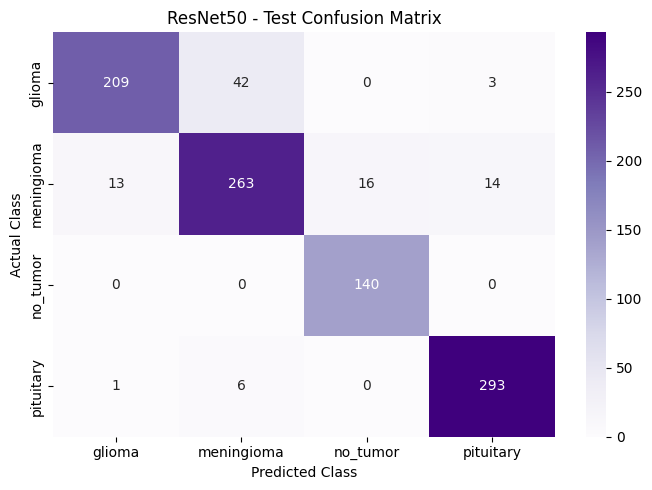

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.models import load_model
from tensorflow.keras.applications.resnet50 import preprocess_input
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, confusion_matrix
)

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"

# Load saved model safely
model = load_model(
    project_dir + "/best_resnet50.keras",
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

# Predict on test data
y_true = np.concatenate([y.numpy() for x, y in test_ds])
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Metrics
print(f"ResNet50 Test Accuracy: {accuracy_score(y_true, y_pred)*100:.2f}%")
print(f"ResNet50 Macro-F1: {f1_score(y_true, y_pred, average='macro'):.4f}")

report_df = pd.DataFrame(
    classification_report(
        y_true, y_pred,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
).transpose()

display(report_df.round(4))
report_df.to_csv(project_dir + "/resnet50_test_report.csv")

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Purples",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("ResNet50 - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(project_dir + "/resnet50_confusion_matrix.png")
plt.show()

In [37]:
import os

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"

files_to_check = [
    "best_efficientnetb0.keras",
    "best_densenet121.keras",
    "best_resnet50.keras",
    "efficientnetb0_test_report.csv",
    "densenet121_test_report.csv",
    "resnet50_test_report.csv",
    "efficientnetb0_confusion_matrix.png",
    "densenet121_confusion_matrix.png",
    "resnet50_confusion_matrix.png"
]

for file in files_to_check:
    path = os.path.join(project_dir, file)
    if os.path.exists(path):
        print(f"Saved: {file} ({os.path.getsize(path) / (1024**2):.2f} MB)")
    else:
        print(f"Not found: {file}")

Saved: best_efficientnetb0.keras (16.31 MB)
Saved: best_densenet121.keras (28.34 MB)
Saved: best_resnet50.keras (90.70 MB)
Saved: efficientnetb0_test_report.csv (0.00 MB)
Saved: densenet121_test_report.csv (0.00 MB)
Saved: resnet50_test_report.csv (0.00 MB)
Saved: efficientnetb0_confusion_matrix.png (0.03 MB)
Saved: densenet121_confusion_matrix.png (0.03 MB)
Saved: resnet50_confusion_matrix.png (0.03 MB)


In [38]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Load pretrained InceptionV3
base_model = InceptionV3(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Build classification model
inputs = layers.Input(shape=(224, 224, 3))

x = layers.Lambda(
    tf.keras.applications.inception_v3.preprocess_input,
    name="inception_preprocessing"
)(inputs)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(4, activation="softmax")(x)

inception_model = models.Model(inputs, outputs)

inception_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        project_dir + "/best_inceptionv3.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_inception = inception_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 649s 5s/step - accuracy: 0.6798 - loss: 0.8003 - val_accuracy: 0.8220 - val_loss: 0.4728
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 593s 5s/step - accuracy: 0.8112 - loss: 0.5031 - val_accuracy: 0.8580 - val_loss: 0.3928
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 592s 5s/step - accuracy: 0.8395 - loss: 0.4165 - val_accuracy: 0.8650 - val_loss: 0.3519
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 594s 5s/step - accuracy: 0.8635 - loss: 0.3583 - val_accuracy: 0.8820 - val_loss: 0.3467
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 565s 5s/step - accuracy: 0.8660 - loss: 0.3398 - val_accuracy: 0.8900 - val_loss: 0.3099
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 620s 5s/step - accuracy: 0.8855 - loss: 0.3105 - val_accuracy: 0.8900 - val_loss: 0.3006
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 620s 4s/step - accuracy: 0.8798 - loss: 0.3112 - val_accuracy: 0.8750 - val_loss: 0.3212
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 591s 5

32/32 ━━━━━━━━━━━━━━━━━━━━ 171s 5s/step
InceptionV3 Test Accuracy: 87.90%
InceptionV3 Macro-F1: 0.8861


,precision,recall,f1-score,support
glioma,0.9453,0.7480,0.8352,254.000
meningioma,0.7752,0.8791,0.8239,306.000
no_tumor,0.8974,1.0000,0.9459,140.000
pituitary,0.9459,0.9333,0.9396,300.000
accuracy,0.8790,0.8790,0.8790,0.879
macro avg,0.8910,0.8901,0.8861,1000.000
weighted avg,0.8867,0.8790,0.8786,1000.000


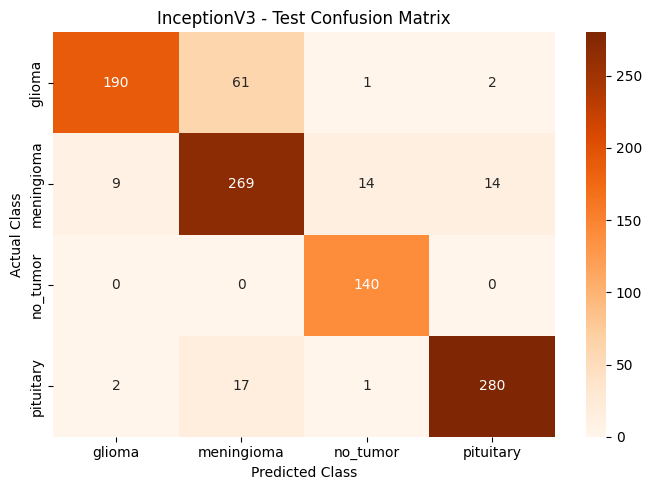

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.models import load_model
from tensorflow.keras.applications.inception_v3 import preprocess_input
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, confusion_matrix
)

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"

# Load saved best model
model = load_model(
    project_dir + "/best_inceptionv3.keras",
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

# Predictions
y_true = np.concatenate([y.numpy() for x, y in test_ds])
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Overall metrics
print(f"InceptionV3 Test Accuracy: {accuracy_score(y_true, y_pred)*100:.2f}%")
print(f"InceptionV3 Macro-F1: {f1_score(y_true, y_pred, average='macro'):.4f}")

# Classification report
report_df = pd.DataFrame(
    classification_report(
        y_true, y_pred,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
).transpose()

display(report_df.round(4))
report_df.to_csv(project_dir + "/inceptionv3_test_report.csv")

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Oranges",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("InceptionV3 - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(project_dir + "/inceptionv3_confusion_matrix.png")
plt.show()

In [40]:
import os

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"
model_path = os.path.join(project_dir, "best_inceptionv3.keras")

if os.path.exists(model_path):
    print("InceptionV3 model already saved!")
    print("Path:", model_path)
    print("File size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")
else:
    model.save(model_path)
    print("InceptionV3 model saved successfully!")
    print("Path:", model_path)

InceptionV3 model already saved!
Path: /content/drive/MyDrive/Brain_Tumor_Project/best_inceptionv3.keras
File size: 84.32 MB


In [2]:
import os

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"
model_path = os.path.join(project_dir, "best_inceptionv3.keras")

print("Drive mounted:", os.path.exists("/content/drive/MyDrive"))
print("Project folder exists:", os.path.exists(project_dir))
print("Model file exists:", os.path.exists(model_path))

if os.path.exists(project_dir):
    print("\nFiles in project folder:")
    print(os.listdir(project_dir))

Drive mounted: False
Project folder exists: False
Model file exists: False


In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"
model_path = os.path.join(project_dir, "best_inceptionv3.keras")

print("Project folder exists:", os.path.exists(project_dir))
print("Model file exists:", os.path.exists(model_path))

Project folder exists: True
Model file exists: True


In [7]:
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.inception_v3 import preprocess_input

model_path = "/content/drive/MyDrive/Brain_Tumor_Project/best_inceptionv3.keras"

inception_model = load_model(
    model_path,
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

print("InceptionV3 model loaded successfully!")

InceptionV3 model loaded successfully!


In [8]:
inception_model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_preprocessing         │ (None, 224, 224, 3)    │             0 │
│ (Lambda)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,810,980 (83.20 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import os

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"

# Model comparison results
results = {
    "Model": ["EfficientNetB0", "DenseNet121", "ResNet50", "InceptionV3"],
    "Test Accuracy (%)": [88.20, 85.40, 90.50, 87.90],
    "Macro-F1 (%)": [88.87, 85.62, 90.89, 88.61]
}

comparison_df = pd.DataFrame(results)

# Display comparison table
display(comparison_df)

# Save CSV report
comparison_df.to_csv(
    os.path.join(project_dir, "model_comparison.csv"),
    index=False
)

print("Comparison report saved successfully!")

,Model,Test Accuracy (%),Macro-F1 (%)
0,EfficientNetB0,88.2,88.87
1,DenseNet121,85.4,85.62
2,ResNet50,90.5,90.89
3,InceptionV3,87.9,88.61


Comparison report saved successfully!


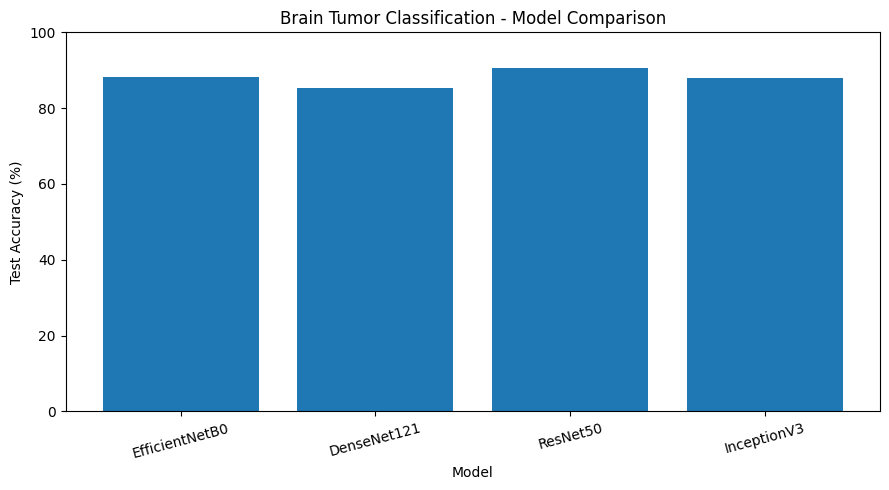

Accuracy graph saved successfully!


In [10]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Test Accuracy (%)"]
)

plt.ylabel("Test Accuracy (%)")
plt.xlabel("Model")
plt.title("Brain Tumor Classification - Model Comparison")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    os.path.join(project_dir, "model_accuracy_comparison.png"),
    dpi=300
)

plt.show()

print("Accuracy graph saved successfully!")

In [11]:
import os

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"

for file in os.listdir(project_dir):
    if file.endswith(".keras"):
        print(file)

best_classweighted_cnn.keras
best_unet_segmentation.keras
best_brain_tumor_cnn.keras
best_mobilenetv2.keras
unet_before_retraining.keras
unet_per_image_dice.keras
best_efficientnetb0.keras
best_densenet121.keras
best_resnet50.keras
best_inceptionv3.keras


In [14]:
from google.colab import drive
drive.mount('/content/drive')

import os

print("MyDrive folders:")
print(os.listdir("/content/drive/MyDrive")[:30])

print("\nTemporary folder exists:",
      os.path.exists("/content/brisc_data"))

print("\nProject folder exists:",
      os.path.exists("/content/drive/MyDrive/Brain_Tumor_Project"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MyDrive folders:
['Colab Notebooks', 'resume2.pdf', '🧠 BRISC 2025.zip', 'Brain_Tumor_Project']

Temporary folder exists: False

Project folder exists: True


In [15]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/🧠 BRISC 2025.zip"
extract_path = "/content/brisc_data"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Folders:", os.listdir(extract_path))

Dataset extracted successfully!
Folders: ['🧠 BRISC 2025']


In [16]:
import os

for root, dirs, files in os.walk("/content/brisc_data"):
    if "test" in dirs and "train" in dirs:
        print("Dataset folder found:", root)
        print("Test folder:", os.path.join(root, "test"))
        break

In [17]:
import os

base_path = "/content/brisc_data"

for root, dirs, files in os.walk(base_path):
    level = root.replace(base_path, "").count(os.sep)

    if level <= 4:
        print("  " * level + os.path.basename(root) + "/")

    # Stop listing deeply nested image folders
    if level >= 4:
        dirs[:] = []

brisc_data/
  🧠 BRISC 2025/


In [18]:
import os

folder = "/content/brisc_data/🧠 BRISC 2025"

for root, dirs, files in os.walk(folder):
    for file in files:
        print(os.path.join(root, file))
    if root.count(os.sep) - folder.count(os.sep) >= 2:
        dirs[:] = []

/content/brisc_data/🧠 BRISC 2025/brisc2025.zip


In [19]:
import os
import zipfile

zip_path = "/content/brisc_data/🧠 BRISC 2025/brisc2025.zip"
extract_path = "/content/brisc_data/🧠 BRISC 2025"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Inner dataset extracted!")
print(os.listdir(extract_path))

Inner dataset extracted!
['brisc2025.zip', 'brisc2025']


In [20]:
import os

base_path = "/content/brisc_data"

for root, dirs, files in os.walk(base_path):
    if "train" in dirs and "test" in dirs:
        print("Dataset path:", root)
        print("Test path:", os.path.join(root, "test"))

Dataset path: /content/brisc_data/🧠 BRISC 2025/brisc2025/classification_task
Test path: /content/brisc_data/🧠 BRISC 2025/brisc2025/classification_task/test
Dataset path: /content/brisc_data/🧠 BRISC 2025/brisc2025/segmentation_task
Test path: /content/brisc_data/🧠 BRISC 2025/brisc2025/segmentation_task/test


In [21]:
import tensorflow as tf
import numpy as np

test_dir = "/content/brisc_data/🧠 BRISC 2025/brisc2025/classification_task/test"

class_names = ["glioma", "meningioma", "no_tumor", "pituitary"]

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode="int",
    shuffle=False,
    class_names=class_names
)

print("Test dataset ready!")
print("Classes:", test_ds.class_names)

Found 1000 files belonging to 4 classes.
Test dataset ready!
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [22]:
y_true = np.concatenate([y.numpy() for x, y in test_ds])

print("Total test images:", len(y_true))
print("Dataset variables ready!")

Total test images: 1000
Dataset variables ready!


In [23]:
import numpy as np
import pandas as pd
import os

from tensorflow.keras.models import load_model
from sklearn.metrics import accuracy_score, f1_score

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"

models_to_check = {
    "CNN": "best_brain_tumor_cnn.keras",
    "Class-Weighted CNN": "best_classweighted_cnn.keras",
    "MobileNetV2": "best_mobilenetv2.keras"
}

y_true = np.concatenate([y.numpy() for x, y in test_ds])
results = []

for name, filename in models_to_check.items():
    model_path = os.path.join(project_dir, filename)

    try:
        model = load_model(model_path, compile=False)
        y_prob = model.predict(test_ds, verbose=0)
        y_pred = np.argmax(y_prob, axis=1)

        accuracy = accuracy_score(y_true, y_pred) * 100
        macro_f1 = f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ) * 100

        results.append({
            "Model": name,
            "Test Accuracy (%)": round(accuracy, 2),
            "Macro-F1 (%)": round(macro_f1, 2)
        })

        print(f"{name}: Accuracy = {accuracy:.2f}%")

    except Exception as e:
        print(f"{name} error: {e}")

new_results_df = pd.DataFrame(results)
display(new_results_df)

CNN: Accuracy = 50.80%
Class-Weighted CNN: Accuracy = 67.60%
MobileNetV2 error: Requested the deserialization of a `Lambda` layer whose `function` is a Python lambda. This carries a potential risk of arbitrary code execution and thus it is disallowed by default. If you trust the source of the artifact, you can override this error by passing `safe_mode=False` to the loading function, or calling `keras.config.enable_unsafe_deserialization().


,Model,Test Accuracy (%),Macro-F1 (%)
0,CNN,50.8,44.18
1,Class-Weighted CNN,67.6,68.54


In [24]:
from tensorflow.keras.models import load_model

model_path = "/content/drive/MyDrive/Brain_Tumor_Project/best_mobilenetv2.keras"

mobilenet_model = load_model(
    model_path,
    compile=False,
    safe_mode=False
)

print("MobileNetV2 loaded successfully!")

MobileNetV2 loaded successfully!


In [26]:
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

model_path = "/content/drive/MyDrive/Brain_Tumor_Project/best_mobilenetv2.keras"

mobilenet_model = load_model(
    model_path,
    custom_objects={"preprocess_input": preprocess_input},
    compile=False,
    safe_mode=False
)

print("MobileNetV2 loaded successfully!")

MobileNetV2 loaded successfully!


In [29]:
for layer in mobilenet_model.layers:
    if isinstance(layer, tf.keras.layers.Lambda):
        print("Lambda layer:", layer.name)
        print("Function name:", getattr(layer.function, "__name__", "unknown"))
        print("Function globals contain preprocess_input:",
              "preprocess_input" in getattr(layer.function, "__globals__", {}))

Lambda layer: lambda
Function name: <lambda>
Function globals contain preprocess_input: False


In [30]:
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Find the Lambda layer and add the missing function reference
for layer in mobilenet_model.layers:
    if isinstance(layer, tf.keras.layers.Lambda):
        layer.function.__globals__["preprocess_input"] = preprocess_input
        print("Fixed Lambda layer:", layer.name)

# Test one batch
for images, labels in test_ds.take(1):
    predictions = mobilenet_model(images, training=False)
    print("Prediction shape:", predictions.shape)
    print("MobileNetV2 is working!")

Fixed Lambda layer: lambda
Prediction shape: (32, 4)
MobileNetV2 is working!


In [31]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, classification_report

y_true = np.concatenate([labels.numpy() for images, labels in test_ds])

y_prob = mobilenet_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

mobilenet_accuracy = accuracy_score(y_true, y_pred)
mobilenet_macro_f1 = f1_score(y_true, y_pred, average="macro")

print(f"MobileNetV2 Test Accuracy: {mobilenet_accuracy * 100:.2f}%")
print(f"MobileNetV2 Macro-F1: {mobilenet_macro_f1 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    digits=4,
    zero_division=0
))

32/32 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step
MobileNetV2 Test Accuracy: 81.70%
MobileNetV2 Macro-F1: 82.75%

Classification Report:
              precision    recall  f1-score   support

      glioma     0.9231    0.6142    0.7376       254
  meningioma     0.7357    0.7549    0.7452       306
    no_tumor     0.9375    0.9643    0.9507       140
   pituitary     0.7909    0.9833    0.8767       300

    accuracy                         0.8170      1000
   macro avg     0.8468    0.8292    0.8275      1000
weighted avg     0.8281    0.8170    0.8115      1000



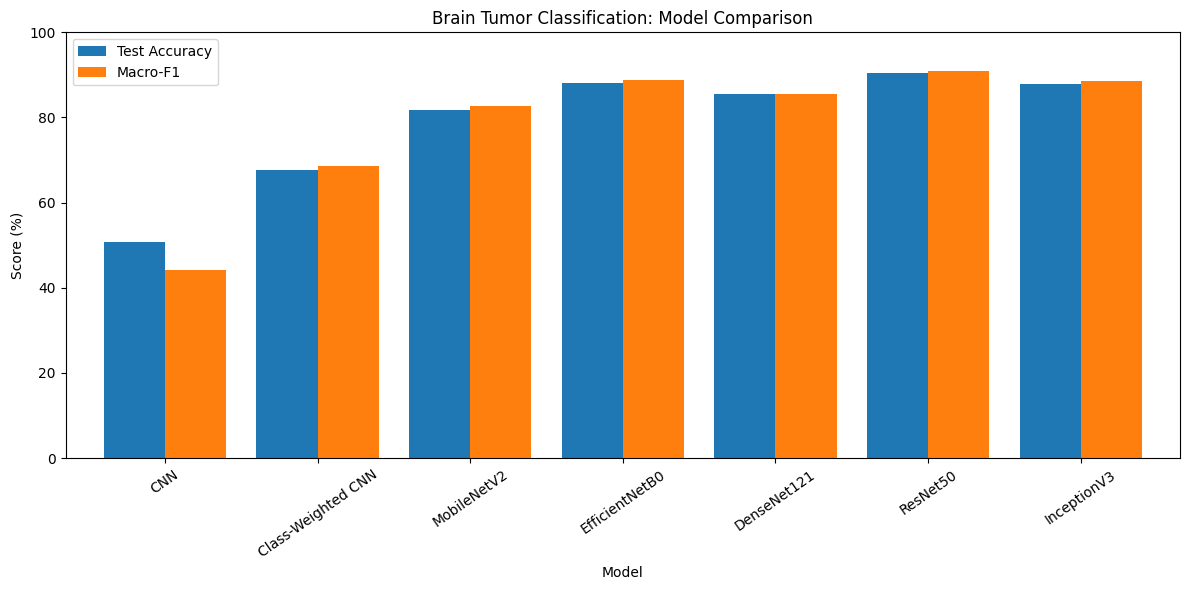

CSV saved: /content/drive/MyDrive/Brain_Tumor_Project/all_models_comparison.csv
Graph saved: /content/drive/MyDrive/Brain_Tumor_Project/all_models_comparison.png


In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import os

project_dir = "/content/drive/MyDrive/Brain_Tumor_Project"

results = [
    {"Model": "CNN", "Accuracy": 50.80, "Macro-F1": 44.18},
    {"Model": "Class-Weighted CNN", "Accuracy": 67.60, "Macro-F1": 68.54},
    {"Model": "MobileNetV2", "Accuracy": 81.70, "Macro-F1": 82.75},
    {"Model": "EfficientNetB0", "Accuracy": 88.20, "Macro-F1": 88.87},
    {"Model": "DenseNet121", "Accuracy": 85.40, "Macro-F1": 85.62},
    {"Model": "ResNet50", "Accuracy": 90.50, "Macro-F1": 90.89},
    {"Model": "InceptionV3", "Accuracy": 87.90, "Macro-F1": 88.61}
]

df = pd.DataFrame(results)

# Save comparison table
csv_path = os.path.join(project_dir, "all_models_comparison.csv")
df.to_csv(csv_path, index=False)

# Plot comparison
ax = df.set_index("Model")[["Accuracy", "Macro-F1"]].plot(
    kind="bar", figsize=(12, 6), width=0.8
)

ax.set_title("Brain Tumor Classification: Model Comparison")
ax.set_ylabel("Score (%)")
ax.set_xlabel("Model")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=35)
ax.legend(["Test Accuracy", "Macro-F1"])
plt.tight_layout()

graph_path = os.path.join(project_dir, "all_models_comparison.png")
plt.savefig(graph_path, dpi=300, bbox_inches="tight")
plt.show()

print("CSV saved:", csv_path)
print("Graph saved:", graph_path)

In [33]:
print("resnet_model exists:", "resnet_model" in globals())
print("test_ds exists:", "test_ds" in globals())
print("class_names exists:", "class_names" in globals())

resnet_model exists: False
test_ds exists: True
class_names exists: True


In [34]:
import os

DATA_ROOT = "/content/brisc_data/🧠 BRISC 2025/brisc2025"

paths = {
    "Classification train": os.path.join(
        DATA_ROOT, "classification_task", "train"
    ),
    "Classification test": os.path.join(
        DATA_ROOT, "classification_task", "test"
    ),
    "Segmentation train images": os.path.join(
        DATA_ROOT, "segmentation_task", "train", "images"
    ),
    "Segmentation train masks": os.path.join(
        DATA_ROOT, "segmentation_task", "train", "masks"
    ),
    "Segmentation test images": os.path.join(
        DATA_ROOT, "segmentation_task", "test", "images"
    ),
    "Segmentation test masks": os.path.join(
        DATA_ROOT, "segmentation_task", "test", "masks"
    )
}

for name, path in paths.items():
    print(f"{name}: {'FOUND' if os.path.isdir(path) else 'NOT FOUND'}")
    print(path)
    print()

Classification train: FOUND
/content/brisc_data/🧠 BRISC 2025/brisc2025/classification_task/train

Classification test: FOUND
/content/brisc_data/🧠 BRISC 2025/brisc2025/classification_task/test

Segmentation train images: FOUND
/content/brisc_data/🧠 BRISC 2025/brisc2025/segmentation_task/train/images

Segmentation train masks: FOUND
/content/brisc_data/🧠 BRISC 2025/brisc2025/segmentation_task/train/masks

Segmentation test images: FOUND
/content/brisc_data/🧠 BRISC 2025/brisc2025/segmentation_task/test/images

Segmentation test masks: FOUND
/content/brisc_data/🧠 BRISC 2025/brisc2025/segmentation_task/test/masks



In [35]:
import tensorflow as tf
import os

DATA_ROOT = "/content/brisc_data/🧠 BRISC 2025/brisc2025"
TRAIN_DIR = os.path.join(DATA_ROOT, "classification_task", "train")
TEST_DIR = os.path.join(DATA_ROOT, "classification_task", "test")

class_names = ["glioma", "meningioma", "no_tumor", "pituitary"]

# Check images in each class
for split, folder in [("Train", TRAIN_DIR), ("Test", TEST_DIR)]:
    print(f"\n{split} dataset:")
    for class_name in class_names:
        class_dir = os.path.join(folder, class_name)
        if os.path.isdir(class_dir):
            count = sum(
                1 for f in os.listdir(class_dir)
                if f.lower().endswith((".png", ".jpg", ".jpeg"))
            )
            print(f"{class_name}: {count} images")
        else:
            print(f"{class_name}: CLASS FOLDER MISSING")

# Create datasets with consistent labels and image size
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=(224, 224),
    batch_size=32,
    label_mode="int",
    class_names=class_names,
    shuffle=True,
    seed=42
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(224, 224),
    batch_size=32,
    label_mode="int",
    class_names=class_names,
    shuffle=False
)

print("\nClass order:", train_ds.class_names)
print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Pixel range:", float(tf.reduce_min(images)), "to",
          float(tf.reduce_max(images)))
    print("Label batch shape:", labels.shape)


Train dataset:
glioma: 1147 images
meningioma: 1329 images
no_tumor: 1067 images
pituitary: 1457 images

Test dataset:
glioma: 254 images
meningioma: 306 images
no_tumor: 140 images
pituitary: 300 images
Found 5000 files belonging to 4 classes.
Found 1000 files belonging to 4 classes.

Class order: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Train batches: 157
Test batches: 32
Image batch shape: (32, 224, 224, 3)
Pixel range: 0.0 to 255.0
Label batch shape: (32,)


In [36]:
import tensorflow as tf

print("=== Dataset preprocessing check ===")

for images, labels in train_ds.take(1):
    print("Raw image minimum:", float(tf.reduce_min(images)))
    print("Raw image maximum:", float(tf.reduce_max(images)))

    normalized_images = images / 255.0

    print("After /255 minimum:",
          float(tf.reduce_min(normalized_images)))
    print("After /255 maximum:",
          float(tf.reduce_max(normalized_images)))

    print("Labels in batch:", labels.numpy())
    print("Label names:",
          [class_names[int(i)] for i in labels[:10].numpy()])

=== Dataset preprocessing check ===
Raw image minimum: 0.0
Raw image maximum: 255.0
After /255 minimum: 0.0
After /255 maximum: 1.0
Labels in batch: [1 0 0 0 1 0 3 2 0 2 0 1 1 3 1 1 1 0 3 2 2 1 2 0 3 0 0 2 2 2 1 0]
Label names: ['meningioma', 'glioma', 'glioma', 'glioma', 'meningioma', 'glioma', 'pituitary', 'no_tumor', 'glioma', 'no_tumor']


In [38]:
from tensorflow.keras.applications.mobilenet_v2 import (
    preprocess_input as mobilenet_preprocess
)
from tensorflow.keras.applications.densenet import (
    preprocess_input as densenet_preprocess
)
from tensorflow.keras.applications.resnet50 import (
    preprocess_input as resnet_preprocess
)
from tensorflow.keras.applications.inception_v3 import (
    preprocess_input as inception_preprocess
)
from tensorflow.keras.applications.efficientnet import (
    preprocess_input as efficientnet_preprocess
)

print("MobileNetV2:", mobilenet_preprocess.__name__)
print("DenseNet121:", densenet_preprocess.__name__)
print("ResNet50:", resnet_preprocess.__name__)
print("InceptionV3:", inception_preprocess.__name__)
print("EfficientNetB0:", efficientnet_preprocess.__name__)

MobileNetV2: preprocess_input
DenseNet121: preprocess_input
ResNet50: preprocess_input
InceptionV3: preprocess_input
EfficientNetB0: preprocess_input


In [40]:
models_to_check = {
    "model": model,
    "mobilenet_model": mobilenet_model,
    "inception_model": inception_model
}

for name, m in models_to_check.items():
    print(f"\n--- {name} ---")
    print("Built:", m.built)
    print("Input shape:", getattr(m, "input_shape", "Not defined"))
    print("Output shape:", getattr(m, "output_shape", "Not defined"))
    print("Parameters:", m.count_params() if m.built else "Not built")
    print("Layers:", len(m.layers))


--- model ---
Built: True
Input shape: (None, 128, 128, 3)
Output shape: (None, 4)
Parameters: 28004
Layers: 12

--- mobilenet_model ---
Built: True
Input shape: Not defined
Output shape: Not defined
Parameters: 2422468
Layers: 8

--- inception_model ---
Built: True
Input shape: (None, 224, 224, 3)
Output shape: (None, 4)
Parameters: 21810980
Layers: 6


In [41]:
for name, m in {
    "MobileNetV2": mobilenet_model,
    "InceptionV3": inception_model
}.items():

    print(f"\n{'=' * 15} {name} {'=' * 15}")

    for i, layer in enumerate(m.layers):
        print(
            i,
            layer.name,
            layer.__class__.__name__,
            getattr(layer, "output_shape", "shape not available")
        )


=============== MobileNetV2 ===============
0 resizing Resizing shape not available
1 lambda Lambda shape not available
2 mobilenetv2_1.00_224 Functional (None, 7, 7, 1280)
3 global_average_pooling2d_1 GlobalAveragePooling2D shape not available
4 dropout_1 Dropout shape not available
5 dense_2 Dense shape not available
6 dropout_2 Dropout shape not available
7 dense_3 Dense shape not available

=============== InceptionV3 ===============
0 input_layer_7 InputLayer shape not available
1 inception_preprocessing Lambda shape not available
2 inception_v3 Functional (None, 5, 5, 2048)
3 global_average_pooling2d_3 GlobalAveragePooling2D shape not available
4 dropout_3 Dropout shape not available
5 dense_3 Dense shape not available


In [42]:
for name, m in {
    "MobileNetV2": mobilenet_model,
    "InceptionV3": inception_model
}.items():

    print(f"\n--- {name} ---")

    for layer in m.layers:
        if isinstance(layer, tf.keras.layers.Lambda):
            print("Layer:", layer.name)
            print("Function:", layer.function)
            print("Function name:",
                  getattr(layer.function, "__name__", "unknown"))


--- MobileNetV2 ---
Layer: lambda
Function: <function <lambda> at 0x7c686e3c0f40>
Function name: <lambda>

--- InceptionV3 ---
Layer: inception_preprocessing
Function: <function preprocess_input at 0x7c688b297600>
Function name: preprocess_input


In [43]:
for name, m in {
    "MobileNetV2": mobilenet_model,
    "InceptionV3": inception_model
}.items():

    print(f"\n--- {name} preprocessing details ---")

    for layer in m.layers:
        if isinstance(layer, tf.keras.layers.Lambda):
            fn = layer.function
            print("Layer:", layer.name)
            print("Function name:", fn.__name__)

            if fn.__name__ == "<lambda>":
                print("Function constants:",
                      fn.__code__.co_consts)
                print("Function variables:",
                      fn.__code__.co_names)


--- MobileNetV2 preprocessing details ---
Layer: lambda
Function name: <lambda>
Function constants: (None,)
Function variables: ('preprocess_input',)

--- InceptionV3 preprocessing details ---
Layer: inception_preprocessing
Function name: preprocess_input


In [44]:
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import (
    preprocess_input as mobilenet_preprocess
)
from tensorflow.keras.applications.inception_v3 import (
    preprocess_input as inception_preprocess
)

# Test preprocessing functions on sample images
sample = tf.random.uniform(
    shape=(2, 224, 224, 3),
    minval=0,
    maxval=256,
    dtype=tf.float32
)

print("MobileNetV2 preprocessing:")
print("Range:",
      float(tf.reduce_min(mobilenet_preprocess(sample))),
      "to",
      float(tf.reduce_max(mobilenet_preprocess(sample))))

print("\nInceptionV3 preprocessing:")
print("Range:",
      float(tf.reduce_min(inception_preprocess(sample))),
      "to",
      float(tf.reduce_max(inception_preprocess(sample))))

MobileNetV2 preprocessing:
Range: -0.9999906420707703 to 1.007840871810913

InceptionV3 preprocessing:
Range: -0.9999906420707703 to 1.007840871810913


In [45]:
import tensorflow as tf

sample = tf.cast(
    tf.reshape(tf.range(256), (1, 16, 16, 1)),
    tf.float32
)
sample = tf.tile(sample, [1, 14, 14, 3])

from tensorflow.keras.applications.mobilenet_v2 import (
    preprocess_input as mobilenet_preprocess
)
from tensorflow.keras.applications.inception_v3 import (
    preprocess_input as inception_preprocess
)

for name, fn in [
    ("MobileNetV2", mobilenet_preprocess),
    ("InceptionV3", inception_preprocess)
]:
    result = fn(sample)
    print(
        name,
        "min =", float(tf.reduce_min(result)),
        "max =", float(tf.reduce_max(result))
    )

MobileNetV2 min = -1.0 max = 1.0
InceptionV3 min = -1.0 max = 1.0


In [46]:
import tensorflow as tf

# Create a sample batch of raw images
sample_images = tf.random.uniform(
    (2, 224, 224, 3),
    minval=0,
    maxval=256,
    dtype=tf.float32
)

# Test the existing preprocessing layers
for name, m in [
    ("MobileNetV2", mobilenet_model),
    ("InceptionV3", inception_model)
]:
    print(f"\n--- {name} ---")

    for layer in m.layers:
        if isinstance(layer, tf.keras.layers.Lambda):
            try:
                output = layer(sample_images)
                print("Layer:", layer.name)
                print("Output shape:", output.shape)
                print(
                    "Output range:",
                    float(tf.reduce_min(output)),
                    "to",
                    float(tf.reduce_max(output))
                )
            except Exception as e:
                print("Layer execution failed:", repr(e))


--- MobileNetV2 ---
Layer: lambda
Output shape: (2, 224, 224, 3)
Output range: -0.9999837279319763 to 1.0078411102294922

--- InceptionV3 ---
Layer: inception_preprocessing
Output shape: (2, 224, 224, 3)
Output range: -0.9999837279319763 to 1.0078411102294922


In [47]:
# Get actual raw images from the dataset
for images, labels in test_ds.take(1):
    sample_images = images[:2]

print("Raw image range:",
      float(tf.reduce_min(sample_images)),
      "to",
      float(tf.reduce_max(sample_images)))

for name, m in [
    ("MobileNetV2", mobilenet_model),
    ("InceptionV3", inception_model)
]:
    print(f"\n--- {name} ---")

    for layer in m.layers:
        if isinstance(layer, tf.keras.layers.Lambda):
            output = layer(sample_images)

            print("Layer:", layer.name)
            print("Output shape:", output.shape)
            print("Output range:",
                  float(tf.reduce_min(output)),
                  "to",
                  float(tf.reduce_max(output)))

Raw image range: 0.0 to 243.44895935058594

--- MobileNetV2 ---
Layer: lambda
Output shape: (2, 224, 224, 3)
Output range: -1.0 to 0.9094035625457764

--- InceptionV3 ---
Layer: inception_preprocessing
Output shape: (2, 224, 224, 3)
Output range: -1.0 to 0.9094035625457764


In [48]:
import tensorflow as tf
import os

model_paths = {
    "CNN": "/content/drive/MyDrive/Brain_Tumor_Project/best_brain_tumor_cnn.keras",
    "ClassWeighted CNN": "/content/drive/MyDrive/Brain_Tumor_Project/best_classweighted_cnn.keras",
    "MobileNetV2": "/content/drive/MyDrive/Brain_Tumor_Project/best_mobilenetv2.keras",
    "EfficientNetB0": "/content/drive/MyDrive/Brain_Tumor_Project/best_efficientnetb0.keras",
    "DenseNet121": "/content/drive/MyDrive/Brain_Tumor_Project/best_densenet121.keras",
    "ResNet50": "/content/drive/MyDrive/Brain_Tumor_Project/best_resnet50.keras",
    "InceptionV3": "/content/drive/MyDrive/Brain_Tumor_Project/best_inceptionv3.keras"
}

for name, path in model_paths.items():
    print(f"\n--- {name} ---")

    if not os.path.exists(path):
        print("File not found:", path)
        continue

    try:
        m = tf.keras.models.load_model(path, compile=False)
        print("Input shape:", m.input_shape)
        print("Output shape:", m.output_shape)
        print("Parameters:", m.count_params())
    except Exception as e:
        print("Load error:", repr(e))


--- CNN ---
Input shape: (None, 128, 128, 3)
Output shape: (None, 4)
Parameters: 28004

--- ClassWeighted CNN ---
Input shape: (None, 128, 128, 3)
Output shape: (None, 4)
Parameters: 28004

--- MobileNetV2 ---
Load error: ValueError('Requested the deserialization of a `Lambda` layer whose `function` is a Python lambda. This carries a potential risk of arbitrary code execution and thus it is disallowed by default. If you trust the source of the artifact, you can override this error by passing `safe_mode=False` to the loading function, or calling `keras.config.enable_unsafe_deserialization().')

--- EfficientNetB0 ---
Input shape: (None, 224, 224, 3)
Output shape: (None, 4)
Parameters: 4054695

--- DenseNet121 ---
Input shape: (None, 224, 224, 3)
Output shape: (None, 4)
Parameters: 7041604

--- ResNet50 ---
Input shape: (None, 224, 224, 3)
Output shape: (None, 4)
Parameters: 23595908

--- InceptionV3 ---
Input shape: (None, 224, 224, 3)
Output shape: (None, 4)
Parameters: 21810980


In [49]:
import tensorflow as tf

mobilenet_path = (
    "/content/drive/MyDrive/Brain_Tumor_Project/"
    "best_mobilenetv2.keras"
)

mobilenet_check = tf.keras.models.load_model(
    mobilenet_path,
    compile=False,
    safe_mode=False
)

print("MobileNetV2 loaded successfully")
print("Input shape:", mobilenet_check.input_shape)
print("Output shape:", mobilenet_check.output_shape)
print("Parameters:", mobilenet_check.count_params())

MobileNetV2 loaded successfully
Input shape: (None, 128, 128, 3)
Output shape: (None, 4)
Parameters: 2422468


In [50]:
for i, layer in enumerate(mobilenet_check.layers):
    print(
        i,
        layer.name,
        layer.__class__.__name__,
        getattr(layer, "output_shape", "shape not directly available")
    )

0 resizing Resizing shape not directly available
1 lambda Lambda shape not directly available
2 mobilenetv2_1.00_224 Functional (None, 7, 7, 1280)
3 global_average_pooling2d_1 GlobalAveragePooling2D shape not directly available
4 dropout_1 Dropout shape not directly available
5 dense_2 Dense shape not directly available
6 dropout_2 Dropout shape not directly available
7 dense_3 Dense shape not directly available


In [51]:
# Inspect the saved MobileNetV2 preprocessing layers
for layer in mobilenet_check.layers:
    if isinstance(layer, tf.keras.layers.Resizing):
        print("Resizing layer:", layer.get_config())

    elif isinstance(layer, tf.keras.layers.Lambda):
        print("\nLambda layer:", layer.name)
        print("Function name:", layer.function.__name__)
        print("Function code names:",
              getattr(layer.function.__code__, "co_names", ()))

Resizing layer: {'name': 'resizing', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'height': 224, 'width': 224, 'interpolation': 'bilinear', 'crop_to_aspect_ratio': False, 'pad_to_aspect_ratio': False, 'fill_mode': 'constant', 'fill_value': 0.0, 'antialias': False, 'data_format': 'channels_last'}

Lambda layer: lambda
Function name: <lambda>
Function code names: ('preprocess_input',)


In [52]:
import tensorflow as tf

# Take one batch of actual test images
for images, labels in test_ds.take(1):
    sample_images = images[:4]
    sample_labels = labels[:4]

# Run prediction using the loaded model
predictions = mobilenet_check.predict(sample_images, verbose=0)

print("Input shape:", sample_images.shape)
print("Prediction shape:", predictions.shape)
print("Predicted class IDs:", predictions.argmax(axis=1))
print("Actual class IDs:", sample_labels.numpy())
print("Prediction values for first image:", predictions[0])

Input shape: (4, 224, 224, 3)
Prediction shape: (4, 4)
Predicted class IDs: [0 0 0 1]
Actual class IDs: [0 0 0 0]
Prediction values for first image: [0.79988736 0.18935505 0.00915746 0.00160012]


In [53]:
import tensorflow as tf
import os

model_paths = {
    "CNN": "/content/drive/MyDrive/Brain_Tumor_Project/best_brain_tumor_cnn.keras",
    "ClassWeighted CNN": "/content/drive/MyDrive/Brain_Tumor_Project/best_classweighted_cnn.keras",
    "MobileNetV2": "/content/drive/MyDrive/Brain_Tumor_Project/best_mobilenetv2.keras",
    "EfficientNetB0": "/content/drive/MyDrive/Brain_Tumor_Project/best_efficientnetb0.keras",
    "DenseNet121": "/content/drive/MyDrive/Brain_Tumor_Project/best_densenet121.keras",
    "ResNet50": "/content/drive/MyDrive/Brain_Tumor_Project/best_resnet50.keras",
    "InceptionV3": "/content/drive/MyDrive/Brain_Tumor_Project/best_inceptionv3.keras"
}

for name, path in model_paths.items():
    print(f"\n--- {name} ---")

    if not os.path.exists(path):
        print("FILE NOT FOUND")
        continue

    try:
        if name == "MobileNetV2":
            m = mobilenet_check
        else:
            m = tf.keras.models.load_model(
                path, compile=False, safe_mode=False
            )

        h, w = m.input_shape[1:3]
        sample = tf.image.resize(sample_images, (h, w))
        pred = m.predict(sample, verbose=0)

        print("Input size:", (h, w))
        print("Prediction shape:", pred.shape)
        print("Predicted classes:", pred.argmax(axis=1))

    except Exception as e:
        print("ERROR:", repr(e))


--- CNN ---
Input size: (128, 128)
Prediction shape: (4, 4)
Predicted classes: [0 0 0 0]

--- ClassWeighted CNN ---


Input size: (128, 128)
Prediction shape: (4, 4)
Predicted classes: [1 0 0 1]

--- MobileNetV2 ---


Input size: (128, 128)
Prediction shape: (4, 4)
Predicted classes: [0 0 0 1]

--- EfficientNetB0 ---
Input size: (224, 224)
Prediction shape: (4, 4)
Predicted classes: [0 0 0 1]

--- DenseNet121 ---
Input size: (224, 224)
Prediction shape: (4, 4)
Predicted classes: [0 0 0 0]

--- ResNet50 ---
Input size: (224, 224)
Prediction shape: (4, 4)
Predicted classes: [2 2 2 2]

--- InceptionV3 ---
Input size: (224, 224)
Prediction shape: (4, 4)
Predicted classes: [0 0 0 0]
